# Transistor Problem Bank: Differential Pairs

238 problems, each solved step by step. Every circuit has two tabs, BJT and MOSFET, with the problems of that transistor; choosing a tab changes every tab of the page. The problems of each transistor are numbered on their own, from 1 down the page. A problem is one table: the problem, what is given, the answer step by step, and the result. The natures and their solution patterns are introduced on [Transistor Problem Sets](problems.ipynb), where a BJT answer and a MOSFET answer stand side by side, line by line; the problems worked through on that page are not repeated here.

Inside a nature, the problems whose circuit we have drawn come under that drawing; the others describe their circuit in words. Every solution was solved a second time independently and compared, and every numeric result was recomputed by a program.

| Nature | BJT | MOSFET |
|---|---|---|
| Large-Signal Behaviour | 29 | 33 |
| Differential Gain | 17 | 20 |
| Degeneration and Input Resistance | 23 | 5 |
| Common-Mode Rejection and Offset | 27 | 21 |
| Current-Mirror Loads | 6 | 21 |
| Cascode Differential Stages | 13 | 8 |
| Multistage Amplifiers and Op Amps | 8 | 7 |

In [1]:
# HIDE/SHOW
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_formats = ['svg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}   # keep every figure at its full width
plt.rcParams['svg.hashsalt'] = 'fme'            # reproducible SVG output

from schematic import show
from schematic import circuits as C

## Large-Signal Behaviour

### Differential pair with resistive loads

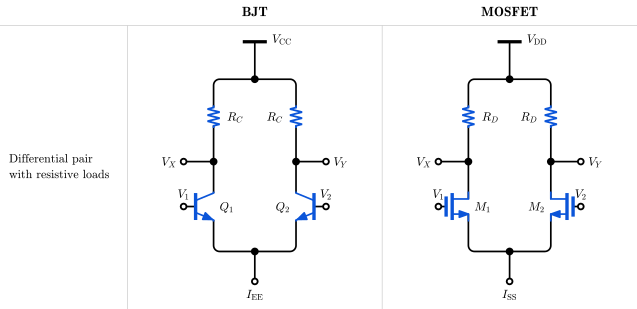

In [2]:
# HIDE/SHOW
show(C.pair_loaded)

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 1**

| | BJT |
|---|---|
| **Problem** | A bipolar differential pair has collector resistors of $1\,\mathrm{k}\Omega$, a tail current of $0.5\,\mathrm{mA}$ and $V_{CC}=2.5\,\mathrm{V}$. The differential input is so large that the whole tail current flows in one transistor. How high may the base voltage of that transistor be before it saturates? |
| **Given** | $R_C=1\,\mathrm{k}\Omega$, $I_{EE}=0.5\,\mathrm{mA}$, $V_{CC}=2.5\,\mathrm{V}$ |
| **Answer 1** | **Fully steered current.** The conducting transistor carries all of $I_{EE}$ (the other is off). |
| **Answer 2** | **Its collector voltage.** $V_C$ $=V_{CC}-R_CI_{EE}$ $=2.5\,\mathrm{V}-1\,\mathrm{k}\Omega\times0.5\,\mathrm{mA}$ $=2.0\,\mathrm{V}$. |
| **Answer 3** | **Active-mode limit.** The base must not exceed the collector: $V_B\le V_C$. |
| **Result** | $V_{B,max}=2\,\mathrm{V}$ |

**Problem 2**

| | BJT |
|---|---|
| **Problem** | A bipolar pair has equal collector resistors $R_C$, tail current $I_{EE}$ and both transistors stay active. Sketch the outputs when the inputs are a pair of opposite sinusoids about $V_{CM}$: (b) amplitude $1\,\mathrm{mV}$ each, (c) amplitude $100\,\mathrm{mV}$ each. |
| **Given** | $R_C$, $I_{EE}$, $V_{CC}$ symbolic; inputs $V_{in1,2}$ $=V_{CM}\pm V_m\sin\omega t$; $V_m=1\,\mathrm{mV}$ or $100\,\mathrm{mV}$ |
| **Answer 1** | **Differential swing.** The difference $V_{in1}-V_{in2}=2V_m\sin\omega t$ has peak $2\,\mathrm{mV}$ in case (b) and $200\,\mathrm{mV}$ in case (c). |
| **Answer 2** | **Linearity limit.** The pair is linear only for a difference well below about $4V_T\approx100\,\mathrm{mV}$. |
| **Answer 3** | **Case (b): small signal.** $2\,\mathrm{mV}\ll100\,\mathrm{mV}$, so the pair is linear: each output is a sinusoid of amplitude $g_mR_C\times1\,\mathrm{mV}$ ($g_m=I_{EE}/2V_T$), the two in antiphase about the output CM level $V_{CC}-R_CI_{EE}/2$. |
| **Answer 4** | **Case (c): when it switches.** Once $V_{in1}$ is about $50\,\mathrm{mV}$ above and $V_{in2}$ about $50\,\mathrm{mV}$ below $V_{CM}$ (difference $\approx100\,\mathrm{mV}$) $Q_1$ takes nearly all of $I_{EE}$. |
| **Answer 5** | **Saturated outputs.** Then $V_{out1}\approx V_{CC}-R_CI_{EE}$, $V_{out2}\approx V_{CC}$. The outputs stay at these levels until $\lvert V_{in1}-V_{in2}\rvert$ drops below about $100\,\mathrm{mV}$, and then swap for the opposite half cycle. |
| **Answer 6** | **Shape.** The outputs are therefore nearly square waves of peak-to-peak value $R_CI_{EE}$, between $V_{CC}-R_CI_{EE}$ and $V_{CC}$: the pair acts as a limiter. |
| **Result** | (b) linear sinusoids, amplitude $g_mR_C\cdot1\,\mathrm{mV}$; (c) clipped, swinging between $V_{CC}-R_CI_{EE}$ and $V_{CC}$ (limiter) |

**Problem 3**

| | BJT |
|---|---|
| **Problem** | Bipolar pair: $V_{CC}=2.5\,\mathrm{V}$, equal collector resistors $R_C$, base of $Q_1$ at $+2\,\mathrm{V}$, base of $Q_2$ at $+1\,\mathrm{V}$, tail current $I_{EE}=1\,\mathrm{mA}$. What is the largest $R_C$ that keeps $Q_1$ in the active region? |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $V_{in1}=2\,\mathrm{V}$, $V_{in2}=1\,\mathrm{V}$, $I_{EE}=1\,\mathrm{mA}$ |
| **Answer 1** | **Current steering.** The 1 V input difference is far beyond $4V_T$, so $Q_1$ takes all of the tail: $I_{C1}$ $\approx I_{EE}$ $=1\,\mathrm{mA}$. |
| **Answer 2** | **Collector voltage.** $V_X=V_{CC}-R_CI_{EE}$ |
| **Answer 3** | **Active condition.** The base-collector junction must not be forward biased: $V_X\ge V_{B1}=2\,\mathrm{V}$. |
| **Answer 4** | **Solve.** $R_C\le\dfrac{V_{CC}-V_{B1}}{I_{EE}}$ $=\dfrac{2.5-2}{1\,\mathrm{mA}}$ $=500\,\Omega$ |
| **Result** | $R_{C,max}=500\,\Omega$ |

**Problem 4**

| | BJT |
|---|---|
| **Problem** | Bipolar pair: $V_{CC}=2.5\,\mathrm{V}$, $R_C=500\,\Omega$ in each collector, base of $Q_1$ at $+1\,\mathrm{V}$, base of $Q_2$ at $+2\,\mathrm{V}$, tail current $I_{EE}$. What is the largest $I_{EE}$ that keeps $Q_2$ in the active region? |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $R_C=500\,\Omega$, $V_{in1}=1\,\mathrm{V}$, $V_{in2}=2\,\mathrm{V}$ |
| **Answer 1** | **Current steering.** $Q_2$ carries the whole tail: $I_{C2}\approx I_{EE}$, so $V_Y=V_{CC}-R_CI_{EE}$. |
| **Answer 2** | **Active condition.** $V_Y\ge V_{B2}=2\,\mathrm{V}$. |
| **Answer 3** | **Solve.** $I_{EE}\le\dfrac{2.5-2}{500}$ $=1\,\mathrm{mA}$ |
| **Result** | $I_{EE,max}=1\,\mathrm{mA}$ |

**Problem 5**

| | BJT |
|---|---|
| **Problem** | In the circuit ($V_{CC}=2.5\,\mathrm{V}$, base of $Q_1$ at $2\,\mathrm{V}$, base of $Q_2$ at $1\,\mathrm{V}$), let $I_{EE}=1\,\mathrm{mA}$ and $R_C=800\,\Omega$. In which region does $Q_1$ operate? |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $V_{in1}=2\,\mathrm{V}$, $I_{EE}=1\,\mathrm{mA}$, $R_C=800\,\Omega$ |
| **Answer 1** | **Current.** $Q_1$ takes the whole tail, $I_{C1}\approx1\,\mathrm{mA}$ (assuming it were active). |
| **Answer 2** | **Collector voltage.** $V_X$ $=2.5-800\times1\,\mathrm{mA}$ $=1.7\,\mathrm{V}$ |
| **Answer 3** | **Junction bias.** $V_{BC}=2-1.7=0.3\,\mathrm{V}>0$: the base-collector junction is forward biased. |
| **Answer 4** | **Region.** $Q_1$ is in saturation; with only $0.3\,\mathrm{V}$ of forward bias it is soft saturation, so it still carries nearly all of $I_{EE}$ and $V_X\approx1.7\,\mathrm{V}$. $R_C$ exceeds the $500\,\Omega$ limit of Problem 3. |
| **Result** | $V_X=1.7\,\mathrm{V}$, $V_{BC}=0.3\,\mathrm{V}$: $Q_1$ in (soft) saturation |

**Problem 6**

| | BJT |
|---|---|
| **Problem** | The bipolar pair with collector resistors $R_C$ to $V_{CC}$ and tail $I_{EE}$ has the characteristics: $I_{C1}$, $I_{C2}$ go between $0$ and $I_{EE}$ and cross at $I_{EE}/2$; $V_X$, $V_Y$ go between $V_{CC}$ and $V_{CC}-R_CI_{EE}$ and cross at $V_{CC}-R_CI_{EE}/2$, all versus $V_{in1}-V_{in2}$. How do these plots change if (a) $I_{EE}$ is halved, (b) $V_{CC}$ rises by $\Delta V$, (c) $R_C$ is halved? |
| **Given** | Reference: $I_{C1,2}\in[0,I_{EE}]$, $V_{X,Y}\in[V_{CC}-R_CI_{EE},V_{CC}]$ |
| **Answer 1** | **Shape of the transition.** $I_{C1}$ $=I_{EE}/[1+\exp(-(V_{in1}-V_{in2})/V_T)]$: the width of the transition (about $\pm4V_T$) depends only on $V_T$, not on $I_{EE}$, $R_C$ or $V_{CC}$. |
| **Answer 2** | **(a) Currents.** Halving $I_{EE}$: the currents saturate at $I_{EE}/2$ and cross at $I_{EE}/4$; same horizontal scale. |
| **Answer 3** | **(a) Outputs.** $V_X$, $V_Y$ go between $V_{CC}$ and $V_{CC}-R_CI_{EE}/2$, crossing at $V_{CC}-R_CI_{EE}/4$: half the swing, CM level moves up, slope at the origin halves. |
| **Answer 4** | **(b) Supply raised.** Currents unchanged (no Early effect); the output curves shift up rigidly by $\Delta V$: range $V_{CC}+\Delta V$ to $V_{CC}+\Delta V-R_CI_{EE}$. |
| **Answer 5** | **(c) $R_C$ halved.** Currents unchanged; outputs between $V_{CC}$ and $V_{CC}-R_CI_{EE}/2$, crossing at $V_{CC}-R_CI_{EE}/4$: half the swing and half the small-signal gain. |
| **Answer 6** | **Numeric example.** For $V_{CC}=2.5\,\mathrm{V}$, $R_C=1\,\mathrm{k}\Omega$, $I_{EE}=1\,\mathrm{mA}$: original range $1.5$ to $2.5\,\mathrm{V}$ (CM $2\,\mathrm{V}$); (a) and (c) give $2.0$ to $2.5\,\mathrm{V}$ (CM $2.25\,\mathrm{V}$). |
| **Result** | (a) currents and output swing halved, CM $V_{CC}-R_CI_{EE}/4$; (b) outputs shifted up by $\Delta V$, currents unchanged; (c) currents unchanged, output swing halved; transition width set by $V_T$ in all cases |

**Problem 7**

| | BJT |
|---|---|
| **Problem** | In the bipolar pair (tail $I_{EE}$, inputs $V_{in1}$, $V_{in2}$), $I_{C1}/I_{C2}=5$. What input difference is needed? Keeping that input applied, what does $I_{C1}/I_{C2}$ become when the temperature rises from $27^\circ\mathrm{C}$ to $100^\circ\mathrm{C}$? |
| **Given** | $I_{C1}/I_{C2}=5$, $V_T=26\,\mathrm{mV}$ at $300\,\mathrm{K}$, $T_2=373\,\mathrm{K}$ |
| **Answer 1** | **Current ratio.** $V_{in1}-V_{in2}$ $=V_T\ln\dfrac{I_{C1}}{I_{C2}}$ (matched $I_S$). |
| **Answer 2** | **Input.** $V_{in1}-V_{in2}$ $=26\,\mathrm{mV}\times\ln5$ $=41.8\,\mathrm{mV}$ |
| **Answer 3** | **$V_T$ at 100 °C.** $V_T\propto T$: $V_T$ $=26\,\mathrm{mV}\times\dfrac{373}{300}$ $=32.3\,\mathrm{mV}$ |
| **Answer 4** | **New ratio.** $\dfrac{I_{C1}}{I_{C2}}$ $=\exp\dfrac{41.8}{32.3}$ $=3.65$ |
| **Result** | $V_{in1}-V_{in2}=41.8\,\mathrm{mV}$; at $100^\circ\mathrm{C}$, $I_{C1}/I_{C2}=3.65$ |

**Problem 8**

| | BJT |
|---|---|
| **Problem** | In the bipolar pair, the transconductance of $Q_2$ ($g_{m2}=I_{C2}/V_T$) falls as $V_{in1}-V_{in2}$ rises because $I_{C2}$ falls. Using $I_{C2}$ $=I_{EE}/[1+\exp((V_{in1}-V_{in2})/V_T)]$, find the input difference at which $g_{m2}$ is half its equilibrium value. |
| **Given** | $I_{C2}$ $=I_{EE}/[1+\exp((V_{in1}-V_{in2})/V_T)]$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Target current.** At equilibrium $I_{C2}=I_{EE}/2$; halving $g_{m2}$ means $I_{C2}=I_{EE}/4$. |
| **Answer 2** | **Equation.** $1+\exp\dfrac{V_{in1}-V_{in2}}{V_T}$ $=4$ |
| **Answer 3** | **Solve.** $V_{in1}-V_{in2}$ $=V_T\ln3$ $=26\,\mathrm{mV}\times1.0986$ $=28.6\,\mathrm{mV}$ |
| **Result** | $V_{in1}-V_{in2}$ $=V_T\ln3$ $=28.6\,\mathrm{mV}$ |

**Problem 9**

| | BJT |
|---|---|
| **Problem** | The input difference applied to a bipolar differential pair must not change the bias current (and hence the transconductance) of either transistor by more than $10\%$. Using $I_{C2}$ $=I_{EE}/[1+\exp((V_{in1}-V_{in2})/V_T)]$, find the largest allowed input difference. |
| **Given** | $\Delta I_C/I_C\le10\%$ of $I_{EE}/2$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Limit.** $I_{C2}\ge0.9\times I_{EE}/2$ $=0.45I_{EE}$ (then $I_{C1}\le0.55I_{EE}$, also a $10\%$ change). |
| **Answer 2** | **Equation.** $1+\exp\dfrac{V_{in1}-V_{in2}}{V_T}$ $=\dfrac{1}{0.45}$ $=2.222$ |
| **Answer 3** | **Solve.** $V_{in1}-V_{in2}$ $=V_T\ln1.222$ $=26\,\mathrm{mV}\times0.2007$ $=5.22\,\mathrm{mV}$ |
| **Answer 4** | **Symmetry.** The same magnitude applies for negative inputs: $\lvert V_{in1}-V_{in2}\rvert\le5.22\,\mathrm{mV}$. |
| **Result** | $\lvert V_{in1}-V_{in2}\rvert_{max}$ $=V_T\ln(11/9)$ $=5.22\,\mathrm{mV}$ |

**Problem 10**

| | BJT |
|---|---|
| **Problem** | For the bipolar pair define the differential transconductance $G_m$ $=\partial(I_{C1}-I_{C2})/\partial(V_{in1}-V_{in2})$. Using the large-signal expressions for $I_{C1}$ and $I_{C2}$, find $G_m$ as a function of $V_{in1}-V_{in2}$, sketch it, give its maximum, and find the input difference at which it falls to half of the maximum. |
| **Given** | $I_{C1,2}$ $=I_{EE}/[1+\exp(\mp(V_{in1}-V_{in2})/V_T)]$, $V_T=26\,\mathrm{mV}$; let $x=V_{in1}-V_{in2}$ |
| **Answer 1** | **Difference current.** $I_{C1}-I_{C2}$ $=I_{EE}\dfrac{e^{x/V_T}-1}{e^{x/V_T}+1}$ $=I_{EE}\tanh\dfrac{x}{2V_T}$ |
| **Answer 2** | **Derivative.** $G_m$ $=\dfrac{I_{EE}}{2V_T}\,\mathrm{sech}^2\dfrac{x}{2V_T}$ |
| **Answer 3** | **Shape.** A bell-shaped curve, even in $x$, falling to nearly zero for $\lvert x\rvert>4V_T$. |
| **Answer 4** | **Maximum.** At $x=0$: $G_{m,max}=\dfrac{I_{EE}}{2V_T}$ (the $g_m$ of each transistor at $I_{EE}/2$). |
| **Answer 5** | **Half point.** $\cosh^2\dfrac{x}{2V_T}=2$, so $\dfrac{x}{2V_T}$ $=\cosh^{-1}\sqrt2$ $=0.881$. |
| **Answer 6** | **Value.** $\lvert x\rvert$ $=1.76V_T$ $=45.8\,\mathrm{mV}$ |
| **Result** | $G_m$ $=\frac{I_{EE}}{2V_T}\mathrm{sech}^2\frac{V_{in1}-V_{in2}}{2V_T}$; max $I_{EE}/(2V_T)$ at zero input; half at $\lvert V_{in1}-V_{in2}\rvert$ $=1.76V_T$ $=45.8\,\mathrm{mV}$ |

**Problem 11**

| | BJT |
|---|---|
| **Problem** | The bipolar pair with collector resistors $R_C$ and tail $I_{EE}$ has $V_{out1}-V_{out2}$ $=-R_CI_{EE}\tanh[(V_{in1}-V_{in2})/(2V_T)]$. Define the small-signal gain $A_v$ $=\partial(V_{out1}-V_{out2})/\partial(V_{in1}-V_{in2})$; derive it and evaluate it when $V_{in1}-V_{in2}$ contains a dc component of $30\,\mathrm{mV}$. |
| **Given** | $V_{out1}-V_{out2}$ $=-R_CI_{EE}\tanh\frac{V_{in1}-V_{in2}}{2V_T}$, dc input $30\,\mathrm{mV}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Differentiate.** $A_v$ $=-\dfrac{R_CI_{EE}}{2V_T}\,\mathrm{sech}^2\dfrac{V_{in1}-V_{in2}}{2V_T}$ |
| **Answer 2** | **At zero input.** $A_v$ $=-\dfrac{R_CI_{EE}}{2V_T}$ $=-g_mR_C$ with $g_m=\dfrac{I_{EE}/2}{V_T}$. |
| **Answer 3** | **Argument at 30 mV.** $\dfrac{30}{2\times26}=0.577$, $\cosh0.577=1.171$ |
| **Answer 4** | **Gain.** $\mathrm{sech}^20.577=0.729$, so $A_v$ $=-0.729\dfrac{R_CI_{EE}}{2V_T}$ $=-0.729\,g_mR_C$ ($27\%$ below the equilibrium gain). |
| **Answer 5** | **Example.** With $R_C=500\,\Omega$, $I_{EE}=1\,\mathrm{mA}$: $A_v$ falls from $-9.62$ to $-7.01$. |
| **Result** | $A_v$ $=-\frac{R_CI_{EE}}{2V_T}\mathrm{sech}^2\frac{V_{in1}-V_{in2}}{2V_T}$; at $30\,\mathrm{mV}$ dc, $A_v=-0.729\,R_CI_{EE}/(2V_T)$ |

**Problem 12**

| | BJT |
|---|---|
| **Problem** | Bipolar pair (as in Problem 2) with $R_C=500\,\Omega$ in each collector, $I_{EE}=1\,\mathrm{mA}$, $V_{CC}=2.5\,\mathrm{V}$, inputs $V_{in1}=V_0\sin\omega t+V_{CM}$, $V_{in2}=-V_0\sin\omega t+V_{CM}$ with $V_{CM}=1\,\mathrm{V}$. (a) For $V_0=2\,\mathrm{mV}$, plot the outputs versus time. (b) For $V_0=50\,\mathrm{mV}$, find the time $t_1$ at which one transistor carries $95\%$ of the tail current, and plot the outputs. |
| **Given** | $R_C=500\,\Omega$, $I_{EE}=1\,\mathrm{mA}$, $V_{CC}=2.5\,\mathrm{V}$, $V_{CM}=1\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Equilibrium.** $I_{C1}=I_{C2}=0.5\,\mathrm{mA}$, $V_{out1}$ $=V_{out2}$ $=2.5-0.25$ $=2.25\,\mathrm{V}$, well above the $1\,\mathrm{V}$ bases (active). |
| **Answer 2** | **(a) Small signal.** $V_{in1}-V_{in2}$ $=4\,\mathrm{mV}\sin\omega t\ll V_T$: linear. $g_m$ $=\dfrac{0.5\,\mathrm{mA}}{26\,\mathrm{mV}}$ $=19.2\,\mathrm{mS}$, $g_mR_C=9.62$. |
| **Answer 3** | **(a) Waveforms.** $V_{out1}$ $=2.25\,\mathrm{V}-19.2\,\mathrm{mV}\sin\omega t$, $V_{out2}$ $=2.25\,\mathrm{V}+19.2\,\mathrm{mV}\sin\omega t$; $V_{out1}-V_{out2}$ $=-38.5\,\mathrm{mV}\sin\omega t$ (the exact $\tanh$ gives $38.4\,\mathrm{mV}$). |
| **Answer 4** | **(b) 95% condition.** $I_{C1}/I_{C2}=0.95/0.05=19$, so $V_{in1}-V_{in2}$ $=V_T\ln19$ $=76.6\,\mathrm{mV}$. |
| **Answer 5** | **(b) Time.** $2V_0\sin\omega t_1$ $=76.6\,\mathrm{mV}$: $\sin\omega t_1=0.766$, $\omega t_1=0.872\,\mathrm{rad}$, $t_1=0.872/\omega=0.139T$. |
| **Answer 6** | **(b) Other instants.** $Q_1$ keeps at least $95\%$ for $0.872<\omega t<2.27$; $Q_2$ does for $4.01<\omega t<5.41$; together $44.5\%$ of each period. |
| **Answer 7** | **(b) Peaks.** At $\sin\omega t=1$ the input is $100\,\mathrm{mV}$: $I_{C1}=0.979\,\mathrm{mA}$, $V_{out1}=2.01\,\mathrm{V}$, $V_{out2}=2.49\,\mathrm{V}$; $V_{out1}-V_{out2}$ $=-0.479\,\mathrm{V}$. |
| **Answer 8** | **(b) Waveforms.** $V_{out1,2}$ $=2.5\,\mathrm{V}-R_CI_{C1,2}$ swing between about $2.01$ and $2.49\,\mathrm{V}$ around $2.25\,\mathrm{V}$, in opposite phase, with flattened tops and bottoms (sinusoid driven into the $\tanh$ saturation, approaching a square wave). |
| **Answer 9** | **Check the region.** Lowest collector voltage $2.01\,\mathrm{V}$ stays above the $1.05\,\mathrm{V}$ highest base voltage: both devices remain active. |
| **Result** | (a) $V_{out1,2}$ $=2.25\,\mathrm{V}\mp19.2\,\mathrm{mV}\sin\omega t$; (b) $t_1=0.872/\omega$ ($0.139T$), outputs clipped-sine between $2.01$ and $2.49\,\mathrm{V}$ |

**Problem 13**

| | BJT |
|---|---|
| **Problem** | The characteristics show, versus $V_{in1}-V_{in2}$, the collector currents of a bipolar pair (from $0$ to $I_{EE}$, crossing at $I_{EE}/2$), the outputs (from $V_{CC}$ to $V_{CC}-R_CI_{EE}$) and the differential output (from $+R_CI_{EE}$ to $-R_CI_{EE}$). Explain how they change when the temperature rises from $27^\circ\mathrm{C}$ to $100^\circ\mathrm{C}$. |
| **Given** | $V_T=26\,\mathrm{mV}$ at $300\,\mathrm{K}$; $I_{EE}$, $R_C$ assumed independent of temperature |
| **Answer 1** | **What depends on T.** All curves depend on the input only through $(V_{in1}-V_{in2})/V_T$, e.g. $V_{out1}-V_{out2}$ $=-R_CI_{EE}\tanh\dfrac{V_{in1}-V_{in2}}{2V_T}$. |
| **Answer 2** | **$V_T$ at 100 °C.** $V_T$ $=26\,\mathrm{mV}\times373/300$ $=32.3\,\mathrm{mV}$, $1.24$ times larger. |
| **Answer 3** | **End values.** The limits $0$, $I_{EE}$, $V_{CC}$, $V_{CC}-R_CI_{EE}$, $\pm R_CI_{EE}$ and the crossing points are unchanged. |
| **Answer 4** | **Stretching.** Every curve stretches horizontally by $1.24$: steering $98\%$ now needs about $4V_T=129\,\mathrm{mV}$ instead of $104\,\mathrm{mV}$. |
| **Answer 5** | **Slope.** The small-signal gain at the origin, $R_CI_{EE}/(2V_T)$, falls by the factor $1.24$ (about $20\%$ lower). |
| **Result** | Curves stretch horizontally by $373/300=1.24$ ($V_T$: $26\to32.3\,\mathrm{mV}$); end levels unchanged; slope at origin $20\%$ lower |

**Problem 14**

| | BJT |
|---|---|
| **Problem** | A bipolar differential pair with collector resistors $R_C=500\,\Omega$ to $V_{CC}=2.5\,\mathrm{V}$ and an ideal tail current $I_{EE}=1\,\mathrm{mA}$ (the circuit of Problem 2 with the values of Problem 12) is driven by $V_{in1}=V_0\sin\omega t+V_{CM}$, $V_{in2}=-V_0\sin\omega t+V_{CM}$ with $V_{CM}=1\,\mathrm{V}$. Plot (describe) the output waveforms $V_{out1}$, $V_{out2}$ for $V_0=80\,\mathrm{mV}$ and for $V_0=160\,\mathrm{mV}$, and explain why the output looks more like a sharp square wave as $V_0$ grows. |
| **Given** | $R_C=500\,\Omega$, $I_{EE}=1\,\mathrm{mA}$, $V_{CC}=2.5\,\mathrm{V}$, $V_{CM}=1\,\mathrm{V}$, $V_0=80$ or $160\,\mathrm{mV}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Input difference.** $\Delta V_{in}$ $=V_{in1}-V_{in2}$ $=2V_0\sin\omega t$, peak $160\,\mathrm{mV}=6.15V_T$ for $V_0=80\,\mathrm{mV}$ and $320\,\mathrm{mV}=12.3V_T$ for $V_0=160\,\mathrm{mV}$ |
| **Answer 2** | **Large-signal currents.** $I_{C1}$ $=\dfrac{I_{EE}}{1+\exp(-\Delta V_{in}/V_T)}$, $I_{C2}=I_{EE}-I_{C1}$ (the large-signal law of the pair, with $\alpha\approx1$) |
| **Answer 3** | **Output levels.** $V_{out1}=V_{CC}-R_CI_{C1}$, $V_{out2}=V_{CC}-R_CI_{C2}$; they swing between $V_{CC}=2.5\,\mathrm{V}$ and $V_{CC}-R_CI_{EE}=2.0\,\mathrm{V}$, and $V_{out1}-V_{out2}$ $=-R_CI_{EE}\tanh(\Delta V_{in}/2V_T)$ |
| **Answer 4** | **(a) $V_0=80\,\mathrm{mV}$.** At the input peak $I_{C1}=0.998\,\mathrm{mA}$, so $V_{out1}$ reaches $2.001\,\mathrm{V}$ and $V_{out2}$ reaches $2.499\,\mathrm{V}$: both outputs are clipped, nearly square waves of $0.5\,\mathrm{V}$ peak to peak, in antiphase, centred on $2.25\,\mathrm{V}$; $V_{out1}$ is low while $\sin\omega t>0$ |
| **Answer 5** | **Width of the transition.** The differential output is within $90\,\%$ of its saturated value $\pm R_CI_{EE}=\pm0.5\,\mathrm{V}$ once $\tanh(\Delta V_{in}/2V_T)\ge0.9$, i.e. $\lvert\Delta V_{in}\rvert\ge76.6\,\mathrm{mV}$; this needs $\lvert\sin\omega t\rvert\ge0.478$, so each edge lasts $\Delta(\omega t)$ $=2\times0.499$ $=0.998\,\mathrm{rad}$ (about $15.9\,\%$ of a period per edge) |
| **Answer 6** | **(b) $V_0=160\,\mathrm{mV}$.** Peak $I_{C1}=1.000\,\mathrm{mA}$ (within $5\,\mathrm{ppm}$); the same levels $2.0$ and $2.5\,\mathrm{V}$, but now $\lvert\sin\omega t\rvert\ge0.239$ suffices, so each edge lasts only $\Delta(\omega t)$ $=0.483\,\mathrm{rad}$ ($7.7\,\%$ of a period): a sharper square wave |
| **Answer 7** | **Why it sharpens.** The pair switches fully within roughly $\lvert\Delta V_{in}\rvert\lesssim4V_T$ $\approx100\,\mathrm{mV}$; a larger sinusoid sweeps through this fixed window faster (its slope at the zero crossing is $2V_0\omega$), so the time spent in the linear region, and hence the edge duration, shrinks roughly as $1/V_0$, while the flat tops (one transistor off) occupy more of the period |
| **Answer 8** | **Check the active region.** Highest base voltage $1.16\,\mathrm{V}$, lowest collector voltage $2.0\,\mathrm{V}$: $V_{BC}<0$, so $Q_1$, $Q_2$ stay active as assumed |
| **Result** | $V_{out1},V_{out2}$: antiphase near-square waves between $2.0\,\mathrm{V}$ and $2.5\,\mathrm{V}$; each edge lasts $\Delta(\omega t)$ $=0.998\,\mathrm{rad}$ for $V_0=80\,\mathrm{mV}$ and $0.483\,\mathrm{rad}$ for $V_0=160\,\mathrm{mV}$ (from $5\,\%$ to $95\,\%$ of the differential swing, i.e. between $\mp0.45\,\mathrm{V}$); sharper because the fixed switching window of about $\pm4V_T$ is crossed faster |

**Problem 15**

| | BJT |
|---|---|
| **Problem** | For the pair of Problem 14 ($R_C=500\,\Omega$, $I_{EE}=1\,\mathrm{mA}$, $V_{CC}=2.5\,\mathrm{V}$, inputs $\pm V_0\sin\omega t$ around $1\,\mathrm{V}$) with $\omega=2\pi\times100\,\mathrm{MHz}$, estimate the slope of the edges of the output square waves for $V_0=80\,\mathrm{mV}$ and $V_0=160\,\mathrm{mV}$. |
| **Given** | $R_C=500\,\Omega$, $I_{EE}=1\,\mathrm{mA}$, $\omega=2\pi\times100\,\mathrm{MHz}$, $V_0=80$ or $160\,\mathrm{mV}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Output versus input.** $V_{out1}-V_{out2}$ $=-R_CI_{EE}\tanh\dfrac{\Delta V_{in}}{2V_T}$ with $\Delta V_{in}=2V_0\sin\omega t$ |
| **Answer 2** | **Steepest point.** The slope is largest at the zero crossing, where $\tanh$ has slope $1/(2V_T)$ and $d\Delta V_{in}/dt=2V_0\omega$: $\left.\dfrac{d(V_{out1}-V_{out2})}{dt}\right\rvert_{\max}$ $=\dfrac{R_CI_{EE}V_0\omega}{V_T}$, i.e. $g_mR_C\cdot2V_0\omega$ with $g_m=I_{EE}/2V_T$ |
| **Answer 3** | **$V_0=80\,\mathrm{mV}$.** $\dfrac{(500)(1\,\mathrm{mA})(0.08)(6.28\times10^{8})}{0.026}$ $=9.67\times10^{8}\,\mathrm{V/s}$ $=0.967\,\mathrm{V/ns}$ differential; each single-ended output moves at half that, $0.483\,\mathrm{V/ns}$ |
| **Answer 4** | **$V_0=160\,\mathrm{mV}$.** Twice as steep: $1.93\,\mathrm{V/ns}$ differential, $0.967\,\mathrm{V/ns}$ single-ended |
| **Answer 5** | **Edge duration.** Average view: while $\lvert\Delta V_{in}\rvert\le76.6\,\mathrm{mV}$ ($\tanh=0.9$) the differential output moves between $+0.45$ and $-0.45\,\mathrm{V}$, i.e. through $0.9\,\mathrm{V}$ ($5\,\%$ to $95\,\%$ of its $1\,\mathrm{V}$ swing). This takes $\Delta t$ $=2\arcsin(76.6\,\mathrm{mV}/2V_0)/\omega$ $=1.59\,\mathrm{ns}$ for $80\,\mathrm{mV}$ and $0.769\,\mathrm{ns}$ for $160\,\mathrm{mV}$, i.e. on average $0.9\,\mathrm{V}/\Delta t=0.567$ and $1.17\,\mathrm{V/ns}$, below the peak values because the edge flattens towards its ends |
| **Result** | Peak slope $\approx0.97\,\mathrm{V/ns}$ ($V_0=80\,\mathrm{mV}$) and $1.93\,\mathrm{V/ns}$ ($V_0=160\,\mathrm{mV}$) for $V_{out1}-V_{out2}$; half these values for each single-ended output |

**Problem 16**

| | BJT |
|---|---|
| **Problem** | The bipolar differential pair (npn pair, collector resistors $R_C$ to $V_{CC}=2.5\,\mathrm{V}$, ideal tail $I_{EE}$) must work with an input common-mode level of 1.2 V without the transistors saturating. Design it for the largest voltage gain with a power budget of 3 mW. |
| **Given** | $V_{in,CM}=1.2\,\mathrm{V}$, $P=3\,\mathrm{mW}$, $V_{CC}=2.5\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$, $V_A=\infty$ |
| **Answer 1** | **Tail current.** $I_{EE}$ $=3\,\mathrm{mW}/2.5\,\mathrm{V}$ $=1.2\,\mathrm{mA}$, $I_C=0.6\,\mathrm{mA}$ each |
| **Answer 2** | **Saturation limit.** No saturation requires $V_{BC}\le0$: $V_{CC}-I_CR_C\ge V_{in,CM}$ $=1.2\,\mathrm{V}$, so $I_CR_C\le1.3\,\mathrm{V}$ |
| **Answer 3** | **Largest $R_C$.** $R_C$ $=1.3\,\mathrm{V}/0.6\,\mathrm{mA}$ $=2.17\,\mathrm{k}\Omega$ |
| **Answer 4** | **Gain.** $\lvert A_v\rvert$ $=g_mR_C$ $=\dfrac{I_CR_C}{V_T}$ $=\dfrac{1.3}{0.026}$ $=50$ |
| **Result** | $I_{EE}=1.2\,\mathrm{mA}$, $R_C=2.17\,\mathrm{k}\Omega$, $\lvert A_v\rvert=50$ |

**Problem 17**

| | BJT |
|---|---|
| **Problem** | An npn differential pair has $R_C=5\,\mathrm{k}\Omega$ in each collector, supplies $V_{CC}=+2.5\,\mathrm{V}$, $V_{EE}=-2.5\,\mathrm{V}$, tail current source $I=0.4\,\mathrm{mA}$ that needs $V_{CS}=0.3\,\mathrm{V}$, $V_{BE}=0.7\,\mathrm{V}$, and the transistors stay active while $V_{CB}\ge-0.4\,\mathrm{V}$ (base at most $0.4\,\mathrm{V}$ above the collector). Find the input common-mode range. |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $V_{EE}=-2.5\,\mathrm{V}$, $R_C=5\,\mathrm{k}\Omega$, $I=0.4\,\mathrm{mA}$, $V_{CS}=0.3\,\mathrm{V}$, $V_{BE}=0.7\,\mathrm{V}$ |
| **Answer 1** | **Currents.** $I_{C1}$ $=I_{C2}\simeq I_{E}$ $=I/2$ $=0.2\,\mathrm{mA}$. |
| **Answer 2** | **Collector voltage.** $V_C$ $=V_{CC}-I_CR_C$ $=2.5-0.2\times5$ $=1.5\,\mathrm{V}$. |
| **Answer 3** | **Upper limit.** $V_{CM,max}$ $=V_C+0.4$ $=1.5+0.4$ $=+1.9\,\mathrm{V}$. |
| **Answer 4** | **Lower limit.** The tail source needs $V_{CS}$: $V_{CM,min}$ $=V_{EE}+V_{CS}+V_{BE}$ $=-2.5+0.3+0.7$ $=-1.5\,\mathrm{V}$ (with $V_{EE}=-2.5\,\mathrm{V}$). |
| **Answer 5** | **Range.** $-1.5\,\mathrm{V}\le V_{ICM}\le+1.9\,\mathrm{V}$. |
| **Result** | $-1.5\,\mathrm{V}\le V_{ICM}\le+1.9\,\mathrm{V}$ |

**Problem 18**

| | BJT |
|---|---|
| **Problem** | An npn differential pair is biased by an ideal tail current $I=0.4\,\mathrm{mA}$, with $R_C=5\,\mathrm{k}\Omega$, $V_{CC}=2.5\,\mathrm{V}$, $\alpha=0.99$, and $V_{BE}=0.7\,\mathrm{V}$ at $i_C=1\,\mathrm{mA}$. Both bases are at $-1\,\mathrm{V}$. Find $I_E$, $I_C$, $V_{BE}$, $V_E$ and $V_C$ of each transistor. |
| **Given** | $I=0.4\,\mathrm{mA}$, $R_C=5\,\mathrm{k}\Omega$, $V_{CC}=2.5\,\mathrm{V}$, $\alpha=0.99$, $V_B=-1\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Emitter currents.** By symmetry $I_{E1}=I_{E2}=I/2=0.2\,\mathrm{mA}$. |
| **Answer 2** | **Collector currents.** $I_C$ $=\alpha I_E$ $=0.99\times0.2$ $=0.198\,\mathrm{mA}$. |
| **Answer 3** | **Base-emitter voltage.** $V_{BE}$ $=0.7+V_T\ln\dfrac{0.198}{1}$ $=0.7+0.025\ln0.198$ $=0.660\,\mathrm{V}$. |
| **Answer 4** | **Emitter voltage.** $V_E$ $=V_B-V_{BE}$ $=-1-0.660$ $=-1.66\,\mathrm{V}$. |
| **Answer 5** | **Collector voltage.** $V_C$ $=V_{CC}-I_CR_C$ $=2.5-0.198\times5$ $=+1.51\,\mathrm{V}$. |
| **Result** | $I_E=0.2\,\mathrm{mA}$, $I_C=0.198\,\mathrm{mA}$, $V_{BE}=0.660\,\mathrm{V}$, $V_E=-1.66\,\mathrm{V}$, $V_C=+1.51\,\mathrm{V}$ |

**Problem 19**

| | BJT |
|---|---|
| **Problem** | An npn pair has $V_{CC}=1.2\,\mathrm{V}$, $V_{EE}=-1.2\,\mathrm{V}$, tail current $I=20\,\mu\mathrm{A}$, $R_C=82\,\mathrm{k}\Omega$, $\alpha=0.98$, and $V_{BE}=0.69\,\mathrm{V}$ at $1\,\mathrm{mA}$. The tail source needs $0.3\,\mathrm{V}$ across it, and the transistors need $v_{CE}\ge0.3\,\mathrm{V}$ to stay active. (a) Find $V_{BE}$ and $V_C$ at balance. (b) Find the input common-mode range. (c) Find $v_{B1}-v_{B2}$ for emitter currents of $11\,\mu\mathrm{A}$ and $9\,\mu\mathrm{A}$. |
| **Given** | $I=20\,\mu\mathrm{A}$, $R_C=82\,\mathrm{k}\Omega$, $\pm1.2\,\mathrm{V}$, $\alpha=0.98$, $V_{BE}(1\,\mathrm{mA})$ $=0.69\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **(a) Currents.** $I_E=10\,\mu\mathrm{A}$, $I_C$ $=0.98\times10$ $=9.8\,\mu\mathrm{A}$. |
| **Answer 2** | **(a) $V_{BE}$.** $V_{BE}$ $=0.69+0.025\ln\dfrac{9.8\times10^{-3}}{1}$ $=0.574\,\mathrm{V}$. |
| **Answer 3** | **(a) $V_C$.** $V_C$ $=1.2-9.8\,\mu\mathrm{A}\times82\,\mathrm{k}\Omega$ $=1.2-0.804$ $=0.396$ $\approx0.4\,\mathrm{V}$. |
| **Answer 4** | **(b) Upper limit.** $V_{E,max}$ $=V_C-0.3$ $=0.096\,\mathrm{V}$, so $V_{CM,max}$ $=0.574+0.096$ $=0.671\,\mathrm{V}$. |
| **Answer 5** | **(b) Lower limit.** $V_{E,min}$ $=-1.2+0.3$ $=-0.9\,\mathrm{V}$, so $V_{CM,min}$ $=-0.9+0.574$ $=-0.326\,\mathrm{V}$. |
| **Answer 6** | **(c) Collector currents.** $i_{C1}$ $=0.98\times11$ $=10.78\,\mu\mathrm{A}$, $i_{C2}$ $=0.98\times9$ $=8.82\,\mu\mathrm{A}$. |
| **Answer 7** | **(c) Difference.** $v_{B1}-v_{B2}$ $=v_{BE1}-v_{BE2}$ $=V_T\ln\dfrac{10.78}{8.82}$ $=5.02\,\mathrm{mV}$. |
| **Result** | $V_{BE}=0.574\,\mathrm{V}$, $V_C=0.396\,\mathrm{V}$; $-0.326\,\mathrm{V}\le V_{ICM}\le+0.671\,\mathrm{V}$; $v_{B1}-v_{B2}=5.0\,\mathrm{mV}$ |

**Problem 20**

| | BJT |
|---|---|
| **Problem** | An npn differential pair with tail current $I=1\,\mathrm{mA}$ and $V_{CC}=5\,\mathrm{V}$ must produce a differential output $v_O=v_{C2}-v_{C1}=1\,\mathrm{V}$ when $v_{id}$ $=v_{B1}-v_{B2}$ $=10\,\mathrm{mV}$ (take $\alpha\approx1$, $V_T=25\,\mathrm{mV}$). Find $R_C$, the quiescent collector voltage $V_C$, and the maximum common-mode input voltage that keeps the transistors active ($v_{CB}\ge-0.4\,\mathrm{V}$). |
| **Given** | $I=1\,\mathrm{mA}$, $V_{CC}=5\,\mathrm{V}$, $v_{id}=10\,\mathrm{mV}$, $v_O=1\,\mathrm{V}$, $\alpha\approx1$ |
| **Answer 1** | **Split of current.** $i_{E1}$ $=\dfrac{I}{1+e^{-v_{id}/V_T}}$ $=\dfrac{1}{1+e^{-0.4}}$ $=0.599\,\mathrm{mA}$, $i_{E2}=0.401\,\mathrm{mA}$. |
| **Answer 2** | **Output voltage.** $v_O$ $=(i_{C1}-i_{C2})R_C$ $=(0.599-0.401)R_C$ $=0.197\,\mathrm{mA}\times R_C$. |
| **Answer 3** | **Find $R_C$.** $R_C$ $=1/0.1974$ $=5.07\,\mathrm{k}\Omega$. |
| **Answer 4** | **Quiescent collector.** $V_C$ $=V_{CC}-\tfrac I2R_C$ $=5-0.5\times5.07$ $=2.47\,\mathrm{V}$. |
| **Answer 5** | **Lowest collector voltage.** $v_{C1,min}$ $=5-0.599\times5.07$ $=1.97\,\mathrm{V}$ (the other rises to about $3\,\mathrm{V}$). |
| **Answer 6** | **Active limit.** Need $v_{B1}\le v_{C1}+0.4$. With $v_{B1}=V_{CM}+v_{id}/2$: $V_{CM,max}$ $=1.97+0.4-0.005$ $=2.37$ $\approx2.4\,\mathrm{V}$. |
| **Result** | $R_C=5.07\,\mathrm{k}\Omega$, $V_C=2.47\,\mathrm{V}$, $V_{CM,max}\approx2.4\,\mathrm{V}$ |

**Problem 21**

| | BJT |
|---|---|
| **Problem** | An npn pair has $V_{CC}=+2.5\,\mathrm{V}$, $V_{EE}=-2.5\,\mathrm{V}$, $R_C=5\,\mathrm{k}\Omega$ in each collector, and an ideal tail current $0.4\,\mathrm{mA}$. $\alpha=0.99$ and $V_{BE}=0.7\,\mathrm{V}$ at $1\,\mathrm{mA}$. The base of $Q_2$ is grounded. Find $V_E$, $V_{C1}$, $V_{C2}$ and which transistor conducts when (a) $v_{B1}=+0.5\,\mathrm{V}$, (b) $v_{B1}=-0.5\,\mathrm{V}$. |
| **Given** | $\pm2.5\,\mathrm{V}$, $R_C=5\,\mathrm{k}\Omega$, $I=0.4\,\mathrm{mA}$, $\alpha=0.99$, $V_{BE}(1\,\mathrm{mA})$ $=0.7\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **(a) Which conducts.** $v_{B1}=+0.5\,\mathrm{V}$ is far above the other base, so $Q_1$ carries all of $I$ ($I_{E1}=0.4\,\mathrm{mA}$) and $Q_2$ is off. |
| **Answer 2** | **(a) $V_{BE1}$.** $I_{C1}$ $=0.99\times0.4$ $=0.396\,\mathrm{mA}$, $V_{BE1}$ $=0.7+0.025\ln0.396$ $=0.677\,\mathrm{V}$. |
| **Answer 3** | **(a) Voltages.** $V_E=0.5-0.677=-0.177\,\mathrm{V}$; $V_{C1}$ $=2.5-0.396\times5$ $=+0.52\,\mathrm{V}$; $V_{C2}=2.5\,\mathrm{V}$. |
| **Answer 4** | **(a) Checks.** $V_{BE2}$ $=0-(-0.177)$ $=0.177\,\mathrm{V}$, far too small to turn $Q_2$ on; $V_{C1}=0.52\,\mathrm{V}$ is only $0.02\,\mathrm{V}$ above the base ($v_{CB}>-0.4\,\mathrm{V}$), so $Q_1$ is active; the source has $-0.177+2.5=2.32\,\mathrm{V}$ across it. |
| **Answer 5** | **(b) Which conducts.** $v_{B1}=-0.5\,\mathrm{V}$: $Q_2$ carries all of $I$, $Q_1$ is off. |
| **Answer 6** | **(b) Voltages.** $V_{BE2}=0.677\,\mathrm{V}$, $V_E=-0.677\,\mathrm{V}$ (so $V_{BE1}=0.177\,\mathrm{V}$, off); $V_{C1}=2.5\,\mathrm{V}$, $V_{C2}$ $=2.5-0.396\times5$ $=+0.52\,\mathrm{V}$. Source voltage: $-0.677+2.5=1.82\,\mathrm{V}$. |
| **Result** | (a) $Q_1$ on: $V_E=-0.177\,\mathrm{V}$, $V_{C1}=0.52\,\mathrm{V}$, $V_{C2}=2.5\,\mathrm{V}$; (b) $Q_2$ on: $V_E=-0.677\,\mathrm{V}$, $V_{C1}=2.5\,\mathrm{V}$, $V_{C2}=0.52\,\mathrm{V}$ |

**Problem 22**

| | BJT |
|---|---|
| **Problem** | For the npn pair with $I=0.4\,\mathrm{mA}$, $R_C=5\,\mathrm{k}\Omega$, $\pm2.5\,\mathrm{V}$ supplies, $\alpha=0.99$ and $V_{BE}=0.7\,\mathrm{V}$ at $1\,\mathrm{mA}$, the tail source is a single BJT that needs $0.3\,\mathrm{V}$ across it. Find the input common-mode range (active mode needs $v_{CB}\ge-0.4\,\mathrm{V}$). |
| **Given** | $I=0.4\,\mathrm{mA}$, $R_C=5\,\mathrm{k}\Omega$, $\pm2.5\,\mathrm{V}$, $\alpha=0.99$, $V_{BE}(1\,\mathrm{mA})$ $=0.7\,\mathrm{V}$, tail needs $0.3\,\mathrm{V}$ |
| **Answer 1** | **Lowest emitter voltage.** $V_{E,min}$ $=-2.5+0.3$ $=-2.2\,\mathrm{V}$. |
| **Answer 2** | **Base-emitter voltage.** Each transistor has $I_E=0.2\,\mathrm{mA}$, $I_C=0.198\,\mathrm{mA}$, $V_{BE}$ $=0.7+0.025\ln0.198$ $=0.660\,\mathrm{V}$. |
| **Answer 3** | **Lower limit.** $V_{CM,min}$ $=-2.2+0.660$ $=-1.54\,\mathrm{V}$. |
| **Answer 4** | **Collector voltage.** $V_C$ $=2.5-0.198\times5$ $=1.51\,\mathrm{V}$. |
| **Answer 5** | **Upper limit.** $V_{CM,max}$ $=V_C+0.4$ $=1.91\,\mathrm{V}$. |
| **Result** | $-1.54\,\mathrm{V}\le V_{ICM}\le+1.91\,\mathrm{V}$ |

**Problem 23**

| | BJT |
|---|---|
| **Problem** | An npn pair has $V_{CC}=2\,\mathrm{V}$ and must have a maximum common-mode input $V_{CM,max}=1\,\mathrm{V}$. (a) Find $V_{CM,max}$ in terms of $V_{CC}$, $I$, $R_C$. (b) Find $IR_C$. (c) With base current $I_B\le2\,\mu\mathrm{A}$ and $\beta=100$, choose $I$ and $R_C$. |
| **Given** | $V_{CC}=2\,\mathrm{V}$, $V_{CM,max}=1\,\mathrm{V}$, $I_B\le2\,\mu\mathrm{A}$, $\beta=100$ |
| **Answer 1** | **(a) Max common mode.** $V_{CM,max}=V_{CC}-\dfrac I2R_C$ (base at the collector voltage). |
| **Answer 2** | **(b) Product.** $1$ $=2-\tfrac12IR_C\Rightarrow IR_C$ $=2\,\mathrm{V}$. |
| **Answer 3** | **(c) Base current limit.** $I_B$ $=\dfrac{I/2}{\beta+1}\le2\,\mu\mathrm{A}\Rightarrow I\le2\times101\times2\,\mu\mathrm{A}$ $=404\,\mu\mathrm{A}$. |
| **Answer 4** | **Choice.** Choose $I=0.4\,\mathrm{mA}$. |
| **Answer 5** | **$R_C$.** $R_C$ $=2\,\mathrm{V}/0.4\,\mathrm{mA}$ $=5\,\mathrm{k}\Omega$. |
| **Answer 6** | **Check.** $I_B=0.2/101=1.98\,\mu\mathrm{A}$ and $V_{CM,max}$ $=2-0.2\times5$ $=1\,\mathrm{V}$. |
| **Result** | $IR_C=2\,\mathrm{V}$, $I=0.4\,\mathrm{mA}$, $R_C=5\,\mathrm{k}\Omega$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 1**

| | MOSFET |
|---|---|
| **Problem** | For the NMOS differential pair designed in the previous example (output common-mode level $1.6\,\mathrm{V}$, $V_{DD}=1.8\,\mathrm{V}$), now with $V_{TH}=0.4\,\mathrm{V}$, find the largest input common-mode level for which the input transistors stay in saturation. Can the input common mode equal $V_{DD}$? |
| **Given** | $V_{CM,out}=1.6\,\mathrm{V}$, $V_{TH}=0.4\,\mathrm{V}$, $V_{DD}=1.8\,\mathrm{V}$, $R_D=360\,\Omega$, $I_{SS}=1.11\,\mathrm{mA}$ |
| **Answer 1** | **Saturation condition.** $M_1$ is saturated while $V_D\ge V_G-V_{TH}$. With the gate at $V_{CM,in}$ and the drain at $V_{CM,out}=V_{DD}-R_DI_{SS}/2$ this reads $V_{CM,in}\le V_{DD}-R_D\dfrac{I_{SS}}{2}+V_{TH}$. |
| **Answer 2** | **Rewrite.** Equivalently $V_{CM,in}\le V_{CM,out}+V_{TH}$. |
| **Answer 3** | **Substitute.** $V_{CM,in}\le1.6\,\mathrm{V}+0.4\,\mathrm{V}$ $=2.0\,\mathrm{V}$. |
| **Answer 4** | **Interpretation.** The limit is above $V_{DD}=1.8\,\mathrm{V}$, so the input common mode may be as high as $V_{DD}$. The constraint comes from the small drop on $R_D$ (the output level), as in the earlier design. |
| **Answer 5** | **Check with $V_{CM,in}=V_{DD}$.** With $g_m=13.9\,\mathrm{mS}$ and $I_D=0.555\,\mathrm{mA}$: $V_{ov}=80\,\mathrm{mV}$, $V_{GS}=0.48\,\mathrm{V}$, tail node $V_P=1.8-0.48=1.32\,\mathrm{V}$, so $V_{DS1}$ $=1.6-1.32$ $=0.28\,\mathrm{V}>V_{ov}$: saturated. |
| **Result** | $V_{CM,in}<2\,\mathrm{V}$; the input common mode can equal $V_{DD}$ |

**Problem 2**

| | MOSFET |
|---|---|
| **Problem** | Design an NMOS differential pair (matched transistors, ideal tail current $I_{SS}$) for a power budget of 3 mW from a 1.8 V supply, so that the tail current is completely steered to one side for $\Delta V_{in,max}=500\,\mathrm{mV}$. Find $I_{SS}$ and $W/L$ with $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$. |
| **Given** | $P=3\,\mathrm{mW}$, $V_{DD}=1.8\,\mathrm{V}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\Delta V_{in,max}=0.5\,\mathrm{V}$ |
| **Answer 1** | **Tail current.** The budget limits $I_{SS}$ to $P/V_{DD}$ $=3\,\mathrm{mW}/1.8\,\mathrm{V}$ $=1.67\,\mathrm{mA}$. |
| **Answer 2** | **Edge of conduction.** One device turns off when the other carries $I_{SS}$, which needs $V_{GS}-V_{TH}$ $=\sqrt{2I_{SS}/(\mu_nC_{ox}W/L)}$, and $\Delta V_{in,max}$ equals this overdrive: $\Delta V_{in,max}$ $=\sqrt{\dfrac{2I_{SS}}{\mu_nC_{ox}W/L}}$. |
| **Answer 3** | **Solve for $W/L$.** $\dfrac{W}{L}$ $=\dfrac{2I_{SS}}{\mu_nC_{ox}\,\Delta V_{in,max}^2}$ $=\dfrac{2(1.67\,\mathrm{mA})}{(100\,\mu\mathrm{A/V^2})(0.5\,\mathrm{V})^2}$ $=133.6$. |
| **Answer 4** | **Check.** The equilibrium overdrive is $\sqrt{I_{SS}/(\mu_nC_{ox}W/L)}$ $=0.354\,\mathrm{V}$ and $\sqrt2\times0.354$ $=0.500\,\mathrm{V}$, as required. $R_D$ is then chosen from the gain wanted (not specified here). |
| **Result** | $I_{SS}=1.67\,\mathrm{mA}$, $W/L\approx133.6$ |

**Problem 3**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair $M_1$, $M_2$ with drain resistors $R_D$ to $V_{DD}$ and an ideal tail current $I_{SS}$ has both gates at $V_{CM}$. How does the tail-node voltage $V_P$ change if (a) the widths of $M_1$ and $M_2$ are doubled, (b) $I_{SS}$ is doubled, (c) the gate-oxide thickness is doubled? $\lambda=0$. |
| **Given** | $V_{in1}=V_{in2}=V_{CM}$, each device carries $I_{SS}/2$, $\lambda=0$ |
| **Answer 1** | **Tail voltage.** $V_P=V_{CM}-V_{GS}$ with $\dfrac{I_{SS}}{2}$ $=\dfrac12\mu_nC_{ox}\dfrac WL(V_{GS}-V_{TH})^2$, so $V_P$ $=V_{CM}-V_{TH}-\sqrt{\dfrac{I_{SS}}{\mu_nC_{ox}W/L}}$ |
| **Answer 2** | **(a) $W$ doubled.** The overdrive falls by $\sqrt2$: $V_P$ rises by $(1-1/\sqrt2)(V_{GS}-V_{TH})$ $=0.293(V_{GS}-V_{TH})$ |
| **Answer 3** | **(b) $I_{SS}$ doubled.** The overdrive grows by $\sqrt2$: $V_P$ falls by $(\sqrt2-1)(V_{GS}-V_{TH})$ $=0.414(V_{GS}-V_{TH})$ |
| **Answer 4** | **(c) $t_{ox}$ doubled.** $C_{ox}=\epsilon_{ox}/t_{ox}$ halves, so the overdrive grows by $\sqrt2$ and $V_P$ falls by $0.414(V_{GS}-V_{TH})$, as in (b); in a real device $V_{TH}$ also rises with $t_{ox}$, lowering $V_P$ further |
| **Answer 5** | **Example.** $V_{CM}=1\,\mathrm{V}$, $V_{TH}=0.4\,\mathrm{V}$, $I_{SS}=1\,\mathrm{mA}$, $\mu_nC_{ox}W/L=10\,\mathrm{mA/V^2}$: $V_P=0.284\,\mathrm{V}$; (a) $0.376\,\mathrm{V}$; (b) and (c) $0.153\,\mathrm{V}$ |
| **Result** | (a) $V_P$ rises by $0.293(V_{GS}-V_{TH})$; (b) and (c) $V_P$ falls by $0.414(V_{GS}-V_{TH})$ (in (c) more if $V_{TH}$ grows) |

**Problem 4**

| | MOSFET |
|---|---|
| **Problem** | In the NMOS pair (drain resistors $R_D=1\,\mathrm{k}\Omega$ to $V_{DD}$, tail current $I_{SS}=1\,\mathrm{mA}$), both inputs sit at $V_{CM}=1\,\mathrm{V}$ and $V_{TH,n}=0.5\,\mathrm{V}$. Find the smallest $V_{DD}$ that keeps $M_1$, $M_2$ in saturation. |
| **Given** | $V_{CM}=1\,\mathrm{V}$, $I_{SS}=1\,\mathrm{mA}$, $R_D=1\,\mathrm{k}\Omega$, $V_{TH,n}=0.5\,\mathrm{V}$ |
| **Answer 1** | **Saturation condition.** $V_{DS}\ge V_{GS}-V_{TH}$, i.e. the drain may not fall below $V_{CM}-V_{TH}$ |
| **Answer 2** | **Drain voltage.** $V_X$ $=V_Y$ $=V_{DD}-R_D\dfrac{I_{SS}}{2}$ $=V_{DD}-0.5\,\mathrm{V}$ |
| **Answer 3** | **Solve.** $V_{DD}-0.5\,\mathrm{V}\ge1-0.5$ $=0.5\,\mathrm{V}\Rightarrow V_{DD}\ge1.0\,\mathrm{V}$ |
| **Result** | $V_{DD,\min}=1.0\,\mathrm{V}$ |

**Problem 5**

| | MOSFET |
|---|---|
| **Problem** | The NMOS pair must have an equilibrium overdrive of $200\,\mathrm{mV}$ (both gates at the same voltage). With $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$ and $W/L=20/0.18$, find the tail current $I_{SS}$. |
| **Given** | $(V_{GS}-V_{TH})_{equil}$ $=0.2\,\mathrm{V}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $W/L=20/0.18$ |
| **Answer 1** | **Equilibrium.** Each device carries $I_{SS}/2$: $\dfrac{I_{SS}}{2}$ $=\dfrac12\mu_nC_{ox}\dfrac WL(V_{GS}-V_{TH})^2_{equil}$ |
| **Answer 2** | **Solve.** $I_{SS}$ $=\mu_nC_{ox}\dfrac WL(V_{GS}-V_{TH})^2$ $=(100\,\mu)(111)(0.04)$ $=444\,\mu\mathrm{A}$ |
| **Result** | $I_{SS}=444\,\mu\mathrm{A}$ |

**Problem 6**

| | MOSFET |
|---|---|
| **Problem** | Define the current density of a MOSFET as $J=I_D/W$ at a given channel length $L$. Explain how the equilibrium overdrive of a MOS differential pair depends on $J$. |
| **Given** | Square law, $\lambda=0$, $I_D=I_{SS}/2$ per device |
| **Answer 1** | **Overdrive of each device.** $\dfrac{I_{SS}}{2}$ $=\dfrac12\mu_nC_{ox}\dfrac WL(V_{GS}-V_{TH})^2_{equil}$ |
| **Answer 2** | **In terms of $J$.** $(V_{GS}-V_{TH})_{equil}$ $=\sqrt{\dfrac{2(I_{SS}/2)L}{\mu_nC_{ox}W}}$ $=\sqrt{\dfrac{2JL}{\mu_nC_{ox}}}$ with $J=I_{SS}/(2W)$ |
| **Answer 3** | **Dependence.** The overdrive grows as $\sqrt J$: scaling $I_{SS}$ and $W$ together leaves it unchanged; doubling $J$ multiplies it by $\sqrt2$ |
| **Answer 4** | **Example.** $L=0.18\,\mu\mathrm{m}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$: $J=10\,\mu\mathrm{A}/\mu\mathrm{m}$ gives $0.190\,\mathrm{V}$, $J=20\,\mu\mathrm{A}/\mu\mathrm{m}$ gives $0.268\,\mathrm{V}$ |
| **Result** | $(V_{GS}-V_{TH})_{equil}$ $=\sqrt{2JL/(\mu_nC_{ox})}\propto\sqrt J$ |

**Problem 7**

| | MOSFET |
|---|---|
| **Problem** | In the NMOS pair (drain resistors $R_D$ to $V_{DD}$, tail current $I_{SS}$), $V_{in1}=1.5\,\mathrm{V}$ and $V_{in2}=0.3\,\mathrm{V}$. Assuming $M_2$ is off, find a condition on the circuit parameters that guarantees $M_1$ is in saturation. |
| **Given** | $V_{in1}=1.5\,\mathrm{V}$, $V_{in2}=0.3\,\mathrm{V}$, $M_2$ off, parameters $V_{DD}$, $R_D$, $I_{SS}$, $V_{TH}$, $\mu_nC_{ox}W/L$; $\lambda=0$ |
| **Answer 1** | **Currents.** $M_2$ is off, so $I_{D1}=I_{SS}$ and $I_{D2}=0$ |
| **Answer 2** | **Drain of $M_1$.** $V_X=V_{DD}-R_DI_{SS}$ |
| **Answer 3** | **Saturation.** $V_X\ge V_{in1}-V_{TH}$: $V_{DD}-R_DI_{SS}\ge1.5\,\mathrm{V}-V_{TH}$, i.e. $R_DI_{SS}\le V_{DD}-1.5\,\mathrm{V}+V_{TH}$ |
| **Answer 4** | **Consistency of "$M_2$ off".** $V_P$ $=1.5-V_{TH}-\sqrt{2I_{SS}/(\mu_nC_{ox}W/L)}$ must leave $V_{GS2}=0.3-V_P\le V_{TH}$, i.e. $\sqrt{2I_{SS}/(\mu_nC_{ox}W/L)}\le1.2\,\mathrm{V}$ |
| **Answer 5** | **Example.** $V_{DD}=1.8\,\mathrm{V}$, $V_{TH}=0.4\,\mathrm{V}$, $I_{SS}=1\,\mathrm{mA}$: $R_D\le700\,\Omega$ |
| **Result** | $V_{DD}-R_DI_{SS}\ge1.5\,\mathrm{V}-V_{TH}$ (with $\sqrt{2I_{SS}/(\mu_nC_{ox}W/L)}\le1.2\,\mathrm{V}$ for $M_2$ to be off) |

**Problem 8**

| | MOSFET |
|---|---|
| **Problem** | For the NMOS pair (tail $I_{SS}$, square law, $\lambda=0$), the general formula reads $(V_{in1}-V_{in2})^2$ $=\dfrac{2}{\mu_nC_{ox}W/L}\left(I_{SS}-2\sqrt{I_{D1}I_{D2}}\right)$ with $I_{D1}+I_{D2}=I_{SS}$. Evaluate it for (a) $I_{D1}=0$, (b) $I_{D1}=I_{SS}/2$, (c) $I_{D1}=I_{SS}$, and explain what each case means. |
| **Given** | Square-law NMOS pair with tail current $I_{SS}$, $\lambda=0$, $k=\mu_nC_{ox}W/L$ |
| **Answer 1** | **Rewrite.** With $I_{D2}=I_{SS}-I_{D1}$: $(V_{in1}-V_{in2})^2$ $=\dfrac{2}{k}\left(I_{SS}-2\sqrt{I_{D1}(I_{SS}-I_{D1})}\right)$ |
| **Answer 2** | **(a) $I_{D1}=0$.** $(V_{in1}-V_{in2})^2=2I_{SS}/k$: $\lvert V_{in1}-V_{in2}\rvert$ $=\sqrt{2I_{SS}/k}$; here $V_{in1}<V_{in2}$, so $V_{in1}-V_{in2}=-\sqrt{2I_{SS}/k}$: $M_1$ is just at the edge of conduction and $M_2$ carries all of $I_{SS}$ |
| **Answer 3** | **(b) $I_{D1}=I_{SS}/2$.** $\sqrt{I_{D1}I_{D2}}=I_{SS}/2$, so $(V_{in1}-V_{in2})^2=0$: equal currents mean zero input difference, the equilibrium point |
| **Answer 4** | **(c) $I_{D1}=I_{SS}$.** $I_{D2}=0$ and again $(V_{in1}-V_{in2})^2=2I_{SS}/k$, now with $V_{in1}-V_{in2}=+\sqrt{2I_{SS}/k}$: $M_2$ at the edge of conduction |
| **Answer 5** | **Significance.** (a) and (c) give the largest input difference $\lvert V_{in1}-V_{in2}\rvert_{\max}$ $=\sqrt{2I_{SS}/k}$ $=\sqrt2(V_{GS}-V_{TH})_{equil}$ over which both devices conduct; beyond it the equation no longer applies. Because the equation is squared, it cannot tell (a) from (c): the sign must come from the unsquared relation $V_{in1}-V_{in2}$ $=V_{GS1}-V_{GS2}$ $=\sqrt{2I_{D1}/k}-\sqrt{2I_{D2}/k}$ |
| **Answer 6** | **Numbers.** For $k=1\,\mathrm{mA/V^2}$, $I_{SS}=1\,\mathrm{mA}$: $\lvert V_{in1}-V_{in2}\rvert_{\max}$ $=1.41\,\mathrm{V}$, and directly $V_{GS2}-V_{TH}$ $=\sqrt{2I_{SS}/k}$ $=1.41\,\mathrm{V}$ with $V_{GS1}=V_{TH}$ |
| **Result** | (a) $V_{in1}-V_{in2}=-\sqrt{2I_{SS}/k}$ ($M_1$ just off); (b) $V_{in1}-V_{in2}=0$ (equilibrium); (c) $V_{in1}-V_{in2}=+\sqrt{2I_{SS}/k}$ ($M_2$ just off) |

**Problem 9**

| | MOSFET |
|---|---|
| **Problem** | For the NMOS pair, solving the square-law equations for the drain current gives $I_{D1}$ $=\dfrac{I_{SS}}2\pm\dfrac14\sqrt{4I_{SS}^2-\left[\mu_nC_{ox}\frac WL(V_{in1}-V_{in2})^2-2I_{SS}\right]^2}$. Show that the root with the minus sign must be rejected: with that sign the term added to $I_{SS}/2$ is always negative, whatever the sign of $V_{in1}-V_{in2}$. |
| **Given** | Square-law NMOS pair with tail current $I_{SS}$, $\lambda=0$, $k=\mu_nC_{ox}W/L$, $\Delta V=V_{in1}-V_{in2}$ |
| **Answer 1** | **Simplify the root.** $4I_{SS}^2-(k\Delta V^2-2I_{SS})^2$ $=k\Delta V^2(4I_{SS}-k\Delta V^2)$, so $\dfrac14\sqrt{\cdots}$ $=\dfrac{\lvert\Delta V\rvert}{4}\sqrt{k(4I_{SS}-k\Delta V^2)}\ge0$ |
| **Answer 2** | **Minus root.** $I_{D1}-\dfrac{I_{SS}}2$ $=-\dfrac{\lvert\Delta V\rvert}{4}\sqrt{k(4I_{SS}-k\Delta V^2)}\le0$ for every $\Delta V$: it says $I_{D1}\le I_{D2}$ always |
| **Answer 3** | **Contradiction.** The square-law equations of the two devices, $V_{in1}-V_{in2}=V_{GS1}-V_{GS2}$, require $\sqrt{I_{D1}}-\sqrt{I_{D2}}$ $=\Delta V\sqrt{k/2}$, which has the sign of $\Delta V$; for $\Delta V>0$ the transistor with the higher gate voltage must carry more current, so the minus root contradicts it. It is an extra root created by squaring twice |
| **Answer 4** | **Valid form.** The physically correct root keeps the sign of $\Delta V$: $I_{D1}$ $=\dfrac{I_{SS}}2+\dfrac{\Delta V}{4}\sqrt{k(4I_{SS}-k\Delta V^2)}$; it coincides with the plus root for $\Delta V>0$ and with the minus root for $\Delta V<0$ |
| **Answer 5** | **Numbers.** $k=1\,\mathrm{mA/V^2}$, $I_{SS}=1\,\mathrm{mA}$, $\Delta V=0.5\,\mathrm{V}$: plus root $I_{D1}=0.742\,\mathrm{mA}$ gives $(\sqrt{I_{D1}}-\sqrt{I_{D2}})\sqrt{2/k}$ $=+0.500\,\mathrm{V}$; minus root $0.258\,\mathrm{mA}$ gives $-0.500\,\mathrm{V}$, the wrong sign |
| **Result** | With the minus sign $I_{D1}-I_{SS}/2$ $=-\frac{\lvert\Delta V\rvert}{4}\sqrt{k(4I_{SS}-k\Delta V^2)}\le0$ for any input, which contradicts $\sqrt{I_{D1}}-\sqrt{I_{D2}}$ $=\Delta V\sqrt{k/2}$ when $\Delta V>0$; the valid solution is $I_{D1}$ $=\dfrac{I_{SS}}2+\dfrac{\Delta V}{4}\sqrt{k(4I_{SS}-k\Delta V^2)}$ |

**Problem 10**

| | MOSFET |
|---|---|
| **Problem** | For the NMOS pair, the general formula gives $I_{D1}-I_{D2}$ $=\dfrac12\mu_nC_{ox}\dfrac WL(V_{in1}-V_{in2})\sqrt{\dfrac{4I_{SS}}{\mu_nC_{ox}W/L}-(V_{in1}-V_{in2})^2}$. Find the input difference for which $I_{D1}-I_{D2}=I_{SS}$, and show that it is $\sqrt2$ times the equilibrium overdrive. |
| **Given** | Square-law NMOS pair with tail current $I_{SS}$, $\lambda=0$, $k=\mu_nC_{ox}W/L$ |
| **Answer 1** | **Set the difference to $I_{SS}$.** $\dfrac k2\Delta V\sqrt{\dfrac{4I_{SS}}k-\Delta V^2}$ $=I_{SS}$ |
| **Answer 2** | **Square.** $\dfrac{k^2}{4}\Delta V^2\left(\dfrac{4I_{SS}}k-\Delta V^2\right)$ $=I_{SS}^2\Rightarrow k^2\Delta V^4-4kI_{SS}\Delta V^2+4I_{SS}^2$ $=0$ |
| **Answer 3** | **Solve.** $(k\Delta V^2-2I_{SS})^2$ $=0\Rightarrow\Delta V$ $=\sqrt{2I_{SS}/k}$ (a double root: the curve just touches $I_{SS}$ there) |
| **Answer 4** | **Equilibrium overdrive.** At balance $I_{SS}/2$ $=\frac12k(V_{GS}-V_{TH})^2_{equil}\Rightarrow(V_{GS}-V_{TH})_{equil}$ $=\sqrt{I_{SS}/k}$ |
| **Answer 5** | **Ratio.** $\Delta V$ $=\sqrt2\sqrt{I_{SS}/k}$ $=\sqrt2(V_{GS}-V_{TH})_{equil}$, the input difference at which one transistor just turns off |
| **Answer 6** | **Numbers.** $k=1\,\mathrm{mA/V^2}$, $I_{SS}=1\,\mathrm{mA}$: $\Delta V=1.41\,\mathrm{V}$, overdrive $1.00\,\mathrm{V}$, and the general formula gives $I_{D1}-I_{D2}=1.000\,\mathrm{mA}$ |
| **Result** | $V_{in1}-V_{in2}$ $=\sqrt{2I_{SS}/(\mu_nC_{ox}W/L)}$ $=\sqrt2\,(V_{GS}-V_{TH})_{equil}$ |

**Problem 11**

| | MOSFET |
|---|---|
| **Problem** | From the general formula for the NMOS pair, compute the transconductance $G_m$ $=\partial(I_{D1}-I_{D2})/\partial(V_{in1}-V_{in2})$ as a function of the input difference, sketch it, and find its maximum. |
| **Given** | Square-law NMOS pair with tail current $I_{SS}$, $\lambda=0$, $k=\mu_nC_{ox}W/L$, $\Delta V=V_{in1}-V_{in2}$ |
| **Answer 1** | **Start.** $I_{D1}-I_{D2}$ $=\dfrac k2\Delta V\sqrt{\dfrac{4I_{SS}}k-\Delta V^2}$ |
| **Answer 2** | **Differentiate.** $G_m$ $=\dfrac k2\left[\sqrt{\dfrac{4I_{SS}}k-\Delta V^2}-\dfrac{\Delta V^2}{\sqrt{4I_{SS}/k-\Delta V^2}}\right]$ $=\dfrac k2\cdot\dfrac{4I_{SS}/k-2\Delta V^2}{\sqrt{4I_{SS}/k-\Delta V^2}}$ |
| **Answer 3** | **Shape.** $G_m$ is even in $\Delta V$, largest at $\Delta V=0$, and falls to zero at $\lvert\Delta V\rvert$ $=\sqrt{2I_{SS}/k}$, where one transistor turns off; beyond that $G_m=0$ (the formula no longer applies) |
| **Answer 4** | **Maximum.** $G_{m,\max}$ $=\dfrac k2\cdot\dfrac{4I_{SS}/k}{\sqrt{4I_{SS}/k}}$ $=\sqrt{kI_{SS}}$ $=\sqrt{\mu_nC_{ox}\frac WLI_{SS}}$ |
| **Answer 5** | **Interpretation.** This equals $g_m$ of each transistor at $I_D=I_{SS}/2$: $g_m=\sqrt{2k(I_{SS}/2)}$, consistent with the small-signal gain $g_mR_D$ |
| **Answer 6** | **Numbers.** $k=1\,\mathrm{mA/V^2}$, $I_{SS}=1\,\mathrm{mA}$: $G_{m,\max}=1.00\,\mathrm{mS}$; $G_m=0.904\,\mathrm{mS}$ at $0.5\,\mathrm{V}$, $0.577\,\mathrm{mS}$ at $1\,\mathrm{V}$, $0$ at $1.41\,\mathrm{V}$ |
| **Result** | $G_m$ $=\dfrac{\mu_nC_{ox}W/L}{2}\cdot\dfrac{4I_{SS}/(\mu_nC_{ox}W/L)-2\Delta V^2}{\sqrt{4I_{SS}/(\mu_nC_{ox}W/L)-\Delta V^2}}$, maximum $\sqrt{\mu_nC_{ox}(W/L)I_{SS}}$ at $\Delta V=0$, zero at $\lvert\Delta V\rvert$ $=\sqrt{2I_{SS}/(\mu_nC_{ox}W/L)}$ |

**Problem 12**

| | MOSFET |
|---|---|
| **Problem** | Using the transconductance of the NMOS pair found in Problem 11, $G_m$ $=\dfrac k2\cdot\dfrac{4I_{SS}/k-2\Delta V^2}{\sqrt{4I_{SS}/k-\Delta V^2}}$ with $k=\mu_nC_{ox}W/L$, find the input difference $\Delta V=V_{in1}-V_{in2}$ at which $G_m$ falls to half its maximum. |
| **Given** | Square-law NMOS pair with tail current $I_{SS}$, $\lambda=0$, $k=\mu_nC_{ox}W/L$ |
| **Answer 1** | **Condition.** $G_m$ $=\dfrac12G_{m,\max}$ $=\dfrac12\sqrt{kI_{SS}}$. Let $A=4I_{SS}/k$ and $x=\Delta V^2$: $\dfrac k2\cdot\dfrac{A-2x}{\sqrt{A-x}}$ $=\dfrac k4\sqrt A$ |
| **Answer 2** | **Square.** $4(A-2x)^2$ $=A(A-x)\Rightarrow16x^2-15Ax+3A^2$ $=0$ |
| **Answer 3** | **Roots.** $x=\dfrac{15\pm\sqrt{33}}{32}A$; the root must lie below $A/2$, the range where $G_m$ is positive, so $x=\dfrac{15-\sqrt{33}}{32}A=0.289A$ |
| **Answer 4** | **Input difference.** $\Delta V^2$ $=0.289\cdot\dfrac{4I_{SS}}{k}$ $=1.157\dfrac{I_{SS}}k\Rightarrow\lvert\Delta V\rvert$ $=1.08\sqrt{\dfrac{I_{SS}}{k}}$ |
| **Answer 5** | **In other terms.** $\lvert\Delta V\rvert$ $=1.08(V_{GS}-V_{TH})_{equil}$ $=0.761\sqrt{2I_{SS}/k}$, i.e. about $76\,\%$ of the difference that turns one device off |
| **Answer 6** | **Numbers.** $k=1\,\mathrm{mA/V^2}$, $I_{SS}=1\,\mathrm{mA}$: $\lvert\Delta V\rvert$ $=1.08\,\mathrm{V}$, where $G_m=0.500\,\mathrm{mS}$, half of $1.00\,\mathrm{mS}$ |
| **Result** | $\lvert V_{in1}-V_{in2}\rvert$ $=\sqrt{\dfrac{15-\sqrt{33}}{8}\cdot\dfrac{I_{SS}}{\mu_nC_{ox}W/L}}$ $=1.08\,(V_{GS}-V_{TH})_{equil}$ |

**Problem 13**

| | MOSFET |
|---|---|
| **Problem** | Design the MOS differential pair (NMOS $M_1$, $M_2$, drain resistors $R_D=500\,\Omega$ to $V_{DD}=1.8\,\mathrm{V}$, ideal tail $I_{SS}$) so that the differential input needed to steer all of the tail current to one side is $\Delta V_{in,max}=0.3\,\mathrm{V}$, with a power budget of 3 mW. $\lambda=0$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$. |
| **Given** | $\Delta V_{in,max}=0.3\,\mathrm{V}$, $P=3\,\mathrm{mW}$, $R_D=500\,\Omega$, $\lambda=0$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{DD}=1.8\,\mathrm{V}$ |
| **Answer 1** | **Tail current.** $I_{SS}$ $=3\,\mathrm{mW}/1.8\,\mathrm{V}$ $=1.67\,\mathrm{mA}$ |
| **Answer 2** | **Steering condition.** $\Delta V_{in,max}$ $=\sqrt{\dfrac{2I_{SS}}{\mu_nC_{ox}W/L}}$ |
| **Answer 3** | **Size.** $\dfrac WL$ $=\dfrac{2I_{SS}}{\mu_nC_{ox}\Delta V_{in,max}^2}$ $=\dfrac{3.33\,\mathrm{mA}}{100\,\mu\mathrm{A/V^2}\times0.09\,\mathrm{V^2}}$ $=370$ |
| **Answer 4** | **Equilibrium overdrive.** $V_{GS}-V_{TH}$ $=\Delta V_{in,max}/\sqrt2$ $=0.212\,\mathrm{V}$ |
| **Answer 5** | **Resulting gain.** $g_m$ $=\dfrac{I_{SS}}{V_{GS}-V_{TH}}$ $=7.86\,\mathrm{mS}$, $\lvert A_v\rvert=g_mR_D=3.93$ |
| **Answer 6** | **Output CM.** $V_{DD}-R_DI_{SS}/2$ $=1.8-0.417$ $=1.38\,\mathrm{V}$; the input CM must stay below $1.38\,\mathrm{V}+V_{TH}$. |
| **Result** | $I_{SS}=1.67\,\mathrm{mA}$, $W/L\approx370$ (gain $\approx3.93$) |

**Problem 14**

| | MOSFET |
|---|---|
| **Problem** | Design the MOS differential pair (NMOS pair, drain resistors $R_D$ to $V_{DD}=1.8\,\mathrm{V}$, ideal tail $I_{SS}$) for an equilibrium overdrive of 100 mV and a power budget of 2 mW. Choose $R_D$ so that the transistors are at the edge of the triode region for an input common-mode level of 1 V. $\lambda=0$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{TH,n}=0.5\,\mathrm{V}$. What is the voltage gain? |
| **Given** | $V_{GS}-V_{TH}=0.1\,\mathrm{V}$, $P=2\,\mathrm{mW}$, $V_{in,CM}=1\,\mathrm{V}$, $V_{TH,n}=0.5\,\mathrm{V}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{DD}=1.8\,\mathrm{V}$ |
| **Answer 1** | **Currents.** $I_{SS}$ $=2\,\mathrm{mW}/1.8\,\mathrm{V}$ $=1.11\,\mathrm{mA}$, $I_D=0.556\,\mathrm{mA}$ |
| **Answer 2** | **Size.** $\dfrac WL$ $=\dfrac{2I_D}{\mu_nC_{ox}(V_{GS}-V_{TH})^2}$ $=\dfrac{1.11\,\mathrm{mA}}{100\,\mu\mathrm{A/V^2}\times0.01\,\mathrm{V^2}}$ $=1111$ |
| **Answer 3** | **Edge of triode.** $V_D$ $=V_G-V_{TH}$ $=1-0.5$ $=0.5\,\mathrm{V}$ |
| **Answer 4** | **Drain resistor.** $R_D$ $=\dfrac{V_{DD}-V_D}{I_D}$ $=\dfrac{1.3\,\mathrm{V}}{0.556\,\mathrm{mA}}$ $=2.34\,\mathrm{k}\Omega$ |
| **Answer 5** | **Gain.** $g_m$ $=\dfrac{2I_D}{V_{GS}-V_{TH}}$ $=11.1\,\mathrm{mS}$, $\lvert A_v\rvert=g_mR_D=26.0$ |
| **Result** | $W/L\approx1111$, $I_{SS}=1.11\,\mathrm{mA}$, $R_D=2.34\,\mathrm{k}\Omega$, $\lvert A_v\rvert=26$ |

**Problem 15**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair is biased by an ideal tail current source $I=0.4\,\mathrm{mA}$ that needs $V_{CS}=0.4\,\mathrm{V}$ across it, with supplies $\pm1.5\,\mathrm{V}$. Each drain has a resistor $R_D=5\,\mathrm{k}\Omega$ (twice the original value). The transistors have $V_t=0.5\,\mathrm{V}$ and, at $0.2\,\mathrm{mA}$ each, $V_{OV}=0.316\,\mathrm{V}$ (so $V_{GS}\approx0.82\,\mathrm{V}$). Find the input common-mode range. |
| **Given** | $V_{DD}=1.5\,\mathrm{V}$, $V_{SS}=-1.5\,\mathrm{V}$, $I=0.4\,\mathrm{mA}$, $R_D=5\,\mathrm{k}\Omega$, $V_t=0.5\,\mathrm{V}$, $V_{OV}=0.316\,\mathrm{V}$, $V_{CS}=0.4\,\mathrm{V}$ |
| **Answer 1** | **Drain voltage.** Each transistor carries $I/2=0.2\,\mathrm{mA}$, so $V_D$ $=V_{DD}-\dfrac I2R_D$ $=1.5-0.2\times5$ $=0.5\,\mathrm{V}$. |
| **Answer 2** | **Upper limit.** Saturation requires $V_{GD}\le V_t$, i.e. $V_{CM}-V_D\le V_t$, so $V_{CM,max}$ $=V_D+V_t$ $=0.5+0.5$ $=+1.0\,\mathrm{V}$. |
| **Answer 3** | **Gate-source voltage.** The currents are unchanged, so $V_{GS}$ $=V_t+V_{OV}$ $=0.5+0.316$ $=0.816\,\mathrm{V}$ $\approx0.82\,\mathrm{V}$. |
| **Answer 4** | **Lower limit.** The tail source needs $V_{CS}$: $V_{CM,min}$ $=V_{SS}+V_{CS}+V_{GS}$ $=-1.5+0.4+0.816$ $=-0.284\,\mathrm{V}$. |
| **Answer 5** | **Range.** $-0.28\,\mathrm{V}\le V_{ICM}\le+1.0\,\mathrm{V}$. Doubling $R_D$ lowers $V_D$ and hence the upper limit; the lower limit does not depend on $R_D$. |
| **Result** | $-0.28\,\mathrm{V}\le V_{ICM}\le+1.0\,\mathrm{V}$ |

**Problem 16**

| | MOSFET |
|---|---|
| **Problem** | The NMOS pair has $R_D=2.5\,\mathrm{k}\Omega$ in each drain, tail current $I=0.4\,\mathrm{mA}$, $V_{DD}=1.5\,\mathrm{V}$ and $V_{OV}=0.316\,\mathrm{V}$ (at $I/2$ per side). (a) Find $v_{id}$ that makes $Q_1$ take all the current and the resulting drain voltages and $v_O=V_{D2}-V_{D1}$. (b) Repeat for $Q_2$ taking all the current. (c) State the differential output range. |
| **Given** | $R_D=2.5\,\mathrm{k}\Omega$, $I=0.4\,\mathrm{mA}$, $V_{DD}=1.5\,\mathrm{V}$, $V_{OV}=0.316\,\mathrm{V}$ |
| **Answer 1** | **Switching voltage.** $Q_1$ carries all of $I$ (and $Q_2$ is just off) when $v_{id}$ $=\sqrt2\,V_{OV}$ $=\sqrt2\times0.316$ $=0.447\,\mathrm{V}$ $\approx0.45\,\mathrm{V}$. |
| **Answer 2** | **(a) Q1 on.** $V_{D1}$ $=V_{DD}-IR_D$ $=1.5-0.4\times2.5$ $=0.5\,\mathrm{V}$; $V_{D2}=V_{DD}=1.5\,\mathrm{V}$ (no current). $v_O=V_{D2}-V_{D1}=+1\,\mathrm{V}$. |
| **Answer 3** | **(b) Q2 on.** For $v_{id}$ $=-\sqrt2V_{OV}$ $=-0.45\,\mathrm{V}$: $V_{D1}=1.5\,\mathrm{V}$, $V_{D2}=0.5\,\mathrm{V}$, $v_O=-1\,\mathrm{V}$. |
| **Answer 4** | **(c) Output range.** The differential output swings between $-1\,\mathrm{V}$ and $+1\,\mathrm{V}$, that is $\pm IR_D=\pm1\,\mathrm{V}$. |
| **Result** | (a) $v_{id}=+0.45\,\mathrm{V}$, $V_{D1}=0.5\,\mathrm{V}$, $V_{D2}=1.5\,\mathrm{V}$, $v_O=+1\,\mathrm{V}$; (b) $v_{id}=-0.45\,\mathrm{V}$, $v_O=-1\,\mathrm{V}$; (c) $-1\,\mathrm{V}\le v_O\le+1\,\mathrm{V}$ |

**Problem 17**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair runs from $V_{DD}=1\,\mathrm{V}$ and $V_{SS}=-1\,\mathrm{V}$ with tail current $I=0.16\,\mathrm{mA}$ and $R_D=5\,\mathrm{k}\Omega$ in each drain. The transistors have $k_n^\prime=0.4\,\mathrm{mA/V^2}$, $W/L=10$ and $V_{tn}=0.4\,\mathrm{V}$. The tail source needs at least $0.2\,\mathrm{V}$ across it. (a) Find $V_{OV}$ and $V_{GS}$. Find $V_S$, $V_{D1}$, $V_{D2}$, $v_O$ for (b) $V_{CM}=0$, (c) $V_{CM}=+0.4\,\mathrm{V}$ (check saturation), (d) $V_{CM}=-0.1\,\mathrm{V}$. (e) Find the highest $V_{CM}$ keeping saturation, (f) the lowest $V_{CM}$ keeping the source working, (g) the common-mode range. |
| **Given** | $V_{DD}=1\,\mathrm{V}$, $V_{SS}=-1\,\mathrm{V}$, $I=0.16\,\mathrm{mA}$, $R_D=5\,\mathrm{k}\Omega$, $k_n^\prime=0.4\,\mathrm{mA/V^2}$, $W/L=10$, $V_{tn}=0.4\,\mathrm{V}$, $V_{CS,min}=0.2\,\mathrm{V}$ |
| **Answer 1** | **(a) Overdrive.** $I_D$ $=I/2$ $=0.08\,\mathrm{mA}$ $=\dfrac12(0.4\times10)V_{OV}^2\Rightarrow V_{OV}$ $=0.2\,\mathrm{V}$, so $V_{GS}$ $=V_{tn}+V_{OV}$ $=0.6\,\mathrm{V}$. |
| **Answer 2** | **Drain voltages.** Both drains carry $0.08\,\mathrm{mA}$ for any $V_{CM}$ in range: $V_{D1}$ $=V_{D2}$ $=1-0.08\times5$ $=+0.6\,\mathrm{V}$ and $v_O=0$. |
| **Answer 3** | **(b) $V_{CM}=0$.** $V_S=V_{CM}-V_{GS}=-0.6\,\mathrm{V}$; $V_D=+0.6\,\mathrm{V}$; $v_O=0$. |
| **Answer 4** | **(c) $V_{CM}=+0.4\,\mathrm{V}$.** $V_S=0.4-0.6=-0.2\,\mathrm{V}$; $V_D=+0.6\,\mathrm{V}$; $v_O=0$. Check: $V_{GD}$ $=0.4-0.6$ $=-0.2\,\mathrm{V}<V_{tn}$, so the transistors are in saturation. |
| **Answer 5** | **(d) $V_{CM}=-0.1\,\mathrm{V}$.** $V_S=-0.1-0.6=-0.7\,\mathrm{V}$; $V_D=+0.6\,\mathrm{V}$; $v_O=0$. |
| **Answer 6** | **(e) Upper limit.** Saturation needs $V_{GD}\le V_{tn}$: $V_{CM,max}$ $=V_D+V_{tn}$ $=0.6+0.4$ $=+1.0\,\mathrm{V}$. |
| **Answer 7** | **(f) Lower limit.** $V_{S,min}$ $=V_{SS}+0.2$ $=-0.8\,\mathrm{V}$, so $V_{CM,min}$ $=V_{S,min}+V_{GS}$ $=-0.8+0.6$ $=-0.2\,\mathrm{V}$. |
| **Answer 8** | **(g) Range.** $-0.2\,\mathrm{V}\le V_{ICM}\le+1.0\,\mathrm{V}$. |
| **Result** | $V_{OV}=0.2\,\mathrm{V}$, $V_{GS}=0.6\,\mathrm{V}$; $V_D=0.6\,\mathrm{V}$, $v_O=0$ with $V_S=-0.6,-0.2,-0.7\,\mathrm{V}$ for $V_{CM}=0,0.4,-0.1\,\mathrm{V}$; range $-0.2\,\mathrm{V}$ to $+1.0\,\mathrm{V}$ |

**Problem 18**

| | MOSFET |
|---|---|
| **Problem** | The NMOS pair of Problem 17 ($V_{DD}=1\,\mathrm{V}$, $V_{SS}=-1\,\mathrm{V}$, $I=0.16\,\mathrm{mA}$, $R_D=5\,\mathrm{k}\Omega$, $k_n^\prime W/L=4\,\mathrm{mA/V^2}$, $V_{tn}=0.4\,\mathrm{V}$) has $v_{G1}=v_{id}$ and $v_{G2}=0$. For each split of the tail current $(i_{D1},i_{D2})=(0.08,0.08)$, $(0.12,0.04)$, $(0.16,0)$, $(0.04,0.12)$, $(0,0.16)\,\mathrm{mA}$ find $v_{id}$, $v_S$, $v_{D1}$, $v_{D2}$ and $v_O=v_{D2}-v_{D1}$. |
| **Given** | $V_{DD}=1\,\mathrm{V}$, $I=0.16\,\mathrm{mA}$, $R_D=5\,\mathrm{k}\Omega$, $k_n^\prime W/L=4\,\mathrm{mA/V^2}$, $V_{tn}=0.4\,\mathrm{V}$ |
| **Answer 1** | **Method.** $v_{GS}$ $=V_{tn}+\sqrt{2i_D/(k_n^\prime W/L)}$ for a conducting transistor. Since $v_{G2}=0$: $v_S=-v_{GS2}$, and $v_{id}=v_{GS1}-v_{GS2}$; drains: $v_D=V_{DD}-i_DR_D$. |
| **Answer 2** | **(a) $0.08/0.08$.** $V_{OV}=0.2$: $v_{GS}=0.6\,\mathrm{V}$, $v_{id}=0$, $v_S=-0.6\,\mathrm{V}$, $v_{D1}=v_{D2}=0.6\,\mathrm{V}$, $v_O=0$. |
| **Answer 3** | **(b) $0.12/0.04$.** $v_{GS2}$ $=0.4+\sqrt{0.08/4}$ $=0.541\,\mathrm{V}$, $v_S=-0.541\,\mathrm{V}$; $v_{GS1}$ $=0.4+\sqrt{0.24/4}$ $=0.645\,\mathrm{V}$, $v_{id}=0.104\,\mathrm{V}$; $v_{D1}=0.4\,\mathrm{V}$, $v_{D2}=0.8\,\mathrm{V}$, $v_O=+0.4\,\mathrm{V}$. |
| **Answer 4** | **(c) $0.16/0$.** $Q_2$ just off: $v_{GS2}=0.4\,\mathrm{V}$, $v_S=-0.4\,\mathrm{V}$; $v_{GS1}$ $=0.4+\sqrt{0.32/4}$ $=0.683\,\mathrm{V}$, $v_{id}$ $=0.283\,\mathrm{V}$ $=\sqrt2V_{OV}$; $v_{D1}=0.2\,\mathrm{V}$, $v_{D2}=1\,\mathrm{V}$, $v_O=+0.8\,\mathrm{V}$ ($Q_1$ still saturated: $v_{G1}-v_{D1}=0.083<V_{tn}$). |
| **Answer 5** | **(d) $0.04/0.12$.** Mirror image of (b): $v_{id}=-0.104\,\mathrm{V}$, $v_S=-0.645\,\mathrm{V}$, $v_{D1}=0.8\,\mathrm{V}$, $v_{D2}=0.4\,\mathrm{V}$, $v_O=-0.4\,\mathrm{V}$. |
| **Answer 6** | **(e) $0/0.16$.** Mirror image of (c): $v_{id}=-0.283\,\mathrm{V}$, $v_S=-0.683\,\mathrm{V}$, $v_{D1}=1\,\mathrm{V}$, $v_{D2}=0.2\,\mathrm{V}$, $v_O=-0.8\,\mathrm{V}$. |
| **Result** | $v_{id}$ $=0,\ \pm0.104,\ \pm0.283\,\mathrm{V}$ giving $v_O$ $=0,\ \pm0.4,\ \pm0.8\,\mathrm{V}$ (table in the steps) |

**Problem 19**

| | MOSFET |
|---|---|
| **Problem** | The NMOS pair of Problem 18 ($V_{DD}=1\,\mathrm{V}$, $I=0.16\,\mathrm{mA}$, $R_D=5\,\mathrm{k}\Omega$, $k_n^\prime W/L=4\,\mathrm{mA/V^2}$, $V_{tn}=0.4\,\mathrm{V}$, $v_{G2}=0$) carries drain currents $i_{D1}=0.09\,\mathrm{mA}$ and $i_{D2}=0.07\,\mathrm{mA}$. Find $v_{id}$, $v_O=v_{D2}-v_{D1}$ and the large-signal gain $v_O/v_{id}$. |
| **Given** | $i_{D1}=0.09\,\mathrm{mA}$, $i_{D2}=0.07\,\mathrm{mA}$, $R_D=5\,\mathrm{k}\Omega$, $V_{DD}=1\,\mathrm{V}$, $k_n^\prime W/L=4\,\mathrm{mA/V^2}$, $V_{tn}=0.4\,\mathrm{V}$ |
| **Answer 1** | **$v_{GS2}$.** $0.07$ $=\tfrac12\times4\times(v_{GS2}-0.4)^2\Rightarrow v_{GS2}$ $=0.4+0.187$ $=0.587\,\mathrm{V}$; $v_S=-0.587\,\mathrm{V}$ (since $v_{G2}=0$). |
| **Answer 2** | **$v_{GS1}$.** $0.09$ $=\tfrac12\times4\times(v_{GS1}-0.4)^2\Rightarrow v_{GS1}$ $=0.4+0.212$ $=0.612\,\mathrm{V}$. |
| **Answer 3** | **Input.** $v_{id}$ $=v_{G1}$ $=v_S+v_{GS1}$ $=-0.587+0.612$ $=0.025\,\mathrm{V}$. |
| **Answer 4** | **Drains.** $v_{D1}$ $=1-0.09\times5$ $=0.55\,\mathrm{V}$; $v_{D2}$ $=1-0.07\times5$ $=0.65\,\mathrm{V}$; $v_O=0.65-0.55=0.10\,\mathrm{V}$. |
| **Answer 5** | **Gain.** $\dfrac{v_O}{v_{id}}$ $=\dfrac{0.10}{0.025}$ $\approx4\,\mathrm{V/V}$ (the incremental gain $g_mR_D$ $=\sqrt{2\times4\times0.08}\times5$ $=4\,\mathrm{V/V}$ is consistent). |
| **Result** | $v_{id}\approx0.025\,\mathrm{V}$, $v_O=0.10\,\mathrm{V}$, gain $\approx4\,\mathrm{V/V}$ |
````
`````

### Emitter-coupled pair / Source-coupled pair

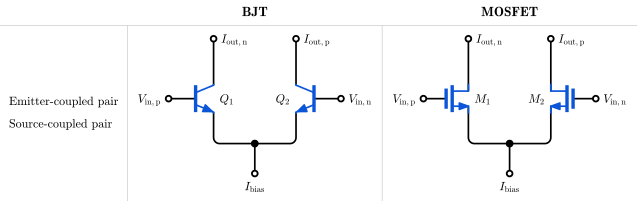

In [3]:
# HIDE/SHOW
show(C.differential_pair)

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 24**

| | BJT |
|---|---|
| **Problem** | In a bipolar differential pair with tail current $I_{EE}$, what differential input $V_{in1}-V_{in2}$ steers $98\%$ of the tail current into one transistor, leaving $2\%$ in the other? |
| **Given** | $I_{C1}$ $=I_{EE}/(1+\exp[-(V_{in1}-V_{in2})/V_T])$, $I_{C1}=0.02I_{EE}$ |
| **Answer 1** | **Collector current law.** $I_{C1}$ $=\dfrac{I_{EE}}{1+\exp\!\big(-\frac{V_{in1}-V_{in2}}{V_T}\big)}$ (from $I_{C1}+I_{C2}=I_{EE}$ and equal $I_S$). |
| **Answer 2** | **Requirement.** $I_{C1}=0.02I_{EE}$, so $1+e^{-V_d/V_T}=50$ and $e^{-V_d/V_T}=49$. |
| **Answer 3** | **Solve.** $V_d=-V_T\ln49=-3.89V_T$ (the published solution neglects the 1 against $e^{-V_d/V_T}$ and writes $-V_T\ln50=-3.91V_T$). |
| **Answer 4** | **Number.** With $V_T=26\,\mathrm{mV}$: $V_d=-101\,\mathrm{mV}$. |
| **Answer 5** | **Independence.** $I_{EE}$ and $I_S$ cancel, so the result is the same for every tail current and device size; about $4V_T$ switches the pair. |
| **Result** | $V_{in1}-V_{in2}$ $\approx-3.9V_T$ $\approx-0.1\,\mathrm{V}$ (i.e. $\lvert V_d\rvert\approx4V_T$) |

**Problem 25**

| | BJT |
|---|---|
| **Problem** | In an npn differential pair with tail current $I$ (and $\alpha\approx1$), the collector currents follow $i_{E1}$ $=\dfrac{I}{1+e^{(v_{B2}-v_{B1})/V_T}}$. Find the differential input $v_{B1}-v_{B2}$ that sends $99\%$ of $I$ through $Q_1$. Use $V_T=25\,\mathrm{mV}$. |
| **Given** | $i_{E1}=0.99\,I$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Use the split.** $i_{E1}+i_{E2}=I$ gives $i_{E1}$ $=\dfrac{I}{1+e^{(v_{B2}-v_{B1})/V_T}}$. |
| **Answer 2** | **Set 99 %.** $0.99$ $=\dfrac1{1+e^{-v_{id}/V_T}}\Rightarrow e^{-v_{id}/V_T}$ $=\dfrac1{0.99}-1$ $=\dfrac1{99}$. |
| **Answer 3** | **Solve.** $v_{id}$ $=v_{B1}-v_{B2}$ $=V_T\ln99$ $=25\times4.595$ $=114.9\,\mathrm{mV}$ $\approx115\,\mathrm{mV}$. |
| **Answer 4** | **Comment.** Beyond about $\pm4V_T=\pm100\,\mathrm{mV}$ the pair is essentially fully switched. |
| **Result** | $v_{id}\approx115\,\mathrm{mV}$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 20**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair with tail current $I=0.4\,\mathrm{mA}$ and $k_n^\prime=0.2\,\mathrm{mA/V^2}$ is to be designed for several overdrive voltages $V_{OV}$ (each transistor carries $I/2$). For each $V_{OV}$ find $W/L$, $g_m$, and the differential input $v_{id}$ that produces a current imbalance such that $\left(\dfrac{v_{id}/2}{V_{OV}}\right)^2$ $=0.1$. Give the general expressions and a table. |
| **Given** | $I=0.4\,\mathrm{mA}$, $k_n^\prime=0.2\,\mathrm{mA/V^2}$, $\left(\dfrac{v_{id}/2}{V_{OV}}\right)^2$ $=0.1$ |
| **Answer 1** | **Aspect ratio.** $\dfrac I2$ $=\dfrac12k_n^\prime\dfrac WLV_{OV}^2\Rightarrow\dfrac WL$ $=\dfrac{I}{k_n^\prime V_{OV}^2}$ $=\dfrac{2}{V_{OV}^2}$ ($V_{OV}$ in volts). |
| **Answer 2** | **Transconductance.** $g_m$ $=\dfrac{2(I/2)}{V_{OV}}$ $=\dfrac I{V_{OV}}$ $=\dfrac{0.4}{V_{OV}}\,\mathrm{mA/V}$. |
| **Answer 3** | **Input difference.** $\dfrac{v_{id}/2}{V_{OV}}$ $=\sqrt{0.1}\Rightarrow v_{id}$ $=2\sqrt{0.1}\,V_{OV}$ $=0.632\,V_{OV}$. |
| **Answer 4** | **Table.** $V_{OV}=0.1\,\mathrm{V}$: $W/L=200$, $g_m=4\,\mathrm{mA/V}$, $v_{id}=63.2\,\mathrm{mV}$. $V_{OV}=0.2\,\mathrm{V}$: $W/L=50$, $g_m=2\,\mathrm{mA/V}$, $v_{id}=126\,\mathrm{mV}$. $V_{OV}=0.3\,\mathrm{V}$: $W/L=22.2$, $g_m=1.33\,\mathrm{mA/V}$, $v_{id}=190\,\mathrm{mV}$. |
| **Result** | $W/L=2/V_{OV}^2$, $g_m=0.4/V_{OV}\,\mathrm{mA/V}$, $v_{id}=0.632\,V_{OV}$ |

**Problem 21**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair with $k_n^\prime=0.2\,\mathrm{mA/V^2}$ and tail current $I=0.4\,\mathrm{mA}$ must handle a differential input of up to $\lvert v_{id}\rvert_{max}$ $=0.22\,\mathrm{V}$ at the same level of linearity as Problem 20 (there $\lvert v_{id}\rvert_{max}$ $=0.632\,V_{OV}$). Find $V_{OV}$, $W/L$ and $g_m$. |
| **Given** | $k_n^\prime=0.2\,\mathrm{mA/V^2}$, $I=0.4\,\mathrm{mA}$, $\lvert v_{id}\rvert_{max}$ $=0.22\,\mathrm{V}$, $\lvert v_{id}\rvert_{max}/V_{OV}$ $=0.632$ |
| **Answer 1** | **Overdrive.** $V_{OV}$ $=\dfrac{0.22}{0.632}$ $=0.348\,\mathrm{V}$; choose $V_{OV}=0.35\,\mathrm{V}$. |
| **Answer 2** | **Aspect ratio.** $I_D$ $=0.2\,\mathrm{mA}$ $=\tfrac12\times0.2\times\dfrac WL\times0.35^2\Rightarrow\dfrac WL$ $=16.3$. |
| **Answer 3** | **Transconductance.** $g_m$ $=\dfrac{2I_D}{V_{OV}}$ $=\dfrac{2\times0.2}{0.35}$ $=1.14\,\mathrm{mA/V}$. |
| **Result** | $V_{OV}=0.35\,\mathrm{V}$, $W/L=16.3$, $g_m=1.14\,\mathrm{mA/V}$ |
````
`````

### Other Circuits

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 26**

| | BJT |
|---|---|
| **Problem** | Two identical common-emitter stages (npn transistors $Q_1,Q_2$ with equal collector resistors $R_{C1}=R_{C2}=R_C$ to $V_{CC}$) are driven by opposite inputs $+v_{in}$ and $-v_{in}$. The output is taken between the two collectors X and Y. Find the dc common-mode level of the outputs and say how supply ripple enters. |
| **Given** | $R_{C1}=R_{C2}=R_C$; both transistors carry bias current $I_C$ |
| **Answer 1** | **Bias condition.** With no signal both stages are identical, so $V_X=V_Y$. |
| **Answer 2** | **Voltage across each load.** Each load resistor drops $R_CI_C$. |
| **Answer 3** | **Collector voltage.** $V_X=V_Y=V_{CC}-R_CI_C$. |
| **Answer 4** | **Common-mode level.** $V_{CM}$ $=\dfrac{V_X+V_Y}{2}$ $=V_{CC}-R_CI_C$. |
| **Answer 5** | **Supply ripple.** A ripple $v_r$ on $V_{CC}$ moves both $V_X$ and $V_Y$ by $v_r$, so it changes $V_{CM}$ but cancels in $V_X-V_Y$. |
| **Result** | $V_{CM}=V_{CC}-R_CI_C$ (ripple affects $V_{CM}$ only, not the differential output) |

**Problem 27**

| | BJT |
|---|---|
| **Problem** | A pnp differential pair has its emitters joined and connected through a $1\,\mathrm{k}\Omega$ resistor to $+5\,\mathrm{V}$. Each collector has a $1\,\mathrm{k}\Omega$ resistor to $-5\,\mathrm{V}$. The base of $Q_1$ is at $+0.5\,\mathrm{V}$ and the base of $Q_2$ is grounded. Assume $\lvert V_{BE}\rvert$ $=0.7\,\mathrm{V}$ when conducting and $\alpha\approx1$. Find which transistor conducts, and the emitter voltage and the collector currents and voltages. |
| **Given** | $V_{CC}=+5\,\mathrm{V}$ (emitter resistor $1\,\mathrm{k}\Omega$), collector resistors $1\,\mathrm{k}\Omega$ to $-5\,\mathrm{V}$, $v_{B1}=+0.5\,\mathrm{V}$, $v_{B2}=0$, $V_{EB(on)}=0.7\,\mathrm{V}$, $\alpha\approx1$ |
| **Answer 1** | **Which one conducts.** A pnp conducts when its emitter is about $0.7\,\mathrm{V}$ above its base. The more negative base wins: $Q_2$ (base at $0$) is on, so $Q_1$ (base at $+0.5\,\mathrm{V}$) is expected to be off. |
| **Answer 2** | **Emitter voltage.** Assume $Q_2$ on: $v_E$ $=v_{B2}+V_{EB}$ $=0+0.7$ $=+0.7\,\mathrm{V}$. |
| **Answer 3** | **Check Q1.** $V_{EB1}=0.7-0.5=0.2\,\mathrm{V}$, far below $0.5\ldots0.6\,\mathrm{V}$, so $Q_1$ is off: $i_{C1}=0$, $v_{C1}=-5\,\mathrm{V}$. |
| **Answer 4** | **Emitter current.** $I_E$ $=\dfrac{5-0.7}{1\,\mathrm{k}\Omega}$ $=4.3\,\mathrm{mA}$, all in $Q_2$. |
| **Answer 5** | **Collector of Q2.** $I_{C2}\simeq I_E=4.3\,\mathrm{mA}$ ($\alpha\approx1$), so $v_{C2}$ $=-5+4.3\times1$ $=-0.7\,\mathrm{V}$. |
| **Answer 6** | **Check the region.** $v_{C2}=-0.7\,\mathrm{V}$ is below $v_{B2}=0$ (collector-base junction reverse biased), so $Q_2$ is in the active mode. |
| **Result** | $Q_2$ on, $Q_1$ off; $v_E=+0.7\,\mathrm{V}$, $I_E\approx I_{C2}=4.3\,\mathrm{mA}$, $v_{C2}=-0.7\,\mathrm{V}$, $i_{C1}=0$, $v_{C1}=-5\,\mathrm{V}$ |

**Problem 28**

| | BJT |
|---|---|
| **Problem** | A pnp differential pair has an emitter resistor of $1\,\mathrm{k}\Omega$ from the joined emitters to $+5\,\mathrm{V}$, and $1\,\mathrm{k}\Omega$ collector resistors from the collectors to $-5\,\mathrm{V}$. The base of $Q_1$ is at $-0.3\,\mathrm{V}$ and the base of $Q_2$ at ground. Take $\lvert V_{BE}\rvert$ $=0.7\,\mathrm{V}$ for a conducting device and $\alpha\approx1$. Find the dc voltages and currents. |
| **Given** | $+5\,\mathrm{V}$, $-5\,\mathrm{V}$, $R_E=1\,\mathrm{k}\Omega$, $R_C=1\,\mathrm{k}\Omega$ each, $v_{B1}=-0.3\,\mathrm{V}$, $v_{B2}=0$, $V_{EB}=0.7\,\mathrm{V}$ |
| **Answer 1** | **Which conducts.** $Q_1$ has the lower base, so it takes the current; $Q_2$ is off. |
| **Answer 2** | **Emitter voltage.** $V_E$ $=v_{B1}+V_{EB}$ $=-0.3+0.7$ $=+0.4\,\mathrm{V}$. |
| **Answer 3** | **Check $Q_2$.** $V_{EB2}=0.4-0=0.4\,\mathrm{V}$, well below $0.7\,\mathrm{V}$, so $Q_2$ is off. |
| **Answer 4** | **Emitter current.** $I_E$ $=\dfrac{5-0.4}{1\,\mathrm{k}\Omega}$ $=4.6\,\mathrm{mA}$. |
| **Answer 5** | **Collector voltages.** $I_{C1}\approx4.6\,\mathrm{mA}$, $V_{C1}$ $=-5+4.6\times1$ $=-0.4\,\mathrm{V}$; $I_{C2}=0$, $V_{C2}=-5\,\mathrm{V}$. |
| **Answer 6** | **Region check.** $V_{C1}=-0.4\,\mathrm{V}$ is below $v_{B1}=-0.3\,\mathrm{V}$: the collector junction is reverse biased, so $Q_1$ is active. |
| **Result** | $V_E=+0.4\,\mathrm{V}$, $I_E=I_{C1}=4.6\,\mathrm{mA}$, $V_{C1}=-0.4\,\mathrm{V}$, $V_{C2}=-5\,\mathrm{V}$ ($Q_2$ off) |

**Problem 29**

| | BJT |
|---|---|
| **Problem** | An npn pair with $IR_C=5\,\mathrm{V}$ ($\alpha\approx1$, $V_T=25\,\mathrm{mV}$): tabulate the differential output $v_o=v_{C2}-v_{C1}$ and the gain $v_o/v_{id}$ for $v_{id}=2$ to $40\,\mathrm{mV}$, and sketch the transfer curve. |
| **Given** | $IR_C=5\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Output.** $v_o=R_C(i_{C1}-i_{C2})$. |
| **Answer 2** | **Large-signal law.** $v_o$ $=IR_C\left[\dfrac1{1+e^{-v_{id}/V_T}}-\dfrac1{1+e^{v_{id}/V_T}}\right]$ $=5\tanh\dfrac{v_{id}}{2V_T}$. |
| **Answer 3** | **Values of $v_o$.** $v_{id}$ $=2,5,10,15,20,25,30,35,40\,\mathrm{mV}$: $v_o$ $=0.200,\ 0.498,\ 0.987,\ 1.457,\ 1.900,\ 2.311,\ 2.685,\ 3.022,\ 3.320\,\mathrm{V}$. |
| **Answer 4** | **Gain.** $v_o/v_{id}$ $=99.9,\ 99.7,\ 98.7,\ 97.1,\ 95.0,\ 92.4,\ 89.5,\ 86.3,\ 83.0\,\mathrm{V/V}$. |
| **Answer 5** | **Sketch.** The curve is an odd tanh, nearly linear with slope 100 V/V up to about $10\,\mathrm{mV}$ and saturating toward $\pm5\,\mathrm{V}$; the gain is only 5 % below its ideal value of 100 at $20\,\mathrm{mV}$. |
| **Result** | Gain $=98.7$ at $10\,\mathrm{mV}$ and $95.0$ at $20\,\mathrm{mV}$ (ideal 100); $v_o$ values as tabulated |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 22**

| | MOSFET |
|---|---|
| **Problem** | The differential characteristic of an NMOS pair (output difference versus input difference) saturates once one transistor turns off, at $\lvert\Delta V_{in}\rvert$ $=\Delta V_{in,max}$. Describe how this characteristic changes if (a) the tail current $I_{SS}$ is doubled, (b) the aspect ratio $W/L$ is doubled. |
| **Given** | $\Delta V_{in,max}$ $=\sqrt{\dfrac{2I_{SS}}{\mu_nC_{ox}W/L}}$, $\;g_m$ $=\sqrt{\mu_nC_{ox}\frac{W}{L}I_{SS}}$, output swing $\pm I_{SS}R_D$ |
| **Answer 1** | **Quantities that define the curve.** The characteristic is linear near zero with slope set by $g_m$ (times $R_D$), then flat at $\pm I_{SS}R_D$ for $\lvert\Delta V_{in}\rvert\ge\Delta V_{in,max}$ $=\sqrt{2I_{SS}/(\mu_nC_{ox}W/L)}$, where one device carries the whole $I_{SS}$. |
| **Answer 2** | **(a) Horizontal extent.** Doubling $I_{SS}$ multiplies $\Delta V_{in,max}$ by $\sqrt2$: the curve widens. |
| **Answer 3** | **(a) Vertical extent and slope.** The saturated level $I_{SS}R_D$ doubles, so the curve also grows vertically; $g_m$ grows by $\sqrt2$, so the central slope is $\sqrt2$ larger. |
| **Answer 4** | **(b) Horizontal extent.** Doubling $W/L$ divides $\Delta V_{in,max}$ by $\sqrt2$: the curve contracts horizontally. |
| **Answer 5** | **(b) Vertical extent and slope.** $I_{SS}$ is unchanged, so the saturated level is unchanged; the same height reached in a narrower input range means a larger slope, $g_m$ up by $\sqrt2$. |
| **Answer 6** | **Numerical check.** With $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $W/L=50$, $I_{SS}=1\,\mathrm{mA}$: $\Delta V_{in,max}$ $=0.632\,\mathrm{V}$, $g_m=2.24\,\mathrm{mS}$. Doubling $I_{SS}$: $0.894\,\mathrm{V}$, $3.16\,\mathrm{mS}$. Doubling $W/L$: $0.447\,\mathrm{V}$, $3.16\,\mathrm{mS}$. At each $\Delta V_{in,max}$ the exact law gives $I_{D1}-I_{D2}=I_{SS}$. |
| **Result** | (a) $\Delta V_{in,max}\times\sqrt2$, output swing $\times2$, slope $\times\sqrt2$; (b) $\Delta V_{in,max}/\sqrt2$, swing unchanged, slope $\times\sqrt2$ |

**Problem 23**

| | MOSFET |
|---|---|
| **Problem** | A hypothetical transistor obeys $I_D=\gamma(V_{GS}-V_{TH})^3$. Two such devices $T_1$, $T_2$ form a differential pair with drain resistors $R_D$ to $V_{DD}$ and tail current $I_{SS}$. (a) What does this circuit share with the usual MOS pair? (b) Find the equilibrium overdrive of $T_1$, $T_2$. (c) At what $V_{in1}-V_{in2}$ does one device turn off? |
| **Given** | $I_D=\gamma(V_{GS}-V_{TH})^3$, tail $I_{SS}$, loads $R_D$, symmetric |
| **Answer 1** | **(a) Similarities.** $I_{D1}+I_{D2}=I_{SS}$ is fixed, so a common-mode input does not change the currents (CM rejection); equal inputs give $I_{D1}=I_{D2}=I_{SS}/2$ and zero differential output; a large difference steers all of $I_{SS}$ to one side, so $V_{out}$ saturates at $\pm R_DI_{SS}$; for small differential inputs $P$ is a virtual ground and $A_v=-g_mR_D$ |
| **Answer 2** | **(a) Transconductance.** Here $g_m$ $=3\gamma(V_{GS}-V_{TH})^2$ $=3I_D/(V_{GS}-V_{TH})$ instead of $2I_D/(V_{GS}-V_{TH})$ |
| **Answer 3** | **(b) Equilibrium.** $\dfrac{I_{SS}}2$ $=\gamma(V_{GS}-V_{TH})^3_{equil}\Rightarrow(V_{GS}-V_{TH})_{equil}$ $=\left(\dfrac{I_{SS}}{2\gamma}\right)^{1/3}$ |
| **Answer 4** | **(c) Edge of conduction.** If $T_1$ just turns off, $V_{GS1}=V_{TH}$ and $T_2$ carries $I_{SS}$: $V_{GS2}$ $=V_{TH}+(I_{SS}/\gamma)^{1/3}$ |
| **Answer 5** | **(c) Input difference.** $V_{in1}-V_{in2}=V_{GS1}-V_{GS2}$, so $\lvert V_{in1}-V_{in2}\rvert_{\max}$ $=\left(\dfrac{I_{SS}}{\gamma}\right)^{1/3}$ $=2^{1/3}(V_{GS}-V_{TH})_{equil}$ $=1.26(V_{GS}-V_{TH})_{equil}$ (compare $\sqrt2$ for the square law) |
| **Answer 6** | **Numbers.** $\gamma=1\,\mathrm{mA/V^3}$, $I_{SS}=1\,\mathrm{mA}$: overdrive $0.794\,\mathrm{V}$, and the pair switches completely at $\lvert\Delta V\rvert$ $=1.00\,\mathrm{V}$, confirmed by solving the pair equations directly |
| **Result** | (b) $(V_{GS}-V_{TH})_{equil}$ $=(I_{SS}/2\gamma)^{1/3}$; (c) $\lvert V_{in1}-V_{in2}\rvert$ $=(I_{SS}/\gamma)^{1/3}$ $=2^{1/3}(V_{GS}-V_{TH})_{equil}$ |

**Problem 24**

| | MOSFET |
|---|---|
| **Problem** | A MOS differential pair with drain resistors $R_D$ and an ideal tail current $I_{SS}$ has the large-signal characteristics: the drain currents $I_{D1}$, $I_{D2}$, their difference $I_{D1}-I_{D2}$, and the differential output $V_{out1}-V_{out2}$, all plotted against $\Delta V_{in}=V_{in1}-V_{in2}$. Explain how these curves change if (a) the gate-oxide thickness is doubled, (b) the threshold voltage is halved, (c) both $I_{SS}$ and $W/L$ are halved. |
| **Given** | Square-law devices, $\lambda=0$; reference values for the numeric check: $\mu_nC_{ox}W/L=1\,\mathrm{mA/V^2}$, $I_{SS}=1\,\mathrm{mA}$, $R_D=1\,\mathrm{k}\Omega$ |
| **Answer 1** | **What sets the curves.** All current is steered to one side at $\Delta V_{in,max}$ $=\sqrt{\dfrac{2I_{SS}}{\mu_nC_{ox}W/L}}$; the plateaus are $\pm I_{SS}$ for the current difference and $\pm R_DI_{SS}$ for the output; the slope at the origin is $G_m$ $=g_m$ $=\sqrt{\mu_nC_{ox}(W/L)I_{SS}}$, so the small-signal gain is $g_mR_D$ |
| **Answer 2** | **Reference numbers.** With the reference values: $\Delta V_{in,max}=1.41\,\mathrm{V}$, plateau $R_DI_{SS}=1\,\mathrm{V}$, slope $g_mR_D=1.00$ |
| **Answer 3** | **(a) Oxide twice as thick.** $C_{ox}=\epsilon_{ox}/t_{ox}$ halves, so $\mu_nC_{ox}W/L$ halves: $\Delta V_{in,max}$ grows by $\sqrt2$ (to $2.00\,\mathrm{V}$), the plateaus $\pm I_{SS}$ and $\pm R_DI_{SS}$ stay, the slope falls by $\sqrt2$ (to $0.707$). The curves stretch horizontally and become flatter: a larger linear input range, less gain |
| **Answer 4** | **(b) Threshold halved.** $V_{TH}$ appears in neither $\Delta V_{in,max}$, the plateaus nor $g_m$: the curves versus $\Delta V_{in}$ are unchanged. Only absolute gate-source voltages move: each $V_{GS}$ falls by $V_{TH}/2$, so the tail node sits higher and the allowed input common-mode level can go lower |
| **Answer 5** | **(c) $I_{SS}$ and $W/L$ halved.** $I_{SS}/(W/L)$ is unchanged, so $\Delta V_{in,max}$ stays $1.41\,\mathrm{V}$ (the equilibrium overdrive is the same); the plateaus halve to $\pm I_{SS}/2$ and $\pm R_DI_{SS}/2=\pm0.5\,\mathrm{V}$; the slope $\sqrt{\mu_nC_{ox}(W/L)I_{SS}}R_D$ halves to $0.500$. The curves shrink vertically by 2 with the same width |
| **Answer 6** | **Check by the large-signal law.** Differentiating $I_{D1}-I_{D2}$ $=\tfrac12\mu_nC_{ox}\tfrac WL\Delta V_{in}\sqrt{\tfrac{4I_{SS}}{\mu_nC_{ox}W/L}-\Delta V_{in}^2}$ at $\Delta V_{in}=0$ gives the same slope $1.00$ for the reference case |
| **Result** | (a) $\Delta V_{in,max}\times\sqrt2$, same plateaus, slope $\div\sqrt2$; (b) characteristics unchanged (only the dc gate-source voltages drop by $V_{TH}/2$); (c) same $\Delta V_{in,max}$, plateaus and slope halved |

**Problem 25**

| | MOSFET |
|---|---|
| **Problem** | For the MOS differential pair (drain resistors $R_D$, ideal tail $I_{SS}$), the carrier mobility falls as the temperature rises. Explain how the large-signal characteristics (drain currents, current difference and differential output versus $V_{in1}-V_{in2}$) change as the temperature goes up. |
| **Given** | $I_{SS}$ and $R_D$ held constant; reference values for the numeric check: $\mu_nC_{ox}W/L=1\,\mathrm{mA/V^2}$, $I_{SS}=1\,\mathrm{mA}$, $R_D=1\,\mathrm{k}\Omega$ |
| **Answer 1** | **Quantities that depend on mobility.** $\Delta V_{in,max}$ $=\sqrt{2I_{SS}/(\mu_nC_{ox}W/L)}\propto\mu_n^{-1/2}$; plateaus $\pm I_{SS}$ and $\pm R_DI_{SS}$ do not involve $\mu_n$; slope $g_mR_D$ $=\sqrt{\mu_nC_{ox}(W/L)I_{SS}}\,R_D\propto\mu_n^{1/2}$ |
| **Answer 2** | **Mobility down by 20 %.** $\Delta V_{in,max}$: $1.41\to1.58\,\mathrm{V}$; plateau stays $1\,\mathrm{V}$; slope $1.00\to0.894$ |
| **Answer 3** | **Mobility down by 40 %.** $\Delta V_{in,max}\to1.83\,\mathrm{V}$; slope $\to0.775$ |
| **Answer 4** | **Interpretation.** As temperature rises the characteristic widens horizontally (each device needs a larger overdrive to carry $I_{SS}/2$) with the same height, so the small-signal gain falls while the linear input range grows |
| **Result** | Hotter: $\Delta V_{in,max}\propto1/\sqrt{\mu_n}$ grows, plateaus $\pm R_DI_{SS}$ unchanged, slope (gain) $\propto\sqrt{\mu_n}$ falls: the curves stretch horizontally and flatten |

**Problem 26**

| | MOSFET |
|---|---|
| **Problem** | Two NMOS transistors $Q_1$ and $Q_2$ have grounded gates, drain resistors of $20\,\mathrm{k}\Omega$ to $+2.5\,\mathrm{V}$, and sources joined at node $V_3$ to a $200\,\mu\mathrm{A}$ current source to $-2.5\,\mathrm{V}$. They have $\mu_nC_{ox}=125\,\mu\mathrm{A/V^2}$, $V_t=0.7\,\mathrm{V}$, and $W/L=20$. (a) Find the drain voltages $V_1$, $V_2$ and the source voltage $V_3$ for matched devices. (b) Now $(W/L)_1=1.5(W/L)_2$ with $(W/L)_1=20$: find $V_1$, $V_2$, $V_3$. |
| **Given** | $R_D=20\,\mathrm{k}\Omega$, $I=200\,\mu\mathrm{A}$, $\mu_nC_{ox}=125\,\mu\mathrm{A/V^2}$, $V_t=0.7\,\mathrm{V}$, $(W/L)=20$, supplies $\pm2.5\,\mathrm{V}$ |
| **Answer 1** | **(a) Current split.** Matched devices with equal $V_{GS}$ share the $200\,\mu\mathrm{A}$ equally: $I_{D1}=I_{D2}=100\,\mu\mathrm{A}$. |
| **Answer 2** | **(a) Drain voltages.** $V_1$ $=V_2$ $=2.5-0.1\,\mathrm{mA}\times20\,\mathrm{k}\Omega$ $=0.5\,\mathrm{V}$. |
| **Answer 3** | **(a) Gate-source voltage.** $100$ $=\tfrac12(125)(20)(V_{GS}-0.7)^2\Rightarrow V_{GS}-0.7$ $=0.283\,\mathrm{V}$, $V_{GS}=0.983\,\mathrm{V}$. |
| **Answer 4** | **(a) Source node.** $V_3=0-V_{GS}=-0.983\,\mathrm{V}$. Saturation: $V_{DS}$ $=0.5+0.983$ $=1.48\,\mathrm{V}>0.283\,\mathrm{V}$. |
| **Answer 5** | **(b) Current split.** Equal $V_{GS}$ and $(W/L)_1=1.5(W/L)_2$ give $I_{D1}=1.5I_{D2}$; with $I_{D1}+I_{D2}=200\,\mu\mathrm{A}$: $I_{D1}=120\,\mu\mathrm{A}$, $I_{D2}=80\,\mu\mathrm{A}$. |
| **Answer 6** | **(b) Drain voltages.** $V_1$ $=2.5-0.12\times20$ $=0.1\,\mathrm{V}$, $V_2$ $=2.5-0.08\times20$ $=0.9\,\mathrm{V}$. |
| **Answer 7** | **(b) Source node.** $120$ $=\tfrac12(125)(20)(V_{GS}-0.7)^2\Rightarrow V_{GS}$ $=0.7+0.310$ $=1.01\,\mathrm{V}$, so $V_3=-1.01\,\mathrm{V}$. $Q_1$ is saturated: $V_{DS1}$ $=0.1+1.01$ $=1.11\,\mathrm{V}>0.31\,\mathrm{V}$. |
| **Result** | (a) $V_1=V_2=0.5\,\mathrm{V}$, $V_3=-0.983\,\mathrm{V}$; (b) $V_1=0.1\,\mathrm{V}$, $V_2=0.9\,\mathrm{V}$, $V_3=-1.01\,\mathrm{V}$ |

**Problem 27**

| | MOSFET |
|---|---|
| **Problem** | A PMOS differential pair has its sources joined to a tail current source $I=0.2\,\mathrm{mA}$ from $+0.9\,\mathrm{V}$; each drain has $R_D=4\,\mathrm{k}\Omega$ to $V_{SS}=-0.9\,\mathrm{V}$. The transistors have $k_p^\prime(W/L)=5\,\mathrm{mA/V^2}$ and $\lvert V_{tp}\rvert$ $=0.4\,\mathrm{V}$; both gates are at $0\,\mathrm{V}$. (a) Find $\lvert V_{OV}\rvert$, $V_{SG}$, the source and drain voltages and check saturation. (b) The tail source needs $0.2\,\mathrm{V}$: find the input common-mode range. |
| **Given** | $V_{DD}=+0.9\,\mathrm{V}$, $V_{SS}=-0.9\,\mathrm{V}$, $I=0.2\,\mathrm{mA}$, $R_D=4\,\mathrm{k}\Omega$, $k_p^\prime W/L=5\,\mathrm{mA/V^2}$, $\lvert V_{tp}\rvert$ $=0.4\,\mathrm{V}$, $V_{CS,min}=0.2\,\mathrm{V}$ |
| **Answer 1** | **Currents.** $I_{D1}=I_{D2}=0.1\,\mathrm{mA}$. |
| **Answer 2** | **Overdrive.** $0.1$ $=\dfrac12\times5\times\lvert V_{OV}\rvert^2\Rightarrow\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$; $V_{SG}$ $=\lvert V_{tp}\rvert+\lvert V_{OV}\rvert$ $=0.6\,\mathrm{V}$. |
| **Answer 3** | **Voltages.** $V_S=V_G+V_{SG}=+0.6\,\mathrm{V}$; $V_{D1}$ $=V_{D2}$ $=V_{SS}+I_DR_D$ $=-0.9+0.1\times4$ $=-0.5\,\mathrm{V}$. |
| **Answer 4** | **Check saturation.** $V_{SD}$ $=0.6-(-0.5)$ $=1.1\,\mathrm{V}>\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$: saturated. |
| **Answer 5** | **(b) Upper limit of $V_{CM}$.** The source needs $0.2\,\mathrm{V}$: $V_{S}\le0.9-0.2=0.7\,\mathrm{V}$, so $V_{CM,max}$ $=0.9-0.2-V_{SG}$ $=+0.1\,\mathrm{V}$. |
| **Answer 6** | **(b) Lower limit of $V_{CM}$.** Saturation needs $V_{DG}\le\lvert V_{tp}\rvert$: $V_{CM,min}$ $=V_D-\lvert V_{tp}\rvert$ $=-0.5-0.4$ $=-0.9\,\mathrm{V}$. |
| **Answer 7** | **Range.** $-0.9\,\mathrm{V}\le V_{ICM}\le+0.1\,\mathrm{V}$. |
| **Result** | $\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$, $V_{SG}=0.6\,\mathrm{V}$, $V_D=-0.5\,\mathrm{V}$ (saturated); $-0.9\,\mathrm{V}\le V_{ICM}\le+0.1\,\mathrm{V}$ |

**Problem 28**

| | MOSFET |
|---|---|
| **Problem** | In the NMOS differential amplifier the tail current $I=0.4\,\mathrm{mA}$ is the drain current of $Q_3$, which is mirrored from the reference transistor $Q_4$ through a resistor $R$ connected from $V_{DD}=+0.9\,\mathrm{V}$ ($V_{SS}=-0.9\,\mathrm{V}$); $Q_3$ carries four times the current of $Q_4$. With $v_{G1}=v_{G2}=0$ the drains must be at $+0.1\,\mathrm{V}$. All transistors have $V_{OV}=0.15\,\mathrm{V}$, $\mu_nC_{ox}=0.4\,\mathrm{mA/V^2}$ and $V_{tn}=0.4\,\mathrm{V}$. Find $R_D$, $W/L$ of $Q_1,Q_2,Q_3,Q_4$, the resistor $R$, and the input common-mode range. |
| **Given** | $V_{DD}=0.9\,\mathrm{V}$, $V_{SS}=-0.9\,\mathrm{V}$, $I=0.4\,\mathrm{mA}$, $V_D=0.1\,\mathrm{V}$, $V_{OV}=0.15\,\mathrm{V}$, $\mu_nC_{ox}=0.4\,\mathrm{mA/V^2}$, $V_{tn}=0.4\,\mathrm{V}$, $I_{D3}=4I_{D4}$ |
| **Answer 1** | **Drain resistor.** $I_{D1}=I_{D2}=0.2\,\mathrm{mA}$; $V_{DD}-I_DR_D$ $=0.1\Rightarrow R_D$ $=\dfrac{0.9-0.1}{0.2}$ $=4\,\mathrm{k}\Omega$. |
| **Answer 2** | **$Q_1,Q_2$.** $0.2$ $=\tfrac12\times0.4\times(W/L)_{1,2}\times0.15^2\Rightarrow(W/L)_{1,2}$ $=44.4$. |
| **Answer 3** | **$Q_3$.** $0.4$ $=\tfrac12\times0.4\times(W/L)_3\times0.15^2\Rightarrow(W/L)_3$ $=88.9$. |
| **Answer 4** | **$Q_4$.** $I_{D4}=I_{D3}/4=0.1\,\mathrm{mA}$ at the same $V_{GS}$, so $(W/L)_4=\tfrac14(W/L)_3=22.2$. |
| **Answer 5** | **Resistor $R$.** $V_{GS4}$ $=V_{GS3}$ $=0.4+0.15$ $=0.55\,\mathrm{V}$: $R$ $=\dfrac{V_{DD}-V_{SS}-V_{GS4}}{I_{D4}}$ $=\dfrac{0.9+0.9-0.55}{0.1}$ $=12.5\,\mathrm{k}\Omega$. |
| **Answer 6** | **Lower CM limit.** $Q_3$ must stay saturated ($V_{DS3}\ge V_{OV}$): $V_{ICM,min}$ $=V_{SS}+V_{OV3}+V_{GS1,2}$ $=-0.9+0.15+0.55$ $=-0.2\,\mathrm{V}$. |
| **Answer 7** | **Upper CM limit.** $Q_1,Q_2$ saturated: $V_{ICM,max}$ $=V_D+V_{tn}$ $=0.1+0.4$ $=+0.5\,\mathrm{V}$. |
| **Result** | $R_D=4\,\mathrm{k}\Omega$; $(W/L)_{1,2}=44.4$, $(W/L)_3=88.9$, $(W/L)_4=22.2$; $R=12.5\,\mathrm{k}\Omega$; $-0.2\,\mathrm{V}\le V_{ICM}\le+0.5\,\mathrm{V}$ |

**Problem 29**

| | MOSFET |
|---|---|
| **Problem** | The PMOS pair ($I=0.2\,\mathrm{mA}$, $R_D=4\,\mathrm{k}\Omega$ to $-0.9\,\mathrm{V}$, $k_p^\prime W/L=5\,\mathrm{mA/V^2}$, $\lvert V_{tp}\rvert$ $=0.4\,\mathrm{V}$) has $v_{G1}=v_{id}$, $v_{G2}=0$. Find the range of $v_{id}$ over which the current is steered between the two sides, and $v_{D1}$, $v_{D2}$, $v_O=v_{D2}-v_{D1}$ at both ends. |
| **Given** | $I=0.2\,\mathrm{mA}$, $R_D=4\,\mathrm{k}\Omega$, $V_{SS}=-0.9\,\mathrm{V}$, $k_p^\prime W/L=5\,\mathrm{mA/V^2}$, $\lvert V_{tp}\rvert$ $=0.4\,\mathrm{V}$ |
| **Answer 1** | **Overdrive.** At $v_{id}=0$: $0.1$ $=\tfrac12\times5\times\lvert V_{OV}\rvert^2\Rightarrow\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$. |
| **Answer 2** | **Range.** Complete steering occurs at $\pm\sqrt2\lvert V_{OV}\rvert$: $-0.283\,\mathrm{V}\le v_{id}\le+0.283\,\mathrm{V}$. |
| **Answer 3** | **End $v_{id}=-0.283\,\mathrm{V}$.** $Q_2$ just off: $v_S$ $=\lvert V_{tp}\rvert$ $=0.4\,\mathrm{V}$, $v_{SG1}$ $=0.4+0.283$ $=0.683\,\mathrm{V}$; $i_{D1}$ $=\tfrac12\times5\times(0.683-0.4)^2$ $=0.2\,\mathrm{mA}$ (all of $I$). $v_{D1}$ $=-0.9+0.2\times4$ $=-0.1\,\mathrm{V}$, $v_{D2}=-0.9\,\mathrm{V}$, $v_O=-0.8\,\mathrm{V}$. Saturation of $Q_1$: $v_{DG1}$ $=-0.1+0.283$ $=0.183\,\mathrm{V}<\lvert V_{tp}\rvert$. |
| **Answer 4** | **End $v_{id}=+0.283\,\mathrm{V}$.** $Q_1$ just off: $v_S=0.283+0.4=0.683\,\mathrm{V}$, $v_{SG2}=0.683\,\mathrm{V}$, $i_{D2}=0.2\,\mathrm{mA}$; $v_{D1}=-0.9\,\mathrm{V}$, $v_{D2}=-0.1\,\mathrm{V}$, $v_O=+0.8\,\mathrm{V}$. |
| **Result** | $-0.283\,\mathrm{V}\le v_{id}\le+0.283\,\mathrm{V}$; $v_O=-0.8\,\mathrm{V}$ and $+0.8\,\mathrm{V}$ at the two ends |

**Problem 30**

| | MOSFET |
|---|---|
| **Problem** | A MOS differential pair with tail current $I$ and overdrive voltage $V_{OV}$ (at $I/2$ per side) is driven by $v_{id}$. The large-signal law for the drain current is $i_{D1}$ $=\frac I2+\frac I2\frac{v_{id}}{V_{OV}}\sqrt{1-\frac14\left(\frac{v_{id}}{V_{OV}}\right)^2}$. Operation is limited to $\left(\frac{v_{id}/2}{V_{OV}}\right)^2\le k$ with $k<1$. Show that the largest change of $i_{D1}$ from $I/2$ is $\frac{I}{2}\cdot 2\sqrt{k(1-k)}$, and that the largest $v_{id}$ is $2\sqrt k\,V_{OV}$. Evaluate $v_{id\,max}/V_{OV}$ and $I_{max}/(I/2)$ for $k=0.01,\,0.1,\,0.2$. |
| **Given** | $k=0.01,\ 0.1,\ 0.2$; $i_{D1}-I/2$ given by the law above |
| **Answer 1** | **Define a variable.** Let $x=\dfrac{v_{id}/2}{V_{OV}}$. The law gives $i_{D1}-\dfrac I2=I\,x\sqrt{1-x^2}$. |
| **Answer 2** | **Apply the limit.** The restriction is $x^2\le k$, i.e. $x\le\sqrt k$. |
| **Answer 3** | **Maximum current change.** $x\sqrt{1-x^2}$ increases with $x$ for $x<1/\sqrt2$ ($k<0.5$), so the maximum is at $x=\sqrt k$: $I_{max}=I\sqrt k\sqrt{1-k}$. |
| **Answer 4** | **Normalise to $I/2$.** $\dfrac{I_{max}}{I/2}$ $=2\sqrt{k(1-k)}$. |
| **Answer 5** | **Maximum input.** $x=\sqrt k$ means $v_{id\,max}=2\sqrt k\,V_{OV}$. |
| **Answer 6** | **Numbers.** $k=0.01$: $v_{id\,max}/V_{OV}=0.2$, $I_{max}/(I/2)=0.199$. $k=0.1$: $0.632$, $0.600$. $k=0.2$: $0.894$, $0.800$. |
| **Result** | $I_{max}/(I/2)=2\sqrt{k(1-k)}$, $v_{id\,max}=2\sqrt k\,V_{OV}$; table: $(0.2,\,0.199)$, $(0.632,\,0.600)$, $(0.894,\,0.800)$ for $k=0.01,0.1,0.2$ |

**Problem 31**

| | MOSFET |
|---|---|
| **Problem** | A MOS differential pair biased at $I=200\,\mu\mathrm{A}$ switches all the current to one side when $v_{id}=0.3\,\mathrm{V}$. Find the overdrive voltage $V_{OV}$ of each transistor at balance. Then find the $V_{OV}$ and the bias current $I$ needed for full switching at $v_{id}=0.5\,\mathrm{V}$ with the same devices ($W/L$ unchanged). |
| **Given** | $I=200\,\mu\mathrm{A}$, $v_{id}(\text{full switching})$ $=0.3\,\mathrm{V}$, then $0.5\,\mathrm{V}$ |
| **Answer 1** | **Switching condition.** Full switching occurs at $v_{id}=\sqrt2\,V_{OV}$. |
| **Answer 2** | **First design.** $V_{OV}$ $=0.3/\sqrt2$ $=0.212\,\mathrm{V}$. |
| **Answer 3** | **New overdrive.** For $0.5\,\mathrm{V}$: $V_{OV}$ $=0.5/\sqrt2$ $=0.354\,\mathrm{V}$ (a factor $0.5/0.3$ larger). |
| **Answer 4** | **Scaling of current.** With fixed $W/L$, $I/2=\tfrac12k_n\tfrac WL V_{OV}^2$, so $I\propto V_{OV}^2$. |
| **Answer 5** | **New bias current.** $I$ $=200\,\mu\mathrm{A}\times(0.5/0.3)^2$ $=556\,\mu\mathrm{A}$. |
| **Result** | $V_{OV}=0.212\,\mathrm{V}$ initially; $V_{OV}=0.354\,\mathrm{V}$ and $I\approx556\,\mu\mathrm{A}$ for $v_{id}=0.5\,\mathrm{V}$ |

**Problem 32**

| | MOSFET |
|---|---|
| **Problem** | For a MOS differential pair the currents are $i_{D1,2}=\frac I2\pm\frac I2\Delta$ with $\Delta$ $=\frac{v_{id}}{V_{OV}}\sqrt{1-\frac14\left(\frac{v_{id}}{V_{OV}}\right)^2}$. (a) Find $v_{id}$ (in terms of $V_{OV}$) that makes $i_{D1}$ exceed $I/2$ by 10 percent. (b) Find $v_{id}/V_{OV}$ for which $i_{D1}/i_{D2}=m$, for $m=1,\ 1.1,\ 1.01,\ 2,\ 20$. |
| **Given** | $i_{D1}-I/2=0.1\,I/2$; ratio $m=i_{D1}/i_{D2}$ |
| **Answer 1** | **(a) Condition.** $\Delta=0.1$. |
| **Answer 2** | **(a) Small-$v_{id}$ solution.** The square-root factor is about 1, so $v_{id}\approx0.1\,V_{OV}$ (exact root $0.1001\,V_{OV}$). |
| **Answer 3** | **(b) Ratio to $\Delta$.** $m$ $=\dfrac{1+\Delta}{1-\Delta}\Rightarrow\Delta$ $=\dfrac{m-1}{m+1}$. |
| **Answer 4** | **(b) $m=1$.** $\Delta=0$, so $v_{id}=0$. |
| **Answer 5** | **(b) $m=2$.** $\Delta=1/3$. Squaring $u^2(1-u^2/4)=1/9$ with $u=v_{id}/V_{OV}$ gives a quadratic in $u^2$; $u=0.338$. |
| **Answer 6** | **(b) $m=1.1$ and $1.01$.** $\Delta=0.0476$ and $0.00498$, so $v_{id}\approx0.0476\,V_{OV}$ and $0.00498\,V_{OV}$ (small-signal $u\approx\Delta$). |
| **Answer 7** | **(b) $m=20$.** $\Delta=19/21=0.905$; solving gives $v_{id}=1.07\,V_{OV}$. |
| **Result** | (a) $v_{id}\approx0.1\,V_{OV}$; (b) $v_{id}/V_{OV}$ $=0,\ 0.0476,\ 0.00498,\ 0.338,\ 1.07$ for $m=1,1.1,1.01,2,20$ |

**Problem 33**

| | MOSFET |
|---|---|
| **Problem** | A MOS differential amplifier has an NMOS pair $Q_1,Q_2$ loaded by a PMOS current mirror ($Q_3$ diode-connected on the $Q_1$ side, $Q_4$ the mirror output on the $Q_2$ side, sources at $V_{DD}$). The tail current $I=0.2\,\mathrm{mA}$ is supplied by a cascode NMOS current mirror $Q_5$ to $Q_8$ fed by a reference current $I$, with $Q_7$ stacked on $Q_6$ between the common sources and $-V_{SS}$. All eight transistors have $k(W/L)=5\,\mathrm{mA/V^2}$ and $\lvert V_t\rvert=0.5\,\mathrm{V}$. Find the overdrive and gate-source voltages of the devices and the minimum total supply $V_{DD}+V_{SS}$ if every transistor in the path must keep $\lvert V_{DS}\rvert\ge\lvert V_{GS}\rvert$. |
| **Given** | $I=0.2\,\mathrm{mA}$, $k(W/L)=5\,\mathrm{mA/V^2}$, $V_t=0.5\,\mathrm{V}$ |
| **Answer 1** | **Pair and loads.** $Q_1$ to $Q_4$ carry $I/2=0.1\,\mathrm{mA}$: $0.1$ $=\tfrac12(5)V_{OV}^2\Rightarrow V_{OV}$ $=0.2\,\mathrm{V}$, $V_{GS}=0.5+0.2=0.7\,\mathrm{V}$. |
| **Answer 2** | **Tail devices.** $Q_5$ to $Q_8$ carry $0.2\,\mathrm{mA}$: $0.2$ $=\tfrac12(5)V_{OV}^2\Rightarrow V_{OV}$ $=0.283\,\mathrm{V}$, $V_{GS}=0.783\,\mathrm{V}$. |
| **Answer 3** | **Series path.** From $V_{DD}$ to $V_{SS}$ the stack is $Q_4$, $Q_2$, $Q_7$, $Q_6$ (one load, one pair device, two cascode tail devices). |
| **Answer 4** | **Minimum supply.** With each $V_{DS}\ge V_{GS}$: $V_{DD}+V_{SS}$ $=V_{GS4}+V_{GS2}+V_{GS7}+V_{GS6}$ $=0.7+0.7+0.783+0.783$ $=2.97\,\mathrm{V}$ $\approx3.0\,\mathrm{V}$. |
| **Result** | $V_{OV}=0.2\,\mathrm{V}$ ($Q_{1\text{-}4}$), $0.283\,\mathrm{V}$ ($Q_{5\text{-}8}$); $V_{GS}=0.7$, $0.783\,\mathrm{V}$; $(V_{DD}+V_{SS})_{\min}$ $\approx3.0\,\mathrm{V}$ |
````
`````

## Differential Gain

### Differential pair with resistive loads

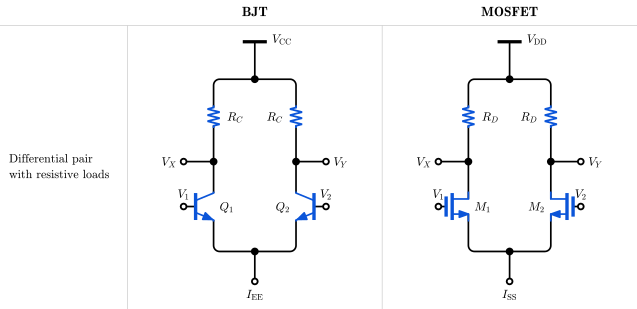

In [4]:
# HIDE/SHOW
show(C.pair_loaded)

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 30**

| | BJT |
|---|---|
| **Problem** | Design a resistively loaded bipolar differential pair (ideal tail source) with a small-signal differential gain of 10 and a power budget of $1\,\mathrm{mW}$ from a $2\,\mathrm{V}$ supply. Find the tail current, transconductance and $R_C$. |
| **Given** | $\lvert A_v\rvert=10$, $P=1\,\mathrm{mW}$, $V_{CC}=2\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Power to tail current.** The supply delivers $I_{EE}$: $I_{EE}$ $=P/V_{CC}$ $=1\,\mathrm{mW}/2\,\mathrm{V}$ $=0.5\,\mathrm{mA}$. |
| **Answer 2** | **Current per transistor.** $I_C=I_{EE}/2=0.25\,\mathrm{mA}$ near equilibrium. |
| **Answer 3** | **Transconductance.** $g_m$ $=I_C/V_T$ $=0.25\,\mathrm{mA}/26\,\mathrm{mV}$ $=9.62\,\mathrm{mS}$ $=1/(104\,\Omega)$. |
| **Answer 4** | **Gain relation.** $\lvert A_v\rvert=g_mR_C$, so $R_C=\lvert A_v\rvert/g_m$. |
| **Answer 5** | **Load resistor.** $R_C$ $=10\times104\,\Omega$ $=1040\,\Omega$. |
| **Answer 6** | **Check of bias.** The drop across each load is $R_CI_C=0.26\,\mathrm{V}$, so the collectors sit at $1.74\,\mathrm{V}$ and the input common mode must be below this. |
| **Result** | $I_{EE}=0.5\,\mathrm{mA}$, $g_m$ $=1/(104\,\Omega)$ $=9.62\,\mathrm{mS}$, $R_C\approx1040\,\Omega$ |

**Problem 31**

| | BJT |
|---|---|
| **Problem** | In the bipolar pair (collector resistors $R_C$, ideal tail current source) include the output resistance $r_O$ of $Q_1$ and $Q_2$ in the small-signal model, and prove that the tail node still satisfies $v_P=0$ for differential inputs $v_{in1}=-v_{in2}$. |
| **Given** | Symmetric pair, $R_C$ loads, ideal tail source, $V_A<\infty$ ($r_O$ finite), $v_{in1}=-v_{in2}$ |
| **Answer 1** | **Collector nodes.** KCL at $X$: $-\dfrac{v_X}{R_C}$ $=g_mv_{\pi1}+\dfrac{v_X-v_P}{r_O}$; likewise at $Y$ with $v_{\pi2}$, $v_Y$ |
| **Answer 2** | **Emitter current of $Q_1$.** $i_{E1}$ $=\dfrac{v_{\pi1}}{r_\pi}+g_mv_{\pi1}+\dfrac{v_X-v_P}{r_O}$ $=\dfrac{v_{\pi1}}{r_\pi}-\dfrac{v_X}{R_C}$, and the same for $Q_2$ |
| **Answer 3** | **KCL at $P$.** Ideal tail: $i_{E1}+i_{E2}$ $=0\Rightarrow\dfrac{v_{\pi1}+v_{\pi2}}{r_\pi}$ $=\dfrac{v_X+v_Y}{R_C}$ |
| **Answer 4** | **Use the differential input.** $v_{\pi1}+v_{\pi2}$ $=v_{in1}+v_{in2}-2v_P$ $=-2v_P$, so $v_X+v_Y=-\dfrac{2R_C}{r_\pi}v_P$ |
| **Answer 5** | **Add the two collector equations.** $-\dfrac{v_X+v_Y}{R_C}$ $=-2g_mv_P+\dfrac{v_X+v_Y-2v_P}{r_O}$ |
| **Answer 6** | **Substitute.** $\dfrac{2v_P}{r_\pi}$ $=-2g_mv_P-\dfrac{2v_P}{r_O}\left(1+\dfrac{R_C}{r_\pi}\right)\Rightarrow v_P\left[\dfrac{1}{r_\pi}+g_m+\dfrac{1}{r_O}\left(1+\dfrac{R_C}{r_\pi}\right)\right]$ $=0$ |
| **Answer 7** | **Conclusion.** The bracket is positive, so $v_P=0$; then $v_X=-v_Y$ and the half-circuit gain is $-g_m(R_C\parallel r_O)$ |
| **Result** | $v_P=0$ holds with finite $r_O$; $A_v=-g_m(R_C\parallel r_O)$ |

**Problem 32**

| | BJT |
|---|---|
| **Problem** | Design the bipolar differential pair (npn $Q_1$, $Q_2$, equal collector resistors $R_C$ to $V_{CC}$, emitters joined to an ideal tail current $I_{EE}$) for a differential voltage gain of 10 and a power budget of 2 mW, with $V_{CC}=2.5\,\mathrm{V}$ and $V_A=\infty$. |
| **Given** | $\lvert A_v\rvert=10$, $P=2\,\mathrm{mW}$, $V_{CC}=2.5\,\mathrm{V}$, $V_A=\infty$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Tail current.** $I_{EE}$ $=P/V_{CC}$ $=2\,\mathrm{mW}/2.5\,\mathrm{V}$ $=0.8\,\mathrm{mA}$, so $I_{C1}=I_{C2}=0.4\,\mathrm{mA}$ |
| **Answer 2** | **Transconductance.** $g_m$ $=I_C/V_T$ $=0.4\,\mathrm{mA}/26\,\mathrm{mV}$ $=15.4\,\mathrm{mS}$ |
| **Answer 3** | **Load resistors.** $\lvert A_v\rvert=g_mR_C=10$ gives $R_C=10/g_m=650\,\Omega$ |
| **Answer 4** | **Headroom check.** $V_{X}$ $=V_Y$ $=V_{CC}-I_CR_C$ $=2.5-0.26$ $=2.24\,\mathrm{V}$; the transistors stay out of saturation for an input CM level up to about $2.24\,\mathrm{V}$. |
| **Result** | $I_{EE}=0.8\,\mathrm{mA}$, $R_C=650\,\Omega$ ($g_m=15.4\,\mathrm{mS}$) |

**Problem 33**

| | BJT |
|---|---|
| **Problem** | An npn differential pair has $R_{id}=20\,\mathrm{k}\Omega$, $A_d=100\,\mathrm{V/V}$ and $\beta=100$. Find $g_m$, $R_C$ and the tail current $I$. |
| **Given** | $R_{id}=20\,\mathrm{k}\Omega$, $A_d=100$, $\beta=100$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Base resistance.** $R_{id}$ $=2r_\pi\Rightarrow r_\pi$ $=10\,\mathrm{k}\Omega$. |
| **Answer 2** | **Transconductance.** $r_\pi$ $=\beta/g_m\Rightarrow g_m$ $=100/10\,\mathrm{k}\Omega$ $=10\,\mathrm{mA/V}$. |
| **Answer 3** | **Collector resistor.** $A_d$ $=g_mR_C\Rightarrow R_C$ $=100/10$ $=10\,\mathrm{k}\Omega$. |
| **Answer 4** | **Bias current.** $g_m$ $=\dfrac{I/2}{V_T}\Rightarrow I$ $=2V_Tg_m$ $=2\times0.025\times10$ $=0.5\,\mathrm{mA}$. |
| **Result** | $g_m=10\,\mathrm{mA/V}$, $R_C=10\,\mathrm{k}\Omega$, $I=0.5\,\mathrm{mA}$ |

**Problem 34**

| | BJT |
|---|---|
| **Problem** | An npn differential pair with tail current $I=200\,\mu\mathrm{A}$ and $R_C=10\,\mathrm{k}\Omega$ in each collector is driven by $v_{id}=10\,\mathrm{mV}$. Find $r_e$, the gain of the differential half-circuit, the signal at each collector, and the signal between the collectors. |
| **Given** | $I=200\,\mu\mathrm{A}$, $R_C=10\,\mathrm{k}\Omega$, $v_{id}=10\,\mathrm{mV}$, $V_T=25\,\mathrm{mV}$, $\alpha\approx1$ |
| **Answer 1** | **Half-circuit input.** The half-circuit input is $v_{id}/2=5\,\mathrm{mV}$ and it is biased at $I/2=100\,\mu\mathrm{A}$. |
| **Answer 2** | **Emitter resistance.** $r_e$ $=\dfrac{V_T}{I/2}$ $=\dfrac{25\,\mathrm{mV}}{0.1\,\mathrm{mA}}$ $=250\,\Omega$. |
| **Answer 3** | **Half-circuit gain.** $-\dfrac{R_C}{r_e}$ $=-\dfrac{10\,\mathrm{k}\Omega}{0.25\,\mathrm{k}\Omega}$ $=-40\,\mathrm{V/V}$. |
| **Answer 4** | **Collector signals.** Each collector: $40\times5\,\mathrm{mV}$ $=200\,\mathrm{mV}$ (opposite signs). |
| **Answer 5** | **Between collectors.** $v_{od}$ $=2\times200\,\mathrm{mV}$ $=400\,\mathrm{mV}$, $A_d=40\,\mathrm{V/V}$. |
| **Result** | $r_e=250\,\Omega$, half-circuit gain $-40\,\mathrm{V/V}$, $\pm200\,\mathrm{mV}$ at the collectors, $400\,\mathrm{mV}$ between them |

**Problem 35**

| | BJT |
|---|---|
| **Problem** | An npn pair runs from $\pm2.5\,\mathrm{V}$ supplies and may dissipate at most $1\,\mathrm{mW}$. It must have $A_d=60\,\mathrm{V/V}$ with $\beta=100$ and a $10\,\mathrm{mV}$ differential input. Find (a) $I$, $R_C$, $V_C$, (b) $R_{id}$, (c) the signal swing at each collector, (d) the maximum common-mode input for active operation ($v_{CB}\ge-0.4\,\mathrm{V}$). |
| **Given** | $P=1\,\mathrm{mW}$, $\pm2.5\,\mathrm{V}$, $A_d=60$, $\beta=100$, $v_{id}=10\,\mathrm{mV}$, $V_T=25\,\mathrm{mV}$, $\alpha\approx1$ |
| **Answer 1** | **(a) Bias current.** $I$ $=\dfrac{P}{V_{CC}+V_{EE}}$ $=\dfrac{1\,\mathrm{mW}}{5\,\mathrm{V}}$ $=0.2\,\mathrm{mA}$. |
| **Answer 2** | **(a) $g_m$.** $g_m$ $=\dfrac{I/2}{V_T}$ $=\dfrac{0.1}{0.025}$ $=4\,\mathrm{mA/V}$. |
| **Answer 3** | **(a) $R_C$.** $A_d$ $=g_mR_C\Rightarrow R_C$ $=60/4$ $=15\,\mathrm{k}\Omega$. |
| **Answer 4** | **(a) $V_C$.** $V_C$ $=2.5-0.1\,\mathrm{mA}\times15\,\mathrm{k}\Omega$ $=+1.0\,\mathrm{V}$. |
| **Answer 5** | **(b) Input resistance.** $R_{id}$ $=2r_\pi$ $=2\beta/g_m$ $=2\times100/4$ $=50\,\mathrm{k}\Omega$. |
| **Answer 6** | **(c) Swing.** $v_{od}$ $=60\times10\,\mathrm{mV}$ $=0.6\,\mathrm{V}$, so each collector moves $\pm0.3\,\mathrm{V}$: from $0.7\,\mathrm{V}$ to $1.3\,\mathrm{V}$. |
| **Answer 7** | **(d) Maximum $V_{CM}$.** Lowest collector voltage $0.7\,\mathrm{V}$; $V_{CM,max}=0.7+0.4=1.1\,\mathrm{V}$ (with the $5\,\mathrm{mV}$ at the base, $1.095\,\mathrm{V}$). |
| **Result** | $I=0.2\,\mathrm{mA}$, $R_C=15\,\mathrm{k}\Omega$, $V_C=1\,\mathrm{V}$, $R_{id}=50\,\mathrm{k}\Omega$, swing $\pm0.3\,\mathrm{V}$, $V_{CM,max}\approx1.1\,\mathrm{V}$ |

**Problem 36**

| | BJT |
|---|---|
| **Problem** | (a) For an npn pair with tail current $I$, $R_C$ and peak differential input $\hat v_{id}$, show that the maximum common-mode input for active operation (with $v_{CB}\ge-0.4\,\mathrm{V}$) is $V_{CM,max}$ $=V_{CC}+0.4-\dfrac{\hat v_{id}}2-A_d\left(V_T+\dfrac{\hat v_{id}}2\right)$. (b) Design for $V_{CC}=2.5\,\mathrm{V}$ ($V_{EE}=-2.5\,\mathrm{V}$), $\hat v_{id}=10\,\mathrm{mV}$, $A_d=50\,\mathrm{V/V}$ and $1\,\mathrm{mW}$ maximum power; find $V_{CM,max}$, $I$, $R_C$. (c) Find the $A_d$ that is possible if $V_{CM,max}=1\,\mathrm{V}$. |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $\hat v_{id}=10\,\mathrm{mV}$, $A_d=50$, $P_{max}=1\,\mathrm{mW}$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **(a) Lowest collector.** $v_{C1,min}$ $=\left(V_{CC}-\tfrac I2R_C\right)-A_d\dfrac{\hat v_{id}}2$. |
| **Answer 2** | **(a) Express $IR_C$.** $A_d$ $=g_mR_C$ $=\dfrac{I/2}{V_T}R_C\Rightarrow\dfrac{IR_C}2$ $=A_dV_T$, so $v_{C1,min}$ $=V_{CC}-A_d\left(V_T+\dfrac{\hat v_{id}}2\right)$. |
| **Answer 3** | **(a) Active condition.** $v_{B1}$ $=V_{CM,max}+\dfrac{\hat v_{id}}2\le0.4+v_{C1,min}$. |
| **Answer 4** | **(a) Result.** $V_{CM,max}$ $=V_{CC}+0.4-\dfrac{\hat v_{id}}2-A_d\left(V_T+\dfrac{\hat v_{id}}2\right)$. |
| **Answer 5** | **(b) $V_{CM,max}$.** $2.5+0.4-0.005-50\times(0.025+0.005)$ $=1.395$ $\approx1.4\,\mathrm{V}$. |
| **Answer 6** | **(b) $I$ and $R_C$.** $IR_C=2A_dV_T=2.5\,\mathrm{V}$. Power: $I$ $=1\,\mathrm{mW}/5\,\mathrm{V}$ $=0.2\,\mathrm{mA}$, so $R_C=2.5/0.2=12.5\,\mathrm{k}\Omega$. |
| **Answer 7** | **(c) $V_{CM,max}=1\,\mathrm{V}$.** $1$ $=2.895-A_d\times0.030\Rightarrow A_d$ $=63.2\,\mathrm{V/V}$. |
| **Result** | $V_{CM,max}$ $=V_{CC}+0.4-\tfrac{\hat v_{id}}2-A_d(V_T+\tfrac{\hat v_{id}}2)$; (b) $1.40\,\mathrm{V}$, $I=0.2\,\mathrm{mA}$, $R_C=12.5\,\mathrm{k}\Omega$; (c) $A_d=63.2$ |

**Problem 37**

| | BJT |
|---|---|
| **Problem** | A BJT differential pair has a collector resistor $R_C$ in each collector, supply $V_{CC}=5\,\mathrm{V}$ and an ideal tail current source $I$ chosen so that $I R_C=4\,\mathrm{V}$. A sinusoid of $5\,\mathrm{mV}$ amplitude is applied to each base, in antiphase (so $v_{id}$ has $10\,\mathrm{mV}$ peak). Find the differential gain $A_d=v_{od}/v_{id}$ and the waveforms at the two collectors and between them ($\alpha\approx1$, $V_T=25\,\mathrm{mV}$). |
| **Given** | $V_{CC}=5\,\mathrm{V}$, $IR_C=4\,\mathrm{V}$, $\hat v_{b1}=+5\,\mathrm{mV}$, $\hat v_{b2}=-5\,\mathrm{mV}$, $V_T=25\,\mathrm{mV}$, $\alpha\approx1$ |
| **Answer 1** | **Gain expression.** Each transistor carries $I/2$, so $g_m=\dfrac{I/2}{V_T}$ and $A_d=g_mR_C=\dfrac{IR_C}{2V_T}$. |
| **Answer 2** | **Numerical gain.** $A_d$ $=\dfrac{4}{2\times0.025}$ $=80\,\mathrm{V/V}$ |
| **Answer 3** | **DC collector voltage.** $V_{C1}$ $=V_{C2}$ $=V_{CC}-\dfrac I2R_C$ $=5-2$ $=3\,\mathrm{V}$ |
| **Answer 4** | **Differential input.** $v_{id}$ $=v_{b1}-v_{b2}$ $=10\sin\omega t\,\mathrm{mV}$; each collector moves by $\dfrac{A_d}{2}v_{id}$ $=80\times5\,\mathrm{mV}$ $=0.4\,\mathrm{V}$. |
| **Answer 5** | **Collector waveforms.** $v_{C1}$ $=3-0.4\sin\omega t\,\mathrm{V}$ (inverting from $Q_1$ base), $v_{C2}$ $=3+0.4\sin\omega t\,\mathrm{V}$ |
| **Answer 6** | **Differential output.** $v_O$ $=v_{C2}-v_{C1}$ $=0.8\sin\omega t\,\mathrm{V}$ $=A_dv_{id}$, consistent. |
| **Result** | $A_d=80\,\mathrm{V/V}$; $v_{C1}=3-0.4\sin\omega t$, $v_{C2}=3+0.4\sin\omega t$, $v_O=0.8\sin\omega t$ (volts) |

**Problem 38**

| | BJT |
|---|---|
| **Problem** | A BJT differential pair has $R_C=10\,\mathrm{k}\Omega$ in each collector, $V_{CC}=5\,\mathrm{V}$ and bases at dc ground. A differential sinusoid is applied with $v_{be1}=+2.5\sin\omega t$ and $v_{be2}=-2.5\sin\omega t$ (mV). Find the largest tail current $I$ that keeps both transistors active at all times (collector no lower than the base at the extreme), then $g_m$, $A_d$ and the waveforms ($V_T=25\,\mathrm{mV}$, $\alpha\approx1$). |
| **Given** | $R_C=10\,\mathrm{k}\Omega$, $V_{CC}=5\,\mathrm{V}$, $\hat v_{be}=2.5\,\mathrm{mV}$ per side, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Collector voltage.** $g_m$ $=\dfrac{I/2}{V_T}$ $=\dfrac{I}{0.05}$ ($I$ in mA, $g_m$ in mA/V). $v_{C1}$ $=V_{CC}-\dfrac I2R_C-g_mR_C(2.5\times10^{-3})\sin\omega t$ $=5-5I-0.5I\sin\omega t$ (V) |
| **Answer 2** | **Other collector.** $v_{C2}=5-5I+0.5I\sin\omega t$ (V) |
| **Answer 3** | **Active-mode limit.** The lowest collector value is $5-5.5I$; keeping it at least $5\,\mathrm{mV}$ (a margin for the base voltage, so $v_{CB}\ge0$): $5-5.5I$ $=0.005\Rightarrow I$ $=0.908\,\mathrm{mA}$. Choose $I=0.9\,\mathrm{mA}$. |
| **Answer 4** | **Small-signal values.** $g_m$ $=\dfrac{0.9}{0.05}$ $=18\,\mathrm{mA/V}$, $A_d$ $=g_mR_C$ $=18\times10$ $=180\,\mathrm{V/V}$ |
| **Answer 5** | **Waveforms.** Each collector carries a sine of $\dfrac{A_d}{2}\times5\,\mathrm{mV}$ $=0.45\,\mathrm{V}$ amplitude on a dc level $5-0.45\times10=0.5\,\mathrm{V}$ (antiphase); between collectors a sine of $0.9\,\mathrm{V}$ peak. |
| **Answer 6** | **Check minimum.** Lowest collector voltage $0.5-0.45=0.05\,\mathrm{V}$, above the base voltage (at most a few mV), so both transistors stay active. |
| **Result** | $I\approx0.9\,\mathrm{mA}$, $g_m=18\,\mathrm{mA/V}$, $A_d=180$; collectors $0.5\pm0.45\sin\omega t$ (V, antiphase); $v_{od}$ amplitude $0.9\,\mathrm V$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 34**

| | MOSFET |
|---|---|
| **Problem** | Design an NMOS differential pair (two matched NMOS transistors, a drain resistor $R_D$ in each branch to $V_{DD}$, an ideal tail current source $I_{SS}$) for a differential gain of 5 and a power budget of 2 mW. The stage that follows needs an output common-mode level of at least 1.6 V. Use $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lambda=0$, $V_{DD}=1.8\,\mathrm{V}$. Find $I_{SS}$, $R_D$ and $W/L$. |
| **Given** | $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lambda=0$, $V_{DD}=1.8\,\mathrm{V}$, $P=2\,\mathrm{mW}$, $\lvert A_v\rvert=5$, $V_{CM,out}\ge 1.6\,\mathrm{V}$ |
| **Answer 1** | **Tail current from the power budget.** Only the tail current is drawn from the supply, so $I_{SS}$ $=P/V_{DD}$ $=2\,\mathrm{mW}/1.8\,\mathrm{V}$ $=1.11\,\mathrm{mA}$; each transistor carries $I_{SS}/2=0.555\,\mathrm{mA}$. |
| **Answer 2** | **Output common-mode level.** $V_{CM,out}$ $=V_{DD}-R_D\dfrac{I_{SS}}{2}$. Requiring $V_{CM,out}\ge1.6\,\mathrm{V}$ allows a drop of at most $0.2\,\mathrm{V}$ across each resistor. |
| **Answer 3** | **Largest load resistor.** $R_D\le\dfrac{0.2\,\mathrm{V}}{0.555\,\mathrm{mA}}$ $=360\,\Omega$. Take $R_D=360\,\Omega$, so $V_{CM,out}=1.60\,\mathrm{V}$. |
| **Answer 4** | **Required transconductance.** The gain of the pair is $\lvert A_v\rvert=g_mR_D=5$, so $g_m$ $=5/360\,\Omega$ $=13.9\,\mathrm{mS}$. |
| **Answer 5** | **Aspect ratio.** Each device has $I_D=I_{SS}/2$, so $g_m$ $=\sqrt{2\mu_nC_{ox}\frac{W}{L}\frac{I_{SS}}{2}}$ $=\sqrt{\mu_nC_{ox}\frac{W}{L}I_{SS}}$. Hence $\dfrac{W}{L}$ $=\dfrac{g_m^2}{\mu_nC_{ox}I_{SS}}$ $=\dfrac{(13.9\,\mathrm{mS})^2}{(100\,\mu\mathrm{A/V^2})(1.11\,\mathrm{mA})}$ $\approx1736$ (with the unrounded $g_m=13.89\,\mathrm{mS}$ and $I_{SS}=1.111\,\mathrm{mA}$). |
| **Answer 6** | **Comment.** The overdrive is $V_{ov}=2I_D/g_m=80\,\mathrm{mV}$. The very large $W/L$ is the price of the small voltage drop allowed across $R_D$. |
| **Result** | $I_{SS}=1.11\,\mathrm{mA}$, $R_D=360\,\Omega$, $W/L\approx1736$ |

**Problem 35**

| | MOSFET |
|---|---|
| **Problem** | For an NMOS differential pair (drain resistors $R_D$, tail current $I_{SS}$, $\lambda=0$) whose small-signal drain-current difference is $I_{D1}-I_{D2}$ $\approx\sqrt{\mu_nC_{ox}\frac{W}{L}I_{SS}}\,(V_{in1}-V_{in2})$, show that this law gives the differential voltage gain $-g_mR_D$. |
| **Given** | $V_{out1}-V_{out2}$ $=-R_D(I_{D1}-I_{D2})$, $\;I_{D1}-I_{D2}$ $\approx\sqrt{\mu_nC_{ox}\frac WL I_{SS}}\,(V_{in1}-V_{in2})$ |
| **Answer 1** | **Output difference.** $V_{out1}=V_{DD}-R_DI_{D1}$ and $V_{out2}=V_{DD}-R_DI_{D2}$, so $V_{out1}-V_{out2}$ $=-R_D(I_{D1}-I_{D2})$. |
| **Answer 2** | **Insert the current law.** $V_{out1}-V_{out2}$ $=-R_D\sqrt{\mu_nC_{ox}\frac WL I_{SS}}\,(V_{in1}-V_{in2})$. |
| **Answer 3** | **Identify $g_m$.** Each device carries $I_D=I_{SS}/2$, so $g_m$ $=\sqrt{2\mu_nC_{ox}\frac WL I_D}$ $=\sqrt{\mu_nC_{ox}\frac WL I_{SS}}$, exactly the square root above. |
| **Answer 4** | **Gain.** $V_{out1}-V_{out2}$ $=-g_mR_D(V_{in1}-V_{in2})$, so $A_v$ $=\dfrac{V_{out1}-V_{out2}}{V_{in1}-V_{in2}}$ $=-g_mR_D$. |
| **Answer 5** | **Numerical check.** $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $W/L=40$, $I_{SS}=1\,\mathrm{mA}$, $R_D=2\,\mathrm{k}\Omega$: $g_m=2.00\,\mathrm{mS}$, so $A_v=-4.00$. Solving the exact square-law equations for $\Delta V_{in}=1$, 5, 20 mV gives $-4.0000$, $-3.9999$, $-3.9992$. |
| **Result** | $A_v=-g_mR_D$ |

**Problem 36**

| | MOSFET |
|---|---|
| **Problem** | Repeat the design of Problem 34 with $V_{DD}=2\,\mathrm{V}$: an NMOS pair with resistive loads, differential gain 5, power budget $2\,\mathrm{mW}$, output common-mode level at least $1.6\,\mathrm{V}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lambda=0$. Then express the trade-off between $V_{DD}$ and $W/L$ for a given output common-mode level. |
| **Given** | $A_v=5$, $P=2\,\mathrm{mW}$, $V_{CM,out}=1.6\,\mathrm{V}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lambda=0$, $V_{DD}=2\,\mathrm{V}$ |
| **Answer 1** | **Tail current.** $I_{SS}$ $=P/V_{DD}$ $=2\,\mathrm{mW}/2\,\mathrm{V}$ $=1\,\mathrm{mA}$, $0.5\,\mathrm{mA}$ per side |
| **Answer 2** | **Load resistors.** $V_{DD}-R_DI_{SS}/2\ge1.6\,\mathrm{V}\Rightarrow R_D$ $=\dfrac{0.4\,\mathrm{V}}{0.5\,\mathrm{mA}}$ $=800\,\Omega$ |
| **Answer 3** | **Transconductance.** $g_m$ $=A_v/R_D$ $=5/800\,\Omega$ $=6.25\,\mathrm{mS}$ |
| **Answer 4** | **Aspect ratio.** $g_m$ $=\sqrt{2\mu_nC_{ox}\frac WL\frac{I_{SS}}{2}}\Rightarrow\dfrac WL$ $=\dfrac{g_m^2}{\mu_nC_{ox}I_{SS}}$ $=\dfrac{(6.25\,\mathrm{mS})^2}{(100\,\mu)(1\,\mathrm{mA})}$ $=391$ |
| **Answer 5** | **General trade-off.** $I_{SS}=P/V_{DD}$, $R_D=2(V_{DD}-V_{CM,out})/I_{SS}$, $g_m=A_v/R_D$, so $\dfrac WL$ $=\dfrac{A_v^2I_{SS}}{4\mu_nC_{ox}(V_{DD}-V_{CM,out})^2}$ $=\dfrac{A_v^2P}{4\mu_nC_{ox}V_{DD}(V_{DD}-V_{CM,out})^2}$ |
| **Answer 6** | **Reading it.** Raising $V_{DD}$ leaves more drop across $R_D$ and so allows a larger $R_D$ and a much smaller $W/L$ (about $1/V_{DD}(V_{DD}-V_{CM,out})^2$); for $V_{DD}=1.8\,\mathrm{V}$ the formula gives $1736$, the value of Problem 34, and for $2\,\mathrm{V}$ it gives $391$ |
| **Answer 7** | **Check the overdrive.** $V_{GS}-V_{TH}$ $=\sqrt{I_{SS}/(\mu_nC_{ox}W/L)}$ $=0.16\,\mathrm{V}$, so the inputs can sit up to $V_{CM,out}+V_{TH}$ with the devices saturated |
| **Result** | $I_{SS}=1\,\mathrm{mA}$, $R_D=800\,\Omega$, $W/L=391$; in general $W/L$ $=\dfrac{A_v^2P}{4\mu_nC_{ox}V_{DD}(V_{DD}-V_{CM,out})^2}$ |

**Problem 37**

| | MOSFET |
|---|---|
| **Problem** | An NMOS pair $M_1$, $M_2$ with sources joined at node $P$, an ideal tail current $I_{SS}$ from $P$ to ground, and equal drain resistors $R_D$ to $V_{DD}$ (drains $X$ of $M_1$ and $Y$ of $M_2$). A single-ended source $v_{in}$ drives the gate of $M_1$; the gate of $M_2$ is held at a dc voltage $V_b$. Perfect symmetry, $\lambda=0$. (a) Treat $M_1$ as a common-source stage degenerated by the impedance at the source of $M_2$ and find $v_X$. (b) Treat $M_1$ as a source follower driving $M_2$ as a common-gate stage and find $v_Y$. (c) Find $(v_X-v_Y)/v_{in}$ and compare with a differentially driven pair. |
| **Given** | $g_{m1}=g_{m2}=g_m$, $\lambda=0$; numeric check with $g_m=2\,\mathrm{mS}$, $R_D=5\,\mathrm{k}\Omega$ |
| **Answer 1** | **Impedance at $P$ seen from $M_1$.** Looking into the source of $M_2$ (gate at ac ground, $\lambda=0$) gives $1/g_{m2}$; the ideal tail adds nothing in parallel |
| **Answer 2** | **(a) Degenerated common source.** $v_X$ $=-\dfrac{R_D}{1/g_{m1}+1/g_{m2}}v_{in}$ $=-\dfrac{g_mR_D}{2}v_{in}$ |
| **Answer 3** | **(b) Follower output.** $M_1$ drives $1/g_{m2}$ from its own $1/g_{m1}$: $v_P$ $=\dfrac{1/g_{m2}}{1/g_{m1}+1/g_{m2}}v_{in}$ $=\dfrac{v_{in}}2$ |
| **Answer 4** | **(b) Common-gate stage.** $M_2$ has its gate fixed and its source driven, gain $+g_{m2}R_D$: $v_Y$ $=g_mR_D\,v_P$ $=+\dfrac{g_mR_D}{2}v_{in}$ |
| **Answer 5** | **(c) Differential output.** $v_X-v_Y$ $=-\dfrac{g_mR_D}2v_{in}-\dfrac{g_mR_D}2v_{in}$ $=-g_mR_D\,v_{in}$ |
| **Answer 6** | **Numbers.** $g_mR_D=10$: $v_X=-5v_{in}$, $v_Y=+5v_{in}$, $(v_X-v_Y)/v_{in}=-10$ |
| **Answer 7** | **Comparison.** This is exactly the gain $-g_mR_D$ of the differentially driven pair: a single-ended input $v_{in}$ is the differential input $v_{in}-0$ plus a common-mode part $v_{in}/2$, which the symmetric pair with an ideal tail rejects |
| **Result** | $v_X=-\tfrac12g_mR_Dv_{in}$, $v_Y=+\tfrac12g_mR_Dv_{in}$, $(v_X-v_Y)/v_{in}=-g_mR_D$, the same as for differential drive |

**Problem 38**

| | MOSFET |
|---|---|
| **Problem** | Design the MOS differential pair (NMOS pair, drain resistors $R_D$ to $V_{DD}=1.8\,\mathrm{V}$, ideal tail $I_{SS}$) for a differential voltage gain of 5 with a power dissipation of 1 mW, if the equilibrium overdrive must be at least 150 mV. $\lambda=0$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$. |
| **Given** | $\lvert A_v\rvert=5$, $P=1\,\mathrm{mW}$, $V_{GS}-V_{TH}\ge0.15\,\mathrm{V}$, $\lambda=0$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{DD}=1.8\,\mathrm{V}$ |
| **Answer 1** | **Currents.** $I_{SS}$ $=1\,\mathrm{mW}/1.8\,\mathrm{V}$ $=0.556\,\mathrm{mA}$, $I_D=0.278\,\mathrm{mA}$ |
| **Answer 2** | **Gain in terms of overdrive.** $\lvert A_v\rvert$ $=g_mR_D$ $=\dfrac{2I_DR_D}{V_{GS}-V_{TH}}$ $=5$: the drop across $R_D$ is $I_DR_D=2.5(V_{GS}-V_{TH})$ |
| **Answer 3** | **Choose the overdrive.** Take the minimum, $V_{GS}-V_{TH}=0.15\,\mathrm{V}$, which keeps the drop across $R_D$ (and the headroom used) smallest. |
| **Answer 4** | **Size.** $\dfrac WL$ $=\dfrac{2I_D}{\mu_nC_{ox}(0.15)^2}$ $=\dfrac{0.556\,\mathrm{mA}}{2.25\,\mu\mathrm{A}}$ $=247$ |
| **Answer 5** | **Drain resistor.** $g_m$ $=2I_D/0.15\,\mathrm{V}$ $=3.70\,\mathrm{mS}$, $R_D=5/g_m=1.35\,\mathrm{k}\Omega$ |
| **Answer 6** | **Check.** Drop $I_DR_D=0.375\,\mathrm{V}$, $V_D=1.43\,\mathrm{V}$: the pair stays saturated for input CM levels up to $1.43\,\mathrm{V}+V_{TH}$. |
| **Result** | $I_{SS}=0.556\,\mathrm{mA}$, $W/L\approx247$, $R_D=1.35\,\mathrm{k}\Omega$ |

**Problem 39**

| | MOSFET |
|---|---|
| **Problem** | Design an NMOS differential amplifier (with resistive drain loads) so that a differential input $v_{id}=0.1\,\mathrm{V}$ gives a differential output of $1\,\mathrm{V}$, the pair operates with $\left(\dfrac{v_{id}/2}{V_{OV}}\right)^2$ $=0.04$ and $g_m=2\,\mathrm{mA/V}$; $k_n^\prime=0.2\,\mathrm{mA/V^2}$. Find $V_{OV}$, $I$, $R_D$ and $W/L$. |
| **Given** | $v_{id}=0.1\,\mathrm{V}$, $\lvert v_O\rvert=1\,\mathrm{V}$ (so $A_d=10$), $\left(\dfrac{v_{id}/2}{V_{OV}}\right)^2$ $=0.04$, $g_m=2\,\mathrm{mA/V}$, $k_n^\prime=0.2\,\mathrm{mA/V^2}$ |
| **Answer 1** | **Overdrive.** $\dfrac{v_{id}/2}{V_{OV}}$ $=\sqrt{0.04}$ $=0.2\Rightarrow V_{OV}$ $=\dfrac{0.05}{0.2}$ $=0.25\,\mathrm{V}$. |
| **Answer 2** | **Tail current.** $g_m$ $=\dfrac I{V_{OV}}\Rightarrow I$ $=2\times0.25$ $=0.5\,\mathrm{mA}$. |
| **Answer 3** | **Drain resistor.** $A_d$ $=\dfrac{1\,\mathrm{V}}{0.1\,\mathrm{V}}$ $=10$ $=g_mR_D\Rightarrow R_D$ $=\dfrac{10}{2}$ $=5\,\mathrm{k}\Omega$. |
| **Answer 4** | **Aspect ratio.** $\dfrac I2$ $=0.25$ $=\dfrac12\times0.2\times\dfrac WL\times0.25^2\Rightarrow\dfrac WL$ $=40$. |
| **Result** | $V_{OV}=0.25\,\mathrm{V}$, $I=0.5\,\mathrm{mA}$, $R_D=5\,\mathrm{k}\Omega$, $W/L=40$ |

**Problem 40**

| | MOSFET |
|---|---|
| **Problem** | Design an NMOS differential amplifier with drain resistors $R_D$ that dissipates at most $0.3\,\mathrm{mW}$ from $\pm0.6\,\mathrm{V}$ supplies, switches the current completely at $v_{id}=0.2\,\mathrm{V}$, and has $A_d=8\,\mathrm{V/V}$; $k_n^\prime=0.5\,\mathrm{mA/V^2}$. Find $I$, $V_{OV}$, $g_m$, $R_D$ and $W/L$. |
| **Given** | $P_{max}=0.3\,\mathrm{mW}$, $V_{DD}=0.6\,\mathrm{V}$, $V_{SS}=-0.6\,\mathrm{V}$, full switching at $v_{id}=0.2\,\mathrm{V}$, $A_d=8$, $k_n^\prime=0.5\,\mathrm{mA/V^2}$ |
| **Answer 1** | **Tail current.** $P=(V_{DD}-V_{SS})I$ with a total supply of $1.2\,\mathrm{V}$: $I$ $=\dfrac{0.3\,\mathrm{mW}}{1.2\,\mathrm{V}}$ $=0.25\,\mathrm{mA}$ (use the maximum). |
| **Answer 2** | **Overdrive.** Full switching occurs at $v_{id}=\sqrt2V_{OV}$; choose $\sqrt2V_{OV}=0.2\,\mathrm{V}$, i.e. $V_{OV}=0.141\,\mathrm{V}$; take $V_{OV}=0.14\,\mathrm{V}$ (then $\sqrt2V_{OV}$ $=0.198\,\mathrm{V}\le0.2\,\mathrm{V}$). |
| **Answer 3** | **Transconductance.** $g_m$ $=\dfrac I{V_{OV}}$ $=\dfrac{0.25}{0.14}$ $=1.79\,\mathrm{mA/V}$. |
| **Answer 4** | **Drain resistor.** $A_d$ $=g_mR_D$ $=8\Rightarrow R_D$ $=\dfrac8{1.79}$ $=4.48\,\mathrm{k}\Omega$ $\approx4.5\,\mathrm{k}\Omega$. |
| **Answer 5** | **Aspect ratio.** $\dfrac I2$ $=0.125$ $=\dfrac12\times0.5\times\dfrac WL\times0.14^2\Rightarrow\dfrac WL$ $=25.5$. |
| **Answer 6** | **Design.** $I=0.25\,\mathrm{mA}$, $V_{OV}=0.14\,\mathrm{V}$, $R_D=4.5\,\mathrm{k}\Omega$, $W/L=25.5$ (with $V_{OV}=0.1414\,\mathrm{V}$ exactly: $R_D=4.53\,\mathrm{k}\Omega$, $W/L=25.0$). |
| **Result** | $I=0.25\,\mathrm{mA}$, $V_{OV}\approx0.14\,\mathrm{V}$, $g_m\approx1.79\,\mathrm{mA/V}$, $R_D\approx4.5\,\mathrm{k}\Omega$, $W/L\approx25.5$ |
````
`````

### Emitter-coupled pair / Source-coupled pair

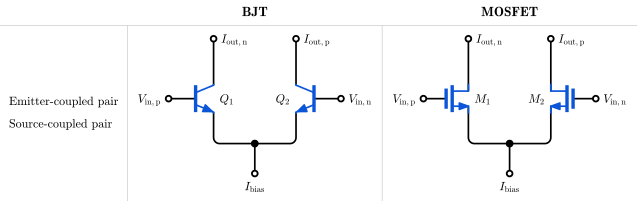

In [5]:
# HIDE/SHOW
show(C.differential_pair)

`````{tab-set}
````{tab-item} MOSFET
:sync: mosfet

**Problem 41**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair must have $g_m=1\,\mathrm{mA/V}$ with each transistor biased at $V_{OV}=0.25\,\mathrm{V}$; $k_n^\prime=0.4\,\mathrm{mA/V^2}$. Find the tail current $I$ and $W/L$. |
| **Given** | $g_m=1\,\mathrm{mA/V}$, $V_{OV}=0.25\,\mathrm{V}$, $k_n^\prime=0.4\,\mathrm{mA/V^2}$ |
| **Answer 1** | **Tail current.** $g_m$ $=\dfrac{2(I/2)}{V_{OV}}$ $=\dfrac I{V_{OV}}\Rightarrow I$ $=g_mV_{OV}$ $=1\times0.25$ $=0.25\,\mathrm{mA}$. |
| **Answer 2** | **Aspect ratio.** $\dfrac I2$ $=\dfrac12k_n^\prime\dfrac WLV_{OV}^2\Rightarrow0.125$ $=\dfrac12\times0.4\times\dfrac WL\times0.0625\Rightarrow\dfrac WL$ $=10$. |
| **Result** | $I=0.25\,\mathrm{mA}$, $W/L=10$ |
````
`````

### Other Circuits

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 39**

| | BJT |
|---|---|
| **Problem** | Compare the power drawn by a bipolar differential pair with that of a single common-emitter stage when both have the same voltage gain, the same collector resistance and the same supply voltage. |
| **Given** | Equal $\lvert A_v\rvert$, $R_C$, $V_{CC}$; pair tail current $I_{EE}$, CE collector current $I_C$ |
| **Answer 1** | **Gain of the pair.** $\lvert A_v\rvert_\mathrm{diff}$ $=g_{m1,2}R_C$, where $g_{m1,2}=I_{EE}/(2V_T)$ is the transconductance of each transistor. |
| **Answer 2** | **Gain of the CE stage.** $\lvert A_v\rvert_\mathrm{CE}$ $=g_mR_C$ with $g_m=I_C/V_T$. |
| **Answer 3** | **Equal gain and $R_C$.** This requires $g_{m1,2}=g_m$, i.e. $I_{EE}/2=I_C$. |
| **Answer 4** | **Currents.** $I_{EE}=2I_C$. |
| **Answer 5** | **Power.** $P_\mathrm{pair}$ $=V_{CC}I_{EE}$ $=2V_{CC}I_C$ $=2P_\mathrm{CE}$. |
| **Result** | $I_{EE}=2I_C$: the pair dissipates twice the power of the CE stage |

**Problem 40**

| | BJT |
|---|---|
| **Problem** | An npn differential pair (finite Early voltage $V_A$, transistors $Q_1,Q_2$) uses ideal current sources as collector loads to maximise the gain. Find the small-signal differential gain $(v_{out1}-v_{out2})/(v_{in1}-v_{in2})$. |
| **Given** | $g_m$, $r_O=V_A/I_C$ of $Q_{1,2}$; ideal loads ($r=\infty$) |
| **Answer 1** | **Half circuit.** For small differential inputs the tail node P is a virtual ground, so each side is a common-emitter stage with emitter at ac ground. |
| **Answer 2** | **Load seen at the collector.** An ideal current source has infinite resistance, so only $r_O$ of the transistor remains. |
| **Answer 3** | **Output of side 1.** $v_{out1}=-g_mr_Ov_{in1}$. |
| **Answer 4** | **Output of side 2.** $v_{out2}=-g_mr_Ov_{in2}$. |
| **Answer 5** | **Subtract.** $\dfrac{v_{out1}-v_{out2}}{v_{in1}-v_{in2}}$ $=-g_mr_O$. |
| **Answer 6** | **Meaning.** $g_mr_O=V_A/V_T$ is the intrinsic gain, independent of current. |
| **Result** | $A_v=-g_mr_O$ |

**Problem 41**

| | BJT |
|---|---|
| **Problem** | An npn differential pair has pnp transistors $Q_3,Q_4$ as current-source loads (bases at a fixed bias $V_b$, emitters at $V_{CC}$). Find the differential gain with finite Early voltages. |
| **Given** | $g_{m1}$; output resistances $r_{ON}$ (npn) and $r_{OP}$ (pnp) |
| **Answer 1** | **Load transistors.** With the base held at a constant $V_b$ and the emitter at $V_{CC}$, each pnp carries a fixed $V_{EB}$ and so acts as a current source with only its output resistance $r_{OP}$ in the signal path. |
| **Answer 2** | **Half circuit.** Each side is a common-emitter npn stage with the emitter at virtual ground and load $r_{OP}$ at the collector. |
| **Answer 3** | **Resistance at the output node.** $R_{out}=r_{ON}\parallel r_{OP}$. |
| **Answer 4** | **Gain of a half circuit.** $v_{out1}/v_{in1}$ $=-g_m(r_{ON}\parallel r_{OP})$, and likewise for side 2 with $v_{in2}$. |
| **Answer 5** | **Differential gain.** The difference of the outputs over the difference of the inputs equals this single-ended half-circuit gain. |
| **Result** | $A_v=-g_m(r_{ON}\parallel r_{OP})$ |

**Problem 42**

| | BJT |
|---|---|
| **Problem** | A bipolar pair $Q_1$, $Q_2$ with collector resistors $R_C$ to $V_{CC}$ and differential output $V_{out}$ between the collectors; the tail node $P$ goes to ground through a current source $I_{EE}$ in parallel with a resistance $R_{EE}$. Show that $P$ is still a virtual ground for small differential inputs and find the differential gain, as was done for the ideal tail source. |
| **Given** | Symmetric pair, $R_C$ loads, tail $I_{EE}\parallel R_{EE}$, $V_A=\infty$, $v_{in1}=-v_{in2}$ |
| **Answer 1** | **Small-signal model.** The source $I_{EE}$ is an open circuit, $R_{EE}$ stays from $P$ to ground; $v_{\pi1}=v_{in1}-v_P$, $v_{\pi2}=v_{in2}-v_P$ |
| **Answer 2** | **KCL at $P$.** $\dfrac{v_{\pi1}}{r_\pi}+g_mv_{\pi1}+\dfrac{v_{\pi2}}{r_\pi}+g_mv_{\pi2}$ $=\dfrac{v_P}{R_{EE}}$ |
| **Answer 3** | **Differential input.** With $v_{in2}=-v_{in1}$: $v_{\pi1}+v_{\pi2}=-2v_P$, so $-2v_P\dfrac{\beta+1}{r_\pi}$ $=\dfrac{v_P}{R_{EE}}$ |
| **Answer 4** | **Virtual ground.** $v_P\left(\dfrac{2(\beta+1)}{r_\pi}+\dfrac{1}{R_{EE}}\right)$ $=0\Rightarrow v_P$ $=0$: the increase in $I_{C1}$ equals the decrease in $I_{C2}$, so no signal current flows in $R_{EE}$ |
| **Answer 5** | **Half circuits.** With $P$ grounded, $v_{out1}=-g_mR_Cv_{in1}$ and $v_{out2}=-g_mR_Cv_{in2}$ |
| **Answer 6** | **Gain.** $A_v$ $=\dfrac{v_{out1}-v_{out2}}{v_{in1}-v_{in2}}$ $=-g_mR_C$, with $g_m=I_{EE}/(2V_T)$ if $R_{EE}$ draws negligible bias current (otherwise $g_m=I_C/V_T$ with the actual collector current) |
| **Result** | $v_P=0$ and $A_v=-g_mR_C$, unaffected by $R_{EE}$ |

**Problem 43**

| | BJT |
|---|---|
| **Problem** | A bipolar pair $Q_1$, $Q_2$ whose collectors are loaded by ideal current sources from $V_{CC}$ (each equal to $I_{EE}/2$), with tail current $I_{EE}=1\,\mathrm{mA}$ and Early voltage $V_A=5\,\mathrm{V}$; the output is taken between the collectors. Find the differential voltage gain and note that it does not depend on the tail current. |
| **Given** | $I_{EE}=1\,\mathrm{mA}$, $V_A=5\,\mathrm{V}$, ideal current-source loads, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Half circuit.** $P$ is a virtual ground and the ideal load sources are open circuits, so each collector sees only $r_O$: $v_{out1}=-g_mr_Ov_{in1}$ |
| **Answer 2** | **Bias of each transistor.** $I_C=I_{EE}/2=0.5\,\mathrm{mA}$: $g_m=I_C/V_T=19.2\,\mathrm{mS}$, $r_O=V_A/I_C=10\,\mathrm{k}\Omega$ |
| **Answer 3** | **Gain.** $A_v$ $=-g_mr_O$ $=-\dfrac{I_C}{V_T}\cdot\dfrac{V_A}{I_C}$ $=-\dfrac{V_A}{V_T}$ $=-\dfrac{5}{0.026}$ $=-192$ |
| **Answer 4** | **Independence of $I_{EE}$.** $I_C$ cancels: the intrinsic gain $V_A/V_T$ is set by the device alone |
| **Result** | $A_v=-V_A/V_T=-192$, independent of $I_{EE}$ |

**Problem 44**

| | BJT |
|---|---|
| **Problem** | The circuit: npn pair $Q_1$, $Q_2$ with an ideal tail $I_{EE}$; each collector is loaded by a pnp current source ($Q_3$, $Q_4$, emitters at $V_{CC}$, bases at a fixed bias $V_b$); the differential output is taken between the two collectors. Design it for a gain of 50 and a power budget of 1 mW, with $V_{A,n}=6\,\mathrm{V}$ and $V_{CC}=2.5\,\mathrm{V}$. |
| **Given** | $\lvert A_v\rvert=50$, $P=1\,\mathrm{mW}$, $V_{A,n}=6\,\mathrm{V}$, $V_{CC}=2.5\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Currents.** $I_{EE}$ $=1\,\mathrm{mW}/2.5\,\mathrm{V}$ $=0.4\,\mathrm{mA}$; $I_{C1}$ $=I_{C2}$ $=\lvert I_{C3}\rvert$ $=\lvert I_{C4}\rvert$ $=0.2\,\mathrm{mA}$, $g_m=7.69\,\mathrm{mS}$ |
| **Answer 2** | **Half circuit.** $V_b$ is ac ground, so $\lvert A_v\rvert$ $=g_{m1}(r_{O1}\parallel r_{O3})$ $=\dfrac1{V_T}\,\dfrac{V_{A,n}V_{A,p}}{V_{A,n}+V_{A,p}}$, independent of the current |
| **Answer 3** | **Gain with ideal pnp.** If $V_{A,p}=\infty$: $\lvert A_v\rvert=V_{A,n}/V_T=231$, too high; the gain is set by the Early voltages, not by $I_{EE}$. |
| **Answer 4** | **Required $V_{A,p}$.** $V_{A,n}\parallel V_{A,p}$ $=50\times26\,\mathrm{mV}$ $=1.3\,\mathrm{V}$ gives $V_{A,p}$ $=\dfrac{1.3\times6}{6-1.3}$ $=1.66\,\mathrm{V}$ |
| **Answer 5** | **Resistances.** $r_{O1}$ $=6/0.2\,\mathrm{mA}$ $=30\,\mathrm{k}\Omega$, $r_{O3}$ $=1.66/0.2\,\mathrm{mA}$ $=8.30\,\mathrm{k}\Omega$, $r_{O1}\parallel r_{O3}$ $=6.50\,\mathrm{k}\Omega$, gain $7.69\,\mathrm{mS}\times6.50\,\mathrm{k}\Omega$ $=50$ |
| **Answer 6** | **Bias of the loads.** $V_b=V_{CC}-V_{EB3}$ with $V_{EB3}$ chosen so that $\lvert I_{C3}\rvert$ $=0.2\,\mathrm{mA}$ (depends on $I_{S,p}$, not given); in practice the output CM level needs a feedback loop because $Q_3$ and $Q_1$ are both current sources. |
| **Result** | $I_{EE}=0.4\,\mathrm{mA}$, pnp loads of $0.2\,\mathrm{mA}$ each with $V_{A,p}\approx1.66\,\mathrm{V}$ ($r_{O3}=8.30\,\mathrm{k}\Omega$) |

**Problem 45**

| | BJT |
|---|---|
| **Problem** | An npn differential amplifier has collector resistors $R_C$ and a load resistor $R_L$ connected between the two collectors. Find the differential gain $A_d=v_{od}/v_{id}$. |
| **Given** | $R_C$ in each collector, $R_L$ between collectors, $\alpha$, $r_e$ per transistor |
| **Answer 1** | **Rule.** The gain of the pair is $\alpha\,\dfrac{\text{total resistance between the collectors}}{\text{total resistance in the emitter circuit}}$. |
| **Answer 2** | **Collector side.** Resistance between the collectors: $2R_C\parallel R_L$. |
| **Answer 3** | **Emitter side.** The two emitters in series give $2r_e$. |
| **Answer 4** | **Result.** $A_d$ $=\dfrac{\alpha\,(2R_C\parallel R_L)}{2r_e}$. |
| **Result** | $A_d$ $=\alpha\dfrac{2R_C\parallel R_L}{2r_e}$ |

**Problem 46**

| | BJT |
|---|---|
| **Problem** | For an npn differential pair with tail current $I$, tabulate $\dfrac{\Delta i_{E1}/I}{v_{id}}$ (in $\mathrm{V^{-1}}$), where $\Delta i_{E1}=i_{E1}-I/2$, for $v_{id}$ $=2,5,8,10,20,30,40\,\mathrm{mV}$ ($V_T=25\,\mathrm{mV}$), and comment. |
| **Given** | $v_{id}$ $=2,5,8,10,20,30,40\,\mathrm{mV}$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Relative change.** $\dfrac{\Delta i_{E1}}{I}$ $=\dfrac{i_{E1}}I-0.5$ $=\dfrac1{1+e^{-v_{id}/V_T}}-0.5$. |
| **Answer 2** | **Divide by $v_{id}$.** Evaluate $\dfrac{1}{v_{id}}\left[\dfrac1{1+e^{-v_{id}/V_T}}-0.5\right]$ for each value. |
| **Answer 3** | **Table.** $v_{id}$ (mV): 2, 5, 8, 10, 20, 30, 40 gives 9.99, 9.97, 9.92, 9.87, 9.50, 8.95, 8.30 $\mathrm{V^{-1}}$. |
| **Answer 4** | **Limit.** For $v_{id}\to0$ the value tends to $1/(4V_T)=10\,\mathrm{V^{-1}}$. |
| **Answer 5** | **Comment.** Below $10\,\mathrm{mV}$ the ratio is nearly constant (about 10), so the pair is linear; it falls by 5 % at $20\,\mathrm{mV}$ and 17 % at $40\,\mathrm{mV}$ (nonlinear). |
| **Result** | $9.99,\ 9.97,\ 9.92,\ 9.87,\ 9.50,\ 8.95,\ 8.30\ \mathrm{V^{-1}}$ for $v_{id}$ $=2,5,8,10,20,30,40\,\mathrm{mV}$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 42**

| | MOSFET |
|---|---|
| **Problem** | A common-source stage (one NMOS, drain resistor $R_D$, supply $V_{DD}$) and an NMOS differential pair (two NMOS, drain resistors $R_D$, tail current $I_{SS}$, same $V_{DD}$) use equal load resistors and are designed for the same voltage gain. Discuss (a) the transistor dimensions if both consume the same power, (b) the power if the transistors have the same dimensions. |
| **Given** | equal $R_D$, equal $V_{DD}$, equal gain $\Rightarrow$ equal $g_m$; $\lambda=0$ |
| **Answer 1** | **Gain condition.** Both gains have magnitude $g_mR_D$, so equal $R_D$ and equal gain require equal transconductance $g_m$. |
| **Answer 2** | **CS transconductance.** $g_{m,CS}$ $=\sqrt{2\mu_nC_{ox}(W/L)_{CS}I_D}$, where $I_D$ is the bias current of the CS device. |
| **Answer 3** | **Pair transconductance.** Each pair device carries $I_{SS}/2$: $g_{m,pair}$ $=\sqrt{2\mu_nC_{ox}(W/L)_{p}\,I_{SS}/2}$ $=\sqrt{\mu_nC_{ox}(W/L)_pI_{SS}}$. |
| **Answer 4** | **(a) Equal power.** Equal power at equal $V_{DD}$ means $I_{SS}=I_D$, so each pair device has half the current of the CS device. Equating $g_m$: $(W/L)_p\,I_D=2(W/L)_{CS}I_D$, i.e. $(W/L)_p=2(W/L)_{CS}$: the pair devices must be twice as wide. |
| **Answer 5** | **(b) Equal dimensions.** With $(W/L)_p=(W/L)_{CS}$ the equal-$g_m$ condition gives $I_{SS}=2I_D$: the pair needs twice the current, hence twice the power. |
| **Answer 6** | **Numerical check.** $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $W/L=20$, $I_D=0.5\,\mathrm{mA}$: $g_{m,CS}=1.41\,\mathrm{mS}$. A pair with $I_{SS}=0.5\,\mathrm{mA}$ and $W/L=40$ gives $1.41\,\mathrm{mS}$; with $W/L=20$ it gives only $1.00\,\mathrm{mS}$ and needs $I_{SS}=1\,\mathrm{mA}$ to reach $1.41\,\mathrm{mS}$. |
| **Result** | (a) pair transistors twice as wide as the CS device; (b) pair dissipates twice the power |

**Problem 43**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair ($M_1$, $M_2$, ideal tail current source) has as loads two diode-connected PMOS transistors $M_3$, $M_4$ (source to $V_{DD}$, gate tied to drain, drain to the drain of $M_1$ or $M_2$ respectively). The output is taken between the two drains. Channel-length modulation is present ($\lambda\ne0$). Find the differential voltage gain. |
| **Given** | $g_{m1}$, $g_{m3}$, $r_{O1}$, $r_{O3}$ (matched pairs: $M_1=M_2$, $M_3=M_4$) |
| **Answer 1** | **Virtual ground.** For a differential input the tail node does not move, so the pair splits into two identical half circuits; only $M_1$ with its load $M_3$ matters. |
| **Answer 2** | **Resistance at the drain.** Looking into the drain of $M_1$ we see $r_{O1}$ (to the grounded source), and the diode-connected $M_3$ to $V_{DD}$, which is $\dfrac1{g_{m3}}\parallel r_{O3}$ (its gate follows its drain). These are in parallel: $R$ $=\dfrac1{g_{m3}}\parallel r_{O3}\parallel r_{O1}$. |
| **Answer 3** | **Gain.** $M_1$ is a common-source stage with load $R$: $A_v$ $=-g_{m1}R$ $=-g_{m1}\left(\dfrac1{g_{m3}}\parallel r_{O3}\parallel r_{O1}\right)$. |
| **Answer 4** | **Numerical check.** $g_{m1}=2\,\mathrm{mS}$, $g_{m3}=1\,\mathrm{mS}$, $r_{O1}=20\,\mathrm{k}\Omega$, $r_{O3}=30\,\mathrm{k}\Omega$: $R=923\,\Omega$, $A_v=-1.85$; solving the node equation $g_{m1}v_{in}+v_{out}(g_{m3}+1/r_{O3}+1/r_{O1})$ $=0$ gives the same $-1.85$. |
| **Result** | $A_v$ $=-g_{m1}\left(\dfrac{1}{g_{m3}}\parallel r_{O3}\parallel r_{O1}\right)$ |

**Problem 44**

| | MOSFET |
|---|---|
| **Problem** | An NMOS pair $M_1$, $M_2$ with drain resistors $R_D$ has, besides its tail source $I_{SS}$, a parasitic resistance $R_{SS}$ from the tail node $P$ to ground. Without the small-signal model, show that $P$ remains a virtual ground for small differential inputs. |
| **Given** | Symmetric pair, tail $I_{SS}\parallel R_{SS}$, inputs $V_{CM}\pm\Delta V$, square law, $\lambda=0$ |
| **Answer 1** | **Assume a change.** Apply $V_{in1}=V_{CM}+\Delta V$, $V_{in2}=V_{CM}-\Delta V$ and suppose $V_P$ moves from $V_{P0}$ by $\Delta V_P$ |
| **Answer 2** | **Sum of the drain currents.** With $V_{ov}=V_{CM}-V_{P0}-V_{TH}$: $I_{D1}+I_{D2}$ $=\dfrac k2\left[(V_{ov}+\Delta V-\Delta V_P)^2+(V_{ov}-\Delta V-\Delta V_P)^2\right]$ $=k(V_{ov}-\Delta V_P)^2+k\Delta V^2$, $k=\mu_nC_{ox}W/L$ |
| **Answer 3** | **KCL at $P$.** $I_{D1}+I_{D2}$ $=I_{SS}+\dfrac{V_{P0}+\Delta V_P}{R_{SS}}$ |
| **Answer 4** | **Contradiction.** To first order in $\Delta V$ the left side does not depend on $\Delta V$ at all: the rise of $I_{D1}$ equals the fall of $I_{D2}$. If $\Delta V_P>0$ the left side would fall while the right side rises, and vice versa, so $\Delta V_P=0$ to first order |
| **Answer 5** | **Size of the residue.** Only the second-order term $k\Delta V^2$ remains, giving $\Delta V_P$ $\approx k\Delta V^2/(2kV_{ov}+1/R_{SS})$, negligible for small inputs; e.g. with $k=10\,\mathrm{mA/V^2}$, $V_{TH}=0.4\,\mathrm{V}$, $I_{SS}=1\,\mathrm{mA}$, $R_{SS}=2\,\mathrm{k}\Omega$ and $V_{CM}=1\,\mathrm{V}$ ($V_{ov}=0.336\,\mathrm{V}$), $\Delta V=1\,\mathrm{mV}$ moves $V_P$ by only $1.38\,\mu\mathrm{V}$ |
| **Result** | $\Delta V_P=0$ to first order in $\Delta V$ (only a second-order shift $\propto\Delta V^2$): $P$ is a virtual ground |

**Problem 45**

| | MOSFET |
|---|---|
| **Problem** | Three NMOS differential pairs $M_1$, $M_2$ with an ideal tail $I_{SS}$, inputs $V_{in1}$, $V_{in2}$ and output $V_{out}$ between the drains, perfectly symmetric, $\lambda>0$. Find the differential gain for each load: (a) NMOS loads $M_3$, $M_4$ with gate and drain both tied to $V_{DD}$ and the source at the output node (diode-connected NMOS devices); (b) the same NMOS loads with PMOS current sources $M_5$, $M_6$ (sources at $V_{DD}$, gates at $V_b$, drains at the output nodes) in parallel; (c) PMOS $M_3$, $M_4$ (sources at $V_{DD}$, drains at the output nodes) whose gates are tied together to the midpoint of two equal resistors $R_1=R_2$ connected in series between the two drains. |
| **Given** | $\lambda>0$, $R_1=R_2$; numeric check: $g_{m1}=2\,\mathrm{mS}$, $g_{m3}=g_{m5}=1\,\mathrm{mS}$, $r_{O1}=r_{O3}=20\,\mathrm{k}\Omega$, $r_{O5}=30\,\mathrm{k}\Omega$, $R_1=10\,\mathrm{k}\Omega$ |
| **Answer 1** | **Method.** For a differential input the tail node $P$ is a virtual ground, so $A_v$ $=(v_{out1}-v_{out2})/(v_{in1}-v_{in2})$ equals the gain of the half circuit: $-g_{m1}$ times everything at one drain |
| **Answer 2** | **(a) Resistance of the load.** Gate and drain of $M_3$ sit at $V_{DD}$ (ac ground) and its source is the output node $X$: a voltage $v_X$ at the source gives $v_{gs3}=-v_X$, so the device draws $g_{m3}v_X+v_X/r_{O3}$ from $X$ and looks like $\dfrac1{g_{m3}}\parallel r_{O3}$ (body effect neglected) |
| **Answer 3** | **(a) Half circuit.** At $X$: $r_{O1}$ to ground in parallel with the load: $A_v$ $=-g_{m1}\left(\dfrac1{g_{m3}}\parallel r_{O3}\parallel r_{O1}\right)$ |
| **Answer 4** | **(b) Half circuit.** The PMOS current source $M_5$ (gate at $V_b$, source at $V_{DD}$) adds $r_{O5}$ in parallel: $A_v$ $=-g_{m1}\left(\dfrac1{g_{m3}}\parallel r_{O3}\parallel r_{O5}\parallel r_{O1}\right)$ |
| **Answer 5** | **(c) Virtual ground at the midpoint.** With $R_1=R_2$ and antisymmetric drain voltages the midpoint of $R_1$, $R_2$ does not move, so the gates of $M_3$, $M_4$ are at ac ground: $M_3$ is a current source $r_{O3}$ and $R_1$ goes from $X$ to ac ground |
| **Answer 6** | **(c) Gain.** $A_v$ $=-g_{m1}\left(r_{O1}\parallel r_{O3}\parallel R_1\right)$ |
| **Answer 7** | **Numbers (nodal check).** (a) $-1.82$, (b) $-1.76$, (c) $-10.0$, the same from the formulas and from a nodal solution of the full circuits |
| **Result** | (a) $-g_{m1}(g_{m3}^{-1}\parallel r_{O3}\parallel r_{O1})$; (b) $-g_{m1}(g_{m3}^{-1}\parallel r_{O3}\parallel r_{O5}\parallel r_{O1})$; (c) $-g_{m1}(r_{O1}\parallel r_{O3}\parallel R_1)$ |

**Problem 46**

| | MOSFET |
|---|---|
| **Problem** | The circuit: NMOS pair $M_1$, $M_2$ whose sources join at the drain of a tail NMOS $M_5$ (gate at $V_{b2}$); each drain is loaded by a PMOS current source $M_3$, $M_4$ (sources at $V_{DD}$, gates at $V_{b1}$); the output is differential between the drains. All transistors have the same equilibrium overdrive. Design for a gain of 40 and a power dissipation of 2 mW with $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.2\,\mathrm{V^{-1}}$, $\mu_nC_{ox}$ $=\mu_pC_{ox}$ $=100\,\mu\mathrm{A/V^2}$, $V_{DD}=1.8\,\mathrm{V}$. |
| **Given** | $\lvert A_v\rvert=40$, $P=2\,\mathrm{mW}$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.2\,\mathrm{V^{-1}}$, $\mu_nC_{ox}$ $=\mu_pC_{ox}$ $=100\,\mu\mathrm{A/V^2}$, $V_{DD}=1.8\,\mathrm{V}$ |
| **Answer 1** | **Currents.** $I_{D5}$ $=2\,\mathrm{mW}/1.8\,\mathrm{V}$ $=1.11\,\mathrm{mA}$, $I_{D1}$ $=\dots$ $=\lvert I_{D4}\rvert$ $=0.556\,\mathrm{mA}$ |
| **Answer 2** | **Half circuit.** $\lvert A_v\rvert$ $=g_{m1}(r_{O1}\parallel r_{O3})$ $=\dfrac{2I_D}{V_{ov}}\cdot\dfrac1{(\lambda_n+\lambda_p)I_D}$ $=\dfrac{2}{V_{ov}(\lambda_n+\lambda_p)}$ |
| **Answer 3** | **Overdrive.** $V_{ov}$ $=\dfrac{2}{40\times0.3\,\mathrm{V^{-1}}}$ $=0.167\,\mathrm{V}$ for every transistor |
| **Answer 4** | **Input pair.** $(W/L)_{1,2}$ $=\dfrac{2I_D}{\mu_nC_{ox}V_{ov}^2}$ $=\dfrac{1.11\,\mathrm{mA}}{100\,\mu\mathrm{A/V^2}\times0.0278\,\mathrm{V^2}}$ $=400$; $g_m=6.67\,\mathrm{mS}$ |
| **Answer 5** | **Loads.** $(W/L)_{3,4}=400$ (same current, same overdrive, same $\mu C_{ox}$); $V_{b1}$ $=V_{DD}-\lvert V_{TH,p}\rvert-0.167\,\mathrm{V}$ |
| **Answer 6** | **Tail.** $(W/L)_5$ $=\dfrac{2\times1.11\,\mathrm{mA}}{100\,\mu\mathrm{A/V^2}\times0.0278\,\mathrm{V^2}}$ $=800$; $V_{b2}=V_{TH,n}+0.167\,\mathrm{V}$ |
| **Answer 7** | **Check.** $r_{O1}=18.0\,\mathrm{k}\Omega$, $r_{O3}=9.00\,\mathrm{k}\Omega$, $r_{O1}\parallel r_{O3}$ $=6.00\,\mathrm{k}\Omega$, gain $6.67\,\mathrm{mS}\times6.00\,\mathrm{k}\Omega$ $=40$ |
| **Result** | $V_{ov}=0.167\,\mathrm{V}$; $(W/L)_{1-4}=400$, $(W/L)_5=800$; $I_{D5}=1.11\,\mathrm{mA}$ |

**Problem 47**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair is biased with $I=0.2\,\mathrm{mA}$. The transistors have $k_n'\frac WL=6.4\,\mathrm{mA/V^2}$ ($k_n'=0.2\,\mathrm{mA/V^2}$, $W/L=32$), $V_A=10\,\mathrm{V}$, and each drain has $R_D=10\,\mathrm{k}\Omega$. Find $V_{OV}$, $g_m$, $r_o$ and the differential gain $A_d=v_{od}/v_{id}$. |
| **Given** | $I=0.2\,\mathrm{mA}$, $k_n\tfrac WL=6.4\,\mathrm{mA/V^2}$, $V_A=10\,\mathrm{V}$, $R_D=10\,\mathrm{k}\Omega$ |
| **Answer 1** | **Current per side.** $I_D=I/2=0.1\,\mathrm{mA}$. |
| **Answer 2** | **Overdrive.** $I_D$ $=\tfrac12 k_n\tfrac WL V_{OV}^2\Rightarrow V_{OV}$ $=\sqrt{2\times0.1/6.4}$ $=0.177\,\mathrm{V}$. |
| **Answer 3** | **Transconductance.** $g_m$ $=\dfrac{2I_D}{V_{OV}}$ $=\dfrac{0.2}{0.177}$ $=1.13\,\mathrm{mA/V}$. |
| **Answer 4** | **Output resistance.** $r_o$ $=\dfrac{V_A}{I_D}$ $=\dfrac{10}{0.1\,\mathrm{mA}}$ $=100\,\mathrm{k}\Omega$. |
| **Answer 5** | **Gain.** $A_d$ $=g_m(R_D\parallel r_o)$ $=1.13\times9.09\,\mathrm{k}\Omega$ $=10.3\,\mathrm{V/V}$. |
| **Result** | $V_{OV}=0.177\,\mathrm{V}$, $g_m=1.13\,\mathrm{mA/V}$, $r_o=100\,\mathrm{k}\Omega$, $A_d=10.3\,\mathrm{V/V}$ |

**Problem 48**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair (with $k_n'=0.4\,\mathrm{mA/V^2}$) runs from $\pm1\,\mathrm{V}$ supplies and may dissipate at most $1\,\mathrm{mW}$. The dc drain voltage must be $0.2\,\mathrm{V}$ and the differential gain $A_d=10\,\mathrm{V/V}$. Find the bias current $I$, $R_D$, $g_m$, $V_{OV}$ and $W/L$. |
| **Given** | $P=1\,\mathrm{mW}$, $V_{DD}=-V_{SS}=1\,\mathrm{V}$, $V_D=0.2\,\mathrm{V}$, $A_d=10$, $k_n\!'=0.4\,\mathrm{mA/V^2}$ |
| **Answer 1** | **Bias current.** $P$ $=(V_{DD}-V_{SS})I\Rightarrow I$ $=1\,\mathrm{mW}/2\,\mathrm{V}$ $=0.5\,\mathrm{mA}$. |
| **Answer 2** | **Drain resistor.** $V_D$ $=V_{DD}-\tfrac I2R_D\Rightarrow0.2$ $=1-0.25R_D\Rightarrow R_D$ $=3.2\,\mathrm{k}\Omega$. |
| **Answer 3** | **Transconductance.** $A_d$ $=g_mR_D\Rightarrow g_m$ $=10/3.2$ $=3.125\,\mathrm{mA/V}$. |
| **Answer 4** | **Overdrive.** $g_m$ $=I/V_{OV}\Rightarrow V_{OV}$ $=0.5/3.125$ $=0.16\,\mathrm{V}$. |
| **Answer 5** | **Aspect ratio.** $I_D$ $=\tfrac12k_n\tfrac WL V_{OV}^2\Rightarrow\tfrac WL$ $=\dfrac{2\times0.25}{0.4\times0.16^2}$ $=48.8$, so use $W/L\approx50$. |
| **Result** | $I=0.5\,\mathrm{mA}$, $R_D=3.2\,\mathrm{k}\Omega$, $g_m=3.125\,\mathrm{mA/V}$, $V_{OV}=0.16\,\mathrm{V}$, $W/L=48.8\approx50$ |

**Problem 49**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair has $R_D=47\,\mathrm{k}\Omega$ and must give $A_d=20\,\mathrm{V/V}$. The common-mode input is $V_{CM}=0.5\,\mathrm{V}$, $V_{tn}=0.5\,\mathrm{V}$, and $V_{OV}=0.2\,\mathrm{V}$. Each gate also carries a $5\,\mathrm{mV}$ peak sine wave (antiphase). Find (a) $g_m$, (b) $I$, (c) the dc drop across each $R_D$, (d) the peak signal at each drain, (e) the minimum $V_{DD}$ that keeps the transistors in saturation. |
| **Given** | $R_D=47\,\mathrm{k}\Omega$, $A_d=20$, $V_{CM}=0.5\,\mathrm{V}$, $V_{tn}=0.5\,\mathrm{V}$, $V_{OV}=0.2\,\mathrm{V}$, $\hat v_{gate}=5\,\mathrm{mV}$ |
| **Answer 1** | **(a) Transconductance.** $g_m$ $=A_d/R_D$ $=20/47\,\mathrm{k}\Omega$ $=0.426\,\mathrm{mA/V}$. |
| **Answer 2** | **(b) Bias current.** $g_m$ $=I/V_{OV}\Rightarrow I$ $=0.426\times0.2$ $=85.1\,\mu\mathrm{A}$. |
| **Answer 3** | **(c) DC drop.** $\tfrac I2R_D$ $=42.6\,\mu\mathrm{A}\times47\,\mathrm{k}\Omega$ $=2.0\,\mathrm{V}$. |
| **Answer 4** | **(d) Signal at each drain.** Each gate has $5\,\mathrm{mV}$ peak (so $v_{id}$ peak $=10\,\mathrm{mV}$); each drain is $A_d\times5\,\mathrm{mV}$ $=100\,\mathrm{mV}$ peak. |
| **Answer 5** | **(e) Saturation limit.** Lowest drain voltage: $V_{DD}-2.0-0.1$. Highest gate voltage: $0.5+0.005=0.505\,\mathrm{V}$. Saturation needs $v_D\ge v_G-V_{tn}$: $V_{DD}-2.1\ge0.005$. |
| **Answer 6** | **Minimum supply.** $V_{DD}\ge2.105\,\mathrm{V}$, so $V_{DD,min}\approx2.11\,\mathrm{V}$. |
| **Result** | $g_m=0.426\,\mathrm{mA/V}$, $I=85.1\,\mu\mathrm{A}$, $2.0\,\mathrm{V}$ dc drop, $100\,\mathrm{mV}$ peak at each drain, $V_{DD,min}=2.11\,\mathrm{V}$ |

**Problem 50**

| | MOSFET |
|---|---|
| **Problem** | A common-source NMOS amplifier (bias $I_D$, drain resistor $R_D$) and an NMOS differential pair (tail current $I$, drain resistors $R_D$) use the same $\mu_nC_{ox}$, $W/L$ and supplies. Find the relation between $I$ and $I_D$ if the two circuits have equal gain magnitude, and compare the power dissipations. |
| **Given** | same $\mu_nC_{ox}$, $W/L$, $R_D$, supplies; $\lvert A\rvert=A_d$ |
| **Answer 1** | **CS gain.** $\lvert A\rvert=g_mR_D$ with $g_m$ $=\sqrt{2\mu_nC_{ox}\tfrac WL I_D}$, so $\lvert A\rvert$ $=\sqrt{2\mu_nC_{ox}\tfrac WL I_D}\,R_D$. |
| **Answer 2** | **Pair gain.** $A_d=g_mR_D$ with each transistor carrying $I/2$: $A_d$ $=\sqrt{2\mu_nC_{ox}\tfrac WL\tfrac I2}\,R_D$. |
| **Answer 3** | **Equate.** $I_D=I/2$, i.e. $I=2I_D$. |
| **Answer 4** | **Power.** With equal supplies $P\propto$ current, so the pair dissipates twice the power of the CS stage. |
| **Result** | $I=2I_D$; the differential pair dissipates twice the power of the CS amplifier |

**Problem 51**

| | MOSFET |
|---|---|
| **Problem** | A common-source NMOS amplifier and an NMOS differential pair use the same supplies, the same $R_D$ and the same channel length, and dissipate equal power. Find the relation between the $W/L$ of the differential-pair transistors and that of the CS transistor if the gains are equal. |
| **Given** | equal supplies, equal power, same $R_D$, same $L$, equal gain |
| **Answer 1** | **Equal power.** Equal supplies and power imply equal currents: $I_D=I$. |
| **Answer 2** | **CS gain.** $\lvert A\rvert$ $=\sqrt{2\mu_nC_{ox}(W/L)_{CS}I_D}\,R_D$. |
| **Answer 3** | **Pair gain.** $A_d$ $=\sqrt{2\mu_nC_{ox}(W/L)_{diff}\tfrac I2}\,R_D$. |
| **Answer 4** | **Equate.** $(W/L)_{CS}I_D$ $=(W/L)_{diff}\tfrac I2$ with $I=I_D$, so $(W/L)_{diff}=2(W/L)_{CS}$. |
| **Answer 5** | **Meaning.** With equal $L$, each pair transistor must be twice as wide as the CS transistor. |
| **Result** | $(W/L)_{diff}=2\,(W/L)_{CS}$ |

**Problem 52**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair $Q_1,Q_2$ has diode-connected PMOS loads $Q_3,Q_4$ (drain and gate of each load joined, source at $V_{DD}$), tail current $I$. Find the differential gain $A_d=v_{od}/v_{id}$ including $r_o$; simplify it by neglecting $r_o$; then, for $\mu_n=4\mu_p$ and equal lengths, find the ratio $W_{1,2}/W_{3,4}$ that gives $A_d=10$. |
| **Given** | diode-connected loads, $\mu_n=4\mu_p$, equal $L$, $A_d=10$ |
| **Answer 1** | **Half circuit.** Each half is a common-source transistor $Q_1$ loaded by the diode-connected $Q_3$, which presents $\dfrac1{g_{m3}}\parallel r_{o3}$. |
| **Answer 2** | **Gain with $r_o$.** $A_d$ $=g_{m1,2}\left(\dfrac1{g_{m3,4}}\parallel r_{o3,4}\parallel r_{o1,2}\right)$. |
| **Answer 3** | **Neglect $r_o$.** $r_o\gg1/g_m$, so $A_d$ $\approx\dfrac{g_{m1,2}}{g_{m3,4}}$. |
| **Answer 4** | **In device parameters.** Both carry $I/2$: $\dfrac{g_{m1}}{g_{m3}}$ $=\sqrt{\dfrac{2\mu_nC_{ox}(W/L)_{1,2}(I/2)}{2\mu_pC_{ox}(W/L)_{3,4}(I/2)}}$ $=\sqrt{\dfrac{\mu_n(W/L)_{1,2}}{\mu_p(W/L)_{3,4}}}$. |
| **Answer 5** | **Equal $L$, $\mu_n=4\mu_p$.** $A_d$ $=\sqrt{4\,\dfrac{W_{1,2}}{W_{3,4}}}$ $=2\sqrt{\dfrac{W_{1,2}}{W_{3,4}}}$. |
| **Answer 6** | **Design.** $10$ $=2\sqrt{W_{1,2}/W_{3,4}}\Rightarrow W_{1,2}/W_{3,4}$ $=25$. |
| **Result** | $A_d$ $=g_{m1,2}\left(\tfrac1{g_{m3,4}}\parallel r_{o3,4}\parallel r_{o1,2}\right)$ $\approx\sqrt{\mu_n(W/L)_{1,2}/\mu_p(W/L)_{3,4}}$; $W_{1,2}/W_{3,4}=25$ |

**Problem 53**

| | MOSFET |
|---|---|
| **Problem** | An NMOS pair has $Q_2$ with twice the $W/L$ of $Q_1$ (same $L$, $\mu_nC_{ox}$), a common gate dc voltage so $V_{GS1}=V_{GS2}$, tail current $I$, and drain resistors $R_D$. Find (a) $I_{D1}$, $I_{D2}$, (b) $V_{OV}$ in terms of $I$ and $(W/L)_1$, (c) the differential gain $A_d=v_{od}/v_{id}$. |
| **Given** | $(W/L)_2=2(W/L)_1$, $V_{GS1}=V_{GS2}$, tail $I$ |
| **Answer 1** | **(a) Current split.** Equal $V_{GS}$ means equal $V_{OV}$, so currents are in the ratio of $W/L$: $I_{D1}=I/3$, $I_{D2}=2I/3$. |
| **Answer 2** | **(b) Overdrive.** $\dfrac I3$ $=\tfrac12\mu_nC_{ox}\left(\dfrac WL\right)_1V_{OV}^2\Rightarrow V_{OV}$ $=\sqrt{\dfrac{2I}{3\mu_nC_{ox}(W/L)_1}}$. |
| **Answer 3** | **(c) Transconductances.** $g_{m1}$ $=\dfrac{2I_{D1}}{V_{OV}}$ $=\dfrac{2I}{3V_{OV}}$, $g_{m2}=\dfrac{4I}{3V_{OV}}$. |
| **Answer 4** | **(c) Gain.** $A_d$ $=\dfrac{2R_D}{\frac1{g_{m1}}+\frac1{g_{m2}}}$ $=\dfrac{2R_D}{\frac{3V_{OV}}{2I}+\frac{3V_{OV}}{4I}}$. |
| **Answer 5** | **(c) Simplify.** $\dfrac{3V_{OV}}{2I}+\dfrac{3V_{OV}}{4I}$ $=\dfrac{9V_{OV}}{4I}$, so $A_d=\dfrac89\dfrac{IR_D}{V_{OV}}$. |
| **Result** | $I_{D1}=I/3$, $I_{D2}=2I/3$, $V_{OV}$ $=\sqrt{2I/[3\mu_nC_{ox}(W/L)_1]}$, $A_d=\dfrac89\dfrac{IR_D}{V_{OV}}$ |
````
`````

## Degeneration and Input Resistance

### Differential pair with emitter degeneration / Differential pair with source degeneration

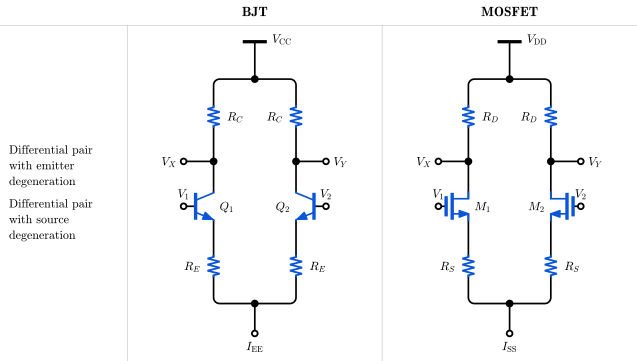

In [6]:
# HIDE/SHOW
show(C.pair_degenerated)

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 47**

| | BJT |
|---|---|
| **Problem** | An npn differential pair has an emitter resistor $R_e$ in each emitter and tail current $I$. With $v_{id}=200\,\mathrm{mV}$, the signal across each $r_e$ is $5\,\mathrm{mV}$. Required: $R_{id}=400\,\mathrm{k}\Omega$, $A_d=v_{od}/v_{id}=10\,\mathrm{V/V}$ (output $2\,\mathrm{V}$), $\beta=100$. Find $R_e$, $r_e$, $I$, $R_C$, and a suitable $V_{CC}$. |
| **Given** | $v_{id}=200\,\mathrm{mV}$, $v_{re}=5\,\mathrm{mV}$, $R_{id}=400\,\mathrm{k}\Omega$, $A_d=10$, $\beta=100$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Signal across $r_e+R_e$.** $v_{id}$ appears across $2r_e+2R_e$, so $r_e+R_e$ has $100\,\mathrm{mV}$. With $5\,\mathrm{mV}$ across $r_e$, $R_e$ has $95\,\mathrm{mV}$: $R_e=19r_e$. |
| **Answer 2** | **Input resistance.** $R_{id}$ $=2(\beta+1)(r_e+R_e)$ $=2\times101\times20r_e$. |
| **Answer 3** | **Find $r_e$.** $400\,\mathrm{k}\Omega$ $=4040\,r_e\Rightarrow r_e$ $=99\,\Omega$ $\approx100\,\Omega$. |
| **Answer 4** | **Bias currents.** $I_E$ $=V_T/r_e$ $=25\,\mathrm{mV}/100\,\Omega$ $=0.25\,\mathrm{mA}$, so $I=0.5\,\mathrm{mA}$. |
| **Answer 5** | **Emitter resistor.** $R_e=19r_e=1.9\,\mathrm{k}\Omega$. |
| **Answer 6** | **Collector resistor.** $A_d$ $=\dfrac{\alpha R_C}{r_e+R_e}$ $\approx\dfrac{R_C}{r_e+R_e}$ $=10\Rightarrow R_C$ $=10\times2\,\mathrm{k}\Omega$ $=20\,\mathrm{k}\Omega$. |
| **Answer 7** | **Supply.** DC drop across $R_C$ is $0.25\,\mathrm{mA}\times20\,\mathrm{k}\Omega$ $=5\,\mathrm{V}$ and each collector swings $\pm1\,\mathrm{V}$; $V_{CC}=10\,\mathrm{V}$ is ample (the common-mode range is not specified). |
| **Result** | $r_e=100\,\Omega$, $R_e=1.9\,\mathrm{k}\Omega$, $I=0.5\,\mathrm{mA}$, $R_C=20\,\mathrm{k}\Omega$, $V_{CC}=10\,\mathrm{V}$ |

**Problem 48**

| | BJT |
|---|---|
| **Problem** | An npn differential amplifier has a $250\,\Omega$ resistor in each emitter, each transistor biased at $I_E=0.1\,\mathrm{mA}$, $\beta=100$ ($\alpha=0.99$). The total resistance between the two collectors is $25\,\mathrm{k}\Omega$. Find the differential gain $v_o/v_i$ and the differential input resistance. |
| **Given** | $R_E=250\,\Omega$ each, $I_E=0.1\,\mathrm{mA}$, $\beta=100$, total collector resistance $25\,\mathrm{k}\Omega$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Emitter resistance.** $r_e$ $=V_T/I_E$ $=25\,\mathrm{mV}/0.1\,\mathrm{mA}$ $=250\,\Omega$. |
| **Answer 2** | **Emitter-side total.** $2r_e+2R_E=500+500=1000\,\Omega$. |
| **Answer 3** | **Gain.** $\dfrac{v_o}{v_i}$ $=\dfrac{\alpha\times25\,\mathrm{k}\Omega}{1000\,\Omega}$ $=24.8$ $\approx25\,\mathrm{V/V}$. |
| **Answer 4** | **Input resistance.** $R_{in}$ $=(\beta+1)(2r_e+2R_E)$ $=101\times1000\,\Omega$ $=101\,\mathrm{k}\Omega$. |
| **Result** | $A_d=24.8\approx25\,\mathrm{V/V}$, $R_{id}=101\,\mathrm{k}\Omega$ |

**Problem 49**

| | BJT |
|---|---|
| **Problem** | An npn pair has tail current $I=200\,\mu\mathrm{A}$ and $V_{BE}=0.69\,\mathrm{V}$ at $1\,\mathrm{mA}$ ($\alpha\approx1$, $V_T=25\,\mathrm{mV}$). (a) Find $V_{BE}$ at balance. (b) Find $i_{C1}$, $i_{C2}$ for $v_{id}=20\,\mathrm{mV}$. (c) An emitter resistor $R_e$ is added in each emitter so that $v_{id}=200\,\mathrm{mV}$ produces the same currents; find $R_e$. (d) By what factor is the transconductance $G_m$ reduced? |
| **Given** | $I=200\,\mu\mathrm{A}$, $V_{BE}(1\,\mathrm{mA})$ $=0.69\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **(a) Balance.** $i_C=100\,\mu\mathrm{A}$ each: $V_{BE}$ $=0.69+0.025\ln(0.1)$ $=0.632\,\mathrm{V}$. |
| **Answer 2** | **(b) Currents.** $i_{C1}$ $=\dfrac{I}{1+e^{-v_{id}/V_T}}$ $=\dfrac{200}{1+e^{-0.8}}$ $=138\,\mu\mathrm{A}$. |
| **Answer 3** | **(b) Other side.** $i_{C2}=200-138=62\,\mu\mathrm{A}$. |
| **Answer 4** | **(c) Same currents.** $v_{BE1},v_{BE2}$ unchanged, so $v_{B1}-v_{B2}$ $=(v_{BE1}-v_{BE2})+R_e(i_{E1}-i_{E2})$. |
| **Answer 5** | **(c) Solve.** $200$ $=20+R_e(138-62)\Rightarrow R_e$ $=\dfrac{180\,\mathrm{mV}}{76\,\mu\mathrm{A}}$ $=2.37\,\mathrm{k}\Omega$. |
| **Answer 6** | **(d) $G_m$ without $R_e$.** $G_m$ $=\dfrac{76\,\mu\mathrm{A}}{20\,\mathrm{mV}}$ $=3.8\,\mathrm{mA/V}$. |
| **Answer 7** | **(d) $G_m$ with $R_e$.** $G_m$ $=\dfrac{76\,\mu\mathrm{A}}{200\,\mathrm{mV}}$ $=0.38\,\mathrm{mA/V}$: reduced by a factor of 10, the same factor by which the input range grew. |
| **Result** | $V_{BE}=0.632\,\mathrm{V}$; $i_C=138,\,62\,\mu\mathrm{A}$; $R_e=2.37\,\mathrm{k}\Omega$; $G_m$ reduced by 10 |

**Problem 50**

| | BJT |
|---|---|
| **Problem** | An npn pair has emitter bias $I_E=0.25\,\mathrm{mA}$ per transistor, an emitter resistor $R_e=400\,\Omega$ in each emitter, collector resistors $R_C=10\,\mathrm{k}\Omega$ and $v_{id}=0.2\,\mathrm{V}$ ($V_T=25\,\mathrm{mV}$, $\alpha\approx1$). Using the small-signal model with $r_e$ at the bias point find (a) $i_e$ and $v_{be}$, (b) the total emitter currents, (c) the collector signal voltages, (d) the voltage gain. |
| **Given** | $I_E=0.25\,\mathrm{mA}$, $R_e=400\,\Omega$, $R_C=10\,\mathrm{k}\Omega$, $v_{id}=0.2\,\mathrm{V}$ |
| **Answer 1** | **(a) $r_e$.** $r_e$ $=25\,\mathrm{mV}/0.25\,\mathrm{mA}$ $=100\,\Omega$. |
| **Answer 2** | **(a) Signal current.** $v_{id}$ appears across $2r_e+2R_e=1000\,\Omega$: $i_e$ $=200\,\mathrm{mV}/1000\,\Omega$ $=0.2\,\mathrm{mA}$. |
| **Answer 3** | **(a) $v_{be}$.** $v_{be}$ $=i_er_e$ $=0.2\times100$ $=20\,\mathrm{mV}$. |
| **Answer 4** | **(b) Emitter currents.** $I_E+i_e=0.45\,\mathrm{mA}$ in one transistor and $I_E-i_e=0.05\,\mathrm{mA}$ in the other. |
| **Answer 5** | **(c) Collector signals.** $\mp i_eR_C$ $=\mp0.2\times10$ $=\mp2\,\mathrm{V}$ at the two collectors. |
| **Answer 6** | **(d) Gain.** $A_d$ $=\dfrac{4\,\mathrm{V}}{0.2\,\mathrm{V}}$ $=20\,\mathrm{V/V}$ $\left(=\dfrac{R_C}{r_e+R_e}\right)$. |
| **Answer 7** | **Caveat.** $i_e$ is 80 % of $I_E$, so the small-signal $r_e$ is only approximate. Solving exactly ($v_{id}$ $=V_T\ln\frac{i_{E1}}{i_{E2}}+2R_ex$ with $i_{E1,2}=0.25\pm x$) gives $x=0.19\,\mathrm{mA}$, a collector swing of about $\pm1.9\,\mathrm{V}$ and a gain of about 19. |
| **Result** | $i_e=0.2\,\mathrm{mA}$, $v_{be}=20\,\mathrm{mV}$, emitter currents $0.45$ and $0.05\,\mathrm{mA}$, collector signals $\pm2\,\mathrm{V}$, $A_d=20\,\mathrm{V/V}$ |

**Problem 51**

| | BJT |
|---|---|
| **Problem** | A BJT differential pair with an emitter resistor $R_e$ in each emitter and a collector resistor $R_C$ in each collector is biased by an ideal tail current $I$. The design requires the voltage drop across each emitter resistor to be $3V_T$ (that is, $\tfrac I2R_e=3V_T$) and the dc voltage drop across each collector resistor to be $80V_T$ (that is, $\alpha\tfrac I2R_C=80V_T$). Find $R_e$, $R_C$ and the differential gain $A_d$. |
| **Given** | $\tfrac I2R_e=3V_T$, $\alpha\tfrac I2R_C=80V_T$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Emitter resistor.** $R_e=\dfrac{6V_T}{I}$ |
| **Answer 2** | **Collector resistor.** $R_C=\dfrac{160V_T}{\alpha I}$ |
| **Answer 3** | **Emitter resistance.** $r_e$ $=\dfrac{V_T}{I/2}$ $=\dfrac{2V_T}{I}$ |
| **Answer 4** | **Gain formula.** $A_d$ $=\dfrac{\alpha\,(2R_C)}{2r_e+2R_e}$ $=\dfrac{\alpha R_C}{r_e+R_e}$ |
| **Answer 5** | **Substitute.** $A_d$ $=\dfrac{\alpha\,(160V_T/\alpha I)}{2V_T/I+6V_T/I}$ $=\dfrac{160}{2+6}$ $=20\,\mathrm{V/V}$ for any $I$ |
| **Result** | $R_e=6V_T/I$, $R_C=160V_T/(\alpha I)$, $A_d=20\,\mathrm{V/V}$ |
````
`````

### Other Circuits

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 52**

| | BJT |
|---|---|
| **Problem** | An npn pair $Q_1,Q_2$ with an ideal tail source has pnp loads $Q_3,Q_4$ (fixed base voltage $V_b$) and two equal resistors $R_1=R_2$ connected in series between the two output nodes. Find the differential gain for finite $V_A$; the circuit is symmetric. |
| **Given** | $g_{m1}$, $r_{O1}$, $r_{O3}$, $R_1=R_2$ |
| **Answer 1** | **Virtual ground.** For equal and opposite output swings the junction of $R_1$ and $R_2$ stays at constant voltage, i.e. it is an ac ground. |
| **Answer 2** | **Half circuit.** Each half is a CE stage $Q_1$ with collector load: $r_{O1}$, the pnp source output resistance $r_{O3}$, and $R_1$ to ground. |
| **Answer 3** | **Resistance at the collector.** $R_{out}$ $=r_{O1}\parallel r_{O3}\parallel R_1$. |
| **Answer 4** | **Gain.** $A_v$ $=-g_{m1}R_{out}$ $=-g_{m1}(r_{O1}\parallel r_{O3}\parallel R_1)$. |
| **Answer 5** | **Check with full two-node analysis.** Solving the two collector-node equations with antisymmetric drive reproduces this value. |
| **Result** | $A_v$ $=-g_{m1}(r_{O1}\parallel r_{O3}\parallel R_1)$ |

**Problem 53**

| | BJT |
|---|---|
| **Problem** | An npn pair $Q_1,Q_2$ with an ideal tail source has pnp loads $Q_3,Q_4$ whose bases are joined at a node X; resistors $R_1$ and $R_2$ run from the collectors of $Q_3$ and $Q_4$ to X, and the outputs are taken at those collectors (the structure of the published solution figure). Find the differential gain for finite $V_A$ and small differential inputs and outputs. |
| **Given** | $g_{m1}$, $r_{O1}$, $r_{O3}$, $R_1=R_2$ |
| **Answer 1** | **Node X for differential signals.** $V_X$ is set by the common-mode (the resistors average the two collectors). For small antisymmetric swings it stays constant. |
| **Answer 2** | **Loads as current sources.** Because $V_X$ and the supply are constant, $Q_3$ and $Q_4$ have constant $V_{EB}$ and act only as output resistances $r_{O3}$, $r_{O4}$. |
| **Answer 3** | **Half circuit.** The same half circuit as in Problem 52: $Q_1$ with $r_{O1}$, $r_{O3}$ and $R_1$ (to the grounded X) at the collector. |
| **Answer 4** | **Gain.** $A_v$ $=-g_{m1}(r_{O1}\parallel r_{O3}\parallel R_1)$. |
| **Answer 5** | **Check.** A three-node small-signal solution (collectors and X, with $r_\pi$ of the loads) gives $v_X=0$ and the same gain. |
| **Result** | $A_v$ $=-g_{m1}(r_{O1}\parallel r_{O3}\parallel R_1)$ |

**Problem 54**

| | BJT |
|---|---|
| **Problem** | Find the differential gain of two degenerated pairs with $V_A=\infty$: (a) a resistor $R_E$ in each emitter with one tail source $I_{EE}$ at their junction P; (b) one resistor $R_E$ between the two emitters, each emitter having its own source $I_{EE}$ to ground. Collector resistors are $R_C$. |
| **Given** | $R_C$, $R_E$, $g_m$, $V_A=\infty$ |
| **Answer 1** | **(a) Virtual ground.** The circuit is symmetric, so for differential inputs node P does not move: it is a virtual ground. |
| **Answer 2** | **(a) Half circuit.** Each side is a CE stage with $R_E$ from emitter to ground; $A_v=-\dfrac{R_C}{R_E+1/g_m}$. |
| **Answer 3** | **(b) Virtual ground.** Split $R_E$ into two $R_E/2$ units; the midpoint lies on the axis of symmetry and is a virtual ground. |
| **Answer 4** | **(b) Half circuit.** Each side has $R_E/2$ in its emitter: $A_v=-\dfrac{R_C}{R_E/2+1/g_m}$. |
| **Answer 5** | **Compare.** The two circuits have equal gain if (b) uses a total resistance $2R_E$ (i.e. $R_E$ per side as in (a)). |
| **Result** | (a) $A_v=-\dfrac{R_C}{R_E+1/g_m}$; (b) $A_v=-\dfrac{R_C}{R_E/2+1/g_m}$ |

**Problem 55**

| | BJT |
|---|---|
| **Problem** | An npn pair $Q_1$, $Q_2$ (tail $I_{EE}=2\,\mathrm{mA}$) is loaded by pnp transistors $Q_3$, $Q_4$ with emitters at $V_{CC}$ and bases tied together at node $X$; $R_1$ connects the collector of $Q_3$ (output node of $Q_1$) to $X$ and $R_2$ connects $X$ to the collector of $Q_4$, with $R_1=R_2$. $V_{A,n}=5\,\mathrm{V}$, $V_{A,p}=4\,\mathrm{V}$. Find $R_1=R_2$ for a differential gain of 50. |
| **Given** | $I_{EE}=2\,\mathrm{mA}$, $V_{A,n}=5\,\mathrm{V}$, $V_{A,p}=4\,\mathrm{V}$, $\lvert A_v\rvert=50$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Node $X$ for differential signals.** By symmetry the two outputs move in opposite directions, so the midpoint $X$ of $R_1$, $R_2$ (and the bases of $Q_3$, $Q_4$) stays at ac ground |
| **Answer 2** | **Half circuit.** $Q_3$ has its base and emitter at ac ground, so it is just $r_{O3}$; the output node sees $r_{O1}\parallel r_{O3}\parallel R_1$: $A_v$ $=-g_m(r_{O1}\parallel r_{O3}\parallel R_1)$ |
| **Answer 3** | **Bias values.** $I_C=1\,\mathrm{mA}$: $g_m=38.5\,\mathrm{mS}$, $r_{O1}=5\,\mathrm{k}\Omega$, $r_{O3}=4\,\mathrm{k}\Omega$, $r_{O1}\parallel r_{O3}$ $=2.22\,\mathrm{k}\Omega$ |
| **Answer 4** | **Required load.** $r_{O1}\parallel r_{O3}\parallel R_1$ $=50/g_m$ $=1.30\,\mathrm{k}\Omega$ |
| **Answer 5** | **Solve for $R_1$.** $\dfrac{1}{R_1}$ $=\dfrac{1}{1.30\,\mathrm{k}\Omega}-\dfrac{1}{2.22\,\mathrm{k}\Omega}\Rightarrow R_1$ $=R_2$ $=3.13\,\mathrm{k}\Omega$ |
| **Answer 6** | **Check.** Nodal analysis of the full circuit (with $\beta=100$) gives a gain of $50.0$ and zero signal at $X$ and $P$ |
| **Result** | $R_1=R_2=3.13\,\mathrm{k}\Omega$ |

**Problem 56**

| | BJT |
|---|---|
| **Problem** | The pair (npn $Q_1$, $Q_2$; pnp loads $Q_3$, $Q_4$ with bases joined at $X$; $R_1$ and $R_2$ from the two outputs to $X$) has $R_1=R_2=5\,\mathrm{k}\Omega$, $V_{A,n}=5\,\mathrm{V}$, $V_{A,p}=4\,\mathrm{V}$. Find the tail current $I_{EE}$ that gives a differential gain of 50. |
| **Given** | $R_1=R_2=5\,\mathrm{k}\Omega$, $V_{A,n}=5\,\mathrm{V}$, $V_{A,p}=4\,\mathrm{V}$, $\lvert A_v\rvert=50$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Gain.** As in Problem 55, $X$ is an ac ground: $\lvert A_v\rvert$ $=g_m(r_{O1}\parallel r_{O3}\parallel R_1)$ |
| **Answer 2** | **In terms of $I_C$.** With $g_m=I_C/V_T$, $r_{O1}=V_{A,n}/I_C$, $r_{O3}=V_{A,p}/I_C$: $\dfrac{1}{\lvert A_v\rvert}$ $=\dfrac{1}{g_mR_1}+\dfrac{V_T}{V_{A,n}}+\dfrac{V_T}{V_{A,p}}$ |
| **Answer 3** | **Substitute.** $\dfrac{1}{g_mR_1}$ $=0.02-0.0052-0.0065$ $=0.0083\Rightarrow g_mR_1$ $=120$ |
| **Answer 4** | **Collector current.** $g_m$ $=120/5\,\mathrm{k}\Omega$ $=24.1\,\mathrm{mS}$, $I_C=g_mV_T=0.627\,\mathrm{mA}$ |
| **Answer 5** | **Tail current.** $I_{EE}=2I_C=1.25\,\mathrm{mA}$ |
| **Answer 6** | **Check.** $r_{O1}=7.98\,\mathrm{k}\Omega$, $r_{O3}=6.38\,\mathrm{k}\Omega$, $r_{O1}\parallel r_{O3}\parallel R_1$ $=2.08\,\mathrm{k}\Omega$, $g_m\times2.08\,\mathrm{k}\Omega$ $=50.0$ |
| **Result** | $I_{EE}=1.25\,\mathrm{mA}$ ($I_C=0.627\,\mathrm{mA}$ per side) |

**Problem 57**

| | BJT |
|---|---|
| **Problem** | Four symmetric npn pairs $Q_1$, $Q_2$ with an ideal tail source $I_{EE}$ at node $P$ and finite Early voltage; find the differential gain of each. (a) Loads: pnp $Q_3$, $Q_4$ with emitters at $V_{CC}$ and collectors at the outputs (collectors of $Q_1$, $Q_2$); the base of $Q_3$ is returned to its own collector through $R_1$ (and $Q_4$ through $R_2$). (b) Loads $R_C$ to $V_{CC}$, plus $R_1$ ($R_2$) connected from collector to emitter of $Q_1$ ($Q_2$), i.e. from each output to $P$. (c) NPN $Q_3$ ($Q_4$) with collector at $V_{CC}$ and emitter on the collector of $Q_1$ ($Q_2$); its base is tied to $V_{CC}$ through $R_1$ ($R_2$) and the outputs are taken at the bases of $Q_3$, $Q_4$. (d) NPN $Q_3$ ($Q_4$) with collector at $V_{CC}$, base to $V_{CC}$ through $R_1$ ($R_2$), emitter on the collector of $Q_1$ ($Q_2$), outputs at the collectors of $Q_1$, $Q_2$. $R_1=R_2$. |
| **Given** | Perfect symmetry, $R_1=R_2$, $V_A<\infty$; $g_m$, $r_\pi$, $r_O$, $\beta$ of each device at its bias point |
| **Answer 1** | **Virtual ground.** In every circuit the two halves are identical and the inputs are differential, so $P$ (and any midpoint of the symmetry) is an ac ground; each gain is $A_v=-g_{m1}R_{X}$, with $R_X$ the total resistance at the output node of the half circuit (or $-G_mR_{out}$ where the output is not at the collector of $Q_1$) |
| **Answer 2** | **(a) Load seen at the collector of $Q_3$.** Drive the node with $v_x$: the base of $Q_3$ is at $v_b=v_x\,r_{\pi3}/(R_1+r_{\pi3})$, and the current drawn is $g_{m3}v_b+v_b/r_{\pi3}+v_x/r_{O3}$, so $R_{load}$ $=r_{O3}\parallel\dfrac{R_1+r_{\pi3}}{\beta+1}$ (a "diode" with a base resistor) |
| **Answer 3** | **(a) Gain.** $A_v$ $=-g_{m1}\left[r_{O1}\parallel r_{O3}\parallel\dfrac{R_1+r_{\pi3}}{\beta+1}\right]$, about $-g_{m1}/g_{m3}\approx-1$ when $R_1\ll r_{\pi3}$ |
| **Answer 4** | **(b) Gain.** $R_1$ sits between the output and the ac-grounded $P$, in parallel with $r_{O1}$ and $R_C$: $A_v$ $=-g_{m1}(R_C\parallel R_1\parallel r_{O1})$, where $g_{m1}=I_{C1}/V_T$ and $I_{C1}=I_{EE}/2-V_{CE1}/R_1$ because $R_1$ takes part of the tail current |
| **Answer 5** | **(c) Node equations.** Output $v_B$ at the base of $Q_3$, $v_E$ at the collector of $Q_1$. Base: $\dfrac{v_B}{R_1}+\dfrac{v_B-v_E}{r_{\pi3}}$ $=0\Rightarrow v_E$ $=v_B\left(1+\dfrac{r_{\pi3}}{R_1}\right)$. Node $E$: $(\beta+1)\dfrac{v_B-v_E}{r_{\pi3}}-\dfrac{v_E}{r_{O3}}$ $=g_{m1}v_{in1}+\dfrac{v_E}{r_{O1}}$ |
| **Answer 6** | **(c) Gain.** $A_v$ $=\dfrac{v_B}{v_{in1}}$ $=-\dfrac{g_{m1}R_1(r_{O1}\parallel r_{O3})}{R_1+r_{\pi3}+(\beta+1)(r_{O1}\parallel r_{O3})}$ $\approx-\dfrac{g_{m1}R_1}{\beta+1}$: only the base current of $Q_3$ reaches $R_1$, so the gain is small |
| **Answer 7** | **(c) As $G_mR_{out}$.** Equivalently $A_v=-G_mR_{out}$ with $R_{out}$ $=R_1\parallel[r_{\pi3}+(\beta+1)(r_{O1}\parallel r_{O3})]$ and $G_m$ $=g_{m1}(r_{O1}\parallel r_{O3})/[r_{\pi3}+(\beta+1)(r_{O1}\parallel r_{O3})]$ |
| **Answer 8** | **(d) Load seen at the emitter of $Q_3$.** Looking into the emitter of a follower whose base has $R_1$ to ac ground: $\dfrac{R_1+r_{\pi3}}{\beta+1}\parallel r_{O3}$ |
| **Answer 9** | **(d) Gain.** $A_v$ $=-g_{m1}\left[r_{O1}\parallel r_{O3}\parallel\dfrac{R_1+r_{\pi3}}{\beta+1}\right]$, the same as (a) |
| **Answer 10** | **Check.** Nodal analysis of each full circuit with $g_m=19.2\,\mathrm{mS}$, $\beta=100$, $r_{O1}=10\,\mathrm{k}\Omega$, $r_{O3}=8\,\mathrm{k}\Omega$, $R_1=2\,\mathrm{k}\Omega$, $R_C=1\,\mathrm{k}\Omega$ gives $-1.35$, $-12.0$, $-0.375$, $-1.35$, matching the formulas |
| **Result** | (a) and (d): $A_v$ $=-g_{m1}\left[r_{O1}\parallel r_{O3}\parallel\dfrac{R_1+r_{\pi3}}{\beta+1}\right]$; (b) $A_v$ $=-g_{m1}(R_C\parallel R_1\parallel r_{O1})$; (c) $A_v$ $=-\dfrac{g_{m1}R_1(r_{O1}\parallel r_{O3})}{R_1+r_{\pi3}+(\beta+1)(r_{O1}\parallel r_{O3})}$ |

**Problem 58**

| | BJT |
|---|---|
| **Problem** | Each npn input transistor $Q_1$, $Q_2$ has its own tail current source $I_{EE}$ from its emitter to ground, and a resistor $R_E$ connects the two emitters. The collector of $Q_1$ ($Q_2$) goes through $R_C$ to the emitter of the diode-connected npn $Q_3$ ($Q_4$), whose base and collector are at $V_{CC}$; the output is taken between the collectors of $Q_1$, $Q_2$. $V_A=\infty$, perfect symmetry. (a) Find the differential gain. (b) Find the condition that makes the gain independent of the tail currents. |
| **Given** | Symmetric, $V_A=\infty$, each side biased at $I_C\approx I_{EE}$, $\beta\gg1$ |
| **Answer 1** | **Half circuit.** For differential inputs the midpoint of $R_E$ is an ac ground, so each half is a common-emitter stage degenerated by $R_E/2$ |
| **Answer 2** | **Load of each half.** The emitter of the diode-connected $Q_3$ presents $\dfrac{1}{g_{m3}}\parallel r_{\pi3}$ $\approx\dfrac{1}{g_{m3}}$, in series with $R_C$: $R_{load}=R_C+\dfrac{1}{g_{m3}}$ |
| **Answer 3** | **(a) Gain.** $A_v$ $=-\dfrac{R_C+1/g_{m3}}{R_E/2+1/g_{m1}}$ |
| **Answer 4** | **Equal transconductances.** $Q_3$ carries the collector current of $Q_1$, so $g_{m1}=g_{m3}=g_m=I_{EE}/V_T$: $A_v=-\dfrac{g_mR_C+1}{g_mR_E/2+1}$ |
| **Answer 5** | **(b) Independence.** $\dfrac{dA_v}{dg_m}\propto\dfrac{R_E/2-R_C}{(g_mR_E/2+1)^2}$, which vanishes for every $g_m$ only if $R_C=R_E/2$ |
| **Answer 6** | **(b) Result.** Then $A_v=-1$ exactly, whatever $I_{EE}$; the nonlinear $V_{BE}$ of $Q_1$ is cancelled by that of $Q_3$, which carries the same current, so the gain does not change with signal level |
| **Answer 7** | **Check.** With $g_m=38.5\,\mathrm{mS}$, $R_C=1\,\mathrm{k}\Omega$, $R_E=500\,\Omega$ nodal analysis gives $-3.72$; with $R_E=2R_C$ it gives $-1.00$ at $I_{EE}=1$ and $0.2\,\mathrm{mA}$ |
| **Result** | (a) $A_v$ $=-\dfrac{R_C+1/g_m}{R_E/2+1/g_m}$; (b) $R_E=2R_C$, giving $A_v=-1$ independent of $I_{EE}$ |

**Problem 59**

| | BJT |
|---|---|
| **Problem** | Two symmetric bipolar pairs with $R_C$ loads to $V_{CC}$, output between the collectors, finite $V_A$. (a) Each emitter goes through its own $R_E$ to the common node $P$, and $P$ goes to ground through $R_{SS}$. (b) The same, plus a resistor $R_1$ ($R_2=R_1$) from the collector to the emitter of $Q_1$ ($Q_2$), i.e. across each transistor, above its $R_E$. Find the differential gain of each, possibly as $A_v=-G_mR_{out}$. |
| **Given** | Symmetric, $R_1=R_2$, $V_A<\infty$; $g_m$, $r_\pi$, $r_O$, $\beta$ at the bias point |
| **Answer 1** | **Virtual ground.** For differential inputs $P$ is an ac ground, so $R_{SS}$ carries no signal; each half is a common-emitter stage with $R_E$ to ground and $R_C$ load |
| **Answer 2** | **(a) Transconductance.** Output shorted, emitter node $v_E$: $(v_{in}-v_E)\left(g_m+\dfrac{1}{r_\pi}\right)$ $=v_E\left(\dfrac{1}{R_E}+\dfrac{1}{r_O}\right)$ and $i_{out}$ $=g_m(v_{in}-v_E)-\dfrac{v_E}{r_O}$, giving $G_m$ $=\dfrac{\beta r_O-R_E}{(\beta+1)R_Er_O+r_\pi(r_O+R_E)}$ $\approx\dfrac{g_m}{1+g_mR_E}$ |
| **Answer 3** | **(a) Output resistance.** $R_{out}$ $=[1+g_m(R_E\parallel r_\pi)]r_O+R_E\parallel r_\pi$ |
| **Answer 4** | **(a) Gain.** $A_v=-G_m(R_C\parallel R_{out})$, which reduces to $-\dfrac{g_mR_C}{1+g_mR_E}$ for $r_O\to\infty$ |
| **Answer 5** | **(b) Observation.** $R_1$ connects collector and emitter of $Q_1$, exactly in parallel with $r_O$; the small-signal half circuit is that of (a) with $r_O$ replaced by $r_O^{\prime}=r_O\parallel R_1$ |
| **Answer 6** | **(b) Gain.** $A_v$ $=-G_m^{\prime}(R_C\parallel R_{out}^{\prime})$ with $G_m^{\prime}$ $=\dfrac{\beta r_O^{\prime}-R_E}{(\beta+1)R_Er_O^{\prime}+r_\pi(r_O^{\prime}+R_E)}$, $R_{out}^{\prime}$ $=[1+g_m(R_E\parallel r_\pi)]r_O^{\prime}+R_E\parallel r_\pi$ |
| **Answer 7** | **Check.** With $g_m=19.2\,\mathrm{mS}$, $\beta=100$, $r_O=10\,\mathrm{k}\Omega$, $R_E=200\,\Omega$, $R_C=2\,\mathrm{k}\Omega$, $R_{SS}=3\,\mathrm{k}\Omega$, $R_1=5\,\mathrm{k}\Omega$, nodal analysis of the full circuits gives $-7.52$ (a) and $-6.90$ (b), equal to the formulas |
| **Result** | (a) $A_v=-G_m(R_C\parallel R_{out})$, $G_m$ $=\dfrac{\beta r_O-R_E}{(\beta+1)R_Er_O+r_\pi(r_O+R_E)}$, $R_{out}$ $=[1+g_m(R_E\parallel r_\pi)]r_O+R_E\parallel r_\pi$; (b) the same with $r_O\to r_O\parallel R_1$ |

**Problem 60**

| | BJT |
|---|---|
| **Problem** | The circuit: npn pair $Q_1$, $Q_2$ with collector resistors $R_C$ to $V_{CC}=2.5\,\mathrm{V}$; each emitter has its own ideal current source $I_{EE}$ to ground, and a resistor $R_E$ connects the two emitters. Design the circuit for a differential gain of 5 and a power budget of 4 mW, such that the gain changes by less than 2% when the collector current changes by 10% (a 10% change of $I_C$ gives a 10% change of $g_m$). $V_A=\infty$. |
| **Given** | $\lvert A_v\rvert=5$, $P=4\,\mathrm{mW}$, $V_{CC}=2.5\,\mathrm{V}$, $\Delta I_C/I_C=\pm10\%$, $\Delta A_v/A_v<2\%$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Currents.** Total supply current $2I_{EE}$ $=4\,\mathrm{mW}/2.5\,\mathrm{V}$ $=1.6\,\mathrm{mA}$: $I_{EE}=I_C=0.8\,\mathrm{mA}$, $g_m=30.8\,\mathrm{mS}$, $1/g_m=32.5\,\Omega$ |
| **Answer 2** | **Half circuit.** The midpoint of $R_E$ is a virtual ground: $\lvert A_v\rvert$ $=\dfrac{R_C}{1/g_m+R_E/2}$ $=\dfrac{g_mR_C}{1+x}$ with $x=g_mR_E/2$ |
| **Answer 3** | **Sensitivity.** If $g_m\to a\,g_m$: $\dfrac{A_v^{\prime}}{A_v}$ $=\dfrac{a(1+x)}{1+ax}$. For $a=0.9$, $\ge0.98$ needs $x\ge4.44$; for $a=1.1$, $\le1.02$ needs $x\ge3.64$. |
| **Answer 4** | **Choose $R_E$.** Take $x=5$ for margin: $R_E/2=5/g_m=162.5\,\Omega$, $R_E=325\,\Omega$ |
| **Answer 5** | **Choose $R_C$.** $R_C$ $=5\,(1/g_m+R_E/2)$ $=5\times195\,\Omega$ $=975\,\Omega$ |
| **Answer 6** | **Check sensitivity.** $I_C$ $-10\%$: $A_v=4.91$ ($-1.8\%$); $I_C$ $+10\%$: $A_v=5.08$ ($+1.5\%$); both under 2%. |
| **Answer 7** | **Check headroom.** $R_E$ carries no dc current; $V_C$ $=2.5-0.8\,\mathrm{mA}\times975\,\Omega$ $=1.72\,\mathrm{V}$, so an input CM up to about 1.7 V keeps the transistors active. |
| **Result** | $I_{EE}=0.8\,\mathrm{mA}$ (each), $R_E=325\,\Omega$, $R_C=975\,\Omega$; gain 5 within $\pm2\%$ |

**Problem 61**

| | BJT |
|---|---|
| **Problem** | The circuit: npn pair $Q_1$, $Q_2$ with ideal tail $I_{EE}$ at node $P$; pnp loads $Q_3$, $Q_4$ with emitters at $V_{CC}$ and bases tied together; resistor $R_1$ runs from the collector of $Q_3$ to the joined bases and $R_2=R_1$ from the collector of $Q_4$ to the same node. The output is taken between the two collectors. Design for a gain of 100 and a power budget of 1 mW with $V_{A,n}=10\,\mathrm{V}$, $V_{A,p}=5\,\mathrm{V}$, $V_{CC}=2.5\,\mathrm{V}$. |
| **Given** | $\lvert A_v\rvert=100$, $P=1\,\mathrm{mW}$, $V_{A,n}=10\,\mathrm{V}$, $V_{A,p}=5\,\mathrm{V}$, $V_{CC}=2.5\,\mathrm{V}$, $R_1=R_2$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Currents.** $I_{EE}$ $=1\,\mathrm{mW}/2.5\,\mathrm{V}$ $=0.4\,\mathrm{mA}$, $I_C=0.2\,\mathrm{mA}$ per side, $g_m=7.69\,\mathrm{mS}$ |
| **Answer 2** | **Dc bias.** The bases of $Q_3$, $Q_4$ are fed from both collectors through $R_1$, $R_2$; with small base currents the drop across $R_{1,2}$ is small, so $Q_3$, $Q_4$ act like diode-connected devices for CM and settle to $\lvert I_C\rvert=I_{EE}/2$. |
| **Answer 3** | **Half circuit.** For differential signals the joined bases (midpoint of $R_1+R_2$) are an ac ground, so $Q_3$ is a current source with $r_{O3}$ and $R_1$ goes to ac ground: $\lvert A_v\rvert$ $=g_m(r_{O1}\parallel r_{O3}\parallel R_1)$ |
| **Answer 4** | **Output resistances.** $r_{O1}$ $=10/0.2\,\mathrm{mA}$ $=50\,\mathrm{k}\Omega$, $r_{O3}$ $=5/0.2\,\mathrm{mA}$ $=25\,\mathrm{k}\Omega$, $r_{O1}\parallel r_{O3}$ $=16.7\,\mathrm{k}\Omega$ (gain 128 without $R_1$) |
| **Answer 5** | **Required total.** $r_{O1}\parallel r_{O3}\parallel R_1$ $=100/g_m$ $=13.0\,\mathrm{k}\Omega$ |
| **Answer 6** | **Solve for $R_1$.** $\dfrac1{R_1}$ $=\dfrac1{13.0\,\mathrm{k}\Omega}-\dfrac1{16.7\,\mathrm{k}\Omega}$, $R_1=R_2=59.1\,\mathrm{k}\Omega$ |
| **Result** | $I_{EE}=0.4\,\mathrm{mA}$, $R_1$ $=R_2$ $\approx59.1\,\mathrm{k}\Omega$ |

**Problem 62**

| | BJT |
|---|---|
| **Problem** | An npn differential pair is biased so that each transistor carries an emitter current of $0.2\,\mathrm{mA}$ ($I=0.4\,\mathrm{mA}$, $\alpha\approx1$), with $\beta=160$. Find $g_m$ and the differential input resistance $R_{id}$. |
| **Given** | $I_C=0.2\,\mathrm{mA}$, $\beta=160$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Transconductance.** $g_m$ $=\dfrac{I_C}{V_T}$ $=\dfrac{0.2\,\mathrm{mA}}{25\,\mathrm{mV}}$ $=8\,\mathrm{mA/V}$. |
| **Answer 2** | **Base resistance.** $r_\pi$ $=\dfrac{\beta}{g_m}$ $=\dfrac{160}{8}$ $=20\,\mathrm{k}\Omega$. |
| **Answer 3** | **Differential input resistance.** $R_{id}=2r_\pi=40\,\mathrm{k}\Omega$. |
| **Result** | $g_m=8\,\mathrm{mA/V}$, $R_{id}=40\,\mathrm{k}\Omega$ |

**Problem 63**

| | BJT |
|---|---|
| **Problem** | Two npn differential amplifiers with the same $R_C$: (a) a resistor $R_e$ in each emitter with a single tail current $I$ at the joined lower ends; (b) the emitters joined by a single resistor $2R_e$ and each emitter fed by its own current source $I/2$. Show that both have the same differential half-circuit (with $R_e$ in the emitter, biased at $I/2$), so $A_d=\alpha R_C/(r_e+R_e)$ and $R_{id}=2(\beta+1)(r_e+R_e)$. Compare the dc voltage at the top of the current source(s) at $v_{id}=0$ and say which circuit allows the more negative common-mode input. |
| **Given** | tail $I$ in (a); $I/2$ per side in (b); each transistor carries $I/2$; same $V_{BE}$ |
| **Answer 1** | **Half-circuit.** For differential signals the tail node of (a) and the middle of the bridge resistor of (b) are virtual grounds, so both reduce to one transistor with $r_e$ and $R_e$ in the emitter and $R_C$ in the collector, biased at $I/2$. |
| **Answer 2** | **Gain.** $A_d$ $=\dfrac{v_{od}}{v_{id}}$ $=\dfrac{\alpha R_C}{r_e+R_e}$ (each side gets $v_{id}/2$ and gives $v_{od}/2$). |
| **Answer 3** | **Input resistance.** $R_{id}$ $=(\beta+1)(2r_e+2R_e)$ $=2(\beta+1)(r_e+R_e)$. |
| **Answer 4** | **DC voltage at the source (a).** Each emitter resistor carries $I/2$: $V_X=V_{CM}-V_{BE}-\tfrac I2R_e$. |
| **Answer 5** | **DC voltage at the source (b).** Both emitters are at the same dc voltage, so no dc current flows in the bridge resistor: $V_X=V_{CM}-V_{BE}$. |
| **Answer 6** | **Compare.** (b) leaves more voltage across the current source for a given $V_{CM}$. Since $V_{CM,min}$ is set by the minimum voltage the source needs, (b) allows a $\tfrac I2R_e$ lower (more negative) $V_{CM}$ than (a). |
| **Result** | $A_d=\dfrac{\alpha R_C}{r_e+R_e}$, $R_{id}=2(\beta+1)(r_e+R_e)$; $V_X=V_{CM}-V_{BE}-\tfrac I2R_e$ in (a), $V_{CM}-V_{BE}$ in (b); (b) allows a more negative $V_{CM}$ |

**Problem 64**

| | BJT |
|---|---|
| **Problem** | An npn differential amplifier is driven through a source resistance $R_{sig}=100\,\mathrm{k}\Omega$ (total, differential). Each transistor has $I_C=0.2\,\mathrm{mA}$ and $\beta=100$. Each collector has $R_C=20\,\mathrm{k}\Omega$, and a load $R_L=40\,\mathrm{k}\Omega$ is connected between the collectors. Find $R_{id}$ and the overall gain $G_v=v_{od}/v_{sig}$. |
| **Given** | $I_C=0.2\,\mathrm{mA}$, $\beta=100$, $R_{sig}=100\,\mathrm{k}\Omega$, $R_C=20\,\mathrm{k}\Omega$, $R_L=40\,\mathrm{k}\Omega$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Transconductance.** $g_m$ $=I_C/V_T$ $=0.2/0.025$ $=8\,\mathrm{mA/V}$. |
| **Answer 2** | **Input resistance.** $R_{id}$ $=2r_\pi$ $=2\beta/g_m$ $=2\times100/8$ $=25\,\mathrm{k}\Omega$. |
| **Answer 3** | **Load seen between collectors.** $2R_C\parallel R_L$ $=40\parallel40$ $=20\,\mathrm{k}\Omega$. |
| **Answer 4** | **Differential gain.** $A_d$ $=\tfrac12g_m(2R_C\parallel R_L)$ $=\tfrac12\times8\times20$ $=80\,\mathrm{V/V}$. |
| **Answer 5** | **Source division.** $\dfrac{R_{id}}{R_{id}+R_{sig}}$ $=\dfrac{25}{125}$ $=0.2$. |
| **Answer 6** | **Overall gain.** $G_v=0.2\times80=16\,\mathrm{V/V}$. |
| **Result** | $R_{id}=25\,\mathrm{k}\Omega$, $G_v=16\,\mathrm{V/V}$ |

**Problem 65**

| | BJT |
|---|---|
| **Problem** | A BJT differential amplifier has an emitter resistor $R_e$ in each emitter and collector resistors $R_C$, tail current $I$. It is driven by a differential source $v_{sig}$ whose internal resistance is $R_{sig}$ (split as $R_{sig}/2$ in each base lead, $v_{sig}/2$ on each side). Find (a) $G_v=v_{od}/v_{sig}$; (b) $G_v$ if $R_{sig}$ equals the differential input resistance $R_{id}$; (c) $G_v$ if $\beta$ is doubled with $R_{sig}$ kept at the value of (b). |
| **Given** | $R_{sig}$, $R_e$, $R_C$, $\beta$, $r_e$ symbolic |
| **Answer 1** | **(a) Input divider.** $R_{id}=(\beta+1)(2r_e+2R_e)$, so $\dfrac{v_{id}}{v_{sig}}$ $=\dfrac{R_{id}}{R_{id}+R_{sig}}$ $=\dfrac{2(\beta+1)(r_e+R_e)}{2(\beta+1)(r_e+R_e)+R_{sig}}$ |
| **Answer 2** | **(a) Differential gain.** $\dfrac{v_{od}}{v_{id}}$ $=\dfrac{\alpha\,2R_C}{2r_e+2R_e}$ $=\dfrac{\alpha R_C}{r_e+R_e}$ |
| **Answer 3** | **(a) Product.** Using $\alpha(\beta+1)=\beta$: $G_v$ $=\dfrac{2\beta R_C}{2(\beta+1)(r_e+R_e)+R_{sig}}$ |
| **Answer 4** | **(b) $R_{sig}=R_{id}$.** Then $v_{id}=v_{sig}/2$: $G_v$ $=\dfrac{2\beta R_C}{4(\beta+1)(r_e+R_e)}$ $=\dfrac12\dfrac{\alpha R_C}{r_e+R_e}$ |
| **Answer 5** | **(c) beta doubled.** Replace $\beta\to2\beta$ and $R_{sig}=2(\beta+1)(r_e+R_e)$: $G_v$ $=\dfrac{4\beta R_C}{[2(2\beta+1)+2(\beta+1)](r_e+R_e)}$ $=\dfrac{4\beta}{6\beta+4}\dfrac{R_C}{r_e+R_e}$ |
| **Answer 6** | **(c) Large beta.** For $\beta\gg1$: $G_v$ $\approx\dfrac23\dfrac{R_C}{r_e+R_e}$. The gain rises from about $\tfrac12$ to $\tfrac23$ of $R_C/(r_e+R_e)$. |
| **Result** | (a) $G_v$ $=\dfrac{2\beta R_C}{2(\beta+1)(r_e+R_e)+R_{sig}}$; (b) $\approx\tfrac12R_C/(r_e+R_e)$; (c) $\approx\tfrac23R_C/(r_e+R_e)$ |

**Problem 66**

| | BJT |
|---|---|
| **Problem** | In a BJT pair the base of $Q_1$ is the input $v_i$, the base of $Q_2$ is grounded, the collector of $Q_1$ is at $V_{CC}$, $Q_2$ has collector resistor $R_C$ and the output $v_o$ is at the $Q_2$ collector; the emitters are joined and fed by an ideal tail current $I$ (each transistor at $I/2$). (a) Find $v_o/v_i$ treating the circuit as a differential amplifier. (b) Re-derive it as an emitter follower $Q_1$ driving a common-base stage $Q_2$. |
| **Given** | $R_C$, $\alpha$, $r_e=V_T/(I/2)$ symbolic; $Q_1$ and $Q_2$ both at $I/2$ |
| **Answer 1** | **(a) Differential view.** Gain $=\alpha\times\dfrac{\text{resistance in collector}}{\text{resistance in emitter circuit}}$ $=\dfrac{\alpha R_C}{r_{e1}+r_{e2}}$ $=\dfrac{\alpha R_C}{2r_e}$ |
| **Answer 2** | **(b) Follower stage.** $Q_1$ drives the emitter node, which is loaded by the input resistance $r_{e2}$ of $Q_2$: $\dfrac{v_e}{v_i}$ $=\dfrac{r_{e2}}{r_{e1}+r_{e2}}$ $=\dfrac12$ |
| **Answer 3** | **(b) Common-base stage.** $Q_2$ has its emitter at $v_e$ and its base grounded: $\dfrac{v_o}{v_e}$ $=\dfrac{\alpha R_C}{r_{e2}}$ (non-inverting) |
| **Answer 4** | **(b) Cascade.** $\dfrac{v_o}{v_i}$ $=\dfrac12\cdot\dfrac{\alpha R_C}{r_e}$ $=\dfrac{\alpha R_C}{2r_e}$, identical to (a). |
| **Result** | $\dfrac{v_o}{v_i}$ $=\dfrac{\alpha R_C}{2r_e}$ |

**Problem 67**

| | BJT |
|---|---|
| **Problem** | A BJT differential amplifier has a $150\,\Omega$ emitter resistor in each emitter, bias $I_E=0.5\,\mathrm{mA}$ per transistor, collector resistors $R_C=10\,\mathrm{k}\Omega$, a load $R_L=20\,\mathrm{k}\Omega$ connected between the two collectors, and a tail current source of output resistance $R_{EE}=100\,\mathrm{k}\Omega$. The collector resistors have a $2\%$ mismatch; $\beta=100$, $V_A=100\,\mathrm{V}$. Find the differential gain $A_d=v_{od}/v_{id}$, $R_{id}$, $\lvert A_{cm}\rvert$ and $R_{icm}$. |
| **Given** | $R_e=150\,\Omega$, $I_E=0.5\,\mathrm{mA}$, $R_C=10\,\mathrm{k}\Omega$, $R_L=20\,\mathrm{k}\Omega$ (between collectors), $R_{EE}=100\,\mathrm{k}\Omega$, $\Delta R_C/R_C=2\%$, $\beta=100$, $V_A=100\,\mathrm{V}$ |
| **Answer 1** | **Small-signal data.** $I_C\approx0.5\,\mathrm{mA}$, $g_m=20\,\mathrm{mA/V}$, $r_e$ $=\dfrac{25\,\mathrm{mV}}{0.5\,\mathrm{mA}}$ $=50\,\Omega$, $r_o$ $=\dfrac{100}{0.5}$ $=200\,\mathrm{k}\Omega$ |
| **Answer 2** | **Differential half-circuit.** The midpoint of $R_L$ is a virtual ground, so each collector sees $R_C\parallel(R_L/2)$ $=10\parallel10$ $=5\,\mathrm{k}\Omega$, and the emitter has $R_e=150\,\Omega$. |
| **Answer 3** | **Differential gain.** $A_d$ $=\dfrac{\alpha(R_C\parallel R_L/2)}{r_e+R_e}$ $\approx\dfrac{5\,\mathrm{k}\Omega}{0.2\,\mathrm{k}\Omega}$ $=25\,\mathrm{V/V}$ ($r_o$ neglected: it appears as $r_o[1+R_e/r_e]$ $=800\,\mathrm{k}\Omega\gg5\,\mathrm{k}\Omega$) |
| **Answer 4** | **Rid.** $R_{id}$ $=2(\beta+1)(r_e+R_e)$ $=2\times101\times0.2\,\mathrm{k}\Omega$ $=40.4\,\mathrm{k}\Omega$ |
| **Answer 5** | **Common-mode half-circuit.** No current flows in $R_L$ for a common-mode input; each half has $R_C$ in the collector and $2R_{EE}=200\,\mathrm{k}\Omega$ in the emitter. |
| **Answer 6** | **Acm.** $\lvert A_{cm}\rvert\simeq\dfrac{R_C}{2R_{EE}}\dfrac{\Delta R_C}{R_C}$ $=\dfrac{10}{200}\times0.02$ $=0.001\,\mathrm{V/V}$ |
| **Answer 7** | **Ricm.** $R_{icm}\simeq\beta R_{EE}\dfrac{1+R_C/(\beta r_o)}{1+(R_C+2R_{EE})/r_o}$ $=\dfrac{100\times100\times1.0005}{1+210/200}$ $=4.88\,\mathrm{M}\Omega$ |
| **Result** | $A_d=25\,\mathrm{V/V}$, $R_{id}=40.4\,\mathrm{k}\Omega$, $\lvert A_{cm}\rvert=0.001$, $R_{icm}$ $\approx4.88\,\mathrm{M}\Omega$ |

**Problem 68**

| | BJT |
|---|---|
| **Problem** | Design a BJT differential amplifier with a single-ended gain $v_{o1}/v_{id}=-100\,\mathrm{V/V}$ (so $v_{o2}/v_{id}=+100$), a common-mode gain of magnitude $0.1\,\mathrm{V/V}$ to each collector, a differential input resistance $R_{id}=10\,\mathrm{k}\Omega$, tail current $I=2\,\mathrm{mA}$, $\beta=100$, a signal swing of $\pm2\,\mathrm{V}$ at each collector with the input common mode at $0\,\mathrm{V}$ (and room for $V_{ICM}$ up to $+3\,\mathrm{V}$). Find the emitter resistors $R_e$, $R_C$, $V_{CC}$, $R_{EE}$, the Early voltage of a simple-mirror tail source, and $R_{icm}$ (pair transistors with the same $V_A$). |
| **Given** | $v_{o1}/v_{id}=-100$, $\lvert v_o/v_{icm}\rvert=0.1$, $R_{id}=10\,\mathrm{k}\Omega$, $I=2\,\mathrm{mA}$, $\beta=100$, swing $\pm2\,\mathrm{V}$, $V_{ICM,max}=+3\,\mathrm{V}$ |
| **Answer 1** | **Emitter currents.** $I_{E1}=I_{E2}=1\,\mathrm{mA}$, so $r_e$ $=\dfrac{25\,\mathrm{mV}}{1\,\mathrm{mA}}$ $=25\,\Omega$, $g_m=40\,\mathrm{mA/V}$, $r_\pi$ $=\dfrac{\beta}{g_m}$ $=2.5\,\mathrm{k}\Omega$. Since $R_{id}$ $=10\,\mathrm{k}\Omega>2r_\pi$ $=5\,\mathrm{k}\Omega$, emitter resistors are needed. |
| **Answer 2** | **Emitter resistors.** $R_{id}$ $=(\beta+1)(2r_e+2R_e)\Rightarrow r_e+R_e$ $=\dfrac{10\,\mathrm{k}}{2\times101}$ $=49.5\,\Omega$, so $R_e=24.5\,\Omega$ (about $25\,\Omega$) |
| **Answer 3** | **Collector resistor.** $\dfrac{v_{o1}}{v_{id}}$ $=-\dfrac{\alpha R_C}{2(r_e+R_e)}$ $=-100\Rightarrow R_C$ $=\dfrac{100\times2\times0.0495}{0.990}$ $=10\,\mathrm{k}\Omega$ |
| **Answer 4** | **Supply.** To keep a $\pm2\,\mathrm{V}$ swing with the base at $0\,\mathrm{V}$: $V_{CC}-\dfrac I2R_C-2\ge0\Rightarrow V_{CC}\ge10+2$ $=12\,\mathrm V$. Choose $V_{CC}=15\,\mathrm V$: $V_C=5\,\mathrm V$, allowing $V_{ICM}$ up to $5-2=3\,\mathrm V$. |
| **Answer 5** | **Tail resistance.** $\lvert A_{cm}\rvert$ $=\dfrac{R_C}{2R_{EE}}$ $=0.1\Rightarrow R_{EE}$ $=\dfrac{10}{0.2}$ $=50\,\mathrm{k}\Omega$ (minimum) |
| **Answer 6** | **Mirror tail source.** Simple mirror: $R_{EE}=r_o=\dfrac{V_A}{I}$, so $V_A=50\times2=100\,\mathrm V$ |
| **Answer 7** | **Common-mode input resistance.** Pair transistors: $r_o$ $=\dfrac{100}{1\,\mathrm{mA}}$ $=100\,\mathrm{k}\Omega$. $R_{icm}\simeq\beta R_{EE}\dfrac{1+R_C/(\beta r_o)}{1+(R_C+2R_{EE})/r_o}$ $=\dfrac{100\times50\times1.001}{1+110/100}$ $\approx2.4\,\mathrm{M}\Omega$ |
| **Result** | $R_e\approx25\,\Omega$ (24.5), $R_C=10\,\mathrm{k}\Omega$, $V_{CC}=15\,\mathrm V$, $R_{EE}=50\,\mathrm{k}\Omega$, $V_A=100\,\mathrm V$, $R_{icm}$ $\approx2.4\,\mathrm{M}\Omega$ |

**Problem 69**

| | BJT |
|---|---|
| **Problem** | A BJT differential pair has an emitter resistor $R_E$ in each emitter, bias current $I$ and a collector-resistor mismatch $\Delta R_C/R_C$. Show that the input offset voltage is $V_{OS}$ $=\left(V_T+\tfrac12IR_E\right)\dfrac{\Delta R_C}{R_C}$. |
| **Given** | $I$, $R_E$, $\Delta R_C/R_C$ symbolic; $\alpha\approx1$ |
| **Answer 1** | **Output offset.** Each transistor carries $I/2$; $V_O=\alpha\dfrac I2\Delta R_C$ |
| **Answer 2** | **Gain.** With emitter resistors $g_m$ is replaced by $G_m=\dfrac{\alpha}{r_e+R_E}$, so $A_d=G_mR_C$ |
| **Answer 3** | **Divide.** $V_{OS}$ $=\dfrac{V_O}{A_d}$ $=\dfrac{\alpha(I/2)\Delta R_C}{G_mR_C}$ $=\dfrac I2(r_e+R_E)\dfrac{\Delta R_C}{R_C}$ |
| **Answer 4** | **Insert $r_e$.** $r_e=\dfrac{V_T}{I/2}$, so $V_{OS}$ $=\left(V_T+\dfrac I2R_E\right)\dfrac{\Delta R_C}{R_C}$ Q.E.D. |
| **Result** | $V_{OS}$ $=\left(V_T+\tfrac12IR_E\right)\dfrac{\Delta R_C}{R_C}$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 54**

| | MOSFET |
|---|---|
| **Problem** | Assuming $\lambda=0$, find the differential gain of this NMOS circuit. Transistors $M_1$, $M_2$ form a pair whose sources join at node $P$, with an ideal tail source $I_{SS1}$. The drain of $M_1$ ($M_2$) is the output node, fed from $V_{DD}$ by an ideal current source. A diode-connected NMOS $M_3$ ($M_4$) has its drain and gate tied to that same output node and its source at node $Q$; $M_3$ and $M_4$ share the second ideal tail source $I_{SS2}$ at $Q$. The output is taken between the two output nodes; the inputs are applied to the gates of $M_1$, $M_2$. |
| **Given** | $\lambda=0$, $g_{m1}=g_{m2}$, $g_{m3}=g_{m4}$, ideal current sources |
| **Answer 1** | **Virtual grounds.** The circuit is symmetric. For a differential input, the currents of $M_1$ and $M_2$ change oppositely while $I_{SS1}$ is fixed, so $P$ does not move. Likewise $M_3$, $M_4$ share $I_{SS2}$ and $Q$ does not move. Both are ac grounds. |
| **Answer 2** | **Half circuit.** Keep $M_1$ (source grounded, gate $v_{in1}$) and $M_3$ (source grounded, gate and drain at the output node $v_{out1}$). Their drains are joined, and the current source above is ideal (infinite resistance). |
| **Answer 3** | **KCL at the output node.** $g_{m1}v_{in1}+g_{m3}v_{out1}=0$, since the small-signal current of $M_3$ into its source is $g_{m3}v_{GS3}=g_{m3}v_{out1}$ and no other element loads the node. |
| **Answer 4** | **Gain.** $A_v$ $=\dfrac{v_{out1}}{v_{in1}}$ $=-\dfrac{g_{m1}}{g_{m3}}$. The differential gain is the same, since $v_{out}=2v_{out1}$ and $v_{in}=2v_{in1}$ for a differential drive. |
| **Answer 5** | **Numerical check.** $g_{m1}=2\,\mathrm{mS}$, $g_{m3}=0.5\,\mathrm{mS}$: a nodal solution of the whole circuit with $v_{in1}-v_{in2}=1\,\mathrm{V}$ gives $v_{out}=-4.00\,\mathrm{V}$, equal to $-g_{m1}/g_{m3}$. |
| **Result** | $A_v=-\dfrac{g_{m1}}{g_{m3}}$ |

**Problem 55**

| | MOSFET |
|---|---|
| **Problem** | Assuming $\lambda=0$, find the differential gain of this NMOS circuit. The drains of $M_1$ and $M_2$ are fed from $V_{DD}$ by two ideal current sources and are joined by a resistor $R_{DD}$. The sources of $M_1$ and $M_2$ are joined by a resistor $R_{SS}$ and each source has its own ideal current source to ground. Inputs go to the gates; the output is taken between the drains. |
| **Given** | $\lambda=0$, $g_{m1}=g_{m2}=g_m$, resistors $R_{DD}$ (drain to drain), $R_{SS}$ (source to source) |
| **Answer 1** | **Symmetry.** With a differential input the midpoint of $R_{SS}$ and the midpoint of $R_{DD}$ are ac grounds, so each half circuit has $R_{SS}/2$ in the source and $R_{DD}/2$ as the drain load (the current-source loads are ideal). |
| **Answer 2** | **Gain of the half circuit.** This is a degenerated common-source stage: $\dfrac{v_{out1}}{v_{in1}}$ $=-\dfrac{R_{DD}/2}{\dfrac1{g_m}+\dfrac{R_{SS}}2}$. |
| **Answer 3** | **Differential gain.** $v_{out}=2v_{out1}$ and $v_{in}=2v_{in1}$ give the same ratio: $A_v$ $=-\dfrac{R_{DD}/2}{R_{SS}/2+1/g_m}$. |
| **Answer 4** | **Numerical check.** $g_m=2\,\mathrm{mS}$, $R_{DD}=10\,\mathrm{k}\Omega$, $R_{SS}=1\,\mathrm{k}\Omega$: $A_v$ $=-\dfrac{5\,\mathrm{k}\Omega}{0.5\,\mathrm{k}\Omega+0.5\,\mathrm{k}\Omega}$ $=-5.00$; a nodal solution of the full four-node network gives $-5.0000$. |
| **Result** | $A_v$ $=-\dfrac{R_{DD}/2}{R_{SS}/2+1/g_m}$ |

**Problem 56**

| | MOSFET |
|---|---|
| **Problem** | Three NMOS pairs in which each source has its own ideal tail current source to ground and a resistor $R_{SS}$ joins the two sources; inputs $V_{in1}$, $V_{in2}$, output between the drains, symmetric, $\lambda>0$. Loads: (a) NMOS devices $M_3$, $M_4$ with gate and drain both tied to $V_{DD}$ and the source at the output node (diode-connected NMOS), plus a resistor $R_1$ ($R_2=R_1$) from the drain of $M_1$ ($M_2$) to its own source; (b) PMOS current sources $M_3$, $M_4$ with gates at $V_b$; (c) PMOS $M_3$, $M_4$ with gates at $V_b$ and a resistor $R_S$ from each PMOS source to $V_{DD}$. Find the differential voltage gain (the form $A_v=-G_mR_{out}$ may help). |
| **Given** | $\lambda>0$; numeric check: $g_{m1}=2\,\mathrm{mS}$, $g_{m3}=1\,\mathrm{mS}$, $r_{O1}=r_{O3}=20\,\mathrm{k}\Omega$, $R_1=10\,\mathrm{k}\Omega$, $R_{SS}=R_S=2\,\mathrm{k}\Omega$ |
| **Answer 1** | **Half circuit.** The midpoint of $R_{SS}$ is a virtual ground, so $M_1$ sees $R_{SS}/2$ from source to ground; call the load at the drain $R_L$ and everything between drain and source $R_p$ |
| **Answer 2** | **General degenerated stage.** With channel current $i$: $v_X=-iR_L$, $v_S=iR_{SS}/2$ and $i=g_{m1}(v_{in}-v_S)+(v_X-v_S)/R_p$, giving $A_v$ $=-\dfrac{g_{m1}R_LR_p}{R_p+R_L+R_{SS}/2+g_{m1}R_pR_{SS}/2}$, i.e. $-G_mR_{out}$ with $R_{out}$ $=R_L\parallel[R_p+R_{SS}/2+g_{m1}R_pR_{SS}/2]$ |
| **Answer 3** | **(a) Values.** $M_3$ is an NMOS with gate and drain at $V_{DD}$ (ac ground) and its source at the output, so looking into its source $R_L$ $=\dfrac1{g_{m3}}\parallel r_{O3}$; $R_p=r_{O1}\parallel R_1$ ($R_1$ is drain-to-source, in parallel with $r_{O1}$) |
| **Answer 4** | **(a) Gain.** $A_v$ $=-\dfrac{g_{m1}R_LR_p}{R_p+R_L+\frac{R_{SS}}2+g_{m1}R_p\frac{R_{SS}}2}$ $\approx-\dfrac{1/g_{m3}}{1/g_{m1}+R_{SS}/2}$ when $R_p\gg R_L$; numbers: $-0.579$ |
| **Answer 5** | **(b) Values and gain.** $R_L=r_{O3}$, $R_p=r_{O1}$: $A_v$ $=-\dfrac{g_{m1}r_{O1}r_{O3}}{r_{O1}+r_{O3}+\frac{R_{SS}}2+g_{m1}r_{O1}\frac{R_{SS}}2}$; numbers: $-9.88$ |
| **Answer 6** | **(c) Degenerated PMOS load.** Looking into the drain of $M_3$: $R_{op}=(1+g_{m3}R_S)r_{O3}+R_S$ $=62\,\mathrm{k}\Omega$ with the check values |
| **Answer 7** | **(c) Gain.** $R_L=R_{op}$, $R_p=r_{O1}$: $A_v$ $=-\dfrac{g_{m1}r_{O1}R_{op}}{r_{O1}+R_{op}+\frac{R_{SS}}2+g_{m1}r_{O1}\frac{R_{SS}}2}$; numbers: $-20.2$ |
| **Answer 8** | **Check.** A nodal solution of each full circuit (both halves, $R_{SS}$ between the sources) gives the same three numbers |
| **Result** | $A_v$ $=-\dfrac{g_{m1}R_LR_p}{R_p+R_L+R_{SS}/2+g_{m1}R_pR_{SS}/2}$ with (a) $R_L=g_{m3}^{-1}\parallel r_{O3}$, $R_p=r_{O1}\parallel R_1$; (b) $R_L=r_{O3}$, $R_p=r_{O1}$; (c) $R_L=(1+g_{m3}R_S)r_{O3}+R_S$, $R_p=r_{O1}$ |

**Problem 57**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair $Q_1,Q_2$ has each source biased by its own current source $I/2$ and an NMOS $Q_3$ connected between the two sources, with its gate at a dc voltage $V_C$; both inputs are at $0\,\mathrm{V}$, and $Q_{1,2}$ have overdrive $V_{OV1,2}$. $Q_3$ acts as a triode resistor $R_s$ for small signals. (a) Find the dc source voltage. (b) Find $V_{OV3}$ and its dc current. (c) Find $r_{DS}$ of $Q_3$ and $R_s$ in terms of $g_{m1,2}$ and the overdrives when $Q_3$ has the same $W/L$ as $Q_{1,2}$. (d) Find $V_C$ for (i) $R_s=1/g_{m1,2}$ and (ii) $R_s=0.5/g_{m1,2}$. |
| **Given** | $v_{G1}=v_{G2}=0$, a current source $I/2$ at each source, $(W/L)_3=(W/L)_{1,2}$, $Q_3$ gate at $V_C$ |
| **Answer 1** | **(a) Source voltage.** $V_{GS1,2}=V_{OV1,2}+V_{tn}$, so $V_{S1}=V_{S2}=-(V_{OV1,2}+V_{tn})$. |
| **Answer 2** | **(b) $Q_3$ overdrive.** Drain and source of $Q_3$ are at the same voltage, so $V_{DS3}=0$ and no current flows. $V_{OV3}$ $=V_C-V_S-V_{tn}$ $=V_C+V_{OV1,2}$. |
| **Answer 3** | **(c) Triode resistance.** $r_{DS3}$ $=\dfrac{1}{\mu_nC_{ox}(W/L)_3V_{OV3}}$ $=R_s$. |
| **Answer 4** | **(c) Use $g_m$.** $g_{m1,2}$ $=\mu_nC_{ox}(W/L)_{1,2}V_{OV1,2}$; with equal $W/L$, $\mu_nC_{ox}(W/L)_3$ $=g_{m1,2}/V_{OV1,2}$. So $R_s$ $=\dfrac1{g_{m1,2}}\dfrac{V_{OV1,2}}{V_{OV3}}$. |
| **Answer 5** | **(d)(i) $R_s=1/g_m$.** Need $V_{OV3}=V_{OV1,2}$. With $V_{OV3}=V_C+V_{OV1,2}$: $V_C=0$. |
| **Answer 6** | **(d)(ii) $R_s=0.5/g_m$.** Need $V_{OV3}=2V_{OV1,2}$, so $V_C=V_{OV1,2}$. |
| **Result** | $V_S=-(V_{OV1,2}+V_{tn})$; $V_{OV3}=V_C+V_{OV1,2}$; $R_s$ $=\dfrac{1}{g_{m1,2}}\dfrac{V_{OV1,2}}{V_{OV3}}$; $V_C=0$ for $1/g_m$ and $V_C=V_{OV1,2}$ for $0.5/g_m$ |

**Problem 58**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair $Q_1,Q_2$ with drain resistors $R_D$ has each source biased by its own current source $I/2$, and two NMOS transistors $Q_3,Q_4$ in series between the two sources, with their gates grounded. At balance both input gates are at $0\,\mathrm{V}$ dc and $Q_{1,2}$ have overdrive $V_{OV}$. For small $v_{id}$, $Q_3$ and $Q_4$ act as triode resistors. Find $R_s$ (their series resistance) in terms of $g_{m1,2}$ and the $W/L$ ratios, and the differential gain $A_d$. |
| **Given** | gates of $Q_3,Q_4$ at $0\,\mathrm{V}$, $v_{G1}=v_{G2}=0$ at balance, a current source $I/2$ at each source, $V_{OV}$ of $Q_{1,2}$ at balance |
| **Answer 1** | **Source voltage.** With the input gates at $0\,\mathrm{V}$: $V_{S1,2}=-(V_t+V_{OV})$; no current in $Q_3,Q_4$ since the voltage across them is zero. |
| **Answer 2** | **Their overdrive.** Gates at $0$, sources at $-(V_t+V_{OV})$: $V_{OV3,4}=V_{OV}$. |
| **Answer 3** | **Resistances.** $r_{DS3,4}$ $=\dfrac1{\mu_nC_{ox}(W/L)_{3,4}V_{OV}}$; with $g_{m1,2}$ $=\mu_nC_{ox}(W/L)_{1,2}V_{OV}$: $r_{DS3,4}$ $=\dfrac1{g_{m1,2}}\dfrac{(W/L)_{1,2}}{(W/L)_{3,4}}$. |
| **Answer 4** | **Series resistance.** $R_s$ $=r_{DS3}+r_{DS4}$ $=\dfrac2{g_{m1,2}}\dfrac{(W/L)_{1,2}}{(W/L)_{3,4}}$. |
| **Answer 5** | **Differential gain.** $A_d$ $=\dfrac{2R_D}{\frac1{g_{m1}}+R_s+\frac1{g_{m2}}}$ $=\dfrac{R_D}{\frac1{g_m}+\frac{R_s}2}$. |
| **Answer 6** | **Substitute.** $A_d$ $=\dfrac{R_D}{\frac1{g_m}\left(1+\frac{(W/L)_{1,2}}{(W/L)_{3,4}}\right)}$ $=\dfrac{g_{m1,2}R_D}{1+\frac{(W/L)_{1,2}}{(W/L)_{3,4}}}$. |
| **Result** | $R_s$ $=\dfrac{2}{g_{m1,2}}\dfrac{(W/L)_{1,2}}{(W/L)_{3,4}}$, $A_d$ $=\dfrac{g_{m1,2}R_D}{1+(W/L)_{1,2}/(W/L)_{3,4}}$ |
````
`````

## Common-Mode Rejection and Offset

### Differential pair with resistive loads

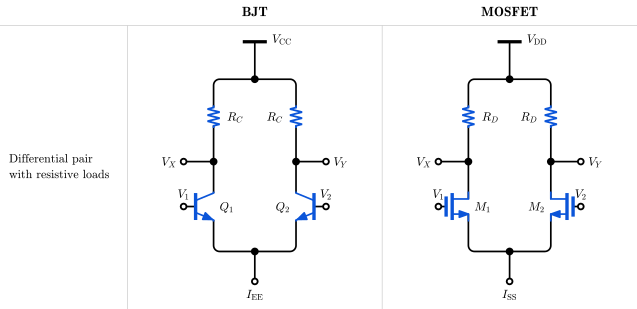

In [7]:
# HIDE/SHOW
show(C.pair_loaded)

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 70**

| | BJT |
|---|---|
| **Problem** | A bipolar differential pair: $Q_1$, $Q_2$ with both bases at the same $V_{CM}$, emitters joined to an ideal tail source $I_{EE}$, collectors $X$ and $Y$ tied to $V_{CC}$ through $R_{C1}=R_{C2}=R_C$. If $V_{CC}$ rises by $\Delta V$, with no Early effect, find the changes in $V_X$, $V_Y$ and $V_X-V_Y$, and explain why the circuit is said to reject supply noise. |
| **Given** | $R_{C1}=R_{C2}=R_C$, $I_{EE}$ ideal, $V_A=\infty$, supply step $\Delta V$ |
| **Answer 1** | **Collector currents.** With no Early effect, $I_{C1}=I_{C2}=I_{EE}/2$ do not depend on $V_{CC}$. |
| **Answer 2** | **Outputs.** $V_X=V_Y=V_{CC}-R_CI_{EE}/2$, so $\Delta V_X=\Delta V_Y=\Delta V$. |
| **Answer 3** | **Difference.** $\Delta(V_X-V_Y)$ $=\Delta V-\Delta V$ $=0$. |
| **Answer 4** | **Why "rejects".** The supply change moves both outputs equally (a common-mode change); the differential output, which carries the signal, is unaffected. |
| **Result** | $\Delta V_X=\Delta V_Y=\Delta V$, $\Delta(V_X-V_Y)=0$ |

**Problem 71**

| | BJT |
|---|---|
| **Problem** | In the bipolar pair (both bases at $V_{CM}$, ideal tail $I_{EE}$, equal collector resistors $R_C$ from $V_{CC}$ to $X$ and $Y$), the tail current changes by $\Delta I$. How do $V_X$, $V_Y$ and $V_X-V_Y$ change? |
| **Given** | $R_{C1}=R_{C2}=R_C$, tail change $\Delta I$, $\alpha\approx1$ |
| **Answer 1** | **Current split.** By symmetry each transistor carries half the tail current: $\Delta I_{C1}$ $=\Delta I_{C2}$ $=\Delta I/2$. |
| **Answer 2** | **Outputs.** $\Delta V_X$ $=\Delta V_Y$ $=-R_C\dfrac{\Delta I}{2}$. |
| **Answer 3** | **Difference.** $\Delta(V_X-V_Y)=0$: the tail change is a common-mode disturbance. |
| **Result** | $\Delta V_X$ $=\Delta V_Y$ $=-R_C\Delta I/2$, $\Delta(V_X-V_Y)=0$ |

**Problem 72**

| | BJT |
|---|---|
| **Problem** | Repeat Problem 71 (bipolar pair, both bases at $V_{CM}$, tail $I_{EE}$ changing by $\Delta I$) with mismatched loads $R_{C1}=R_{C2}+\Delta R$; neglect the Early effect. Find the changes in $V_X$, $V_Y$ and $V_X-V_Y$. |
| **Given** | $R_{C1}=R_{C2}+\Delta R$, tail change $\Delta I$, $V_A=\infty$ |
| **Answer 1** | **Current split.** The transistors are identical with equal $V_{BE}$, so the split stays $\Delta I/2$ each; the loads do not affect it without Early effect. |
| **Answer 2** | **Node X.** $\Delta V_X$ $=-(R_{C2}+\Delta R)\dfrac{\Delta I}{2}$ |
| **Answer 3** | **Node Y.** $\Delta V_Y$ $=-R_{C2}\dfrac{\Delta I}{2}$ |
| **Answer 4** | **Difference.** $\Delta(V_X-V_Y)$ $=-\Delta R\dfrac{\Delta I}{2}$: the load mismatch converts the tail (CM) disturbance into a differential error. |
| **Result** | $\Delta V_X$ $=-(R_{C2}+\Delta R)\Delta I/2$, $\Delta V_Y=-R_{C2}\Delta I/2$, $\Delta(V_X-V_Y)$ $=-\Delta R\,\Delta I/2$ |

**Problem 73**

| | BJT |
|---|---|
| **Problem** | An npn differential pair with tail current $I=100\,\mathrm{\mu A}$ has collector resistors that differ by $2\%$ ($\Delta R_C/R_C=0.02$), saturation currents that differ by $10\%$ ($\Delta I_S/I_S=0.1$), and $\beta=100$ with a $10\%$ spread ($\Delta\beta/\beta=0.1$). Take $V_T=25\,\mathrm{mV}$. Find the input offset voltage, the input bias current and the input offset current. |
| **Given** | $I=100\,\mathrm{\mu A}$, $\Delta R_C/R_C=0.02$, $\Delta I_S/I_S=0.1$, $\beta=100$, $\Delta\beta/\beta=0.1$ |
| **Answer 1** | **Offset voltage.** $V_{OS}$ $=V_T\sqrt{\left(\dfrac{\Delta R_C}{R_C}\right)^2+\left(\dfrac{\Delta I_S}{I_S}\right)^2}$ $=25\sqrt{0.02^2+0.1^2}$ $=2.55\,\mathrm{mV}$. |
| **Answer 2** | **Bias current.** $I_B$ $=\dfrac{I}{2(\beta+1)}$ $=\dfrac{100\,\mathrm{\mu A}}{2\times101}$ $=0.495\,\mathrm{\mu A}$ $\approx0.5\,\mathrm{\mu A}$. |
| **Answer 3** | **Offset current.** $I_{OS}$ $=I_B\dfrac{\Delta\beta}{\beta}$ $=0.495\times0.1$ $=49.5\,\mathrm{nA}$ $\approx50\,\mathrm{nA}$. |
| **Result** | $V_{OS}=2.55\,\mathrm{mV}$, $I_B\approx0.5\,\mathrm{\mu A}$, $I_{OS}\approx50\,\mathrm{nA}$ |

**Problem 74**

| | BJT |
|---|---|
| **Problem** | An npn differential pair has a ripple $v_r$ superimposed on $V_{CC}$. Show that the ripple does not appear in the differential output $v_{od}=v_{C2}-v_{C1}$. |
| **Given** | $V_{CC}\to V_{CC}+v_r$, tail current $I$, $R_C$ in each collector |
| **Answer 1** | **Collector 1.** $v_{C1}$ $=(V_{CC}+v_r)-\alpha\dfrac I2R_C$ $=(V_{CC}-\alpha\tfrac I2R_C)+v_r$. |
| **Answer 2** | **Collector 2.** $v_{C2}$ $=(V_{CC}+v_r)-\alpha\dfrac I2R_C$ $=(V_{CC}-\alpha\tfrac I2R_C)+v_r$. |
| **Answer 3** | **Difference.** $v_{od}=v_{C2}-v_{C1}=0$. |
| **Answer 4** | **Conclusion.** The ripple appears as a common-mode component at both collectors and cancels in the differential output, so the pair rejects supply ripple (for a matched pair). |
| **Result** | $v_{od}=0$: supply ripple is rejected |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 59**

| | MOSFET |
|---|---|
| **Problem** | The NMOS pair of the problem "Differential Pair with Degeneration" of the Problem Sets page ($V_{OV}=0.2\,\mathrm{V}$ at $I/2$ per side) has random mismatches $\Delta R_D/R_D=2\%$, $\Delta k_n^\prime/k_n^\prime=2\%$ (aspect-ratio mismatch of the same size) and $\Delta V_t=2\,\mathrm{mV}$. Find the input offset voltage caused by each one alone and the total. |
| **Given** | $V_{OV}=0.2\,\mathrm{V}$, $\Delta R_D/R_D=0.02$, $\Delta k_n/k_n=0.02$, $\Delta V_t=2\,\mathrm{mV}$ |
| **Answer 1** | **Offset from $R_D$.** $V_{OS}$ $=\dfrac{V_{OV}}2\dfrac{\Delta R_D}{R_D}$ $=\dfrac{0.2}{2}\times0.02$ $=2\,\mathrm{mV}$. |
| **Answer 2** | **Offset from $k_n$.** $V_{OS}$ $=\dfrac{V_{OV}}2\dfrac{\Delta k_n}{k_n}$ $=0.1\times0.02$ $=2\,\mathrm{mV}$. |
| **Answer 3** | **Offset from $V_t$.** $V_{OS}=\Delta V_t=2\,\mathrm{mV}$. |
| **Answer 4** | **Total (random, uncorrelated).** $V_{OS}$ $=\sqrt{\left(\dfrac{V_{OV}}2\dfrac{\Delta R_D}{R_D}\right)^2+\left(\dfrac{V_{OV}}2\dfrac{\Delta k_n}{k_n}\right)^2+(\Delta V_t)^2}$ $=\sqrt{3}\times2\,\mathrm{mV}$ $=3.46\,\mathrm{mV}$ $\approx3.5\,\mathrm{mV}$. |
| **Result** | $2\,\mathrm{mV}$, $2\,\mathrm{mV}$, $2\,\mathrm{mV}$ individually; total $V_{OS}\approx3.5\,\mathrm{mV}$ |
````
`````

### Differential pair with a finite tail resistance

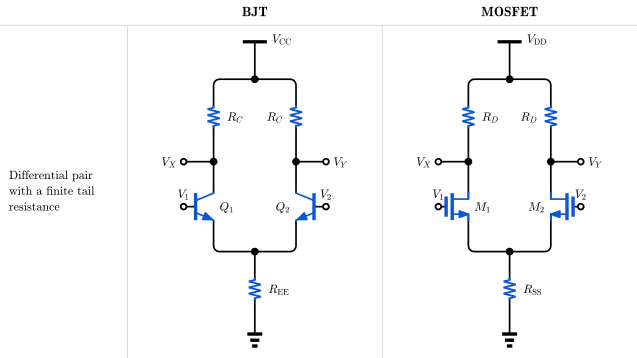

In [8]:
# HIDE/SHOW
show(C.pair_tail_resistance)

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 75**

| | BJT |
|---|---|
| **Problem** | In the circuit (bipolar pair $Q_1$, $Q_2$ with collector resistors $R_C$, both bases at $V_{CM}$, tail current $I_{EE}$ with output resistance $R_{EE}$), replace $R_{EE}$ by two resistors $2R_{EE}$ in parallel, one on each side of the current source. Split the circuit along its line of symmetry into two common-mode half circuits, each with a degeneration resistor $2R_{EE}$, and show that the general formula, $\Delta V_{out,CM}/\Delta V_{in,CM}$ $=-\dfrac{R_C/2}{R_{EE}+1/(2g_m)}$, still holds. |
| **Given** | Symmetric pair, $V_A=\infty$, $\beta\gg1$; numeric check: $g_m=20\,\mathrm{mS}$, $R_C=2\,\mathrm{k}\Omega$, $R_{EE}=5\,\mathrm{k}\Omega$ |
| **Answer 1** | **Split the tail.** $2R_{EE}\parallel2R_{EE}=R_{EE}$ and $I_{EE}=I_{EE}/2+I_{EE}/2$, so the circuit is unchanged |
| **Answer 2** | **No current crosses the symmetry line.** For a common-mode input both halves move identically, so the wire joining the two emitters carries no signal current and can be cut |
| **Answer 3** | **CM half circuit.** $Q_1$ with $R_C$ in the collector and $2R_{EE}$ (and the ideal source $I_{EE}/2$) in the emitter: a degenerated common-emitter stage |
| **Answer 4** | **Its gain.** $\dfrac{\Delta V_{out,CM}}{\Delta V_{in,CM}}$ $=-\dfrac{R_C}{2R_{EE}+1/g_m}$ |
| **Answer 5** | **Same as the general formula.** Divide top and bottom by 2: $-\dfrac{R_C}{2R_{EE}+1/g_m}$ $=-\dfrac{R_C/2}{R_{EE}+1/(2g_m)}$ |
| **Answer 6** | **Numeric check.** Half circuit $-0.199$, the general formula $-0.199$, and a nodal solution of the full circuit $-0.199$ |
| **Result** | $A_{CM}$ $=-\dfrac{R_C}{2R_{EE}+g_m^{-1}}$ $=-\dfrac{R_C/2}{R_{EE}+1/(2g_m)}$, identical to the general formula |

**Problem 76**

| | BJT |
|---|---|
| **Problem** | A BJT pair has both base dc levels at ground, collector resistors of $2\,\mathrm{k}\Omega$, and the emitters joined and returned to $-5\,\mathrm{V}$ through $4.3\,\mathrm{k}\Omega$. The output is taken at the collector of $Q_2$ (single-ended). The input is a differential $1\,\mathrm{kHz}$ signal of $10\,\mathrm{mV}$ peak plus a $60\,\mathrm{Hz}$ common-mode signal of $0.1\,\mathrm{V}$ peak. Find $A_d=v_o/v_{id}$, $A_{cm}=v_o/v_{icm}$, the CMRR, and the output waveform ($V_{BE}=0.7\,\mathrm{V}$, $\alpha\approx1$, $V_T=25\,\mathrm{mV}$). |
| **Given** | $R_C=2\,\mathrm{k}\Omega$, $R_{EE}=4.3\,\mathrm{k}\Omega$ to $-5\,\mathrm{V}$, $V_B=0$, $V_{BE}=0.7\,\mathrm{V}$, $\alpha\approx1$ |
| **Answer 1** | **DC bias.** $V_E=0-0.7=-0.7\,\mathrm{V}$; $2I_E$ $=\dfrac{-0.7-(-5)}{4.3}$ $=1\,\mathrm{mA}$, so $I_E=0.5\,\mathrm{mA}$ and $r_e$ $=\dfrac{25\,\mathrm{mV}}{0.5\,\mathrm{mA}}$ $=50\,\Omega$ |
| **Answer 2** | **(a) Differential gain.** $\dfrac{v_o}{v_{id}}$ $=\alpha\dfrac{R_C}{r_{e1}+r_{e2}}$ $=\dfrac{2\,\mathrm{k}}{0.1\,\mathrm{k}}$ $=20\,\mathrm{V/V}$ |
| **Answer 3** | **(b) Common-mode gain.** Half circuit: $R_{EE}$ doubled to $2R_{EE}=8.6\,\mathrm{k}\Omega$ in series with $r_e$: $\dfrac{v_o}{v_{icm}}$ $=-\dfrac{\alpha R_C}{r_e+2R_{EE}}$ $=-\dfrac{2}{0.05+8.6}$ $=-0.231\,\mathrm{V/V}$ |
| **Answer 4** | **(c) CMRR.** $\mathrm{CMRR}$ $=\dfrac{20}{0.231}$ $=86.5$, i.e. $38.7\,\mathrm{dB}$ |
| **Answer 5** | **(d) Output.** $v_o$ $=-0.023\sin(2\pi\,60t)+0.2\sin(2\pi\,1000t)\,\mathrm{V}$ (the hum is attenuated to $23\,\mathrm{mV}$, the signal reaches $0.2\,\mathrm{V}$). |
| **Result** | $A_d=20$, $\lvert A_{cm}\rvert=0.231$, $\mathrm{CMRR}=86.5$ (38.7 dB); $v_o$ $=-0.023\sin(2\pi60t)+0.2\sin(2\pi1000t)\,\mathrm V$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 60**

| | MOSFET |
|---|---|
| **Problem** | Take the NMOS pair of the problem "Differential Pair: Common-Mode Rejection" of the Problem Sets page ($g_m=4\,\mathrm{mA/V}$, $R_D=5\,\mathrm{k}\Omega$, $R_{SS}=25\,\mathrm{k}\Omega$) with perfectly matched drain resistors but a $1\%$ mismatch between the transconductances of $Q_1$ and $Q_2$. Find the CMRR, as a ratio and in dB. |
| **Given** | $g_m=4\,\mathrm{mA/V}$, $R_D=5\,\mathrm{k}\Omega$, $R_{SS}=25\,\mathrm{k}\Omega$, $\Delta g_m/g_m=0.01$ |
| **Answer 1** | **Common-mode gain.** With a $g_m$ mismatch the two drain signals differ: $A_{cm}\simeq\dfrac{R_D}{2R_{SS}}\dfrac{\Delta g_m}{g_m}$ $=\dfrac{5}{50}\times0.01$ $=0.001\,\mathrm{V/V}$ (for $2g_mR_{SS}\gg1$). |
| **Answer 2** | **Differential gain.** $A_d$ $=g_mR_D$ $=4\times5$ $=20\,\mathrm{V/V}$. |
| **Answer 3** | **CMRR.** $\mathrm{CMRR}$ $=\dfrac{A_d}{A_{cm}}$ $=\dfrac{2g_mR_{SS}}{\Delta g_m/g_m}$ $=\dfrac{2\times4\times25}{0.01}$ $=20\,000$. |
| **Answer 4** | **In decibels.** $20\log_{10}(20\,000)$ $=86\,\mathrm{dB}$. |
| **Result** | $\mathrm{CMRR}=20\,000$, i.e. $86\,\mathrm{dB}$ |

**Problem 61**

| | MOSFET |
|---|---|
| **Problem** | The NMOS pair of the problem "Differential Pair: Common-Mode Rejection" of the Problem Sets page ($g_m=4\,\mathrm{mA/V}$, $R_D=5\,\mathrm{k}\Omega$, $R_{SS}=25\,\mathrm{k}\Omega$, matched drain resistors) now has its output taken single-endedly (from one drain to ground). Find $\lvert A_d\rvert$, $\lvert A_{cm}\rvert$ and the CMRR. |
| **Given** | $g_m=4\,\mathrm{mA/V}$, $R_D=5\,\mathrm{k}\Omega$, $R_{SS}=25\,\mathrm{k}\Omega$ |
| **Answer 1** | **Differential gain.** Single-ended, the gain is half the differential-output value: $\lvert A_d\rvert$ $=\tfrac12g_mR_D$ $=\tfrac12\times4\times5$ $=10\,\mathrm{V/V}$. |
| **Answer 2** | **Common-mode gain.** $\lvert A_{cm}\rvert\simeq\dfrac{R_D}{2R_{SS}}$ $=\dfrac{5}{50}$ $=0.1\,\mathrm{V/V}$. |
| **Answer 3** | **CMRR.** $\mathrm{CMRR}$ $=\dfrac{\lvert A_d\rvert}{\lvert A_{cm}\rvert}$ $=g_mR_{SS}$ $=4\times25$ $=100$, i.e. $20\log100=40\,\mathrm{dB}$. |
| **Result** | $\lvert A_d\rvert=10$, $\lvert A_{cm}\rvert=0.1$, $\mathrm{CMRR}=100$ ($40\,\mathrm{dB}$) |

**Problem 62**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair has $k_n\,'(W/L)=5\,\mathrm{mA/V^2}$, each transistor biased at $I_D=0.1\,\mathrm{mA}$, drain resistors $R_D=12\,\mathrm{k}\Omega$ (with a $1\%$ mismatch $\Delta R_D/R_D$), and a tail resistance $R_{SS}=100\,\mathrm{k}\Omega$. Find $g_m$, the differential gain $\lvert A_d\rvert$, the common-mode gain $\lvert A_{cm}\rvert$ and the CMRR. |
| **Given** | $k_n\,'(W/L)=5\,\mathrm{mA/V^2}$, $I_D=0.1\,\mathrm{mA}$, $R_D=12\,\mathrm{k}\Omega$, $R_{SS}=100\,\mathrm{k}\Omega$, $\Delta R_D/R_D=1\%$ |
| **Answer 1** | **Transconductance.** $g_m$ $=\sqrt{2k_n'(W/L)I_D}$ $=\sqrt{2\times5\times0.1}$ $=1\,\mathrm{mA/V}$ |
| **Answer 2** | **Differential gain.** $\lvert A_d\rvert$ $=g_mR_D$ $=1\times12$ $=12\,\mathrm{V/V}$ |
| **Answer 3** | **Common-mode gain.** $\lvert A_{cm}\rvert$ $=\dfrac{R_D}{2R_{SS}}\dfrac{\Delta R_D}{R_D}$ $=\dfrac{12}{2\times100}\times0.01$ $=6\times10^{-4}\,\mathrm{V/V}$ |
| **Answer 4** | **CMRR.** $\mathrm{CMRR}$ $=\dfrac{12}{6\times10^{-4}}$ $=2\times10^4$, i.e. $20\log_{10}(2\times10^4)$ $=86\,\mathrm{dB}$ |
| **Result** | $g_m=1\,\mathrm{mA/V}$, $\lvert A_d\rvert=12$, $\lvert A_{cm}\rvert=6\times10^{-4}$, $\mathrm{CMRR}=2\times10^4$ (86 dB) |
````
`````

### Differential pair with current-mirror load

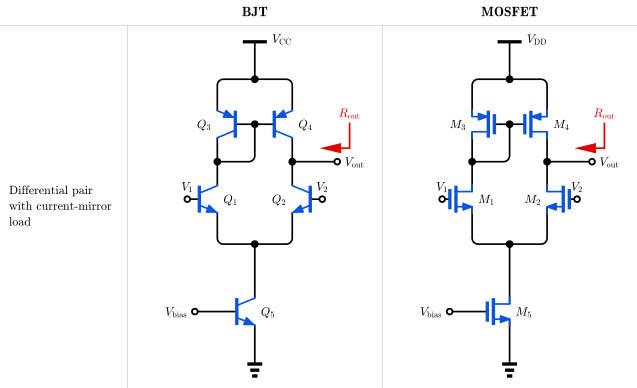

In [9]:
# HIDE/SHOW
show(C.pair_mirror_load)

`````{tab-set}
````{tab-item} MOSFET
:sync: mosfet

**Problem 63**

| | MOSFET |
|---|---|
| **Problem** | In a mirror-loaded NMOS pair with ideal tail current $I$ the pair transistors have a $W/L$ mismatch $\Delta(W/L)_A$ (so $(W/L)_{1,2}$ $=(W/L)_A\pm\tfrac12\Delta(W/L)_A$) and the mirror transistors $Q_3,Q_4$ have a mismatch $\Delta(W/L)_M$ in their current-transfer ratio. (a) Show that the offset from the pair mismatch is $V_{OS}$ $=\dfrac{V_{OV}}2\dfrac{\Delta(W/L)_A}{(W/L)_A}$. (b) Show that the offset from the mirror mismatch is $V_{OS}$ $=\dfrac{V_{OV}}2\dfrac{\Delta(W/L)_M}{(W/L)_M}$. (c) For $V_{OV}=0.2\,\mathrm{V}$ and mismatches of 2 percent in each case, find the worst-case offset. |
| **Given** | $V_{OV}=0.2\,\mathrm{V}$, $\Delta(W/L)/(W/L)=2\%$ for the pair and for the mirror |
| **Answer 1** | **(a) Currents of the pair.** With equal $V_{GS}$ (zero input) $I_D=\tfrac12k_n(W/L)V_{OV}^2$, so $I_{D1}$ $=\dfrac I2\left[1+\dfrac12\dfrac{\Delta(W/L)_A}{(W/L)_A}\right]$ and $I_{D2}$ $=\dfrac I2\left[1-\dfrac12\dfrac{\Delta(W/L)_A}{(W/L)_A}\right]$. |
| **Answer 2** | **(a) Output current.** The ideal mirror gives $I_{D4}=I_{D3}=I_{D1}$, so $I_O$ $=I_{D4}-I_{D2}$ $=\dfrac I2\dfrac{\Delta(W/L)_A}{(W/L)_A}$. |
| **Answer 3** | **(a) Input offset.** $V_{OS}=\dfrac{I_O}{G_{md}}$ with $G_{md}$ $=g_{m1,2}$ $=\dfrac{2(I/2)}{V_{OV}}$ $=\dfrac{I}{V_{OV}}$, so $V_{OS}$ $=\dfrac{V_{OV}}2\dfrac{\Delta(W/L)_A}{(W/L)_A}$ (Q.E.D.). |
| **Answer 4** | **(b) Mirror error.** Now $I_{D1}=I_{D2}=I/2$, $I_{D3}=I_{D1}$ and $I_{D4}$ $=I_{D3}\left[1+\dfrac{\Delta(W/L)_M}{(W/L)_M}\right]$. |
| **Answer 5** | **(b) Output current and offset.** $I_O$ $=I_{D4}-I_{D2}$ $=\dfrac I2\dfrac{\Delta(W/L)_M}{(W/L)_M}$, so $V_{OS}$ $=\dfrac{I_O}{I/V_{OV}}$ $=\dfrac{V_{OV}}2\dfrac{\Delta(W/L)_M}{(W/L)_M}$ (Q.E.D.). |
| **Answer 6** | **(c) Numbers.** Each contribution: $\dfrac{0.2}{2}\times0.02$ $=2\,\mathrm{mV}$. |
| **Answer 7** | **(c) Worst case.** The two effects can add: $V_{OS,\max}=2+2=4\,\mathrm{mV}$. |
| **Answer 8** | **Check with the exact square law.** Solving the exact square-law equations with $2\%$ mismatches gives $2.000\,\mathrm{mV}$ for the pair and $1.98\,\mathrm{mV}$ for the mirror, in agreement with the first-order formula. |
| **Result** | $V_{OS}$ $=\dfrac{V_{OV}}2\dfrac{\Delta(W/L)}{(W/L)}$ for each source; worst case $V_{OS}=4\,\mathrm{mV}$ |
````
`````

### Other Circuits

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 77**

| | BJT |
|---|---|
| **Problem** | A bipolar differential pair $Q_1$, $Q_2$ (finite $\beta$, $V_A=\infty$) has collector resistors $R_C$ and $R_C+\Delta R_C$. Both bases are driven by the same common-mode voltage $V_{CM}$. The tail is a transistor $Q_3$ (base at a bias voltage, finite $r_{O3}$) with an emitter resistor $R_1$. Find the common-mode to differential-mode gain $A_{CM-DM}$ (the change of $V_{out1}-V_{out2}$ per unit change of $V_{CM}$). |
| **Given** | $g_{m1}$; $Q_3$: $g_{m3}$, $r_{\pi3}$, $r_{O3}$; $R_1$; mismatch $\Delta R_C$ |
| **Answer 1** | **Load mismatch only.** The two collector currents stay equal (equal $V_{BE}$ and symmetric tail), so for a common-mode change $\Delta V_{CM}$ each branch current changes by $\Delta I$ and $\Delta V_{out1}-\Delta V_{out2}$ $=\Delta I\,\Delta R_C$. |
| **Answer 2** | **Tail resistance.** The tail node $P$ moves with the common mode. Both emitter currents flow into the tail, which presents $R_{out3}$. Then $\Delta V_{CM}$ $=\Delta I\left(\dfrac1{g_{m1}}+2R_{out3}\right)$. |
| **Answer 3** | **General result.** $A_{CM-DM}$ $=\dfrac{\Delta R_C}{1/g_{m1}+2R_{out3}}$. |
| **Answer 4** | **Output resistance of the tail.** Emitter degeneration gives $R_{out3}$ $=\left[1+g_{m3}(R_1\parallel r_{\pi3})\right]r_{O3}+R_1\parallel r_{\pi3}$. |
| **Answer 5** | **Result.** $A_{CM-DM}$ $=\dfrac{\Delta R_C}{\dfrac1{g_{m1}}+2\left\{\left[1+g_{m3}(R_1\parallel r_{\pi3})\right]r_{O3}+R_1\parallel r_{\pi3}\right\}}$. |
| **Answer 6** | **Numerical check.** $I_{EE}=1\,\mathrm{mA}$, $\beta=100$, $V_T=26\,\mathrm{mV}$, $V_{A3}=100\,\mathrm{V}$, $R_1=500\,\Omega$, $R_C=1\,\mathrm{k}\Omega$, $\Delta R_C=10\,\Omega$: $g_{m1}=19.2\,\mathrm{mS}$, $g_{m3}=38.5\,\mathrm{mS}$, $r_{\pi3}=2.6\,\mathrm{k}\Omega$, $r_{O3}=100\,\mathrm{k}\Omega$, $R_1\parallel r_{\pi3}=419\,\Omega$, $R_{out3}=1.71\,\mathrm{M}\Omega$ (the nodal solution agrees), so $A_{CM-DM}=2.92\times10^{-6}$. The full nodal solution including base currents gives $2.89\times10^{-6}$ (1 % lower, the factor $\beta/(\beta+1)$). |
| **Result** | $A_{CM-DM}$ $=\dfrac{\Delta R_C}{1/g_{m1}+2R_{out3}}$, $R_{out3}$ $=[1+g_{m3}(R_1\parallel r_{\pi3})]r_{O3}+R_1\parallel r_{\pi3}$ |

**Problem 78**

| | BJT |
|---|---|
| **Problem** | For the circuit of the previous example (bipolar pair with collector resistors $R_C$ and $R_C+\Delta R_C$, tail transistor $Q_3$ with emitter resistor $R_1$), find the common-mode rejection ratio $\mathrm{CMRR}=A_{DM}/A_{CM-DM}$, assuming a small mismatch $\Delta R_C\ll R_C$. |
| **Given** | $g_{m1}$, $R_C$, $\Delta R_C\ll R_C$, $A_{CM-DM}$ from the previous example |
| **Answer 1** | **Differential gain.** For a small mismatch $R_C+\Delta R_C\approx R_C$, so $A_{DM}=g_{m1}R_C$. |
| **Answer 2** | **CM-DM gain.** $A_{CM-DM}$ $=\dfrac{\Delta R_C}{1/g_{m1}+2R_{out3}}$ from the previous example. |
| **Answer 3** | **Ratio.** $\mathrm{CMRR}$ $=\dfrac{g_{m1}R_C}{\Delta R_C}\left(\dfrac1{g_{m1}}+2R_{out3}\right)$. |
| **Answer 4** | **Insert $R_{out3}$.** $\mathrm{CMRR}$ $=\dfrac{g_{m1}R_C}{\Delta R_C}\left\{\dfrac1{g_{m1}}+2\left[1+g_{m3}(R_1\parallel r_{\pi3})\right]r_{O3}+2(R_1\parallel r_{\pi3})\right\}$. |
| **Answer 5** | **Numerical check.** With the numbers of the previous example: $A_{DM}=19.2$, $A_{CM-DM}=2.92\times10^{-6}$, $\mathrm{CMRR}=6.59\times10^{6}$, about $136\,\mathrm{dB}$. The expanded formula gives the same value, and the full nodal common-mode solution gives $6.66\times10^6$ (1 % higher). |
| **Result** | $\mathrm{CMRR}$ $=\dfrac{g_{m1}R_C}{\Delta R_C}\left\{\dfrac1{g_{m1}}+2\left[1+g_{m3}(R_1\parallel r_{\pi3})\right]r_{O3}+2(R_1\parallel r_{\pi3})\right\}$ |

**Problem 79**

| | BJT |
|---|---|
| **Problem** | Two identical common-emitter stages: $Q_1$ with load $R_{C1}$ (output node $X$) and $Q_2$ with load $R_{C2}$ (output node $Y$), both loads to the same supply $V_{CC}$, emitters grounded, bases at fixed bias (the signal only at the base of $Q_1$). The output is $V_{out}=V_X-V_Y$. With $R_{C1}=R_{C2}$ and finite $V_A$, find the small-signal gain from $V_{CC}$ to $V_{out}$. |
| **Given** | $R_{C1}=R_{C2}=R_C$, identical $Q_1$, $Q_2$ with the same bias, $r_{O1}=r_{O2}=r_O$ |
| **Answer 1** | **Each side.** As in BJT Problem 6 of the page Amplifier Stages, with the base at ac ground: $\dfrac{v_X}{v_{cc}}$ $=\dfrac{r_{O1}}{r_{O1}+R_{C1}}$, $\dfrac{v_Y}{v_{cc}}$ $=\dfrac{r_{O2}}{r_{O2}+R_{C2}}$. |
| **Answer 2** | **Difference.** $\dfrac{v_X-v_Y}{v_{cc}}$ $=\dfrac{r_{O1}}{r_{O1}+R_{C1}}-\dfrac{r_{O2}}{r_{O2}+R_{C2}}$ |
| **Answer 3** | **Symmetry.** With $R_{C1}=R_{C2}$ and equal bias currents, $r_{O1}=r_{O2}$, so the two terms cancel: gain $=0$. |
| **Answer 4** | **Numeric check.** $R_C=1\,\mathrm{k}\Omega$, $r_O=10\,\mathrm{k}\Omega$: $v_X/v_{cc}=v_Y/v_{cc}=0.909$, difference $0$. |
| **Result** | $(v_X-v_Y)/v_{cc}=0$ (each node alone sees $r_O/(r_O+R_C)$) |

**Problem 80**

| | BJT |
|---|---|
| **Problem** | The bipolar pair: $Q_1$, $Q_2$ with collector resistors $R_C$, both bases driven by $V_{CM}$, tail current set by $Q_3$ (base at $V_b$, emitter grounded) carrying $I_{EE}$. $V_A=\infty$ for $Q_1$, $Q_2$ but finite for $Q_3$. Show that a common-mode gain below 0.01 requires $R_CI_C<0.02(V_A+V_T)$. |
| **Given** | $\lvert A_{CM}\rvert<0.01$, $V_A$ of $Q_3$ finite; numeric check: $V_A=10\,\mathrm{V}$, $I_{EE}=1\,\mathrm{mA}$ |
| **Answer 1** | **Tail resistance.** $R_{EE}=r_{O3}=V_A/I_{EE}$ |
| **Answer 2** | **CM gain.** $\lvert A_{CM}\rvert$ $=\dfrac{R_C}{2R_{EE}+1/g_{m1}}$ with $g_{m1}=\dfrac{I_{EE}/2}{V_T}$, so $\dfrac1{g_{m1}}$ $=\dfrac{2V_T}{I_{EE}}$ |
| **Answer 3** | **Substitute.** $\lvert A_{CM}\rvert$ $=\dfrac{R_C}{2V_A/I_{EE}+2V_T/I_{EE}}$ $=\dfrac{R_CI_{EE}}{2(V_A+V_T)}$ |
| **Answer 4** | **Condition.** $\dfrac{R_CI_{EE}}{2(V_A+V_T)}<0.01\iff R_CI_{EE}<0.02(V_A+V_T)$ with $I_C$ the collector current of $Q_3$ ($=I_{EE}$) |
| **Answer 5** | **Numeric check.** $V_A=10\,\mathrm{V}$, $I_{EE}=1\,\mathrm{mA}$: $r_{O3}=10\,\mathrm{k}\Omega$, $1/g_m=52\,\Omega$, limit $R_C=200.5\,\Omega$, which gives $\lvert A_{CM}\rvert=0.0100$ |
| **Result** | $\lvert A_{CM}\rvert$ $=\dfrac{R_CI_C}{2(V_A+V_T)}<0.01\Rightarrow R_CI_C<0.02(V_A+V_T)$ with $I_C=I_{EE}$ (equivalently $R_CI_{C1}<0.01(V_A+V_T)$ per device) |

**Problem 81**

| | BJT |
|---|---|
| **Problem** | In an npn differential pair $Q_2$ has twice the emitter-base junction area of $Q_1$, and the tail current is $1.5\,\mathrm{mA}$. (a) With both bases at the same voltage find $I_{E1}$ and $I_{E2}$. (b) Find the differential input $v_{id}=v_{B1}-v_{B2}$ that makes the collector currents equal. |
| **Given** | $I=1.5\,\mathrm{mA}$, $I_{S2}=2I_{S1}$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **(a) Equal bases.** Same $v_{BE}$, so the currents split in the area ratio: $i_{E2}=2i_{E1}$. |
| **Answer 2** | **(a) Currents.** $i_{E1}+i_{E2}$ $=1.5\,\mathrm{mA}\Rightarrow i_{E1}$ $=0.5\,\mathrm{mA}$, $i_{E2}=1\,\mathrm{mA}$. |
| **Answer 3** | **(b) Exponentials.** $i_{C1}=I_Se^{(v_{B1}-v_E)/V_T}$, $i_{C2}=2I_Se^{(v_{B2}-v_E)/V_T}$. |
| **Answer 4** | **(b) Ratio.** $\dfrac{i_{C1}}{i_{C2}}$ $=\dfrac12e^{(v_{B1}-v_{B2})/V_T}$. |
| **Answer 5** | **(b) Equal currents.** Set the ratio to 1: $v_{B1}-v_{B2}$ $=V_T\ln2$ $=25\ln2$ $=17.3\,\mathrm{mV}$. |
| **Result** | $I_{E1}=0.5\,\mathrm{mA}$, $I_{E2}=1\,\mathrm{mA}$; $v_{id}=V_T\ln2=17.3\,\mathrm{mV}$ |

**Problem 82**

| | BJT |
|---|---|
| **Problem** | A BJT differential pair is biased by a tail current $I=0.2\,\mathrm{mA}$ from a simple current mirror. All transistors have $V_A=20\,\mathrm{V}$ and the pair has $\beta=50$, with $R_C\ll r_o$. Find the tail resistance $R_{EE}$ and the common-mode input resistance $R_{icm}$. |
| **Given** | $I=0.2\,\mathrm{mA}$, $V_A=20\,\mathrm{V}$, $\beta=50$, $R_C\ll r_o$ |
| **Answer 1** | **Tail resistance.** $R_{EE}$ $=\dfrac{V_A}{I}$ $=\dfrac{20}{0.2}$ $=100\,\mathrm{k}\Omega$ |
| **Answer 2** | **Pair output resistance.** Each pair transistor carries $I/2=0.1\,\mathrm{mA}$: $r_o$ $=\dfrac{20}{0.1}$ $=200\,\mathrm{k}\Omega$ |
| **Answer 3** | **Ricm formula.** $R_{icm}\simeq\beta R_{EE}\dfrac{1+R_C/(\beta r_o)}{1+(R_C+2R_{EE})/r_o}$ $\approx\dfrac{\beta R_{EE}}{1+2R_{EE}/r_o}$ for $R_C\ll r_o$ |
| **Answer 4** | **Number.** $R_{icm}$ $=\dfrac{50\times100}{1+200/200}$ $=2.5\,\mathrm{M}\Omega$ |
| **Result** | $R_{EE}=100\,\mathrm{k}\Omega$, $R_{icm}$ $\approx2.5\,\mathrm{M}\Omega$ |

**Problem 83**

| | BJT |
|---|---|
| **Problem** | A BJT pair biased at $I_C=0.1\,\mathrm{mA}$ per transistor (tail current $I=0.2\,\mathrm{mA}$) has $R_C=10\,\mathrm{k}\Omega$ with a $10\%$ mismatch and $V_A=20\,\mathrm{V}$, $\beta=100$. Find $A_d$ and the CMRR when the tail source is (a) a simple current source, (b) a Wilson mirror (output resistance $\tfrac12\beta r_o$). Use $V_T=25\,\mathrm{mV}$. |
| **Given** | $I_C=0.1\,\mathrm{mA}$, $I=0.2\,\mathrm{mA}$, $R_C=10\,\mathrm{k}\Omega$, $\Delta R_C/R_C=10\%$, $V_A=20\,\mathrm{V}$, $\beta=100$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Differential gain.** $g_m$ $=\dfrac{0.1}{0.025}$ $=4\,\mathrm{mA/V}$, $r_o$ $=\dfrac{20}{0.1}$ $=200\,\mathrm{k}\Omega\gg R_C$, so $A_d$ $=g_mR_C$ $=4\times10$ $=40\,\mathrm{V/V}$ |
| **Answer 2** | **Simple source: $R_{EE}$.** $R_{EE}$ $=\dfrac{V_A}{I}$ $=\dfrac{20}{0.2}$ $=100\,\mathrm{k}\Omega$ |
| **Answer 3** | **Simple source: CMRR.** $\lvert A_{cm}\rvert$ $=\dfrac{R_C}{2R_{EE}}\dfrac{\Delta R_C}{R_C}$ $=\dfrac{10}{200}\times0.1$ $=5\times10^{-3}$; $\mathrm{CMRR}$ $=\dfrac{40}{5\times10^{-3}}$ $=8\times10^3$, i.e. $78\,\mathrm{dB}$ |
| **Answer 4** | **Wilson: $R_{EE}$.** The mirror transistors have $r_o$ $=\dfrac{20}{0.2}$ $=100\,\mathrm{k}\Omega$: $R_{EE}$ $=\tfrac12\beta r_o$ $=\tfrac12\times100\times100$ $=5\,\mathrm{M}\Omega$ |
| **Answer 5** | **Wilson: CMRR.** $\lvert A_{cm}\rvert$ $=\dfrac{10}{2\times5000}\times0.1$ $=1\times10^{-4}$; $\mathrm{CMRR}$ $=\dfrac{40}{10^{-4}}$ $=4\times10^5$, i.e. $112\,\mathrm{dB}$ |
| **Result** | $A_d=40$; simple source: CMRR $=8\times10^3$ (78 dB); Wilson mirror: CMRR $=4\times10^5$ (112 dB) |

**Problem 84**

| | BJT |
|---|---|
| **Problem** | In a BJT differential pair the CMRR for a differential output exceeds the CMRR for a single-ended output at one collector by $46\,\mathrm{dB}$. If the only mismatch is in the collector resistors, find $\Delta R_C/R_C$. |
| **Given** | $\mathrm{CMRR}_d/\mathrm{CMRR}_s$ $=46\,\mathrm{dB}$; only $R_C$ mismatch |
| **Answer 1** | **Single-ended output.** $\lvert A_{cm}\rvert$ $=\dfrac{R_C}{2R_{EE}}$, $\lvert A_d\rvert=\tfrac12g_mR_C$, so $\mathrm{CMRR}_s=g_mR_{EE}$ |
| **Answer 2** | **Differential output.** $\lvert A_{cm}\rvert$ $=\dfrac{R_C}{2R_{EE}}\dfrac{\Delta R_C}{R_C}$, $\lvert A_d\rvert=g_mR_C$, so $\mathrm{CMRR}_d$ $=\dfrac{2g_mR_{EE}}{\Delta R_C/R_C}$ |
| **Answer 3** | **Ratio.** $\dfrac{\mathrm{CMRR}_d}{\mathrm{CMRR}_s}$ $=\dfrac{2}{\Delta R_C/R_C}$ |
| **Answer 4** | **Apply 46 dB.** $20\log\dfrac{2}{\Delta R_C/R_C}$ $=46\Rightarrow\dfrac2{\Delta R_C/R_C}$ $=10^{46/20}$ $=199.5$ |
| **Answer 5** | **Solve.** $\dfrac{\Delta R_C}{R_C}$ $=\dfrac{2}{199.5}$ $=0.01003$ $\approx1\%$ |
| **Result** | $\Delta R_C/R_C\approx1\%$ |

**Problem 85**

| | BJT |
|---|---|
| **Problem** | In a BJT differential pair the emitter-base junction of $Q_1$ has twice the area of that of $Q_2$ (otherwise identical), with $R_C=15\,\mathrm{k}\Omega$ in each collector and a tail resistance $R_{EE}=400\,\mathrm{k}\Omega$; the output is taken differentially. Find how the dc current splits and the common-mode gain $A_{cm}$. |
| **Given** | $I_{S1}=2I_{S2}$, $R_C=15\,\mathrm{k}\Omega$, $R_{EE}=400\,\mathrm{k}\Omega$ |
| **Answer 1** | **DC split.** With both bases at the same voltage, $V_{BE}$ is the same, so currents are in the ratio of $I_S$: $I_{E1}=\tfrac23I$ and $I_{E2}=\tfrac13I$. |
| **Answer 2** | **Common-mode current.** A common-mode input $v_{icm}$ drives a current $v_{icm}/R_{EE}$ into the emitters, split in the same ratio: $i_{e1}$ $=\tfrac23\dfrac{v_{icm}}{R_{EE}}$, $i_{e2}$ $=\tfrac13\dfrac{v_{icm}}{R_{EE}}$ |
| **Answer 3** | **Collector voltages.** $v_{o1}$ $=-\tfrac23\dfrac{R_C}{R_{EE}}v_{icm}$, $v_{o2}$ $=-\tfrac13\dfrac{R_C}{R_{EE}}v_{icm}$ ($\alpha\approx1$) |
| **Answer 4** | **Differential output.** $v_o$ $=v_{o2}-v_{o1}$ $=\tfrac13\dfrac{R_C}{R_{EE}}v_{icm}$ |
| **Answer 5** | **Number.** $A_{cm}$ $=\dfrac13\times\dfrac{15}{400}$ $=0.0125\,\mathrm{V/V}$ |
| **Result** | $I_{E1}=\tfrac23I$, $I_{E2}=\tfrac13I$; $A_{cm}=0.0125\,\mathrm{V/V}$ |

**Problem 86**

| | BJT |
|---|---|
| **Problem** | A BJT differential pair has $10\%$ mismatch in the collector resistors ($\Delta R_C/R_C=0.1$). Find the input offset voltage ($V_T=25\,\mathrm{mV}$). |
| **Given** | $\Delta R_C/R_C=10\%$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Output offset.** With equal bias currents $I/2$ the collector voltages differ by $V_O=\dfrac I2\Delta R_C$ ($\alpha\approx1$). |
| **Answer 2** | **Divide by gain.** $A_d=g_mR_C=\dfrac{I}{2V_T}R_C$, so $V_{OS}$ $=\dfrac{V_O}{A_d}$ $=V_T\dfrac{\Delta R_C}{R_C}$ |
| **Answer 3** | **Number.** $V_{OS}$ $=25\times0.1$ $=2.5\,\mathrm{mV}$ |
| **Result** | $V_{OS}$ $=V_T\,\Delta R_C/R_C$ $=2.5\,\mathrm{mV}$ |

**Problem 87**

| | BJT |
|---|---|
| **Problem** | A BJT differential pair has a $10\%$ mismatch in the scale currents of the two transistors ($\Delta I_S/I_S=0.1$) and equal collector resistors. Find the input offset voltage ($V_T=25\,\mathrm{mV}$). |
| **Given** | $\Delta I_S/I_S=10\%$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Condition for equal collector currents.** For equal collector currents the base-emitter voltages must differ by $V_T\ln\dfrac{I_{S2}}{I_{S1}}$ |
| **Answer 2** | **Small mismatch.** For $\Delta I_S\ll I_S$: $\lvert V_{OS}\rvert$ $=V_T\dfrac{\Delta I_S}{I_S}$ |
| **Answer 3** | **Number.** $V_{OS}$ $=25\,\mathrm{mV}\times0.1$ $=2.5\,\mathrm{mV}$ (exact for $\pm5\%$ about the mean: $25\ln(1.05/0.95)=2.50\,\mathrm{mV}$) |
| **Result** | $V_{OS}$ $=V_T\,\Delta I_S/I_S$ $=2.5\,\mathrm{mV}$ |

**Problem 88**

| | BJT |
|---|---|
| **Problem** | A BJT pair with bases at ground and tail current $I=1\,\mathrm{mA}$ has collector resistors nominally $5\,\mathrm{k}\Omega$ each, joined to the supply through a $1\,\mathrm{k}\Omega$ potentiometer: a part $x$ (in k$\Omega$) of the pot is in series with the $Q_1$ collector resistor and the remaining $(1-x)$ with that of $Q_2$. Find $x$ that nulls the offset when (a) $R_{C1}$ is $4\%$ above and $R_{C2}$ $4\%$ below nominal (equal $I_S$); (b) $I_{S1}$ is $5\%$ above and $I_{S2}$ $5\%$ below nominal (resistors equal, $5\,\mathrm{k}\Omega$). |
| **Given** | $I=1\,\mathrm{mA}$, $R_C=5\,\mathrm{k}\Omega$, pot $=1\,\mathrm{k}\Omega$, (a) $\pm4\%$ in $R_C$, (b) $\pm5\%$ in $I_S$, $\alpha\approx1$ |
| **Answer 1** | **(a) Resistances.** $R_{C1}$ $=1.04\times5$ $=5.20\,\mathrm{k}\Omega$, $R_{C2}$ $=0.96\times5$ $=4.80\,\mathrm{k}\Omega$; both transistors carry $0.5\,\mathrm{mA}$ |
| **Answer 2** | **(a) Equalize collector resistance.** $R_{C1}+x$ $=R_{C2}+(1-x)\Rightarrow5.2+x$ $=5.8-x$ (k$\Omega$) |
| **Answer 3** | **(a) Solve.** $x=0.3\,\mathrm{k}\Omega$ |
| **Answer 4** | **(b) Currents.** Equal $V_{BE}$, so the split follows $I_S$: $I_{E1}$ $=0.5\times1.05$ $=0.525\,\mathrm{mA}$, $I_{E2}$ $=0.5\times0.95$ $=0.475\,\mathrm{mA}$, $I_C\approx I_E$ |
| **Answer 5** | **(b) Equal collector voltages.** $V_{C1}$ $=V_{C2}\Rightarrow I_{C1}(5+x)$ $=I_{C2}(5+1-x)$: $0.525(5+x)=0.475(6-x)$ |
| **Answer 6** | **(b) Solve.** $2.625+0.525x$ $=2.85-0.475x\Rightarrow x$ $=0.225\,\mathrm{k}\Omega$ |
| **Result** | (a) $x=0.3\,\mathrm{k}\Omega$; (b) $x=0.225\,\mathrm{k}\Omega$ |

**Problem 89**

| | BJT |
|---|---|
| **Problem** | A BJT differential pair is biased with a tail current $I=400\,\mu\mathrm{A}$ and its transistors have $\beta$ between $80$ and $200$. Find the largest and smallest base currents and the largest input offset current. |
| **Given** | $I=400\,\mu\mathrm{A}$ (so $I_E=200\,\mu\mathrm{A}$ each), $80\le\beta\le200$ |
| **Answer 1** | **Base current.** $I_B$ $=\dfrac{I_E}{\beta+1}$ $=\dfrac{I/2}{\beta+1}$ |
| **Answer 2** | **Maximum.** $\beta=80$: $I_{B,max}$ $=\dfrac{400}{2\times81}$ $=2.47\,\mu\mathrm{A}$ $\approx2.5\,\mu\mathrm{A}$ |
| **Answer 3** | **Minimum.** $\beta=200$: $I_{B,min}$ $=\dfrac{400}{2\times201}$ $=0.995\,\mu\mathrm{A}$ $\approx1\,\mu\mathrm{A}$ |
| **Answer 4** | **Offset current.** $I_{OS}=\lvert I_{B1}-I_{B2}\rvert$ is largest with $\beta=80$ in one transistor and $200$ in the other: $I_{OS,max}$ $=\dfrac{200}{81}-\dfrac{200}{201}$ $=1.47\,\mu\mathrm{A}$ $\approx1.5\,\mu\mathrm{A}$ |
| **Result** | $I_{B,max}\approx2.5\,\mu\mathrm A$, $I_{B,min}\approx1\,\mu\mathrm A$, $I_{OS,max}\approx1.5\,\mu\mathrm A$ |

**Problem 90**

| | BJT |
|---|---|
| **Problem** | In a BJT differential pair with bases grounded and equal collector resistors $R_C$, the transistors have unequal current gains $\beta_1,\beta_2$ and each emitter carries $I/2$. Show that $V_{OS}$ $=V_T\left(\dfrac1{\beta_2}-\dfrac1{\beta_1}\right)$ for $\beta\gg1$ and evaluate it for $\beta_1=50$, $\beta_2=100$. |
| **Given** | $\beta_1=50$, $\beta_2=100$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Collector currents.** Equal emitter currents $I/2$ give $I_{C1}=\alpha_1\dfrac I2$, $I_{C2}=\alpha_2\dfrac I2$ with $\alpha=\dfrac{\beta}{\beta+1}$ |
| **Answer 2** | **Output offset.** $V_O$ $=V_{C2}-V_{C1}$ $=\dfrac12IR_C(\alpha_1-\alpha_2)$ |
| **Answer 3** | **Divide by gain.** $A_d=g_mR_C=\dfrac{IR_C}{2V_T}$, so $V_{OS}=V_T(\alpha_1-\alpha_2)$ |
| **Answer 4** | **Express with beta.** $\alpha_1-\alpha_2$ $=\dfrac{\beta_1-\beta_2}{(\beta_1+1)(\beta_2+1)}$ $\approx\dfrac{\beta_1-\beta_2}{\beta_1\beta_2}$ $=\dfrac1{\beta_2}-\dfrac1{\beta_1}$ |
| **Answer 5** | **Number.** $V_{OS}$ $=25\left(\dfrac1{100}-\dfrac1{50}\right)$ $=-0.25\,\mathrm{mV}$ (using the exact $\alpha$ difference: $-0.243\,\mathrm{mV}$) |
| **Result** | $V_{OS}$ $=V_T\left(\dfrac1{\beta_2}-\dfrac1{\beta_1}\right)$ $=-0.25\,\mathrm{mV}$ |

**Problem 91**

| | BJT and MOSFET |
|---|---|
| **Problem** | Compare the input offset voltages of (a) an NMOS pair biased at $V_{OV}=0.2\,\mathrm{V}$ with a $4\%$ mismatch in the drain resistors and (b) a BJT pair with a $4\%$ mismatch in the collector resistors ($V_T=25\,\mathrm{mV}$). (c) What happens to the MOS offset if the width of each device is increased by a factor of $4$ at constant bias current? |
| **Given** | $V_{OV}=0.2\,\mathrm V$, $\Delta R_D/R_D=\Delta R_C/R_C=4\%$, $V_T=25\,\mathrm{mV}$, width $\times4$ at constant $I$ |
| **Answer 1** | **(a) MOS.** $V_{OS}$ $=\dfrac{V_{OV}}{2}\dfrac{\Delta R_D}{R_D}$ $=\dfrac{200\,\mathrm{mV}}{2}\times0.04$ $=4\,\mathrm{mV}$ |
| **Answer 2** | **(b) BJT.** $V_{OS}$ $=V_T\dfrac{\Delta R_C}{R_C}$ $=25\times0.04$ $=1\,\mathrm{mV}$ |
| **Answer 3** | **(c) Width x4.** At constant $I$, $V_{OV}$ $=\sqrt{I/(k_n^{\prime}(W/L))}$ falls by $\sqrt4=2$, to $0.1\,\mathrm V$ |
| **Answer 4** | **(c) New offset.** $V_{OS}$ $=\dfrac{0.1\,\mathrm V}{2}\times0.04$ $=2\,\mathrm{mV}$ |
| **Answer 5** | **Conclusion.** The BJT offset is $4\times$ smaller than the MOS one at this bias; the MOS offset is reduced only by a wider device (lower $V_{OV}$). |
| **Result** | MOS $V_{OS}=4\,\mathrm{mV}$; BJT $V_{OS}=1\,\mathrm{mV}$; MOS after width $\times4$: $2\,\mathrm{mV}$ |

**Problem 92**

| | BJT |
|---|---|
| **Problem** | A BJT differential pair with grounded bases, equal $R_C$ and tail current $I$ has transistors with different Early voltages, $V_{A1}=100\,\mathrm V$ and $V_{A2}=200\,\mathrm V$. Both have $V_{CE}\approx10\,\mathrm V$. Find the input offset voltage ($V_T=25\,\mathrm{mV}$). |
| **Given** | $V_{A1}=100\,\mathrm V$, $V_{A2}=200\,\mathrm V$, $V_{CE1}$ $\approx V_{CE2}$ $\approx10\,\mathrm V$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Collector currents.** $I_{C1}$ $=I_C\left(1+\dfrac{V_{CE1}}{V_{A1}}\right)$, $I_{C2}$ $=I_C\left(1+\dfrac{V_{CE2}}{V_{A2}}\right)$ with $I_{C1}+I_{C2}=\alpha I$ |
| **Answer 2** | **Normalised.** For $V_{CE}/V_A\ll1$: $I_{C1}\simeq\dfrac{\alpha I}{2}(1+\epsilon)$, $I_{C2}\simeq\dfrac{\alpha I}{2}(1-\epsilon)$, $\epsilon$ $=\dfrac12\left(\dfrac{V_{CE1}}{V_{A1}}-\dfrac{V_{CE2}}{V_{A2}}\right)$ |
| **Answer 3** | **Input that cancels it.** A differential input $V_{OS}$ changes the currents by $\pm g_mV_{OS}/2$ with $g_m=\dfrac{\alpha I/2}{V_T}$; equating to $\dfrac{\alpha I}{2}\epsilon$ gives $V_{OS}=2V_T\epsilon$ |
| **Answer 4** | **Offset formula.** $V_{OS}$ $=V_T\left(\dfrac{V_{CE1}}{V_{A1}}-\dfrac{V_{CE2}}{V_{A2}}\right)$ |
| **Answer 5** | **Number.** $V_{OS}$ $=25\left(\dfrac{10}{100}-\dfrac{10}{200}\right)$ $=25\times0.05$ $=1.25\,\mathrm{mV}$ |
| **Result** | $V_{OS}\approx1.25\,\mathrm{mV}$ |

**Problem 93**

| | BJT |
|---|---|
| **Problem** | In a BJT pair with both bases returned to ground through resistors, the base of $Q_1$ sees $R_s+\Delta R_s/2$ and that of $Q_2$ sees $R_s-\Delta R_s/2$; tail current $I$, equal $R_C$, equal transistors. Show that the input offset voltage due to the resistance mismatch is $V_{OS}$ $=\dfrac{I}{2\beta}\Delta R_s\Big/\left(1+\dfrac{g_mR_s}{\beta}\right)$. |
| **Given** | $R_s$, $\Delta R_s$, $I$, $\beta$, $g_m$ symbolic |
| **Answer 1** | **Emitter currents.** Let the emitter currents be $\dfrac I2-\dfrac{\Delta I}{2}$ ($Q_1$) and $\dfrac I2+\dfrac{\Delta I}{2}$ ($Q_2$). Then $I_{B1}=I_B-\Delta I_B$, $I_{B2}=I_B+\Delta I_B$ with $I_B=\dfrac{I}{2(\beta+1)}$ and $\Delta I_B$ $=\dfrac{\Delta I}{2(\beta+1)}$ |
| **Answer 2** | **Loop equation.** The emitters are joined, so $v_{B1}-v_{BE1}=v_{B2}-v_{BE2}$. With $v_B=-I_BR$ and $v_{BE1}-v_{BE2}=-\Delta I\,r_e$: $-I_{B1}\left(R_s+\tfrac{\Delta R_s}{2}\right)+I_{B2}\left(R_s-\tfrac{\Delta R_s}{2}\right)$ $=-\Delta I\,r_e$ |
| **Answer 3** | **Expand.** Left side $=-I_B\Delta R_s+2R_s\Delta I_B$, so $\Delta I\,r_e+\dfrac{R_s\Delta I}{\beta+1}$ $=I_B\Delta R_s$ |
| **Answer 4** | **Solve for ΔI.** $\Delta I$ $=\dfrac{I\,\Delta R_s}{2(\beta+1)}\cdot\dfrac{1}{r_e+R_s/(\beta+1)}$ |
| **Answer 5** | **Offset.** $V_O=\Delta I\,R_C$ and $A_d=g_mR_C$, so $V_{OS}=\dfrac{\Delta I}{g_m}$. With $g_m=\dfrac{\beta}{(\beta+1)r_e}$ one finds $(\beta+1)g_m\left(r_e+\dfrac{R_s}{\beta+1}\right)$ $=\beta+g_mR_s$ |
| **Answer 6** | **Result.** $V_{OS}$ $=\dfrac{I\,\Delta R_s}{2(\beta+g_mR_s)}$ $=\dfrac{I}{2\beta}\dfrac{\Delta R_s}{1+g_mR_s/\beta}$ Q.E.D. |
| **Result** | $V_{OS}$ $=\dfrac{I}{2\beta}\,\Delta R_s\Big/\left(1+\dfrac{g_mR_s}{\beta}\right)$ |

**Problem 94**

| | BJT |
|---|---|
| **Problem** | In a BJT differential pair with both bases grounded, equal collector resistors $R_C$ and tail current $I$, the emitter area of $Q_1$ is twice that of $Q_2$. Find the dc output offset voltage $V_O=V_{C2}-V_{C1}$ and the dc input voltage that nulls it, by (a) small-signal analysis and (b) the exact exponential relations ($V_T=25\,\mathrm{mV}$). |
| **Given** | $I_{S1}=2I_{S2}$, bases grounded, $V_T=25\,\mathrm{mV}$, $\alpha\approx1$ |
| **Answer 1** | **Current split.** With equal $V_{BE}$ the currents split as the areas: $I_{E1}=\dfrac{2I}{3}$, $I_{E2}=\dfrac I3$, so $I_{C1}=\dfrac{2\alpha I}{3}$, $I_{C2}=\dfrac{\alpha I}{3}$ |
| **Answer 2** | **Output offset.** $V_{C1}$ $=V_{CC}-\dfrac{2\alpha I}{3}R_C$, $V_{C2}$ $=V_{CC}-\dfrac{\alpha I}{3}R_C$, so $V_O$ $=V_{C2}-V_{C1}$ $=\dfrac13\alpha IR_C$ |
| **Answer 3** | **(a) Small-signal resistances.** $r_{e1}$ $=\dfrac{V_T}{2I/3}$ $=\dfrac{1.5V_T}{I}$, $r_{e2}$ $=\dfrac{V_T}{I/3}$ $=\dfrac{3V_T}{I}$ |
| **Answer 4** | **(a) Differential gain.** $A_d$ $=\dfrac{\alpha\,2R_C}{r_{e1}+r_{e2}}$ $=\dfrac{2\alpha R_C}{4.5V_T/I}$ $=\dfrac{2\alpha IR_C}{4.5V_T}$ |
| **Answer 5** | **(a) Nulling input.** $A_dv_{id}$ $=\tfrac13\alpha IR_C\Rightarrow v_{id}$ $=\dfrac{4.5V_T}{6}$ $=0.75V_T$ $=18.75\,\mathrm{mV}$ |
| **Answer 6** | **(b) Large-signal.** Equal collector currents require $I_{S1}e^{(V_{B1}-V_E)/V_T}$ $=I_{S2}e^{(V_{B2}-V_E)/V_T}$, hence $v_{id}$ $=V_{B2}-V_{B1}$ $=V_T\ln2$ $=17.3\,\mathrm{mV}$ |
| **Answer 7** | **Comparison.** The small-signal value ($18.75\,\mathrm{mV}$) is about $8\%$ above the exact one ($17.3\,\mathrm{mV}$), since the bias is far from balanced. |
| **Result** | $V_O=\tfrac13\alpha IR_C$; nulling input: $0.75V_T=18.75\,\mathrm{mV}$ (small signal), $V_T\ln2=17.3\,\mathrm{mV}$ (exact) |

**Problem 95**

| | BJT |
|---|---|
| **Problem** | A bipolar differential pair has equal-looking collector resistors of about $20\,\mathrm{k}\Omega$ each. Because of a mismatch between the two collector resistors the pair has an input offset voltage of $2\,\mathrm{mV}$. (a) By how much must the two collector resistances differ in the other direction (how large a correction $\Delta R_C$) to null the offset? (b) If the trim is done with a potentiometer that raises one collector resistance while lowering the other, how large must the potentiometer be, and what is a convenient round value? |
| **Given** | $V_{OS}=2\,\mathrm{mV}$, $R_C\approx20\,\mathrm{k}\Omega$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **Offset caused by a collector mismatch.** With equal bias currents $I/2$ the output voltages differ by $\tfrac I2\Delta R_C$; referred to the input through $G_m=\dfrac{I/2}{V_T}$ this is $V_{OS}=V_T\dfrac{\Delta R_C}{R_C}$. |
| **Answer 2** | **(a) Resistance difference to null it.** $\Delta R_C$ $=R_C\dfrac{V_{OS}}{V_T}$ $=20\,\mathrm{k}\Omega\times\dfrac{2}{25}$ $=1.60\,\mathrm{k}\Omega$. |
| **Answer 3** | **(b) Potentiometer.** If the trim only moves resistance from one collector to the other, the pot must cover the whole $1.6\,\mathrm{k}\Omega$ difference between the two resistors, i.e. each collector resistor is changed by $\Delta R_C/2=0.8\,\mathrm{k}\Omega$ at the end of the range. |
| **Answer 4** | **Round value.** The pot total must be at least $1.6\,\mathrm{k}\Omega$; the next convenient value is $2\,\mathrm{k}\Omega$. |
| **Result** | $\Delta R_C=1.6\,\mathrm{k}\Omega$ (0.8 k$\Omega$ each if one goes up and the other down); potentiometer $\ge1.6\,\mathrm{k}\Omega$, use $2\,\mathrm{k}\Omega$ |

**Problem 96**

| | BJT |
|---|---|
| **Problem** | An npn differential pair (tail current $I$) has a simple pnp current-mirror load with $\beta_P=50$. Show that the finite beta of the mirror causes an input offset voltage $V_{OS}=-2V_T/\beta_P$, evaluate it, and find the offset when the simple mirror is replaced by a Wilson mirror. |
| **Given** | $\beta_P=50$, $V_T=25\,\mathrm{mV}$, $I_{C1}=I_{C2}=\alpha I/2$ |
| **Answer 1** | **Output current with simple mirror.** The mirror input receives $\alpha I/2$ and delivers $\dfrac{\alpha I/2}{1+2/\beta_P}$, so the net output current is $i$ $=\dfrac{\alpha I}2-\dfrac{\alpha I/2}{1+2/\beta_P}$ $=\dfrac{\alpha I}{2}\dfrac{2/\beta_P}{1+2/\beta_P}\simeq\dfrac{\alpha I}{\beta_P}$. |
| **Answer 2** | **Offset needed to cancel it.** $G_{md}=\dfrac{\alpha I/2}{V_T}$, so $V_{OS}$ $=-\dfrac{i}{G_{md}}$ $=-\dfrac{\alpha I/\beta_P}{(\alpha I/2)/V_T}$ $=-\dfrac{2V_T}{\beta_P}$ (Q.E.D.). |
| **Answer 3** | **Number.** $V_{OS}$ $=-\dfrac{2\times25}{50}$ $=-1\,\mathrm{mV}$ (exact mirror formula: $-0.96\,\mathrm{mV}$). |
| **Answer 4** | **Wilson mirror.** Its transfer error is of order $2/\beta_P^2$: $i$ $=\dfrac{\alpha I}2-\dfrac{\alpha I/2}{1+2/\beta_P^2}\simeq\dfrac{\alpha I}{\beta_P^2}$. |
| **Answer 5** | **Wilson offset.** $V_{OS}$ $=-\dfrac{2V_T}{\beta_P^2}$ $=-\dfrac{50}{2500}$ $=-0.02\,\mathrm{mV}$, negligible. |
| **Result** | $V_{OS}$ $=-2V_T/\beta_P$ $=-1\,\mathrm{mV}$; with a Wilson mirror $V_{OS}$ $=-2V_T/\beta_P^2$ $=-0.02\,\mathrm{mV}$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 64**

| | MOSFET |
|---|---|
| **Problem** | The MOS pair: $M_1$, $M_2$ with drain resistors $R_D$ (drains $X$, $Y$), sources joined, tail transistor $M_3$ (gate at $V_b$, source grounded) carrying $I_{SS}$. $\lambda=0$ for $M_1$, $M_2$, $\lambda\neq0$ for $M_3$. Show that the common-mode gain is $A_{CM}$ $=-\dfrac{R_DI_{SS}}{2/\lambda+(V_{GS}-V_{TH})_{eq}}$, where $(V_{GS}-V_{TH})_{eq}$ is the equilibrium overdrive of $M_1$, $M_2$. |
| **Given** | $\lambda_{1,2}=0$, $\lambda_3=\lambda$; numeric check: $I_{SS}=1\,\mathrm{mA}$, $\lambda=0.1\,\mathrm{V^{-1}}$, $(V_{GS}-V_{TH})_{eq}$ $=0.2\,\mathrm{V}$, $R_D=2\,\mathrm{k}\Omega$ |
| **Answer 1** | **Tail resistance.** $R_{SS}$ $=r_{O3}$ $=\dfrac1{\lambda I_{SS}}$ |
| **Answer 2** | **CM gain.** Both halves in parallel form a degenerated CS stage: $A_{CM}$ $=-\dfrac{R_D/2}{r_{O3}+1/(2g_m)}$ $=-\dfrac{R_D}{2r_{O3}+1/g_m}$ |
| **Answer 3** | **Transconductance at equilibrium.** $g_m$ $=\dfrac{2I_D}{(V_{GS}-V_{TH})_{eq}}$ $=\dfrac{I_{SS}}{(V_{GS}-V_{TH})_{eq}}$ |
| **Answer 4** | **Substitute.** $A_{CM}$ $=-\dfrac{R_D}{\dfrac2{\lambda I_{SS}}+\dfrac{(V_{GS}-V_{TH})_{eq}}{I_{SS}}}$ $=-\dfrac{R_DI_{SS}}{\dfrac2\lambda+(V_{GS}-V_{TH})_{eq}}$ |
| **Answer 5** | **Numeric check.** $g_m=5\,\mathrm{mS}$, $r_{O3}=10\,\mathrm{k}\Omega$: formula $-0.0990$, nodal solution of the full circuit $-0.0990$ |
| **Result** | $A_{CM}$ $=-\dfrac{R_DI_{SS}}{2/\lambda+(V_{GS}-V_{TH})_{eq}}$ |

**Problem 65**

| | MOSFET |
|---|---|
| **Problem** | The circuit: NMOS pair $M_1$, $M_2$ with PMOS current-source loads $M_3$, $M_4$ (gates at $V_{b1}$) and an NMOS tail transistor $M_5$ (gate at $V_{b2}$). $\lambda>0$ for all devices, $g_mr_O\gg1$. Using $A_v=-G_mR_{out}$, find the common-mode gain (change of each output per change of the input common-mode level). |
| **Given** | $\lambda>0$, $g_mr_O\gg1$; numeric check: $g_m=2\,\mathrm{mS}$, $r_O=100\,\mathrm{k}\Omega$ for all devices |
| **Answer 1** | **CM half circuit.** Split $r_{O5}$ into two $2r_{O5}$: each half is $M_1$ with $2r_{O5}$ in its source and $r_{O3}$ as its load |
| **Answer 2** | **Transconductance.** $G_m$ $=\dfrac{g_{m1}r_{O1}}{r_{O1}+2r_{O5}+2g_{m1}r_{O1}r_{O5}}$ $\approx\dfrac1{2r_{O5}}$ |
| **Answer 3** | **Output resistance.** $R_{out}$ $=r_{O3}\parallel\left[(1+2g_{m1}r_{O5})r_{O1}+2r_{O5}\right]$ $\approx r_{O3}$, since the degenerated $M_1$ is far larger |
| **Answer 4** | **CM gain.** $A_{CM}$ $=-G_mR_{out}$ $=-\dfrac{g_{m1}r_{O1}r_{O3}}{r_{O1}+r_{O3}+2r_{O5}+2g_{m1}r_{O1}r_{O5}}$ $\approx-\dfrac{r_{O3}}{2r_{O5}}$ |
| **Answer 5** | **Numbers.** Exact $-0.495$, nodal $-0.495$, approximation $-0.500$ |
| **Result** | $A_{CM}$ $\approx-\dfrac{r_{O3}}{2r_{O5}}$ |

**Problem 66**

| | MOSFET |
|---|---|
| **Problem** | Repeat Problem 65 (common-mode gain, $\lambda>0$, $g_mr_O\gg1$, $A_v=-G_mR_{out}$) for the circuits: (a) NMOS pair $M_1$, $M_2$ with PMOS current-source loads $M_3$, $M_4$ ($V_{b1}$) and a cascode tail: $M_5$ (gate $V_{b2}$) on top of $M_6$ (gate $V_{b3}$); (b) NMOS pair with cascode PMOS loads: $M_3$, $M_4$ (gates $V_{b1}$) under $M_5$, $M_6$ (gates $V_{b3}$), and a single tail transistor $M_7$ (gate $V_{b2}$). |
| **Given** | $\lambda>0$, $g_mr_O\gg1$; numeric check: $g_m=2\,\mathrm{mS}$, $r_O=100\,\mathrm{k}\Omega$ for all devices |
| **Answer 1** | **(a) Tail resistance.** $R_{SS}$ $=(1+g_{m5}r_{O6})r_{O5}+r_{O6}$ $\approx g_{m5}r_{O5}r_{O6}$ |
| **Answer 2** | **(a) Half circuit.** $G_m\approx\dfrac1{2R_{SS}}$, $R_{out}\approx r_{O3}$ (the degenerated $M_1$ is much larger) |
| **Answer 3** | **(a) CM gain.** $A_{CM}$ $\approx-\dfrac{r_{O3}}{2g_{m5}r_{O5}r_{O6}}$; numbers: $-0.00250$ (nodal $-0.00246$) |
| **Answer 4** | **(b) Load resistance.** $R_p$ $=(1+g_{m3}r_{O5})r_{O3}+r_{O5}$ $\approx g_{m3}r_{O3}r_{O5}$ |
| **Answer 5** | **(b) Half circuit.** $G_m\approx\dfrac1{2r_{O7}}$; $R_{out}$ $=R_p\parallel\left[(1+2g_{m1}r_{O7})r_{O1}+2r_{O7}\right]$ $\approx(g_{m3}r_{O3}r_{O5})\parallel(2g_{m1}r_{O1}r_{O7})$, both terms of the same order |
| **Answer 6** | **(b) CM gain.** $A_{CM}$ $\approx-\dfrac{(g_{m3}r_{O3}r_{O5})\parallel(2g_{m1}r_{O1}r_{O7})}{2r_{O7}}$; numbers: $-66.7$ (exact and nodal $-66.8$) |
| **Answer 7** | **Comment.** The cascode tail lowers the CM gain by about $g_mr_O$; the cascode loads raise it to the order of $g_mr_O$ (larger than one), because the high output resistance multiplies the small CM transconductance |
| **Result** | (a) $A_{CM}$ $\approx-\dfrac{r_{O3}}{2g_{m5}r_{O5}r_{O6}}$; (b) $A_{CM}$ $\approx-\dfrac{(g_{m3}r_{O3}r_{O5})\parallel(2g_{m1}r_{O1}r_{O7})}{2r_{O7}}$ |

**Problem 67**

| | MOSFET |
|---|---|
| **Problem** | The circuit: NMOS pair $M_1$, $M_2$ with drain resistors $R_D$ (side of $M_1$) and $R_D+\Delta R_D$ (side of $M_2$), outputs $V_{out1}$, $V_{out2}$, tail node $P$. (a) Tail: a single NMOS $M_3$ (gate $V_{b1}$). (b) Tail: cascode, $M_3$ (gate $V_{b2}$) on top of $M_4$ (gate $V_{b3}$). Neglect channel-length modulation in $M_1$, $M_2$ but not in the tail devices. Find the common-mode rejection ratio of each stage and compare. |
| **Given** | $\lambda_{1,2}=0$; numeric check: $g_{m1}=5\,\mathrm{mS}$, $R_D=2\,\mathrm{k}\Omega$, $\Delta R_D=20\,\Omega$, $r_{O3}=r_{O4}=10\,\mathrm{k}\Omega$, $g_{m3}=10\,\mathrm{mS}$ |
| **Answer 1** | **Differential gain.** With $\lambda_{1,2}=0$ node $P$ stays at ac ground for a differential input: $A_{DM}$ $=-g_m\left(R_D+\dfrac{\Delta R_D}2\right)$ $\approx-g_mR_D$ |
| **Answer 2** | **CM to differential gain.** A CM input changes each drain current by $\dfrac{\Delta V_{in,CM}}{1/g_m+2R_{SS}}$, the same on both sides; the unequal loads turn it into $\Delta V_{out1}-\Delta V_{out2}$ $=\dfrac{\Delta R_D}{1/g_m+2R_{SS}}\Delta V_{in,CM}$ |
| **Answer 3** | **CMRR.** $\mathrm{CMRR}$ $=\left\lvert\dfrac{A_{DM}}{A_{CM-DM}}\right\rvert$ $=\dfrac{R_D+\Delta R_D/2}{\Delta R_D}(1+2g_mR_{SS})$ $\approx\dfrac{R_D}{\Delta R_D}(1+2g_mR_{SS})$ |
| **Answer 4** | **(a) Single tail.** $R_{SS}=r_{O3}$: $\mathrm{CMRR}_a$ $\approx\dfrac{R_D}{\Delta R_D}(1+2g_{m1}r_{O3})$; numbers: $1.02\times10^4$ |
| **Answer 5** | **(b) Cascode tail.** $R_{SS}$ $=(1+g_{m3}r_{O4})r_{O3}+r_{O4}$ $\approx g_{m3}r_{O3}r_{O4}$: $\mathrm{CMRR}_b$ $\approx\dfrac{R_D}{\Delta R_D}(1+2g_{m1}g_{m3}r_{O3}r_{O4})$; numbers: $1.03\times10^6$ |
| **Answer 6** | **Compare.** $\mathrm{CMRR}_b/\mathrm{CMRR}_a$ $\approx g_{m3}r_{O4}$ (about 100 here): the cascode tail improves the CMRR by roughly the intrinsic gain of the added device |
| **Answer 7** | **Check.** A nodal solution of the full circuits gives CMRR $=10151$ and $1025201$, against $10150$ and $1025200$ from the formula |
| **Result** | $\mathrm{CMRR}$ $\approx\dfrac{R_D}{\Delta R_D}(1+2g_{m1}R_{SS})$ with (a) $R_{SS}=r_{O3}$, (b) $R_{SS}\approx g_{m3}r_{O3}r_{O4}$; (b) is higher by about $g_{m3}r_{O4}$ |

**Problem 68**

| | MOSFET |
|---|---|
| **Problem** | The circuit: NMOS pair $M_1$, $M_2$ with drain resistors $R_D$ (left) and $R_D+\Delta R_D$ (right) to $V_{DD}=1.8\,\mathrm{V}$; the sources join at node $P$, biased by an NMOS tail $M_3$ (gate at $V_{b1}$) whose output resistance is $r_{O3}=1/(\lambda I_{D3})$. The circuit must reach a CMRR of 60 dB (1000) with a power budget of 2 mW and a nominal differential gain of 5. Neglecting channel-length modulation in $M_1$, $M_2$, find the $\lambda$ of $M_3$ that just meets the CMRR. $(W/L)_{1,2}=10/0.18$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\Delta R_D/R_D=2\%$. |
| **Given** | $\mathrm{CMRR}=1000$, $P=2\,\mathrm{mW}$, $\lvert A_{DM}\rvert=5$, $(W/L)_{1,2}=10/0.18$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{DD}=1.8\,\mathrm{V}$, $\Delta R_D/R_D=0.02$ |
| **Answer 1** | **Currents.** $I_{D3}$ $=2\,\mathrm{mW}/1.8\,\mathrm{V}$ $=1.11\,\mathrm{mA}$, $I_{D1}=I_{D2}=0.556\,\mathrm{mA}$ |
| **Answer 2** | **Transconductance.** $g_m$ $=\sqrt{2\mu_nC_{ox}(W/L)I_D}$ $=\sqrt{2\times100\,\mu\times55.6\times0.556\,\mathrm{m}}$ $=2.48\,\mathrm{mS}$ |
| **Answer 3** | **Load for gain 5.** $\lvert A_{DM}\rvert=g_mR_D=5$ gives $R_D=2.01\,\mathrm{k}\Omega$ |
| **Answer 4** | **CM to DM conversion.** the general formula: $\lvert A_{CM-DM}\rvert$ $=\dfrac{\Delta R_D}{1/g_m+2r_{O3}}$ |
| **Answer 5** | **CMRR.** $\mathrm{CMRR}$ $=\dfrac{g_mR_D(1/g_m+2r_{O3})}{\Delta R_D}$ $=\dfrac{1+2g_mr_{O3}}{\Delta R_D/R_D}$, independent of $R_D$ |
| **Answer 6** | **Required $r_{O3}$.** $1+2g_mr_{O3}=1000\times0.02=20$, $r_{O3}$ $=\dfrac{19}{2g_m}$ $=3.82\,\mathrm{k}\Omega$ |
| **Answer 7** | **Bound on $\lambda$.** $\lambda$ $=\dfrac1{r_{O3}I_{D3}}$ $=\dfrac1{3.82\,\mathrm{k}\Omega\times1.11\,\mathrm{mA}}$ $=0.235\,\mathrm{V^{-1}}$; any $\lambda\le0.235\,\mathrm{V^{-1}}$ meets the 60 dB CMRR. |
| **Result** | $\lambda_3\le0.235\,\mathrm{V^{-1}}$ ($r_{O3}\ge3.82\,\mathrm{k}\Omega$), with $R_D=2.01\,\mathrm{k}\Omega$, $I_{SS}=1.11\,\mathrm{mA}$ |

**Problem 69**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair is biased with a tail current $I=0.1\,\mathrm{mA}$ (each transistor at $I/2$) with $V_{OV}=0.2\,\mathrm{V}$. The only mismatch is in the aspect ratios of the two transistors, $\Delta(W/L)/(W/L)=2\%$, and the CMRR must be $80\,\mathrm{dB}$. The tail source is a transistor with $V_A^{\prime}=5\,\mathrm{V/\mu m}$ whose output resistance is $R_{SS}=r_o$. Find the needed $R_{SS}$ and the channel length $L$ of the tail transistor. |
| **Given** | $I=0.1\,\mathrm{mA}$, $V_{OV}=0.2\,\mathrm{V}$, $\mathrm{CMRR}=80\,\mathrm{dB}$, mismatch $2\%$, $V_A^{\prime}=5\,\mathrm{V/\mu m}$ |
| **Answer 1** | **CMRR expression.** $A_d=g_mR_D$, $\lvert A_{cm}\rvert$ $=\dfrac{R_D}{2R_{SS}}\times\text{mismatch}$, so $\mathrm{CMRR}$ $=\dfrac{2g_mR_{SS}}{\text{mismatch}}$ |
| **Answer 2** | **Transconductance.** $g_m$ $=\dfrac{2(I/2)}{V_{OV}}$ $=\dfrac{0.1}{0.2}$ $=0.5\,\mathrm{mA/V}$ |
| **Answer 3** | **Required $R_{SS}$.** $80\,\mathrm{dB}\Rightarrow\mathrm{CMRR}$ $=10^4$: $R_{SS}$ $=\dfrac{10^4\times0.02}{2\times0.5}$ $=200\,\mathrm{k}\Omega$ |
| **Answer 4** | **Tail transistor.** $r_o=\dfrac{V_A^{\prime}L}{I}$, so $L$ $=\dfrac{200\,\mathrm{k}\Omega\times0.1\,\mathrm{mA}}{5\,\mathrm{V/\mu m}}$ $=4\,\mu\mathrm{m}$ |
| **Result** | $R_{SS}=200\,\mathrm{k}\Omega$, $L=4\,\mu\mathrm{m}$ |

**Problem 70**

| | MOSFET |
|---|---|
| **Problem** | A PMOS differential pair has each transistor at $\lvert I_D\rvert=0.25\,\mathrm{mA}$ with $k_p^{\prime}(W/L)$ $=4\,\mathrm{mA/V^2}$, drain resistors $R_D=4\,\mathrm{k}\Omega$ with a $2\%$ mismatch, and a tail resistance $R_{SS}=30\,\mathrm{k}\Omega$. Find $\lvert V_{OV}\rvert$, $g_m$, $\lvert A_d\rvert$, $\lvert A_{cm}\rvert$ and the CMRR. |
| **Given** | $I_D=0.25\,\mathrm{mA}$, $k_p^{\prime}(W/L)$ $=4\,\mathrm{mA/V^2}$, $R_D=4\,\mathrm{k}\Omega$, $R_{SS}=30\,\mathrm{k}\Omega$, $\Delta R_D/R_D=2\%$ |
| **Answer 1** | **Overdrive.** $I_D$ $=\tfrac12k_p^{\prime}(W/L)V_{OV}^2\Rightarrow0.25$ $=\tfrac12\times4\times V_{OV}^2$, $\lvert V_{OV}\rvert$ $=0.354\,\mathrm{V}$ |
| **Answer 2** | **Transconductance.** $g_m$ $=\dfrac{2I_D}{\lvert V_{OV}\rvert}$ $=\dfrac{0.5}{0.354}$ $=1.41\,\mathrm{mA/V}$ |
| **Answer 3** | **Differential gain.** $\lvert A_d\rvert$ $=g_mR_D$ $=1.41\times4$ $=5.66\,\mathrm{V/V}$ |
| **Answer 4** | **Common-mode gain.** $\lvert A_{cm}\rvert$ $=\dfrac{R_D}{2R_{SS}}\dfrac{\Delta R_D}{R_D}$ $=\dfrac{4}{60}\times0.02$ $=1.33\times10^{-3}\,\mathrm{V/V}$ |
| **Answer 5** | **CMRR.** $\dfrac{5.66}{1.33\times10^{-3}}$ $=4.24\times10^3$, i.e. $72.6\,\mathrm{dB}$ |
| **Result** | $\lvert V_{OV}\rvert$ $=0.354\,\mathrm V$, $g_m=1.41\,\mathrm{mA/V}$, $\lvert A_d\rvert=5.66$, $\lvert A_{cm}\rvert$ $=1.33\times10^{-3}$, CMRR $\approx4.2\times10^3$ (72.6 dB) |

**Problem 71**

| | MOSFET |
|---|---|
| **Problem** | An NMOS pair with a tail resistor $R_{SS}$ has $V_{DD}=2\,\mathrm{V}$, $k_n^{\prime}(W/L)$ $=1\,\mathrm{mA/V^2}$, $V_t=0.4\,\mathrm{V}$, a tail current $I=20\,\mu\mathrm{A}$ with a tail drop of $0.4\,\mathrm{V}$ (so $R_{SS}=20\,\mathrm{k}\Omega$) and equal drain resistors. Assume matched sides and $v_{id}=0$. Find (a) $V_{OV}$ and the dc common-mode input $V_{CM}$; (b) $g_m$ and $R_D$ for $A_d=15$; (c) the dc drain voltage; (d) the common-mode gain $\Delta V_{D1}/\Delta V_{CM}$; (e) the increase in $V_{CM}$ at which the transistors reach the edge of triode. |
| **Given** | $V_{DD}=2\,\mathrm{V}$, $I=20\,\mu\mathrm{A}$, $k_n^{\prime}(W/L)$ $=1\,\mathrm{mA/V^2}$, $V_t=0.4\,\mathrm{V}$, $R_{SS}=20\,\mathrm{k}\Omega$, $A_d=15$ |
| **Answer 1** | **(a) Overdrive.** $I_D$ $=I/2$ $=0.01\,\mathrm{mA}$ $=\tfrac12\times1\times V_{OV}^2\Rightarrow V_{OV}$ $=0.141\,\mathrm{V}$ |
| **Answer 2** | **(a) VCM.** $V_{CM}$ $=V_{GS}+IR_{SS}$ $=V_t+V_{OV}+0.02\times20$ $=0.4+0.141+0.4$ $=0.941\,\mathrm{V}$ |
| **Answer 3** | **(b) gm and RD.** $g_m$ $=\dfrac{2I_D}{V_{OV}}$ $=\dfrac{0.02}{0.141}$ $=0.141\,\mathrm{mA/V}$; $A_d$ $=g_mR_D$ $=15\Rightarrow R_D$ $=106\,\mathrm{k}\Omega$ |
| **Answer 4** | **(c) Drain voltage.** $V_D$ $=V_{DD}-I_DR_D$ $=2-0.01\times106$ $=0.94\,\mathrm{V}$ |
| **Answer 5** | **(d) Common-mode gain.** Half circuit with $2R_{SS}=40\,\mathrm{k}\Omega$: $\dfrac{\Delta V_{D1}}{\Delta V_{CM}}$ $=-\dfrac{R_D}{1/g_m+2R_{SS}}$ $=-\dfrac{106}{7.07+40}$ $=-2.25\,\mathrm{V/V}$ |
| **Answer 6** | **(e) Edge of triode.** Saturation needs $V_D\ge V_{CM}-V_t$. With $V_{CM}\to V_{CM}+\Delta$ and $V_D\to V_D-2.25\Delta$: $0.941+\Delta=0.4+0.94-2.25\Delta$, so $\Delta=0.122\,\mathrm{V}$ |
| **Answer 7** | **Check at the limit.** $V_{CM}=1.06\,\mathrm V$ and $V_D=0.66\,\mathrm V$, so $V_{CM}-V_t=0.66\,\mathrm V=V_D$: the edge of saturation. |
| **Result** | (a) $V_{OV}=0.141\,\mathrm V$, $V_{CM}=0.941\,\mathrm V$; (b) $R_D\approx106\,\mathrm{k}\Omega$; (c) $V_D\approx0.94\,\mathrm V$; (d) $-2.25\,\mathrm{V/V}$; (e) $\Delta V_{CM}$ $\approx0.12\,\mathrm V$ |

**Problem 72**

| | MOSFET |
|---|---|
| **Problem** | In a MOS pair with $R_D=5\,\mathrm{k}\Omega$ and $R_{SS}=25\,\mathrm{k}\Omega$ the existing mismatches produce a net contribution to the common-mode gain of $+0.002\,\mathrm{V/V}$. A deliberate extra drain-resistor mismatch $\Delta R_D/R_D$ is to be introduced to cancel it, through the term $\dfrac{R_D}{2R_{SS}}\dfrac{\Delta R_D}{R_D}$ of $A_{cm}$. Find the required $\Delta R_D/R_D$. |
| **Given** | $R_D=5\,\mathrm{k}\Omega$, $R_{SS}=25\,\mathrm{k}\Omega$, existing contribution to $A_{cm}$: $+0.002\,\mathrm{V/V}$ |
| **Answer 1** | **Cancellation condition.** The deliberate term must equal minus the existing terms: $\dfrac{R_D}{2R_{SS}}\dfrac{\Delta R_D}{R_D}$ $=-0.002$ |
| **Answer 2** | **Coefficient.** $\dfrac{R_D}{2R_{SS}}$ $=\dfrac{5}{2\times25}$ $=0.1$ |
| **Answer 3** | **Solve.** $\dfrac{\Delta R_D}{R_D}$ $=\dfrac{-0.002}{0.1}$ $=-0.02$ $=-2\%$ |
| **Answer 4** | **Comment.** In practice the sign is found experimentally (it depends on which drain resistor is raised). |
| **Result** | $\Delta R_D/R_D=-2\%$ |

**Problem 73**

| | MOSFET |
|---|---|
| **Problem** | The tail current source of a MOS differential pair (all devices at $V_{OV}=0.2\,\mathrm{V}$, $V_A^{\prime}=5\,\mathrm{V/\mu m}$) is replaced by a cascode source in order to raise the CMRR by $40\,\mathrm{dB}$. Find the Early voltage $V_A$ and the length $L$ of the cascode transistor. |
| **Given** | $\Delta\mathrm{CMRR}$ $=40\,\mathrm{dB}$, $V_{OV}=0.2\,\mathrm{V}$, $V_A^{\prime}=5\,\mathrm{V/\mu m}$ |
| **Answer 1** | **Required factor.** $40\,\mathrm{dB}$ means CMRR $\times100$. Since $\mathrm{CMRR}\propto R_{SS}$, the cascode must raise $R_{SS}$ by a factor of $100$. |
| **Answer 2** | **Cascode transistor gain.** A cascode multiplies the tail resistance by the intrinsic gain of the cascode device: $A_0$ $=g_mr_o$ $=\dfrac{2I_D}{V_{OV}}\dfrac{V_A}{I_D}$ $=\dfrac{2V_A}{V_{OV}}$ $=100$ |
| **Answer 3** | **Early voltage.** $V_A$ $=\dfrac{100\times0.2}{2}$ $=10\,\mathrm{V}$ |
| **Answer 4** | **Length.** $V_A$ $=V_A^{\prime}L\Rightarrow L$ $=\dfrac{10}{5}$ $=2\,\mu\mathrm{m}$ |
| **Result** | $V_A=10\,\mathrm V$, $L=2\,\mu\mathrm m$ |

**Problem 74**

| | MOSFET |
|---|---|
| **Problem** | In an NMOS pair with drain-resistor mismatch $\Delta R_D/R_D$, $k_n=k_n^{\prime}(W/L)$, tail current $I$ and drain resistors $R_D$: (a) express $A_d$ through the input offset voltage $V_{OS}$; with the given device and resistor values this relation is $A_d=4\times10^3V_{OS}$ ($V_{OS}$ in volts). (b) For $V_{OS}=1$ to $5\,\mathrm{mV}$ find the bias current and the resulting $A_d$, given that $V_{OS}=1\,\mathrm{mV}$ corresponds to $I=0.04\,\mathrm{mA}$. |
| **Given** | $A_d=4\times10^3\,V_{OS}$; $I=0.04\,\mathrm{mA}$ at $V_{OS}=1\,\mathrm{mV}$; $V_{OS}=1,2,3,4,5\,\mathrm{mV}$ |
| **Answer 1** | **Gain.** $g_m=\sqrt{2k_nI_D}=\sqrt{k_nI}$ (with $I_D=I/2$), $A_d=g_mR_D=\sqrt{k_nI}\,R_D$ |
| **Answer 2** | **Overdrive and offset.** $I/2$ $=\tfrac12k_nV_{OV}^2\Rightarrow V_{OV}$ $=\sqrt{I/k_n}$, so $V_{OS}$ $=\dfrac{V_{OV}}{2}\dfrac{\Delta R_D}{R_D}$ $=\dfrac12\sqrt{\dfrac I{k_n}}\,\dfrac{\Delta R_D}{R_D}$ |
| **Answer 3** | **Eliminate I.** Dividing, $\dfrac{A_d}{V_{OS}}$ $=\dfrac{2k_nR_D}{\Delta R_D/R_D}$, so $A_d$ $=\dfrac{2k_nR_D}{\Delta R_D/R_D}V_{OS}$; for the given numbers $A_d=4\times10^3V_{OS}$ |
| **Answer 4** | **Bias current.** $V_{OS}\propto\sqrt I$, so $I$ $=0.04\,\mathrm{mA}\times(V_{OS}/1\,\mathrm{mV})^2$ $=0.04,\,0.16,\,0.36,\,0.64,\,1.00\,\mathrm{mA}$ |
| **Answer 5** | **Gain table.** $A_d$ $=4\times10^3V_{OS}$ $=4,\,8,\,12,\,16,\,20\,\mathrm{V/V}$ |
| **Answer 6** | **Observation.** The gain is proportional to the accepted offset, while the required current grows as the square of the gain. |
| **Result** | $V_{OS}=1\ldots5\,\mathrm{mV}$: $I$ $=0.04,0.16,0.36,0.64,1.00\,\mathrm{mA}$; $A_d=4,8,12,16,20\,\mathrm{V/V}$ |

**Problem 75**

| | MOSFET |
|---|---|
| **Problem** | An NMOS pair is biased at $V_{OV}=0.3\,\mathrm{V}$. The threshold voltages of the two transistors differ by $\Delta V_t=5\,\mathrm{mV}$, the drain resistors by $\Delta R_D/R_D=2\%$ and the aspect ratios by $\Delta(W/L)/(W/L)=2\%$. Find the offset contribution of each source, the worst-case total, and the $\Delta R_D/R_D$ needed to compensate the worst case. |
| **Given** | $V_{OV}=0.3\,\mathrm{V}$, $\Delta V_t=5\,\mathrm{mV}$, $\Delta R_D/R_D=2\%$, $\Delta(W/L)/(W/L)=2\%$ |
| **Answer 1** | **Threshold mismatch.** $V_{OS}=\Delta V_t=5\,\mathrm{mV}$ |
| **Answer 2** | **Drain-resistor mismatch.** $V_{OS}$ $=\dfrac{V_{OV}}{2}\dfrac{\Delta R_D}{R_D}$ $=\dfrac{0.3}{2}\times0.02$ $=3\,\mathrm{mV}$ |
| **Answer 3** | **Aspect-ratio mismatch.** $V_{OS}$ $=\dfrac{V_{OV}}{2}\dfrac{\Delta(W/L)}{W/L}$ $=\dfrac{0.3}{2}\times0.02$ $=3\,\mathrm{mV}$ |
| **Answer 4** | **Worst case.** All add: $V_{OS}=5+3+3=11\,\mathrm{mV}$; the dominant contribution is $V_t$. |
| **Answer 5** | **Trimming.** Compensate with $R_D$: $11\,\mathrm{mV}$ $=\dfrac{V_{OV}}{2}\dfrac{\Delta R_D}{R_D}$ $=0.15\,\mathrm V\times\dfrac{\Delta R_D}{R_D}$ |
| **Answer 6** | **Solve.** $\dfrac{\Delta R_D}{R_D}$ $=\dfrac{11\times10^{-3}}{0.15}$ $=0.0733$ $=7.33\%$ |
| **Result** | $5,\,3,\,3\,\mathrm{mV}$; worst case $V_{OS}=11\,\mathrm{mV}$; $\Delta R_D/R_D=7.33\%$ |

**Problem 76**

| | MOSFET |
|---|---|
| **Problem** | An NMOS pair has $k_n^{\prime}(W/L)$ $=4\,\mathrm{mA/V^2}$, $R_D=10\,\mathrm{k}\Omega$ with a $2\%$ mismatch. Find $g_m$, $A_d$, $V_{OV}$ and the offset voltage $V_{OS}$ for a tail current $I=160\,\mu\mathrm{A}$ and for $I=360\,\mu\mathrm{A}$. |
| **Given** | $k_n^{\prime}(W/L)$ $=4\,\mathrm{mA/V^2}$, $R_D=10\,\mathrm{k}\Omega$, $\Delta R_D/R_D=2\%$, $I=160$ or $360\,\mu\mathrm{A}$ |
| **Answer 1** | **Formulas.** $g_m=\sqrt{2k_nI_D}=\sqrt{k_nI}$, $A_d=g_mR_D$, $V_{OV}$ $=\dfrac{2I_D}{g_m}$ $=\dfrac{I}{g_m}$, $V_{OS}$ $=\dfrac{V_{OV}}{2}\dfrac{\Delta R_D}{R_D}$ |
| **Answer 2** | **I = 160 µA: gm, Ad.** $g_m$ $=\sqrt{4\times0.16}$ $=0.8\,\mathrm{mA/V}$, $A_d=0.8\times10=8\,\mathrm{V/V}$ |
| **Answer 3** | **I = 160 µA: VOV, VOS.** $V_{OV}$ $=\dfrac{0.16}{0.8}$ $=0.2\,\mathrm V$, $V_{OS}$ $=\dfrac{0.2}{2}\times0.02$ $=2\,\mathrm{mV}$ |
| **Answer 4** | **I = 360 µA: gm, Ad.** $g_m$ $=\sqrt{4\times0.36}$ $=1.2\,\mathrm{mA/V}$, $A_d=1.2\times10=12\,\mathrm{V/V}$ |
| **Answer 5** | **I = 360 µA: VOV, VOS.** $V_{OV}$ $=\dfrac{0.36}{1.2}$ $=0.3\,\mathrm V$, $V_{OS}$ $=\dfrac{0.3}{2}\times0.02$ $=3\,\mathrm{mV}$ |
| **Answer 6** | **Comment.** Raising the current by $2.25$ raises both the gain and the offset by the same factor $1.5$. |
| **Result** | $I=160\,\mu\mathrm A$: $g_m=0.8\,\mathrm{mA/V}$, $A_d=8$, $V_{OV}=0.2\,\mathrm V$, $V_{OS}=2\,\mathrm{mV}$; $I=360\,\mu\mathrm A$: $g_m=1.2$, $A_d=12$, $V_{OV}=0.3\,\mathrm V$, $V_{OS}=3\,\mathrm{mV}$ |

**Problem 77**

| | MOSFET |
|---|---|
| **Problem** | An NMOS pair with $k_n^{\prime}=0.2\,\mathrm{mA/V^2}$, $W/L=10$ and tail current $I=0.1\,\mathrm{mA}$ has $\Delta R_D/R_D=4\%$, $\Delta(W/L)/(W/L)=4\%$ and a threshold mismatch $\Delta V_t=5\,\mathrm{mV}$. Find $V_{OV}$, each offset component, the worst-case offset and the offset if the three components are independent (root-sum-square). |
| **Given** | $k_n^{\prime}=0.2\,\mathrm{mA/V^2}$, $W/L=10$, $I=0.1\,\mathrm{mA}$, $\Delta R_D/R_D$ $=\Delta(W/L)/(W/L)$ $=4\%$, $\Delta V_t=5\,\mathrm{mV}$ |
| **Answer 1** | **Overdrive.** $I/2$ $=\tfrac12k_n^{\prime}(W/L)V_{OV}^2\Rightarrow V_{OV}$ $=\sqrt{\dfrac{I}{k_n^{\prime}(W/L)}}$ $=\sqrt{\dfrac{0.1}{0.2\times10}}$ $=0.224\,\mathrm V$ |
| **Answer 2** | **RD mismatch.** $V_{OS}$ $=\dfrac{V_{OV}}{2}\dfrac{\Delta R_D}{R_D}$ $=\dfrac{0.224}{2}\times0.04$ $=4.47\,\mathrm{mV}$ |
| **Answer 3** | **W/L mismatch.** $V_{OS}$ $=\dfrac{V_{OV}}{2}\dfrac{\Delta(W/L)}{W/L}$ $=4.47\,\mathrm{mV}$ |
| **Answer 4** | **Vt mismatch.** $V_{OS}=\Delta V_t=5\,\mathrm{mV}$ |
| **Answer 5** | **Worst case.** $4.47+4.47+5$ $=13.9\,\mathrm{mV}$ $\approx14\,\mathrm{mV}$ |
| **Answer 6** | **Independent sources.** $V_{OS}$ $=\sqrt{4.47^2+4.47^2+5^2}$ $=8.06\,\mathrm{mV}$ $\approx8.1\,\mathrm{mV}$ |
| **Result** | $V_{OV}=0.224\,\mathrm V$; components $4.5,\,4.5,\,5\,\mathrm{mV}$; worst case $\approx14\,\mathrm{mV}$; rss $\approx8.1\,\mathrm{mV}$ |

**Problem 78**

| | MOSFET |
|---|---|
| **Problem** | A mirror-loaded pair has a tail source with $R_{SS}=100\,\mathrm{k}\Omega$. The mirror has input resistance $R_{im}=1.63\,\mathrm{k}\Omega$ and current gain $A_m=0.98$; the output resistances are $r_o=R_{od}=50\,\mathrm{k}\Omega$ (pair side) and $R_{om}=75\,\mathrm{k}\Omega$ (mirror side); the differential gain is $A_d=30\,\mathrm{V/V}$. Find the common-mode transconductance $G_{mcm}$ (neglect the pair gm mismatch), the common-mode gain $A_{cm}$ and the CMRR. |
| **Given** | $R_{SS}=100\,\mathrm{k}\Omega$, $R_{im}=1.63\,\mathrm{k}\Omega$, $A_m=0.98$, $r_o=R_{od}=50\,\mathrm{k}\Omega$, $R_{om}=75\,\mathrm{k}\Omega$, $A_d=30$ |
| **Answer 1** | **Common-mode transconductance.** $G_{mcm}$ $=\dfrac1{2R_{SS}}\left[(A_m-1)-\dfrac{R_{im}}{2r_o}(A_m+1)\right]$ (mismatch term dropped). |
| **Answer 2** | **Substitute.** $G_{mcm}$ $=\dfrac1{200}\left[-0.02-\dfrac{1.63}{100}(1.98)\right]$ $=\dfrac{-0.0523}{200}$ $=-2.61\times10^{-4}\,\mathrm{mA/V}$. |
| **Answer 3** | **Output resistance.** $R_{od}\parallel R_{om}$ $=50\parallel75$ $=30\,\mathrm{k}\Omega$. |
| **Answer 4** | **Common-mode gain.** $\lvert A_{cm}\rvert$ $=\lvert G_{mcm}\rvert(R_{od}\parallel R_{om})$ $=2.61\times10^{-4}\times30$ $=7.84\times10^{-3}$. |
| **Answer 5** | **CMRR.** $\mathrm{CMRR}$ $=\dfrac{\lvert A_d\rvert}{\lvert A_{cm}\rvert}$ $=\dfrac{30}{7.84\times10^{-3}}$ $=3.83\times10^3$, i.e. $71.7\,\mathrm{dB}$. |
| **Answer 6** | **Cross-check.** Solving the half-circuit equations directly (pair with $g_m=1\,\mathrm{mA/V}$, mirror modelled by $R_{im}$ and $A_m$) gives $G_{mcm}$ $=-2.53\times10^{-4}\,\mathrm{mA/V}$, within 4 percent of the formula. |
| **Result** | $G_{mcm}$ $=-2.61\times10^{-4}\,\mathrm{mA/V}$, $\lvert A_{cm}\rvert$ $=7.84\times10^{-3}$, $\mathrm{CMRR}=3.83\times10^3$ ($71.7\,\mathrm{dB}$) |

**Problem 79**

| | MOSFET |
|---|---|
| **Problem** | A mirror-loaded pair has differential gain $A_d=40\,\mathrm{V/V}$ and must reach a CMRR of $80\,\mathrm{dB}$. The mirror has $A_m=0.98$, input resistance $R_{im}=0.5\,\mathrm{k}\Omega$, and the output resistances are $r_o$ $=R_{od}$ $=R_{om}$ $=40\,\mathrm{k}\Omega$. Find the required $G_{mcm}$ and the tail-source resistance $R_{SS}$ (neglect gm mismatch). |
| **Given** | $A_d=40$, $\mathrm{CMRR}=80\,\mathrm{dB}$, $A_m=0.98$, $R_{im}=0.5\,\mathrm{k}\Omega$, $r_o$ $=R_{od}$ $=R_{om}$ $=40\,\mathrm{k}\Omega$ |
| **Answer 1** | **Allowed common-mode gain.** $\mathrm{CMRR}$ $=10^4\Rightarrow\lvert A_{cm}\rvert$ $=\dfrac{40}{10^4}$ $=4\times10^{-3}$. |
| **Answer 2** | **Required transconductance.** $\lvert A_{cm}\rvert$ $=\lvert G_{mcm}\rvert(R_{od}\parallel R_{om})$ $=\lvert G_{mcm}\rvert\times20\Rightarrow\lvert G_{mcm}\rvert$ $=2\times10^{-4}\,\mathrm{mA/V}$. |
| **Answer 3** | **Formula for Gmcm.** $G_{mcm}$ $=\dfrac1{2R_{SS}}\left[(A_m-1)-\dfrac{R_{im}}{2r_o}(A_m+1)\right]$; the bracket is $-0.02-\dfrac{0.5}{80}(1.98)$ $=-0.0324$. |
| **Answer 4** | **Solve for RSS.** $R_{SS}$ $=\dfrac{0.0324}{2\times2\times10^{-4}}$ $=80.9\,\mathrm{k}\Omega$ $\approx81\,\mathrm{k}\Omega$. |
| **Answer 5** | **Check.** Back-substitution gives $\lvert A_{cm}\rvert=4\times10^{-3}$ and CMRR $=10^4$ ($80\,\mathrm{dB}$). |
| **Result** | $\lvert G_{mcm}\rvert$ $=2\times10^{-4}\,\mathrm{mA/V}$ ($G_{mcm}$ is negative), $R_{SS}\approx81\,\mathrm{k}\Omega$ |
````
`````

## Current-Mirror Loads

### Differential pair with current-mirror load

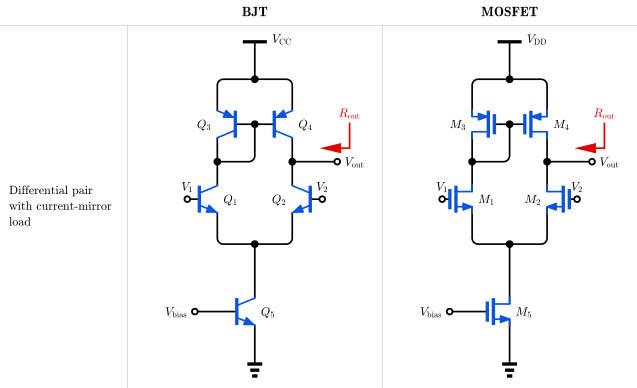

In [10]:
# HIDE/SHOW
show(C.pair_mirror_load)

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 97**

| | BJT |
|---|---|
| **Problem** | An npn differential pair with a pnp current-mirror load carries $I_{E1}=I_{E2}=0.25\,\mathrm{mA}$. All transistors have $\lvert V_A\rvert=10\,\mathrm{V}$ and $\beta=100$; $V_T=25\,\mathrm{mV}$. Find $g_m$, $r_o$, the differential input resistance $R_{id}$, the output resistance $R_o$, the differential gain $A_d$, and the gain $G_v$ when the stage drives a load equal to its own input resistance $R_L=R_{id}$. |
| **Given** | $I_E=0.25\,\mathrm{mA}$, $\lvert V_A\rvert=10\,\mathrm{V}$, $\beta=100$, $V_T=25\,\mathrm{mV}$, $R_L=R_{id}$ |
| **Answer 1** | **Collector current.** $I_{C1}$ $=I_{C2}\simeq I_E$ $=0.25\,\mathrm{mA}$ ($\alpha\approx1$). |
| **Answer 2** | **Transconductance.** $g_{m1,2}$ $=\dfrac{I_C}{V_T}$ $=\dfrac{0.25}{0.025}$ $=10\,\mathrm{mA/V}$. |
| **Answer 3** | **Output resistance of a transistor.** $r_o$ $=\dfrac{\lvert V_A\rvert}{I_C}$ $=\dfrac{10}{0.25}$ $=40\,\mathrm{k}\Omega$. |
| **Answer 4** | **Differential input resistance.** $R_{id}$ $=2r_\pi$ $=\dfrac{2\beta}{g_m}$ $=2\times\dfrac{100}{10}$ $=20\,\mathrm{k}\Omega$. |
| **Answer 5** | **Output resistance.** $R_o$ $=r_{o2}\parallel r_{o4}$ $=40\parallel40$ $=20\,\mathrm{k}\Omega$. |
| **Answer 6** | **Open-circuit differential gain.** $A_d$ $=G_mR_o$ $=10\times20$ $=200\,\mathrm{V/V}$. |
| **Answer 7** | **Loaded gain.** $R_L=R_{id}=20\,\mathrm{k}\Omega$: $G_v$ $=A_d\dfrac{R_L}{R_L+R_o}$ $=200\times\dfrac{20}{40}$ $=100\,\mathrm{V/V}$. |
| **Result** | $g_m=10\,\mathrm{mA/V}$, $r_o=40\,\mathrm{k}\Omega$, $R_{id}=20\,\mathrm{k}\Omega$, $R_o=20\,\mathrm{k}\Omega$, $A_d=200\,\mathrm{V/V}$, $G_v=100\,\mathrm{V/V}$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 80**

| | MOSFET |
|---|---|
| **Problem** | The MOS pair with PMOS mirror load of the problem "Differential Pair with Current-Mirror Load" of the Problem Sets page ($I_D=0.4\,\mathrm{mA}$, $V_{OV}=0.2\,\mathrm{V}$, $G_{md}=4\,\mathrm{mA/V}$, $A_d=100\,\mathrm{V/V}$) has a tail current source of output resistance $R_{SS}=25\,\mathrm{k}\Omega$. The mirror load devices have $g_{m3}=4\,\mathrm{mA/V}$ ($k_p^\prime(W/L)$ $=0.1\,\mathrm{mA/V^2}\times200$ at $0.4\,\mathrm{mA}$). Find $A_{cm}$ and the CMRR. |
| **Given** | $G_{md}=4\,\mathrm{mA/V}$, $A_d=100$, $R_{SS}=25\,\mathrm{k}\Omega$, $g_{m3}=4\,\mathrm{mA/V}$ |
| **Answer 1** | **Load transconductance.** $g_{m3}$ $=\sqrt{2k_p^\prime(W/L)_pI_D}$ $=\sqrt{2\times0.1\times200\times0.4}$ $=4\,\mathrm{mA/V}$. |
| **Answer 2** | **Common-mode gain.** For the mirror-loaded pair $\lvert A_{cm}\rvert\simeq\dfrac1{2g_{m3}R_{SS}}$ $=\dfrac1{2\times4\times25}$ $=0.005\,\mathrm{V/V}$. |
| **Answer 3** | **CMRR.** $\mathrm{CMRR}$ $=\dfrac{\lvert A_d\rvert}{\lvert A_{cm}\rvert}$ $=\dfrac{100}{0.005}$ $=20\,000$, i.e. $20\log(20\,000)=86\,\mathrm{dB}$. |
| **Result** | $\lvert A_{cm}\rvert$ $=0.005\,\mathrm{V/V}$, $\mathrm{CMRR}=20\,000$ ($86\,\mathrm{dB}$) |

**Problem 81**

| | MOSFET |
|---|---|
| **Problem** | An NMOS differential pair with a PMOS current-mirror load is biased at tail current $I$ with overdrive $V_{OV}=0.25\,\mathrm{V}$. The Early voltage per unit length is $\lvert V_A^{\prime}\rvert$ $=5\,\mathrm{V/\mu m}$ and all channel lengths are $L=0.5\,\mu\mathrm{m}$. Find $G_m$ and $R_o$ in terms of $I$, and show that the differential gain $A_d$ does not depend on $I$; evaluate it. |
| **Given** | $V_{OV}=0.25\,\mathrm{V}$, $\lvert V_A\rvert$ $=\lvert V_A^{\prime}\rvert L$ $=5\times0.5$ $=2.5\,\mathrm{V}$ |
| **Answer 1** | **Transconductance.** Each pair transistor carries $I/2$: $G_m$ $=g_{m1,2}$ $=\dfrac{2(I/2)}{V_{OV}}$ $=\dfrac{I}{0.25}$. |
| **Answer 2** | **Early voltage.** $\lvert V_A\rvert$ $=5\,\mathrm{V/\mu m}\times0.5\,\mu\mathrm{m}$ $=2.5\,\mathrm{V}$. |
| **Answer 3** | **Output resistances.** $r_{o2}$ $=r_{o4}$ $=\dfrac{\lvert V_A\rvert}{I/2}$ $=\dfrac{5}{I}$ (with $I$ in mA the result is in k$\Omega$). |
| **Answer 4** | **Output resistance of the stage.** $R_o$ $=r_{o2}\parallel r_{o4}$ $=\dfrac{5}{2I}$ $=\dfrac{2.5}{I}$. |
| **Answer 5** | **Gain.** $A_d$ $=G_mR_o$ $=\dfrac{I}{0.25}\cdot\dfrac{2.5}{I}$ $=10\,\mathrm{V/V}$; $I$ cancels, so $A_d$ $=\dfrac{\lvert V_A\rvert}{V_{OV}}$ is independent of the bias current. |
| **Answer 6** | **Numerical check.** For $I=0.1,\,0.2,\,0.5\,\mathrm{mA}$ the computed $A_d$ is $10.0$ each time. |
| **Result** | $G_m$ $=4I\,(\mathrm{mA/V\ for\ I\ in\ mA})$, $R_o=2.5/I\,\mathrm{k}\Omega$, $A_d=10\,\mathrm{V/V}$ for any $I$ |

**Problem 82**

| | MOSFET |
|---|---|
| **Problem** | An NMOS pair with a PMOS mirror load carries a tail current $I=0.2\,\mathrm{mA}$. The NMOS devices have $\mu_nC_{ox}=0.4\,\mathrm{mA/V^2}$ and $W/L=20$, i.e. $k_n(W/L)=8\,\mathrm{mA/V^2}$; the Early voltage per micrometer is $\lvert V_A^{\prime}\rvert$ $=6\,\mathrm{V/\mu m}$ with $L=0.5\,\mu\mathrm{m}$. Find $V_{OV}$, $g_m$, $r_o$ of the pair and mirror transistors, and the differential gain $A_d$. |
| **Given** | $I=0.2\,\mathrm{mA}$, $\mu_nC_{ox}=0.4\,\mathrm{mA/V^2}$, $W/L=20$, $\lvert V_A^{\prime}\rvert$ $=6\,\mathrm{V/\mu m}$, $L=0.5\,\mu\mathrm{m}$ |
| **Answer 1** | **Overdrive voltage.** $\dfrac I2$ $=\dfrac12\mu_nC_{ox}\dfrac WL V_{OV}^2\Rightarrow 0.1$ $=\tfrac12(0.4)(20)V_{OV}^2$, so $V_{OV}=0.158\,\mathrm{V}$. |
| **Answer 2** | **Transconductance.** $g_{m1,2}$ $=\dfrac{2(I/2)}{V_{OV}}$ $=\dfrac{0.2}{0.158}$ $=1.26\,\mathrm{mA/V}$. |
| **Answer 3** | **Output resistances.** $\lvert V_A\rvert$ $=6\times0.5$ $=3\,\mathrm{V}$; $r_{o2}$ $=r_{o4}$ $=\dfrac{\lvert V_A\rvert}{I/2}$ $=\dfrac{3}{0.1}$ $=30\,\mathrm{k}\Omega$. |
| **Answer 4** | **Gain.** $A_d$ $=g_{m1,2}(r_{o2}\parallel r_{o4})$ $=1.26\times15\,\mathrm{k}\Omega$ $=19.0\,\mathrm{V/V}$. |
| **Result** | $V_{OV}=0.158\,\mathrm{V}$, $g_m=1.26\,\mathrm{mA/V}$, $r_o=30\,\mathrm{k}\Omega$, $A_d=19.0\,\mathrm{V/V}$ |

**Problem 83**

| | MOSFET |
|---|---|
| **Problem** | A MOS differential pair with a current-mirror load has $k_n(W/L)=4\,\mathrm{mA/V^2}$ and $\lvert V_A\rvert=5\,\mathrm{V}$. What tail current $I$ gives a differential gain $A_d=20\,\mathrm{V/V}$? |
| **Given** | $k_n\dfrac WL=4\,\mathrm{mA/V^2}$, $\lvert V_A\rvert=5\,\mathrm{V}$, $A_d=20$ |
| **Answer 1** | **Gain formula.** $A_d$ $=g_{m1,2}(r_{o2}\parallel r_{o4})$ with $r_{o2}=r_{o4}$. |
| **Answer 2** | **Transconductance.** $g_{m1,2}=\sqrt{2k_n(W/L)I_D}$ with $I_D=I/2$: $g_m=\sqrt{4I}=2\sqrt I$. |
| **Answer 3** | **Output resistances.** $r_{o2}$ $=r_{o4}$ $=\dfrac{\lvert V_A\rvert}{I/2}$ $=\dfrac{10}{I}$, so $r_{o2}\parallel r_{o4}=\dfrac5I$. |
| **Answer 4** | **Gain versus I.** $A_d$ $=2\sqrt I\cdot\dfrac5I$ $=\dfrac{10}{\sqrt I}$. |
| **Answer 5** | **Solve.** $20$ $=\dfrac{10}{\sqrt I}\Rightarrow\sqrt I$ $=0.5\Rightarrow I$ $=0.25\,\mathrm{mA}$. |
| **Answer 6** | **Check.** At $I=0.25\,\mathrm{mA}$: $g_m=1\,\mathrm{mA/V}$, $r_o=40\,\mathrm{k}\Omega$, $A_d=1\times20=20$. |
| **Result** | $I=0.25\,\mathrm{mA}$ |

**Problem 84**

| | MOSFET |
|---|---|
| **Problem** | A MOS differential pair (NMOS, with a PMOS mirror load) is biased with $I=0.2\,\mathrm{mA}$ at $V_{OV}=0.2\,\mathrm{V}$. The Early voltages are $V_{An}=20\,\mathrm{V}$ for the NMOS and $\lvert V_{Ap}\rvert=12\,\mathrm{V}$ for the PMOS devices. Find $G_m$, $R_o$, $A_d$, and the gain when the stage drives a load $R_L=R_o$. |
| **Given** | $I=0.2\,\mathrm{mA}$, $V_{OV}=0.2\,\mathrm{V}$, $V_{An}=20\,\mathrm{V}$, $\lvert V_{Ap}\rvert=12\,\mathrm{V}$ |
| **Answer 1** | **Transconductance.** $G_m$ $=g_{m1,2}$ $=\dfrac{2(I/2)}{V_{OV}}$ $=\dfrac{0.2}{0.2}$ $=1\,\mathrm{mA/V}$. |
| **Answer 2** | **Output resistances.** $r_{o2}$ $=\dfrac{V_{An}}{I/2}$ $=\dfrac{20}{0.1}$ $=200\,\mathrm{k}\Omega$, $r_{o4}$ $=\dfrac{\lvert V_{Ap}\rvert}{I/2}$ $=\dfrac{12}{0.1}$ $=120\,\mathrm{k}\Omega$. |
| **Answer 3** | **Stage output resistance.** $R_o$ $=r_{o2}\parallel r_{o4}$ $=75\,\mathrm{k}\Omega$. |
| **Answer 4** | **Open-circuit gain.** $A_d$ $=G_mR_o$ $=1\times75$ $=75\,\mathrm{V/V}$. |
| **Answer 5** | **Loaded gain.** $A_v$ $=A_d\dfrac{R_L}{R_L+R_o}$ $=75\times\dfrac12$ $=37.5\,\mathrm{V/V}$ for $R_L=R_o=75\,\mathrm{k}\Omega$: the gain halves. |
| **Result** | $G_m=1\,\mathrm{mA/V}$, $R_o=75\,\mathrm{k}\Omega$, $A_d=75\,\mathrm{V/V}$; with $R_L=75\,\mathrm{k}\Omega$: $37.5\,\mathrm{V/V}$ |

**Problem 85**

| | MOSFET |
|---|---|
| **Problem** | An NMOS pair with a PMOS mirror load runs from $V_{DD}=0.8\,\mathrm{V}$ (input common-mode level 0 V) at $I=0.2\,\mathrm{mA}$ with $\lvert V_{OV}\rvert$ $=0.15\,\mathrm{V}$ for all devices. The process has $\mu_nC_{ox}=0.5\,\mathrm{mA/V^2}$, $\mu_pC_{ox}=0.125\,\mathrm{mA/V^2}$, $V_{tn}=0.4\,\mathrm{V}$, $\lvert V_A^{\prime}\rvert$ $=15\,\mathrm{V/\mu m}$. A differential gain $A_d=60\,\mathrm{V/V}$ is required. (a) Find $W/L$ of the pair and of the mirror. (b) Find $G_{md}$ and the channel length $L$ needed. (c) Find the output voltage range. (d) Find the common-mode rejection ratio if the tail source has $R_{SS}=\lvert V_A\rvert/I$. |
| **Given** | $I=0.2\,\mathrm{mA}$, $\lvert V_{OV}\rvert$ $=0.15\,\mathrm{V}$, $\mu_nC_{ox}=0.5$, $\mu_pC_{ox}=0.125\,\mathrm{mA/V^2}$, $V_{DD}=0.8\,\mathrm{V}$, $V_{tn}=0.4\,\mathrm{V}$, $\lvert V_A^{\prime}\rvert$ $=15\,\mathrm{V/\mu m}$, $A_d=60$ |
| **Answer 1** | **(a) W/L of Q1,Q2.** $\dfrac I2$ $=\tfrac12\mu_nC_{ox}\dfrac WL V_{OV}^2\Rightarrow0.1$ $=\tfrac12(0.5)\dfrac WL(0.15)^2$, so $(W/L)_{1,2}=17.8$. |
| **Answer 2** | **(a) W/L of Q3,Q4.** $0.1$ $=\tfrac12(0.125)\dfrac WL(0.15)^2\Rightarrow(W/L)_{3,4}$ $=71.1$. |
| **Answer 3** | **(b) Transconductance.** $G_{md}$ $=g_{m1,2}$ $=\dfrac{I}{V_{OV}}$ $=\dfrac{0.2}{0.15}$ $=1.33\,\mathrm{mA/V}$. |
| **Answer 4** | **(b) Required output resistance.** $R_o$ $=\dfrac{A_d}{G_{md}}$ $=\dfrac{60}{1.333}$ $=45\,\mathrm{k}\Omega$; since $r_{o2}=r_{o4}$, $r_o=2R_o=90\,\mathrm{k}\Omega$. |
| **Answer 5** | **(b) Early voltage and length.** $\lvert V_A\rvert$ $=r_o\dfrac I2$ $=90\times0.1$ $=9\,\mathrm{V}$, so $L=\dfrac{9}{15}=0.6\,\mu\mathrm{m}$. |
| **Answer 6** | **(c) Output range.** Lower limit: $v_{O\min}$ $=V_{CM}-V_{tn}$ $=0-0.4$ $=-0.4\,\mathrm{V}$; upper limit: $v_{O\max}$ $=V_{DD}-\lvert V_{OV}\rvert$ $=0.8-0.15$ $=0.65\,\mathrm{V}$. |
| **Answer 7** | **(d) Tail resistance.** $R_{SS}$ $=\dfrac{\lvert V_A\rvert}{I}$ $=\dfrac{9}{0.2}$ $=45\,\mathrm{k}\Omega$. |
| **Answer 8** | **(d) CMRR.** $\mathrm{CMRR}$ $=(2g_mR_{SS})\,[g_{m3}(r_{o2}\parallel r_{o4})]$ $=(g_mR_{SS})(g_mr_o)$ $=(1.333\times45)(1.333\times90)$ $=7200$, i.e. $77.1\,\mathrm{dB}$. |
| **Result** | $(W/L)_{1,2}=17.8$, $(W/L)_{3,4}=71.1$, $G_{md}=1.33\,\mathrm{mA/V}$, $L=0.6\,\mu\mathrm{m}$, $-0.4\,\mathrm{V}\le v_O\le0.65\,\mathrm{V}$, $\mathrm{CMRR}$ $=7200\ (77.1\,\mathrm{dB})$ |

**Problem 86**

| | MOSFET |
|---|---|
| **Problem** | A mirror-loaded NMOS pair is biased at $I=0.2\,\mathrm{mA}$ with $V_{OV}=0.2\,\mathrm{V}$ and $\lvert V_A\rvert=6\,\mathrm{V}$ for all devices; the tail source output resistance is $R_{SS}=\lvert V_A\rvert/I$. Find $G_{md}$, $R_o$, $A_d$, the mirror input resistance $R_{im}$ and gain $A_m$, the common-mode transconductance $G_{mcm}$, the common-mode gain $A_{cm}$ and the CMRR. |
| **Given** | $I=0.2\,\mathrm{mA}$, $V_{OV}=0.2\,\mathrm{V}$, $\lvert V_A\rvert=6\,\mathrm{V}$, $R_{SS}=\lvert V_A\rvert/I$ |
| **Answer 1** | **Differential transconductance.** $G_{md}$ $=g_{m1,2}$ $=\dfrac{I}{V_{OV}}$ $=1\,\mathrm{mA/V}$. |
| **Answer 2** | **Output resistances.** $r_{o2}$ $=r_{o4}$ $=\dfrac{6}{0.1}$ $=60\,\mathrm{k}\Omega$, so $R_o=30\,\mathrm{k}\Omega$. |
| **Answer 3** | **Differential gain.** $A_d=G_{md}R_o=30\,\mathrm{V/V}$; tail resistance $R_{SS}$ $=\dfrac{6}{0.2}$ $=30\,\mathrm{k}\Omega$. |
| **Answer 4** | **Mirror input resistance.** $R_{im}$ $=\dfrac1{g_{m3}}\parallel r_{o3}$ $=1\,\mathrm{k}\Omega\parallel60\,\mathrm{k}\Omega$ $=0.984\,\mathrm{k}\Omega$. |
| **Answer 5** | **Mirror gain.** $A_m$ $=\dfrac{1}{1+1/(g_{m3}r_{o3})}$ $=\dfrac1{1+1/60}$ $=0.984$. |
| **Answer 6** | **Common-mode transconductance.** $G_{mcm}\simeq-\dfrac{1}{2R_{SS}}\dfrac{1}{g_{m3}(r_o\parallel r_{o3})}$ $=-\dfrac{1}{60}\cdot\dfrac{1}{30}$ $=-5.56\times10^{-4}\,\mathrm{mA/V}$. |
| **Answer 7** | **Common-mode gain.** $A_{cm}$ $=G_{mcm}R_o$ $=-\dfrac{1}{2g_{m3}R_{SS}}$ $=-0.0167\,\mathrm{V/V}$. |
| **Answer 8** | **CMRR.** $\mathrm{CMRR}$ $=\dfrac{\lvert A_d\rvert}{\lvert A_{cm}\rvert}$ $=\dfrac{30}{0.0167}$ $=1800$, i.e. $65.1\,\mathrm{dB}$. |
| **Answer 9** | **Independent check.** A nodal solution of the whole small-signal circuit gives $A_d=29.8$, $\lvert A_{cm}\rvert=0.0159$, CMRR $=1876$ ($65.5\,\mathrm{dB}$), within 4 percent. |
| **Result** | $G_{md}=1\,\mathrm{mA/V}$, $R_o=30\,\mathrm{k}\Omega$, $A_d=30$, $R_{im}=0.984\,\mathrm{k}\Omega$, $A_m=0.984$, $G_{mcm}$ $=-5.56\times10^{-4}\,\mathrm{mA/V}$, $A_{cm}=-0.0167$, CMRR $=1800$ ($65.1\,\mathrm{dB}$) |

**Problem 87**

| | MOSFET |
|---|---|
| **Problem** | A mirror-loaded differential stage has $G_m=2\,\mathrm{mA/V}$. When it drives a $20\,\mathrm{k}\Omega$ load the output voltage is half of the open-circuit value. Find the stage output resistance $R_o$ and the open-circuit differential gain. |
| **Given** | $G_m=2\,\mathrm{mA/V}$, $R_L=20\,\mathrm{k}\Omega$, $v_o(R_L)=\tfrac12v_o(\infty)$ |
| **Answer 1** | **Open circuit.** $v_o=G_mR_ov_{id}$, so $A_d=G_mR_o$. |
| **Answer 2** | **Loaded.** $v_o$ $=G_mR_ov_{id}\dfrac{R_L}{R_L+R_o}$ (a voltage divider with the output resistance). |
| **Answer 3** | **Condition.** $\dfrac{R_L}{R_L+R_o}$ $=\dfrac12\Rightarrow R_o$ $=R_L$ $=20\,\mathrm{k}\Omega$. |
| **Answer 4** | **Gain.** $A_d$ $=G_mR_o$ $=2\times20$ $=40\,\mathrm{V/V}$. |
| **Result** | $R_o=20\,\mathrm{k}\Omega$, $A_d=40\,\mathrm{V/V}$ |

**Problem 88**

| | MOSFET |
|---|---|
| **Problem** | In a mirror-loaded NMOS pair (PMOS mirror $Q_3,Q_4$, ideal tail source, output open) a differential input $v_{id}$ is applied: $+v_{id}/2$ at the gate of $Q_1$ and $-v_{id}/2$ at the gate of $Q_2$. Assume $g_mr_o\gg1$. Explain the large imbalance that exists between the two halves of the circuit, in particular in the mirror, even though the mirror drain currents are equal. |
| **Given** | $g_mr_o\gg1$, $v_{id}$ split as $\pm v_{id}/2$, ideal tail source, output open |
| **Answer 1** | **Tail node.** The tail current is constant, so the source node moves just enough to keep $i_{D1}+i_{D2}=0$ in the signal: $v_s=+v_{id}/4$ (first-order, $g_mr_o\gg1$). |
| **Answer 2** | **Gate-source signals of the pair.** $v_{gs1}$ $=\tfrac{v_{id}}2-\tfrac{v_{id}}4$ $=+\tfrac{v_{id}}4$ and $v_{gs2}$ $=-\tfrac{v_{id}}2-\tfrac{v_{id}}4$ $=-\tfrac34v_{id}$: $Q_2$ sees three times the signal of $Q_1$. |
| **Answer 3** | **Mirror node.** $Q_1$ delivers a drain current $\tfrac14g_mv_{id}$ into the diode-connected $Q_3$, so $v_{g3}=-v_{id}/4$; the mirror makes the channel current of $Q_4$ the same $\tfrac14g_mv_{id}$, so the mirror works as designed in its channel currents. |
| **Answer 4** | **Output node.** $Q_2$ has channel current $\tfrac34g_mv_{id}$, of which $\tfrac12g_mv_{id}$ flows back through its $r_o$, leaving a net $\tfrac14g_mv_{id}$ at the drain. The output voltage is $v_o=\tfrac12(g_mr_o)v_{id}$, so $r_o$ of $Q_4$ carries $\tfrac12g_mv_{id}$. |
| **Answer 5** | **The imbalance.** The $r_o$ of $Q_3$ carries almost nothing while the $r_o$ of $Q_4$ carries $\tfrac12g_mv_{id}$, and $Q_1,Q_2$ have $\lvert v_{gs}\rvert$ of $\tfrac14v_{id}$ and $\tfrac34v_{id}$. A diode-connected mirror input sits near $-v_{id}/4$ while the output node sits at $\tfrac12g_mr_ov_{id}$: the two sides of the load are not balanced. |
| **Answer 6** | **Consequence.** The mirror is not a balanced load; the approximations ($g_mr_o\gg1$) leave small inconsistencies in the currents, but the circuit still gives a reasonably high CMRR. |
| **Answer 7** | **Numerical check.** A nodal solution with $g_m=1\,\mathrm{mA/V}$, $r_o=200\,\mathrm{k}\Omega$ gives $v_s=0.2475v_{id}$, $v_{gs1}=0.2525v_{id}$, $v_{gs2}=-0.7475v_{id}$, $v_{g3}=-0.2488v_{id}$, $v_o=99.75v_{id}$ (formula 100), $r_o$ currents $0.498$ ($Q_2$), $-0.499$ ($Q_4$), $0.001$ ($Q_3$) in units of $g_mv_{id}$. |
| **Result** | Qualitative: the mirror gives equal drain currents $\tfrac14g_mv_{id}$ but its two transistors have very unequal $r_o$ currents ($0$ against $\tfrac12g_mv_{id}$) and the pair has $\lvert v_{gs}\rvert=\tfrac14v_{id}$ against $\tfrac34v_{id}$, so the load is strongly unbalanced |
````
`````

### Other Circuits

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 98**

| | BJT |
|---|---|
| **Problem** | The circuit: npn pair $Q_1$, $Q_2$ with emitters joined to an ideal tail current $I_{EE}$; load is a pnp mirror, $Q_3$ diode-connected on the collector of $Q_1$, $Q_4$ (bases tied to $Q_3$, emitters at $V_{CC}$) on the collector of $Q_2$, which is the single-ended output. The small-signal gain $v_{out}/(v_{in1}-v_{in2})$ must be 100. With $V_{A,n}=5\,\mathrm{V}$, what Early voltage do the pnp transistors need? |
| **Given** | $A_v=100$, $V_{A,n}=5\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Gain of the active-load pair.** $A_v=g_{m1}(r_{O2}\parallel r_{O4})$ with $g_{m1}=\dfrac{I_{EE}}{2V_T}$, $r_{O2}=\dfrac{V_{A,n}}{I_{EE}/2}$, $r_{O4}=\dfrac{V_{A,p}}{I_{EE}/2}$ |
| **Answer 2** | **Current cancels.** $A_v$ $=\dfrac{1}{V_T}\,\dfrac{V_{A,n}V_{A,p}}{V_{A,n}+V_{A,p}}$, independent of $I_{EE}$ |
| **Answer 3** | **Required combination.** $\dfrac{V_{A,n}V_{A,p}}{V_{A,n}+V_{A,p}}$ $=100\times26\,\mathrm{mV}$ $=2.6\,\mathrm{V}$ |
| **Answer 4** | **Solve for $V_{A,p}$.** $V_{A,p}$ $=\dfrac{2.6\cdot5}{5-2.6}$ $=5.42\,\mathrm{V}$ |
| **Result** | $V_{A,p}\approx5.42\,\mathrm{V}$ (for any $I_{EE}$) |

**Problem 99**

| | BJT |
|---|---|
| **Problem** | Design the bipolar differential pair with active load (npn pair $Q_1$, $Q_2$ with tail current $I_{EE}$; pnp mirror load, $Q_3$ diode-connected on the collector of $Q_1$, $Q_4$ driving the single-ended output at the collector of $Q_2$) for a voltage gain of 200 and a power budget of 3 mW with a 2.5-V supply, assuming $V_{A,n}=2V_{A,p}$. |
| **Given** | $\lvert A_v\rvert=200$, $P=3\,\mathrm{mW}$, $V_{CC}=2.5\,\mathrm{V}$, $V_{A,n}=2V_{A,p}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Tail current.** $I_{EE}$ $=3\,\mathrm{mW}/2.5\,\mathrm{V}$ $=1.2\,\mathrm{mA}$, $I_C=0.6\,\mathrm{mA}$ per side, $g_m=23.1\,\mathrm{mS}$ |
| **Answer 2** | **Gain.** $\lvert A_v\rvert$ $=g_{mN}(r_{ON}\parallel r_{OP})$ $=\dfrac1{V_T}\,\dfrac{V_{A,n}V_{A,p}}{V_{A,n}+V_{A,p}}$ $=\dfrac{2V_{A,p}}{3V_T}$ |
| **Answer 3** | **Early voltages.** $V_{A,p}$ $=\dfrac{3\times200\times26\,\mathrm{mV}}{2}$ $=7.80\,\mathrm{V}$, $V_{A,n}=15.6\,\mathrm{V}$ |
| **Answer 4** | **Resistances.** $r_{ON}$ $=15.6/0.6\,\mathrm{mA}$ $=26.0\,\mathrm{k}\Omega$, $r_{OP}=13.0\,\mathrm{k}\Omega$, $r_{ON}\parallel r_{OP}$ $=8.67\,\mathrm{k}\Omega$; gain $23.1\,\mathrm{mS}\times8.67\,\mathrm{k}\Omega$ $=200$ |
| **Answer 5** | **Bias levels.** The output sits near $V_{CC}-V_{EB}$ $\approx1.7\,\mathrm{V}$ (symmetry with the diode node), so the input CM must stay below about $1.7\,\mathrm{V}$ to keep $Q_2$ active. |
| **Result** | $I_{EE}=1.2\,\mathrm{mA}$; devices with $V_{A,p}=7.80\,\mathrm{V}$, $V_{A,n}=15.6\,\mathrm{V}$ |

**Problem 100**

| | BJT |
|---|---|
| **Problem** | An npn differential amplifier has pnp current-source loads $Q_3,Q_4$ (bases at fixed dc voltages) and a tail current source $Q_5$ giving $I=200\,\mathrm{\mu A}$; $V_A=10\,\mathrm{V}$ for all devices and $\beta=100$, $V_T=25\,\mathrm{mV}$. Find $I_C$, $g_m$, $r_o$, $r_e$, the differential gain $A_d$ (output taken between the collectors), the differential input resistance $R_{id}$, $R_{EE}$, the CMRR if the total load resistance is mismatched by $1\%$, and the common-mode input resistance $R_{icm}$. |
| **Given** | $I=200\,\mathrm{\mu A}$, $V_A=10\,\mathrm{V}$, $\beta=100$, $V_T=25\,\mathrm{mV}$, load $R_C=r_{o}$ of the pnp $=100\,\mathrm{k}\Omega$ |
| **Answer 1** | **Bias.** $\beta\gg1$: $I_{C1}\simeq I_{C2}\simeq I/2$ $=100\,\mathrm{\mu A}$. |
| **Answer 2** | **Small-signal parameters.** $g_m$ $=\dfrac{I_C}{V_T}$ $=\dfrac{0.1}{0.025}$ $=4\,\mathrm{mA/V}$; $r_e$ $=\dfrac{V_T}{I_E}$ $=\dfrac{25\,\mathrm{mV}}{0.1\,\mathrm{mA}}$ $=0.25\,\mathrm{k}\Omega$; $r_o$ $=\dfrac{V_A}{I_C}$ $=\dfrac{10}{0.1}$ $=100\,\mathrm{k}\Omega$ (also the pnp load: $R_C=100\,\mathrm{k}\Omega$). |
| **Answer 3** | **Differential gain.** $\lvert A_d\rvert$ $=\dfrac{R_C\parallel r_o}{r_e}$ $=\dfrac{100\parallel100}{0.25}$ $=\dfrac{50}{0.25}$ $=200\,\mathrm{V/V}$ $(=g_m\times50\,\mathrm{k}\Omega)$. |
| **Answer 4** | **Input resistance.** $r_\pi$ $=\dfrac{\beta}{g_m}$ $=\dfrac{100}{4}$ $=25\,\mathrm{k}\Omega$; $R_{id}=2r_\pi=50\,\mathrm{k}\Omega$. |
| **Answer 5** | **Tail resistance.** $R_{EE}$ $=\dfrac{V_A}{I}$ $=\dfrac{10}{0.2\,\mathrm{mA}}$ $=50\,\mathrm{k}\Omega$. |
| **Answer 6** | **CMRR.** With $\Delta R_C/R_C=1\%$: $\lvert A_{cm}\rvert$ $=\dfrac{R_C}{2R_{EE}}\dfrac{\Delta R_C}{R_C}$ $=\dfrac{100}{2\times50}\times0.01$ $=0.01$, so $\mathrm{CMRR}$ $=\dfrac{200}{0.01}$ $=20\,000$ $=86\,\mathrm{dB}$. |
| **Answer 7** | **Common-mode input resistance.** $R_{icm}\simeq\beta R_{EE}\dfrac{1+\dfrac{R_C}{\beta r_o}}{1+\dfrac{R_C+2R_{EE}}{r_o}}$ $=100\times50\,\mathrm{k}\Omega\times\dfrac{1.01}{3}$ $=1.68\,\mathrm{M}\Omega$. |
| **Result** | $g_m=4\,\mathrm{mA/V}$, $r_o=100\,\mathrm{k}\Omega$, $r_e=0.25\,\mathrm{k}\Omega$, $A_d=200$, $R_{id}=50\,\mathrm{k}\Omega$, $R_{EE}=50\,\mathrm{k}\Omega$, $\mathrm{CMRR}=86\,\mathrm{dB}$, $R_{icm}$ $\approx1.68\,\mathrm{M}\Omega$ |

**Problem 101**

| | BJT |
|---|---|
| **Problem** | A differential pair of npn transistors $Q_1,Q_2$ with tail current $I$ has pnp current-source loads $Q_3,Q_4$ (bases biased by $V_{BIAS}$) in place of resistors, output taken differentially between the collectors. All transistors have the same $\lvert V_A\rvert$ and $\alpha\approx1$. Show that $A_d=V_A/(2V_T)$ and evaluate it for $\lvert V_A\rvert=20\,\mathrm{V}$ ($V_T=25\,\mathrm{mV}$). |
| **Given** | $\lvert V_A\rvert=20\,\mathrm{V}$ for all four transistors, $V_T=25\,\mathrm{mV}$, $\alpha\approx1$ |
| **Answer 1** | **Half circuit.** For differential input the half circuit is $Q_1$ with load $Q_3$; each carries $I/2$ and $A_d=g_{m1}(r_{o1}\parallel r_{o3})$. |
| **Answer 2** | **Transconductance.** $g_{m1}$ $=\dfrac{I/2}{V_T}$ $=\dfrac{I}{2V_T}$ |
| **Answer 3** | **Output resistances.** $r_{o1}$ $=r_{o3}$ $=\dfrac{V_A}{I/2}$ $=\dfrac{2V_A}{I}$, so $r_{o1}\parallel r_{o3}$ $=\dfrac{V_A}{I}$ |
| **Answer 4** | **Gain.** $A_d$ $=\dfrac{I}{2V_T}\cdot\dfrac{V_A}{I}$ $=\dfrac{V_A}{2V_T}$ (independent of $I$) |
| **Answer 5** | **Numbers.** $A_d$ $=\dfrac{20}{2\times0.025}$ $=400\,\mathrm{V/V}$ |
| **Result** | $A_d$ $=\dfrac{V_A}{2V_T}$ $=400\,\mathrm{V/V}$ |

**Problem 102**

| | BJT and MOSFET |
|---|---|
| **Problem** | A PMOS differential pair (with $k_p(W/L)=6.4\,\mathrm{mA/V^2}$) has an npn bipolar current-mirror load. The tail current is $I=0.2\,\mathrm{mA}$; the PMOS Early voltage is $\lvert V_{Ap}\rvert=10\,\mathrm{V}$ and the npn Early voltage is $V_A=30\,\mathrm{V}$. Find the overdrive voltage $\lvert V_{OV}\rvert$ of the pair, $G_{md}$, the output resistance $R_o$ and the differential gain $A_d$. |
| **Given** | $I=0.2\,\mathrm{mA}$, $k_p(W/L)=6.4\,\mathrm{mA/V^2}$, $\lvert V_{Ap}\rvert=10\,\mathrm{V}$, $V_{An}=30\,\mathrm{V}$ |
| **Answer 1** | **Overdrive voltage.** $\dfrac I2$ $=\tfrac12k_p\dfrac WL\lvert V_{OV}\rvert^2\Rightarrow0.1$ $=\tfrac12(6.4)\lvert V_{OV}\rvert^2$, so $\lvert V_{OV}\rvert$ $=0.177\,\mathrm{V}$. |
| **Answer 2** | **Transconductance.** $G_{md}$ $=g_{m1,2}$ $=\dfrac{2(I/2)}{\lvert V_{OV}\rvert}$ $=\dfrac{0.2}{0.177}$ $=1.13\,\mathrm{mA/V}$. |
| **Answer 3** | **Output resistances.** $r_{o2}$ $=\dfrac{\lvert V_{Ap}\rvert}{I/2}$ $=\dfrac{10}{0.1}$ $=100\,\mathrm{k}\Omega$ (PMOS), $r_{o4}$ $=\dfrac{V_A}{I/2}$ $=\dfrac{30}{0.1}$ $=300\,\mathrm{k}\Omega$ (npn). |
| **Answer 4** | **Stage output resistance.** $R_o$ $=100\parallel300$ $=75\,\mathrm{k}\Omega$. |
| **Answer 5** | **Gain.** $A_d$ $=G_{md}R_o$ $=1.13\times75$ $=84.9\,\mathrm{V/V}$. |
| **Result** | $\lvert V_{OV}\rvert$ $=0.177\,\mathrm{V}$, $G_{md}=1.13\,\mathrm{mA/V}$, $R_o=75\,\mathrm{k}\Omega$, $A_d=84.9\,\mathrm{V/V}$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 89**

| | MOSFET |
|---|---|
| **Problem** | A CMOS differential pair has NMOS $M_1$, $M_2$ with an ideal tail source and a PMOS current-mirror load: $M_3$ is diode-connected (drain and gate at node $A$, which is the drain of $M_1$), $M_4$ has its gate at $A$ and its drain at the output, which is also the drain of $M_2$; both PMOS sources are at $V_{DD}$. Show that the small-signal voltage at node $A$ is much smaller than the output swing. Take $g_{m3}=g_{m4}=g_{mP}$, $r_{O3}=r_{O4}=r_{OP}$. |
| **Given** | $g_{m3}=g_{m4}=g_{mP}$, $r_{O3}=r_{O4}=r_{OP}$, ideal tail source |
| **Answer 1** | **Current drawn by $M_2$.** KCL at the output: the small-signal current delivered by $M_4$ is $-g_{m4}v_A-v_{out}/r_{O4}$ (its source is at ac ground and its gate is at $v_A$). This must flow down through $M_2$: $i_{D2}$ $=-\dfrac{v_{out}}{r_{O4}}-g_{m4}v_A$. |
| **Answer 2** | **Current through $M_1$ and $M_3$.** The tail source is ideal, so $i_{D1}=-i_{D2}$. This current is supplied by the diode-connected $M_3$, whose resistance is $\dfrac1{g_{m3}}\parallel r_{O3}$. |
| **Answer 3** | **Voltage at $A$.** $v_A$ $=-\left(\dfrac{v_{out}}{r_{O4}}+g_{m4}v_A\right)\left(\dfrac1{g_{m3}}\parallel r_{O3}\right)$. |
| **Answer 4** | **Solve for $v_A$.** With $R$ $=\dfrac1{g_{mP}}\parallel r_{OP}$ $=\dfrac{r_{OP}}{1+g_{mP}r_{OP}}$: $v_A(1+g_{mP}R)$ $=-\dfrac{v_{out}R}{r_{OP}}$, i.e. $v_A$ $=-\dfrac{v_{out}}{1+2g_{mP}r_{OP}}$. |
| **Answer 5** | **Approximation.** Since $g_{mP}r_{OP}\gg1$, $v_A$ $\approx-\dfrac{v_{out}}{2g_{mP}r_{OP}}$, a tiny fraction of $v_{out}$. |
| **Answer 6** | **Numerical check.** $g_{mP}=1\,\mathrm{mS}$, $r_{OP}=50\,\mathrm{k}\Omega$ ($g_{mP}r_{OP}=50$): exact $v_A/v_{out}=-1/101=-0.00990$; approximation $-0.0100$. Substituting back into the KCL equation gives zero residual. |
| **Result** | $v_A$ $\approx-\dfrac{v_{out}}{2g_{mP}r_{OP}}\ll v_{out}$ (exactly $-v_{out}/(1+2g_{mP}r_{OP})$) |

**Problem 90**

| | MOSFET |
|---|---|
| **Problem** | The circuit: PMOS current mirror with sources at $V_{DD}$; $M_3$ is diode-connected and its drain is pulled down by a current source $I_1$ to ground; $M_4$ shares the gate of $M_3$ and drives the output node, which has a resistor $R_L$ to ground. $(W/L)_3=N(W/L)_4$, $\lambda=0$. Find the small-signal gain $v_{out}/i_1$, where $i_1$ is the change in $I_1$. |
| **Given** | $(W/L)_3=N(W/L)_4$, $\lambda=0$; numeric check: $R_L=10\,\mathrm{k}\Omega$, $N=4$ |
| **Answer 1** | **Mirror ratio.** Same $V_{GS}$ and $\lambda=0$: $I_{D4}$ $=\dfrac{(W/L)_4}{(W/L)_3}I_{D3}$ $=\dfrac{I_1}N$, independent of the output voltage |
| **Answer 2** | **Small-signal current.** A change $i_1$ in the diode current gives $i_{d4}=i_1/N$ flowing into $R_L$ |
| **Answer 3** | **Gain.** $v_{out}=R_L\,\dfrac{i_1}N$, so $\dfrac{v_{out}}{i_1}=\dfrac{R_L}N$; numbers: $2.5\,\mathrm{k}\Omega$ |
| **Result** | $v_{out}/i_1=R_L/N$ |

**Problem 91**

| | MOSFET |
|---|---|
| **Problem** | The circuit: PMOS mirror $M_3$ (diode-connected, drain pulled down by a current source $I_1$) and $M_4$ (output); the output node has a current source $I_2$ to ground and a resistor $R_L$ to ground. $I_1$ changes from $I_0$ to $I_0+\Delta I$ and $I_2$ from $I_0$ to $I_0-\Delta I$. With $\lambda=0$, find $V_{out}$ before and after the change for (a) $(W/L)_3=(W/L)_4$, (b) $(W/L)_3=2(W/L)_4$. |
| **Given** | $\lambda=0$; numeric check: $I_0=1\,\mathrm{mA}$, $\Delta I=0.1\,\mathrm{mA}$, $R_L=1\,\mathrm{k}\Omega$ |
| **Answer 1** | **Output node.** KCL: $I_{D4}=I_2+V_{out}/R_L$, so $V_{out}=R_L(I_{D4}-I_2)$ |
| **Answer 2** | **(a) Mirror current.** $I_{D4}=I_1$ |
| **Answer 3** | **(a) Before and after.** Before: $V_{out}=R_L(I_0-I_0)=0$. After: $V_{out}$ $=R_L\left[(I_0+\Delta I)-(I_0-\Delta I)\right]$ $=2R_L\Delta I$ ($0.2\,\mathrm{V}$ with the check values) |
| **Answer 4** | **(b) Mirror current.** $I_{D4}=I_1/2$ |
| **Answer 5** | **(b) Before.** $V_{out}$ $=R_L\left(\dfrac{I_0}2-I_0\right)$ $=-\dfrac{R_LI_0}2$ ($-0.5\,\mathrm{V}$) |
| **Answer 6** | **(b) After.** $V_{out}$ $=R_L\left(\dfrac{I_0+\Delta I}2-I_0+\Delta I\right)$ $=-\dfrac{R_LI_0}2+\dfrac32R_L\Delta I$ ($-0.35\,\mathrm{V}$, a change of $1.5R_L\Delta I$) |
| **Result** | (a) $0\to2R_L\Delta I$; (b) $-R_LI_0/2\to-R_LI_0/2+\tfrac32R_L\Delta I$ |

**Problem 92**

| | MOSFET |
|---|---|
| **Problem** | In the circuit the PMOS $M_3$ is diode-connected (gate tied to drain) and its drain is pulled to ground by the current source $I_1$; $M_4$ has its gate tied to that of $M_3$ and both sources at $V_{DD}$, so it mirrors the current of $M_3$. The drain of $M_4$ is the output node: a current source $I_2$ draws current from it to ground and a load $R_L$ connects it to ground. Neglecting channel-length modulation, find the small-signal gains $v_{out}/i_1$ and $v_{out}/i_2$. |
| **Given** | $\lambda=0$; $M_3$, $M_4$ identical (mirror ratio $K=(W/L)_4/(W/L)_3=1$ unless stated); $i_1$, $i_2$ small changes of $I_1$, $I_2$ |
| **Answer 1** | **Current in $M_3$.** With the gate of $M_3$ at its drain, all of $I_1$ flows through $M_3$: a change $i_1$ in $I_1$ changes $\lvert I_{D3}\rvert$ by $i_1$. |
| **Answer 2** | **Mirror action.** $M_4$ has the same $V_{GS}$ as $M_3$ and $\lambda=0$, so $\lvert i_{D4}\rvert=K\,i_1$, independent of $V_{out}$; $M_4$ is an ideal current source as seen from the output. |
| **Answer 3** | **KCL at the output.** Current from $M_4$ in, $i_2$ out through $I_2$, the rest through $R_L$: $v_{out}=R_L\,(K i_1-i_2)$. |
| **Answer 4** | **Gain from $i_1$.** $\dfrac{v_{out}}{i_1}=K R_L=R_L$ for identical $M_3$, $M_4$. |
| **Answer 5** | **Gain from $i_2$.** $\dfrac{v_{out}}{i_2}=-R_L$: an increase of $I_2$ pulls current away from $R_L$. |
| **Result** | $v_{out}/i_1=R_L$ (in general $K R_L$), $v_{out}/i_2=-R_L$ |

**Problem 93**

| | MOSFET |
|---|---|
| **Problem** | In the circuit an NMOS differential pair $M_1$, $M_2$ (identical) has its sources joined at node $P$, biased by an ideal tail current $I_{SS}$ to ground. Its load is a PMOS mirror: $M_3$ is diode-connected at node $N$ (drain of $M_1$) and $M_4$ (identical to $M_3$, gate tied to $N$) drives node $Y$ (drain of $M_2$); both PMOS sources are at $V_{DD}$. Both gates of $M_1$, $M_2$ are tied to a common-mode source $V_{CM}$. (a) Neglecting channel-length modulation, find the voltage at $N$. (b) Using symmetry, find the voltage at $Y$. (c) What happens to these results if $V_{DD}$ changes by a small $\Delta V$? |
| **Given** | $M_1=M_2$, $M_3=M_4$, inputs at $V_{CM}$, tail $I_{SS}$, PMOS parameters $\mu_pC_{ox}$, $(W/L)_3$, $V_{TH,p}$ |
| **Answer 1** | **Current split.** With equal gate voltages and identical $M_1$, $M_2$: $I_{D1}=I_{D2}=I_{SS}/2$; this current flows through the diode $M_3$. |
| **Answer 2** | **(a) $V_{GS}$ of $M_3$.** $\dfrac{I_{SS}}{2}$ $=\dfrac12\mu_pC_{ox}\left(\dfrac WL\right)_3(\lvert V_{GS3}\rvert-\lvert V_{TH,p}\rvert)^2$ gives $\lvert V_{GS3}\rvert$ $=\lvert V_{TH,p}\rvert+\sqrt{\dfrac{I_{SS}}{\mu_pC_{ox}(W/L)_3}}$ |
| **Answer 3** | **(a) Node $N$.** $V_N$ $=V_{DD}-\lvert V_{TH,p}\rvert-\sqrt{\dfrac{I_{SS}}{\mu_pC_{ox}(W/L)_3}}$; e.g. $V_{DD}=1.8\,\mathrm{V}$, $\lvert V_{TH,p}\rvert$ $=0.4\,\mathrm{V}$, $I_{SS}=1\,\mathrm{mA}$, $\mu_pC_{ox}(W/L)_3$ $=2.5\,\mathrm{mA/V^2}$ give $V_N=0.768\,\mathrm{V}$. |
| **Answer 4** | **(b) Symmetry.** $M_4$ has the same $V_{GS}$ as $M_3$ and must carry the same $I_{SS}/2$ that $M_2$ draws. With $\lambda=0$ this alone does not pin $V_Y$, but with any small $\lambda$ the only consistent solution is $V_{DS4}=V_{DS3}$, i.e. the circuit is fully symmetric. |
| **Answer 5** | **(b) Node $Y$.** $V_Y$ $=V_N$ $=V_{DD}-\lvert V_{TH,p}\rvert-\sqrt{\dfrac{I_{SS}}{\mu_pC_{ox}(W/L)_3}}$ ($0.768\,\mathrm{V}$ in the example). |
| **Answer 6** | **(c) Supply change.** The currents are fixed by $I_{SS}$, so $\lvert V_{GS3}\rvert$ does not change: $V_N$ and $V_Y$ both move by $\Delta V$, following $V_{DD}$ one for one. The CM level at the output tracks the supply (poor supply rejection for the single-ended output). |
| **Result** | $V_N$ $=V_Y$ $=V_{DD}-\lvert V_{TH,p}\rvert-\sqrt{I_{SS}/[\mu_pC_{ox}(W/L)_3]}$; both shift by $\Delta V$ when $V_{DD}$ changes by $\Delta V$ |

**Problem 94**

| | MOSFET |
|---|---|
| **Problem** | For the CMOS pair with active load (NMOS pair $M_1$, $M_2$ with ideal tail $I_{SS}$ at node $P$; PMOS mirror $M_3$ diode-connected at node $A$, $M_4$ driving the output at the drain of $M_2$; $g_{mN}$, $r_{ON}$ for $M_{1,2}$, $g_{mP}$, $r_{OP}$ for $M_{3,4}$), redo the gain analysis, but replace the input pair (between nodes $A$ and $B$=output) by a Norton equivalent instead of a Thevenin one, and find $v_{out}/(v_{in1}-v_{in2})$. |
| **Given** | $v_{in1}=-v_{in2}=v_d/2$, $g_{mN}$, $r_{ON}$, $g_{mP}$, $r_{OP}$; ideal tail |
| **Answer 1** | **Two-terminal network.** The tail source is ideal, so the signal current entering the pair at $A$ leaves it at $B$: the pair is a one-port between $A$ and $B$. |
| **Answer 2** | **Norton resistance.** Inputs at zero, test source between $A$ and $B$: $R_N=R_{Thev}=2r_{ON}$ |
| **Answer 3** | **Norton current.** Short $A$ to $B$: KCL at $P$ gives $(v_A-v_P)/r_{ON}=g_{mN}v_P$, so $i_{D1}=g_{mN}v_d/2=-i_{D2}$. A current $i_N=g_{mN}v_d/2$ enters the pair at $A$ and leaves at $B$ (check: $i_NR_N$ $=g_{mN}r_{ON}v_d$ $=\lvert v_{Thev}\rvert$). |
| **Answer 4** | **KCL at node $A$.** $M_3$ presents $1/g_{mP}\parallel r_{OP}$: $-v_A(g_{mP}+r_{OP}^{-1})$ $=i_N+\dfrac{v_A-v_{out}}{2r_{ON}}$ |
| **Answer 5** | **KCL at the output.** $-g_{mP}v_A-\dfrac{v_{out}}{r_{OP}}+i_N+\dfrac{v_A-v_{out}}{2r_{ON}}$ $=0$; with the node-$A$ equation this becomes $\dfrac{v_{out}}{r_{OP}}$ $=-v_A\left(2g_{mP}+\dfrac1{r_{OP}}\right)$ |
| **Answer 6** | **Small swing at $A$.** For $g_{mP}r_{OP}\gg1$, $2r_{ON}\gg1/g_{mP}$: $v_A$ $\approx\dfrac{v_{out}/(2r_{ON})-i_N}{g_{mP}}$, so $\dfrac{v_{out}}{r_{OP}}$ $\approx2i_N-\dfrac{v_{out}}{r_{ON}}$ |
| **Answer 7** | **Gain.** $v_{out}\left(\dfrac1{r_{OP}}+\dfrac1{r_{ON}}\right)$ $=2i_N$ $=g_{mN}v_d$, so $\dfrac{v_{out}}{v_{in1}-v_{in2}}$ $=g_{mN}(r_{ON}\parallel r_{OP})$ |
| **Answer 8** | **Numerical check.** $g_{mN}=2\,\mathrm{mS}$, $r_{ON}=20\,\mathrm{k}\Omega$, $g_{mP}=1.5\,\mathrm{mS}$, $r_{OP}=15\,\mathrm{k}\Omega$: approximate gain 17.1; the exact Norton model and a full nodal analysis both give 16.8 (difference of order $1/(g_{mP}r_{OP})$). |
| **Result** | $v_{out}/(v_{in1}-v_{in2})$ $\approx g_{mN}(r_{ON}\parallel r_{OP})$, same as the general formula |

**Problem 95**

| | MOSFET |
|---|---|
| **Problem** | Find the small-signal output resistance of the CMOS pair with active load (NMOS pair $M_1$, $M_2$, ideal tail $I_{SS}$; PMOS mirror $M_3$ diode-connected at node $A$, $M_4$ drives the output at the drain of $M_2$), with $g_mr_O\gg1$ for all transistors. |
| **Given** | $g_{mN}$, $r_{ON}$ ($M_1$, $M_2$), $g_{mP}$, $r_{OP}$ ($M_3$, $M_4$), inputs at ac ground, $g_mr_O\gg1$ |
| **Answer 1** | **Test source.** Set $v_{in1}=v_{in2}=0$ and apply $v_X$ at the output; find the current $i_X$ it supplies. |
| **Answer 2** | **Path through $r_{O4}$.** $M_4$ draws $v_X/r_{OP}$ through its own $r_O$. |
| **Answer 3** | **Path through the pair.** Seen from the output, $M_2$, $M_1$ (gates grounded, ideal tail) form the resistance $2r_{ON}$ to node $A$, which sees $1/g_{mP}\parallel r_{OP}$ $\approx1/g_{mP}\ll2r_{ON}$: $i_b\approx\dfrac{v_X}{2r_{ON}}$ |
| **Answer 4** | **Mirror copy.** $i_b$ flows in $M_3$, so $v_A\approx i_b/g_{mP}$, and $M_4$ draws an extra $g_{mP}v_A\approx i_b$ from the output. |
| **Answer 5** | **Total current.** $i_X$ $\approx\dfrac{v_X}{r_{OP}}+2\cdot\dfrac{v_X}{2r_{ON}}$ $=v_X\left(\dfrac1{r_{OP}}+\dfrac1{r_{ON}}\right)$ |
| **Answer 6** | **Output resistance.** $R_{out}$ $\approx r_{ON}\parallel r_{OP}$; with $g_{mN}=2\,\mathrm{mS}$, $r_{ON}=20\,\mathrm{k}\Omega$, $g_{mP}=1.5\,\mathrm{mS}$, $r_{OP}=15\,\mathrm{k}\Omega$: $8.57\,\mathrm{k}\Omega$ (full nodal analysis $8.71\,\mathrm{k}\Omega$). |
| **Result** | $R_{out}$ $\approx r_{ON}\parallel r_{OP}$ |

**Problem 96**

| | MOSFET |
|---|---|
| **Problem** | Using the output resistance found in Problem 95 and $\lvert A_v\rvert=G_mR_{out}$, find the voltage gain $v_{out}/(v_{in1}-v_{in2})$ of the CMOS pair with active load (NMOS pair, ideal tail $I_{SS}$, PMOS mirror load with $M_3$ diode-connected). |
| **Given** | $g_{mN}$, $r_{ON}$, $g_{mP}$, $r_{OP}$; $R_{out}$ $\approx r_{ON}\parallel r_{OP}$ (Problem 95) |
| **Answer 1** | **Definition of $G_m$.** Short the output to ac ground and find the short-circuit current $i_{out}$ per unit $v_d=v_{in1}-v_{in2}$. |
| **Answer 2** | **Pair currents.** With the output shorted, node $A$ swings little ($\approx1/g_{mP}$ load), so the pair splits the signal current: $i_{D1}\approx g_{mN}v_d/2$, $i_{D2}\approx-g_{mN}v_d/2$. |
| **Answer 3** | **Mirror copy.** $i_{D1}$ flows through $M_3$ and is copied by $M_4$ into the output: $+g_{mN}v_d/2$. |
| **Answer 4** | **Short-circuit current.** $M_2$ draws $g_{mN}v_d/2$ less from the output, so $i_{out}$ $=g_{mN}v_d/2+g_{mN}v_d/2$ $=g_{mN}v_d$, i.e. $G_m\approx g_{mN}$ (both paths add). |
| **Answer 5** | **Gain.** $\lvert A_v\rvert$ $=G_mR_{out}$ $=g_{mN}(r_{ON}\parallel r_{OP})$, positive from $v_{in1}-v_{in2}$ to $v_{out}$; with $g_{mN}=2\,\mathrm{mS}$, $r_{ON}=20\,\mathrm{k}\Omega$, $r_{OP}=15\,\mathrm{k}\Omega$: 17.1 (full nodal analysis: $G_m=1.93\,\mathrm{mS}$, $R_{out}=8.71\,\mathrm{k}\Omega$, gain 16.8) |
| **Result** | $G_m\approx g_{mN}$, $\lvert A_v\rvert$ $=g_{mN}(r_{ON}\parallel r_{OP})$ |

**Problem 97**

| | MOSFET |
|---|---|
| **Problem** | Design the CMOS pair with active load (NMOS pair $M_1$, $M_2$ with ideal tail $I_{SS}$; PMOS mirror, $M_3$ diode-connected at node $A$ on the drain of $M_1$, $M_4$ driving the output at the drain of $M_2$) for a voltage gain of 20 and a power budget of 1 mW with $V_{DD}=1.8\,\mathrm{V}$. $M_1$ must be at the edge of saturation when the input CM level is 1 V. $\mu_nC_{ox}$ $=2\mu_pC_{ox}$ $=100\,\mu\mathrm{A/V^2}$, $V_{TH,n}=0.5\,\mathrm{V}$, $V_{TH,p}=-0.4\,\mathrm{V}$, $\lambda_n$ $=0.5\lambda_p$ $=0.1\,\mathrm{V^{-1}}$. |
| **Given** | $\lvert A_v\rvert=20$, $P=1\,\mathrm{mW}$, $V_{DD}=1.8\,\mathrm{V}$, $V_{in,CM}=1\,\mathrm{V}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$, $V_{TH,n}=0.5\,\mathrm{V}$, $V_{TH,p}=-0.4\,\mathrm{V}$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.2\,\mathrm{V^{-1}}$ |
| **Answer 1** | **Currents.** $I_{SS}$ $=1\,\mathrm{mW}/1.8\,\mathrm{V}$ $=0.556\,\mathrm{mA}$, $I_D=0.278\,\mathrm{mA}$ in each branch |
| **Answer 2** | **Output resistance.** $r_{ON}\parallel r_{OP}$ $=\dfrac1{(\lambda_n+\lambda_p)I_D}$ $=\dfrac1{0.3\times0.278\,\mathrm{mA}}$ $=12.0\,\mathrm{k}\Omega$ |
| **Answer 3** | **Required $g_{mN}$.** $g_{mN}(r_{ON}\parallel r_{OP})=20$ gives $g_{mN}=1.67\,\mathrm{mS}$, $V_{ov,N}$ $=2I_D/g_{mN}$ $=0.333\,\mathrm{V}$ |
| **Answer 4** | **Size $M_1$, $M_2$.** $(W/L)_{1,2}$ $=\dfrac{2I_D}{\mu_nC_{ox}V_{ov,N}^2}$ $=\dfrac{0.556\,\mathrm{mA}}{100\,\mu\times0.111}$ $=50.0$ |
| **Answer 5** | **Edge of saturation.** $V_A$ $=V_{in,CM}-V_{TH,n}$ $=0.5\,\mathrm{V}$, so $\lvert V_{GS3}\rvert$ $=V_{DD}-V_A$ $=1.3\,\mathrm{V}$ and $\lvert V_{ov,P}\rvert$ $=1.3-0.4$ $=0.9\,\mathrm{V}$ |
| **Answer 6** | **Size $M_3$, $M_4$.** $(W/L)_{3,4}$ $=\dfrac{2I_D}{\mu_pC_{ox}(0.9)^2}$ $=\dfrac{0.556\,\mathrm{mA}}{50\,\mu\times0.81}$ $=13.7$ |
| **Answer 7** | **Check.** $V_{GS1}=0.833\,\mathrm{V}$, tail node $V_P=1-0.833=0.167\,\mathrm{V}$ (the tail source must work with 0.167 V); $V_{DS1}$ $=0.5-0.167$ $=0.333\,\mathrm{V}$ $=V_{ov,N}$, edge of saturation as required; gain $1.67\,\mathrm{mS}\times12.0\,\mathrm{k}\Omega$ $=20$. |
| **Result** | $I_{SS}=0.556\,\mathrm{mA}$, $(W/L)_{1,2}=50$, $(W/L)_{3,4}\approx13.7$ |

**Problem 98**

| | MOSFET |
|---|---|
| **Problem** | A CMOS differential amplifier has an NMOS pair $Q_1,Q_2$ whose drain resistors are replaced by PMOS current-source loads $Q_3,Q_4$ (gates at a fixed bias), output taken between the drains, and a tail current $I=200\,\mathrm{\mu A}$. All devices have $L=0.36\,\mathrm{\mu m}$, $\lvert V_A^\prime\rvert$ $=10\,\mathrm{V/\mu m}$, $\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$, $\mu_nC_{ox}$ $=400\,\mathrm{\mu A/V^2}$ and $\mu_pC_{ox}$ $=100\,\mathrm{\mu A/V^2}$. Find $W/L$ of the pair and of the load, $g_m$, $r_o$ and the gain $A_d=g_{m1}(r_{o1}\parallel r_{o3})$. |
| **Given** | $I=200\,\mathrm{\mu A}$, $L=0.36\,\mathrm{\mu m}$, $\lvert V_A^\prime\rvert$ $=10\,\mathrm{V/\mu m}$, $V_{OV}=0.2\,\mathrm{V}$, $\mu_nC_{ox}$ $=400\,\mathrm{\mu A/V^2}$, $\mu_pC_{ox}$ $=100\,\mathrm{\mu A/V^2}$ |
| **Answer 1** | **Currents.** $I_D=I/2=100\,\mathrm{\mu A}$ in every transistor. |
| **Answer 2** | **Output resistance.** $r_o$ $=\dfrac{\lvert V_A^\prime\rvert L}{I_D}$ $=\dfrac{10\times0.36}{0.1\,\mathrm{mA}}$ $=36\,\mathrm{k}\Omega$ for all four devices. |
| **Answer 3** | **W/L of the pair.** $\dfrac WL$ $=\dfrac{2I_D}{\mu_nC_{ox}V_{OV}^2}$ $=\dfrac{2\times100}{400\times0.04}$ $=12.5$. |
| **Answer 4** | **W/L of the load.** $\dfrac WL$ $=\dfrac{2I_D}{\mu_pC_{ox}V_{OV}^2}$ $=\dfrac{2\times100}{100\times0.04}$ $=50$. |
| **Answer 5** | **Transconductance.** $g_m$ $=\dfrac{I_D}{V_{OV}/2}$ $=\dfrac{0.1}{0.1}$ $=1\,\mathrm{mA/V}$. |
| **Answer 6** | **Gain.** $A_d$ $=g_{m1}(r_{o1}\parallel r_{o3})$ $=1\times(36\parallel36)$ $=18\,\mathrm{V/V}$. |
| **Result** | $(W/L)_{1,2}=12.5$, $(W/L)_{3,4}=50$, $g_m=1\,\mathrm{mA/V}$, $r_o=36\,\mathrm{k}\Omega$, $A_d=18\,\mathrm{V/V}$ |

**Problem 99**

| | MOSFET |
|---|---|
| **Problem** | A mirror-loaded NMOS pair has all devices at the same overdrive $V_{OV}$ and Early voltage $\lvert V_A\rvert$, with the pair at $I/2$ each. The CMRR is $(2g_{m1}R_{SS})[g_{m3}(r_o\parallel r_{o3})]$. (a) Show that with a simple current-mirror tail source CMRR $=2(V_A/V_{OV})^2$. (b) Show that with a modified Wilson mirror as the tail source (output transistor $Q_7$ with the same $k_n(W/L)$ as the pair but carrying $I$, so $R_{SS}=g_{m7}r_{o7}r_{o9}$) CMRR $=2\sqrt2\,(V_A/V_{OV})^3$. (c) Evaluate both for $k_n(W/L)=4\,\mathrm{mA/V^2}$, $I=160\,\mu\mathrm{A}$, $\lvert V_A\rvert=5\,\mathrm{V}$. |
| **Given** | $k_n(W/L)=4\,\mathrm{mA/V^2}$, $I=160\,\mu\mathrm{A}$, $\lvert V_A\rvert=5\,\mathrm{V}$ |
| **Answer 1** | **Common quantities.** $g_{m1,2}$ $=g_{m3}$ $=\dfrac{2(I/2)}{V_{OV}}$ $=\dfrac I{V_{OV}}$ and $r_{o2}$ $=r_{o3}$ $=r_{o4}$ $=\dfrac{\lvert V_A\rvert}{I/2}$ $=\dfrac{2\lvert V_A\rvert}I$, so $r_o\parallel r_{o3}$ $=\dfrac{\lvert V_A\rvert}I$. |
| **Answer 2** | **(a) Simple mirror tail.** $R_{SS}$ $=r_o$ $=\dfrac{\lvert V_A\rvert}I$. Then $\mathrm{CMRR}$ $=\dfrac{2I}{V_{OV}}\cdot\dfrac{\lvert V_A\rvert}I\cdot\dfrac I{V_{OV}}\cdot\dfrac{\lvert V_A\rvert}I$ $=2\left(\dfrac{V_A}{V_{OV}}\right)^2$. |
| **Answer 3** | **(b) Wilson tail: Q7.** $Q_7$ carries $I$ with the same $k_n(W/L)$, so $V_{OV7}=\sqrt2V_{OV}$ and $g_{m7}$ $=\dfrac{2I}{V_{OV7}}$ $=\dfrac{\sqrt2I}{V_{OV}}$; $r_{o7}$ $=r_{o9}$ $=\dfrac{\lvert V_A\rvert}I$. |
| **Answer 4** | **(b) Tail resistance.** $R_{SS}$ $=g_{m7}r_{o7}r_{o9}$ $=\dfrac{\sqrt2\,V_A^2}{V_{OV}I}$. |
| **Answer 5** | **(b) CMRR.** $\mathrm{CMRR}$ $=\dfrac{2I}{V_{OV}}\cdot\dfrac{\sqrt2V_A^2}{V_{OV}I}\cdot\dfrac{V_A}{V_{OV}}$ $=2\sqrt2\left(\dfrac{V_A}{V_{OV}}\right)^3$. |
| **Answer 6** | **(c) Overdrive.** $\dfrac I2$ $=0.08$ $=\tfrac12(4)V_{OV}^2\Rightarrow V_{OV}$ $=0.2\,\mathrm{V}$, so $V_A/V_{OV}=25$. |
| **Answer 7** | **(c) Numbers.** (a) $2\times25^2=1250$, i.e. $61.9\,\mathrm{dB}$; (b) $2\sqrt2\times25^3=4.42\times10^4$, i.e. $92.9\,\mathrm{dB}$. |
| **Result** | (a) CMRR $=2(V_A/V_{OV})^2=1250$ ($62\,\mathrm{dB}$); (b) CMRR $=2\sqrt2(V_A/V_{OV})^3$ $=4.42\times10^4$ ($93\,\mathrm{dB}$) |

**Problem 100**

| | MOSFET |
|---|---|
| **Problem** | A balanced-output amplifier has an NMOS pair $Q_1,Q_2$ (tail current source $I$ with output resistance $\lvert V_A\rvert/I$), diode-connected PMOS loads $Q_3,Q_4$, and two mirrors: $Q_5$ copies $Q_3$ into a diode-connected NMOS $Q_7$ which is copied by $Q_8$ with gain 2, while $Q_6$ copies $Q_4$ with gain 2; the output is the junction of the drains of $Q_6$ and $Q_8$. All transistors have the same $\lvert V_{OV}\rvert$ and $\lvert V_A\rvert$ ($Q_1$ to $Q_5$ and $Q_7$ at $I/2$, $Q_6$ and $Q_8$ at $I$). (a) Tabulate $I_D$, $g_m$, $r_o$. (b) Show $A_d$ $=\lvert V_A\rvert/\lvert V_{OV}\rvert$. (c) Find the common-mode gain and show $\lvert A_{cm}\rvert$ $=\dfrac{r_{o6}\parallel r_{o8}}{R_{SS}}\dfrac1{g_{m7}r_{o7}}$. (d) Find $A_{cm}$ and the CMRR in terms of $V_A$, $V_{OV}$. (e) Give the input common-mode range and the output range. |
| **Given** | All devices at the same $\lvert V_{OV}\rvert$ and $\lvert V_A\rvert$; $R_{SS}=\lvert V_A\rvert/I$ |
| **Answer 1** | **(a) Table.** $I_D$: $Q_{1\text{-}5},Q_7$: $I/2$; $Q_6,Q_8$: $I$. $g_m=2I_D/\lvert V_{OV}\rvert$: $I/\lvert V_{OV}\rvert$ for $Q_{1\text{-}5},Q_7$ and $2I/\lvert V_{OV}\rvert$ for $Q_6,Q_8$. $r_o=\lvert V_A\rvert/I_D$: $2\lvert V_A\rvert/I$ for $Q_{1\text{-}5},Q_7$; $\lvert V_A\rvert/I$ for $Q_6,Q_8$. |
| **Answer 2** | **(b) Signal currents.** With $\pm v_{id}/2$ at the inputs, $i_d$ $=g_{m1,2}\dfrac{v_{id}}2$ $=\dfrac{I}{2\lvert V_{OV}\rvert}v_{id}$ flows in $Q_1$ and $Q_2$. The mirror $Q_4$-$Q_6$ (gain 2) delivers $2i_d$ to the output; the path $Q_3$-$Q_5$-$Q_7$-$Q_8$ (gains $1\times2$) also delivers $2i_d$ in the same direction. Total signal current at the output: $4i_d$. |
| **Answer 3** | **(b) Output resistance.** $R_o$ $=r_{o6}\parallel r_{o8}$ $=\dfrac12\dfrac{\lvert V_A\rvert}{I}$. |
| **Answer 4** | **(b) Differential gain.** $v_o$ $=4i_dR_o$ $=4\cdot\dfrac{I}{2\lvert V_{OV}\rvert}\cdot\dfrac{\lvert V_A\rvert}{2I}v_{id}$, so $A_d$ $=\dfrac{\lvert V_A\rvert}{\lvert V_{OV}\rvert}$ (Q.E.D.). |
| **Answer 5** | **(c) Common-mode currents.** Each of $Q_1,Q_2$ acts as a current $v_{icm}/(2R_{SS})$ with a very large output resistance. $Q_4$-$Q_6$ mirror short-circuit output: $i_{o6}$ $=\dfrac{g_{m6}}{g_{m4}}\left(1-\dfrac1{g_{m4}r_{o4}}\right)\dfrac{v_{icm}}{2R_{SS}}$ $=\left(1-\dfrac{\lvert V_{OV}\rvert}{2\lvert V_A\rvert}\right)\dfrac{v_{icm}}{R_{SS}}$. $Q_3$-$Q_5$ gives $i_{o5}$ $=\left(1-\dfrac{\lvert V_{OV}\rvert}{2\lvert V_A\rvert}\right)\dfrac{v_{icm}}{2R_{SS}}$. |
| **Answer 6** | **(c) Through the second mirror.** $Q_7$-$Q_8$ (gain 2): $i_{o8}$ $=2\left(1-\dfrac1{g_{m7}r_{o7}}\right)i_{o5}$ $=\left(1-\dfrac{\lvert V_{OV}\rvert}{2\lvert V_A\rvert}\right)^2\dfrac{v_{icm}}{R_{SS}}$. |
| **Answer 7** | **(c) Net output current.** $i_{o6}-i_{o8}\simeq\dfrac1{g_{m7}r_{o7}}\dfrac{v_{icm}}{R_{SS}}$, flowing into $r_{o6}\parallel r_{o8}$, so $\lvert A_{cm}\rvert$ $=\dfrac{r_{o6}\parallel r_{o8}}{R_{SS}}\cdot\dfrac1{g_{m7}r_{o7}}$ (Q.E.D.). |
| **Answer 8** | **(d) Numbers in symbols.** $R_{SS}=\dfrac{\lvert V_A\rvert}I$, $r_{o6}\parallel r_{o8}$ $=\dfrac{\lvert V_A\rvert}{2I}$, $g_{m7}r_{o7}$ $=\dfrac{2\lvert V_A\rvert}{\lvert V_{OV}\rvert}$: $\lvert A_{cm}\rvert$ $=\dfrac12\cdot\dfrac{\lvert V_{OV}\rvert}{2\lvert V_A\rvert}$ $=\dfrac{V_{OV}}{4V_A}$, so $\mathrm{CMRR}$ $=\dfrac{V_A/V_{OV}}{V_{OV}/4V_A}$ $=4\left(\dfrac{V_A}{V_{OV}}\right)^2$. |
| **Answer 9** | **(e) Ranges.** Upper limit (pair saturated): $V_{ICM\max}$ $=V_{DD}-\lvert V_{OV}\rvert$; lower limit (tail source in saturation): $V_{ICM\min}$ $=-V_{SS}+\lvert V_{OV}\rvert+V_{GS}$ $=-V_{SS}+\lvert V_t\rvert+2\lvert V_{OV}\rvert$; output: $-V_{SS}+\lvert V_{OV}\rvert\le v_O\le V_{DD}-\lvert V_{OV}\rvert$. |
| **Answer 10** | **Numerical check (VA = 10 V, VOV = 0.2 V).** A nodal solution of the full small-signal circuit gives $\lvert A_d\rvert=48.5$ (formula 50) and, when $r_{o5}$ is dropped as in the derivation, $\lvert A_{cm}\rvert=0.0048$ (formula $0.0050$), CMRR $=1.0\times10^4$. With $r_{o5}$ kept the exact CMRR is $5.1\times10^3$ (about half). |
| **Result** | $A_d$ $=\lvert V_A\rvert/\lvert V_{OV}\rvert$, $\lvert A_{cm}\rvert=V_{OV}/(4V_A)$, $\mathrm{CMRR}=4(V_A/V_{OV})^2$; $-V_{SS}+\lvert V_t\rvert+2\lvert V_{OV}\rvert\le V_{ICM}\le V_{DD}-\lvert V_{OV}\rvert$ |
````
`````

## Cascode Differential Stages

### Other Circuits

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 103**

| | BJT |
|---|---|
| **Problem** | A telescopic bipolar cascode differential amplifier has an npn pair $Q_1$, $Q_2$ (ideal tail source $I_{EE}$), npn cascode devices $Q_3$, $Q_4$ with bases at $V_{b1}$, pnp cascode loads $Q_5$, $Q_6$ (bases at $V_{b2}$) and pnp current sources $Q_7$, $Q_8$ (bases at $V_{b3}$, emitters on $V_{CC}$). The outputs are the collectors of $Q_5$/$Q_3$ and $Q_6$/$Q_4$. A manufacturing defect puts a resistance $R_1$ between nodes $A$ and $B$, the collectors of $Q_7$ and $Q_8$ (emitters of $Q_5$, $Q_6$). Find the voltage gain. |
| **Given** | $g_m$, $r_\pi$, $r_O$ of the transistors, $R_1$ between $A$ and $B$ |
| **Answer 1** | **Virtual ground.** The circuit is symmetric, so for a differential input the midpoint of $R_1$ is an ac ground. In the half circuit, $R_1/2$ goes from node $A$ to ground, in parallel with $r_{O7}$. |
| **Answer 2** | **Resistance below $Q_5$.** The emitter of $Q_5$ sees $r_{O7}\parallel r_{\pi5}\parallel R_1/2$ to ground (base of $Q_5$ is grounded). Call it $Z$ $=r_{O7}\parallel r_{\pi5}\parallel\dfrac{R_1}2$. |
| **Answer 3** | **pnp cascode output resistance.** Since $R_1$ is not given, no approximation is allowed: $R_{op}$ $=\left[1+g_{m5}Z\right]r_{O5}+Z$. |
| **Answer 4** | **npn cascode output resistance.** The npn side is unchanged: $R_n$ $\approx g_{m3}r_{O3}\,(r_{O1}\parallel r_{\pi3})$. |
| **Answer 5** | **Gain.** The half circuit is a common-emitter stage ($Q_1$, transconductance $g_{m1}$) loaded by $R_n\parallel R_{op}$: $A_v$ $=-g_{m1}\left\{\left[g_{m3}r_{O3}(r_{O1}\parallel r_{\pi3})\right]\parallel R_{op}\right\}$. |
| **Answer 6** | **Numerical check.** $I_C=0.5\,\mathrm{mA}$, $V_T=26\,\mathrm{mV}$, $\beta=100$, $V_A=5\,\mathrm{V}$ for all devices: $g_m=19.2\,\mathrm{mS}$, $r_\pi=5.2\,\mathrm{k}\Omega$, $r_O=10\,\mathrm{k}\Omega$. For $R_1=10\,\mathrm{k}\Omega$: $R_{op}=403\,\mathrm{k}\Omega$, $R_n=658\,\mathrm{k}\Omega$, $A_v=-4800$. A full three-node nodal solution gives $-4770$ (0.7 % lower, from the approximation in $R_n$). For $R_1\to\infty$ the gain tends to $-6390$ (nodal $-6360$); for $R_1=1\,\mathrm{k}\Omega$ it falls to $-1590$ ($-1570$ nodal). |
| **Result** | $A_v$ $=-g_{m1}\left\{\left[g_{m3}r_{O3}(r_{O1}\parallel r_{\pi3})\right]\parallel R_{op}\right\}$, with $R_{op}$ $=\left[1+g_{m5}\left(r_{O7}\parallel r_{\pi5}\parallel\frac{R_1}{2}\right)\right]r_{O5}+r_{O7}\parallel r_{\pi5}\parallel\frac{R_1}{2}$ |

**Problem 104**

| | BJT |
|---|---|
| **Problem** | The bipolar cascode differential pair: npn input pair $Q_1$, $Q_2$ with an ideal tail $I_{EE}$, npn cascode devices $Q_3$, $Q_4$ with bases at a fixed $V_b$, and ideal current-source loads $I_1$, $I_2$ from $V_{CC}$ to the output nodes. $Q_1$ to $Q_4$ are identical with $\beta=100$ and carry the same collector current. Find the minimum Early voltage for a differential gain of 4000. |
| **Given** | $\lvert A_v\rvert=4000$, $\beta=100$, $V_T=26\,\mathrm{mV}$, $Q_1$-$Q_4$ identical |
| **Answer 1** | **Gain of the half circuit.** $\lvert A_v\rvert$ $=g_{m1}\left[g_{m3}(r_{O1}\parallel r_{\pi3})r_{O3}+r_{O1}\parallel r_{\pi3}\right]$ $=g_{m1}(r_{O1}\parallel r_{\pi3})(1+g_{m3}r_{O3})$ |
| **Answer 2** | **Use equal currents.** $g_mr_O=V_A/V_T\equiv x$ and $g_m(r_O\parallel r_\pi)$ $=\dfrac1{1/x+1/\beta}$, so $\lvert A_v\rvert$ $=\dfrac{x(x+1)}{1+x/\beta}$ |
| **Answer 3** | **Equation for $x$.** $x(x+1)=4000(1+0.01x)$, i.e. $x^2-39x-4000=0$ |
| **Answer 4** | **Solve.** $x$ $=\dfrac{39+\sqrt{39^2+16000}}2$ $=85.7$ |
| **Answer 5** | **Early voltage.** $V_A$ $=xV_T$ $=85.7\times26\,\mathrm{mV}$ $=2.23\,\mathrm{V}$ |
| **Answer 6** | **Check.** With $V_A=2.23\,\mathrm{V}$ the gain formula gives back $4000$; dropping the "+1" (the approximate form $g_{m1}g_{m3}r_{O3}(r_{O1}\parallel r_{\pi3})$) gives $2.24\,\mathrm{V}$ |
| **Result** | $V_{A,min}\approx2.23\,\mathrm{V}$ ($2.24\,\mathrm{V}$ with the approximate gain formula) |

**Problem 105**

| | BJT |
|---|---|
| **Problem** | The bipolar cascode pair: npn input pair $Q_1$, $Q_2$ with an ideal tail $I_{EE}$, npn cascodes $Q_3$, $Q_4$ with bases at $V_b$, ideal current-source loads from $V_{CC}$ to the outputs. A parasitic resistor $R_P$ connects the emitters of $Q_3$ and $Q_4$ (the collectors of $Q_1$ and $Q_2$). Find the differential voltage gain. |
| **Given** | $R_P$ between the cascode nodes, ideal loads, finite $r_O$ and $\beta$; numeric check: $I_C=0.5\,\mathrm{mA}$, $\beta=100$, $V_A=5\,\mathrm{V}$, $R_P=4\,\mathrm{k}\Omega$ |
| **Answer 1** | **Half circuit.** By symmetry the midpoint of $R_P$ is a virtual ground: $R_P/2$ goes from the collector of $Q_1$ to ground, in parallel with $r_{O1}$ and $r_{\pi3}$: $Z$ $=r_{O1}\parallel r_{\pi3}\parallel\dfrac{R_P}2$ |
| **Answer 2** | **Output resistance.** $R_{out}=(1+g_{m3}Z)r_{O3}+Z$ |
| **Answer 3** | **Short-circuit transconductance.** $Q_1$ draws $g_{m1}v_{in}$; with the output grounded, $Q_3$ presents conductance $g_{m3}+1/r_{O3}$ against $1/Z$: $G_m$ $=g_{m1}\dfrac{g_{m3}+1/r_{O3}}{g_{m3}+1/r_{O3}+1/Z}$ |
| **Answer 4** | **Gain.** $A_v$ $=-G_mR_{out}$ $=-g_{m1}(1+g_{m3}r_{O3})\left(r_{O1}\parallel r_{\pi3}\parallel\dfrac{R_P}2\right)$ $\approx-g_{m1}g_{m3}r_{O3}\left(r_{O1}\parallel r_{\pi3}\parallel\dfrac{R_P}2\right)$ |
| **Answer 5** | **Numbers.** $g_m=19.2\,\mathrm{mS}$, $r_\pi=5.2\,\mathrm{k}\Omega$, $r_O=10\,\mathrm{k}\Omega$: $A_v=-4690$ (without $R_P$: $-12700$); a nodal solution of the full circuit gives the same $-4690$ |
| **Result** | $A_v$ $=-g_{m1}(1+g_{m3}r_{O3})\left(r_{O1}\parallel r_{\pi3}\parallel R_P/2\right)$ |

**Problem 106**

| | BJT |
|---|---|
| **Problem** | The bipolar cascode pair: npn input pair $Q_1$, $Q_2$ with an ideal tail $I_{EE}$, npn cascodes $Q_3$, $Q_4$ with bases at $V_b$, ideal current-source loads from $V_{CC}$ to the outputs. A parasitic resistor $R_P$ appears from collector to emitter of each cascode transistor ($Q_3$ and $Q_4$). Find the differential voltage gain. |
| **Given** | $R_P$ across collector-emitter of $Q_3$ and of $Q_4$, ideal loads; numeric check: $I_C=0.5\,\mathrm{mA}$, $\beta=100$, $V_A=5\,\mathrm{V}$, $R_P=20\,\mathrm{k}\Omega$ |
| **Answer 1** | **Half circuit.** $R_P$ lies in parallel with $r_{O3}$; the node between $Q_1$ and $Q_3$ sees $Z=r_{O1}\parallel r_{\pi3}$ to ground |
| **Answer 2** | **Output resistance.** $R_{out}$ $=\left[1+g_{m3}Z\right](r_{O3}\parallel R_P)+Z$ |
| **Answer 3** | **Transconductance.** $G_m$ $=g_{m1}\dfrac{g_{m3}+1/(r_{O3}\parallel R_P)}{g_{m3}+1/(r_{O3}\parallel R_P)+1/Z}$ $\approx g_{m1}$ |
| **Answer 4** | **Gain.** $A_v$ $=-G_mR_{out}$ $=-g_{m1}(r_{O1}\parallel r_{\pi3})\left[1+g_{m3}(r_{O3}\parallel R_P)\right]$ |
| **Answer 5** | **Numbers.** $A_v=-8500$ with the check values, from the formula and from a nodal solution of the full circuit |
| **Result** | $A_v$ $=-g_{m1}(r_{O1}\parallel r_{\pi3})\left[1+g_{m3}(r_{O3}\parallel R_P)\right]$ |

**Problem 107**

| | BJT |
|---|---|
| **Problem** | In the circuit an npn pair $Q_1$, $Q_2$ (ideal tail $I_{EE}$) is "cascoded" by mistake with pnp transistors $Q_3$, $Q_4$: the bases of $Q_3$, $Q_4$ are at a fixed $V_b$, their collectors go to the collectors of $Q_1$, $Q_2$, and their emitters are the output nodes, each fed by an ideal current source from $V_{CC}$. Find the differential voltage gain using $A_v=-G_mR_{out}$. |
| **Given** | Ideal current sources, finite $r_O$ and $\beta$; numeric check: $I_C=0.5\,\mathrm{mA}$ in every device, $\beta=100$, $V_A=5\,\mathrm{V}$ |
| **Answer 1** | **Half circuit.** Output node = emitter of the pnp $Q_3$ (base at ac ground); the collector of $Q_3$ meets $r_{O1}$ at node $X$ |
| **Answer 2** | **Transconductance.** Output shorted: $v_{eb3}=0$, so $Q_3$ is just $r_{O3}$ from $X$ to the output. $Q_1$ draws $g_{m1}v_{in}$ from $X$, split between $r_{O1}$ and $r_{O3}$: $G_m$ $=g_{m1}\dfrac{r_{O1}}{r_{O1}+r_{O3}}$ |
| **Answer 3** | **Output resistance.** Test source at the emitter: current $\dfrac{1+g_{m3}r_{O3}}{r_{O1}+r_{O3}}v_t$ into the collector path plus $v_t/r_{\pi3}$ into the base: $R_{out}$ $=r_{\pi3}\parallel\dfrac{r_{O1}+r_{O3}}{1+g_{m3}r_{O3}}$ |
| **Answer 4** | **Gain.** $A_v$ $=-g_{m1}\dfrac{r_{O1}}{r_{O1}+r_{O3}}\left(r_{\pi3}\parallel\dfrac{r_{O1}+r_{O3}}{1+g_{m3}r_{O3}}\right)$ |
| **Answer 5** | **Approximation.** With $r_{O1}=r_{O3}$, $g_mr_O\gg1$, $\beta\gg1$: $G_m\approx g_{m1}/2$, $R_{out}\approx2/g_{m3}$, so $A_v\approx-g_{m1}/g_{m3}\approx-1$ |
| **Answer 6** | **Numbers.** $G_m=9.62\,\mathrm{mS}$, $R_{out}=101\,\Omega$, $A_v=-0.975$; the nodal solution of the full circuit agrees |
| **Result** | $A_v$ $=-g_{m1}\dfrac{r_{O1}}{r_{O1}+r_{O3}}\left(r_{\pi3}\parallel\dfrac{r_{O1}+r_{O3}}{1+g_{m3}r_{O3}}\right)$ $\approx-1$ |

**Problem 108**

| | BJT |
|---|---|
| **Problem** | The circuit: npn cascode pair, inputs on $Q_1$, $Q_2$, npn cascodes $Q_3$, $Q_4$ with bases at $V_b$, ideal current-source loads from $V_{CC}$ to the outputs. The emitters of $Q_1$ and $Q_2$ each have their own ideal current source to ground and are joined by a resistor $R_S$. Find the differential voltage gain using $A_v=-G_mR_{out}$. |
| **Given** | Ideal current sources; numeric check: $I_C=0.5\,\mathrm{mA}$, $\beta=100$, $V_A=5\,\mathrm{V}$, $R_S=1\,\mathrm{k}\Omega$ |
| **Answer 1** | **Half circuit.** The midpoint of $R_S$ is a virtual ground: $Q_1$ has $R_S/2$ in its emitter, $Q_3$ is a cascode on top, ideal load |
| **Answer 2** | **Transconductance.** $G_m$ $\approx\dfrac{g_{m1}}{1+g_{m1}R_S/2}$ (the cascode passes the current of $Q_1$ to the output) |
| **Answer 3** | **Resistance at the collector of $Q_1$.** $R_1$ $=\left[1+g_{m1}(r_{\pi1}\parallel\tfrac{R_S}2)\right]r_{O1}+r_{\pi1}\parallel\tfrac{R_S}2$ |
| **Answer 4** | **Output resistance.** $R_{out}$ $=\left[1+g_{m3}(r_{\pi3}\parallel R_1)\right]r_{O3}+r_{\pi3}\parallel R_1$ $\approx\beta r_{O3}$, since $R_1\gg r_{\pi3}$ |
| **Answer 5** | **Gain.** $A_v$ $=-G_mR_{out}$ $\approx-\dfrac{g_{m1}}{1+g_{m1}R_S/2}\left\{\left[1+g_{m3}(r_{\pi3}\parallel R_1)\right]r_{O3}+r_{\pi3}\parallel R_1\right\}$ $\approx-\dfrac{\beta\,g_{m1}r_{O3}}{1+g_{m1}R_S/2}$ |
| **Answer 6** | **Numbers.** $G_m=1.81\,\mathrm{mS}$, $R_1=98.2\,\mathrm{k}\Omega$, $R_{out}=965\,\mathrm{k}\Omega$: $A_v\approx-1750$; the nodal solution gives $-1705$, and including the base currents in $G_m$ ($G_m$ $=\frac{\beta}{\beta+1}g_{m1}/[1+(g_{m1}+r_{\pi1}^{-1})R_S/2]$ $=1.78\,\mathrm{mS}$) gives $-1715$ |
| **Result** | $A_v$ $\approx-\dfrac{g_{m1}}{1+g_{m1}R_S/2}\left\{\left[1+g_{m3}(r_{\pi3}\parallel R_1)\right]r_{O3}+r_{\pi3}\parallel R_1\right\}$ $\approx-\dfrac{\beta g_{m1}r_{O3}}{1+g_{m1}R_S/2}$, $R_1$ $=[1+g_{m1}(r_{\pi1}\parallel R_S/2)]r_{O1}+r_{\pi1}\parallel R_S/2$ |

**Problem 109**

| | BJT |
|---|---|
| **Problem** | This circuit modifies that of Problem 107: the pnp transistors $Q_3$, $Q_4$ (bases at $V_b$) now have their emitters fed by ideal current sources from $V_{CC}$ and their collectors tied to the collectors of the npn input pair $Q_1$, $Q_2$; the outputs are these collector nodes. Ideal tail $I_{EE}$. Find the differential voltage gain. |
| **Given** | Ideal current sources, finite $r_O$ and $\beta$; numeric check: $I_C=0.5\,\mathrm{mA}$, $\beta=100$, $V_A=5\,\mathrm{V}$ |
| **Answer 1** | **Half circuit.** Output node: collector of $Q_1$ ($r_{O1}$ to ac ground) and collector of $Q_3$, whose base is at ac ground and whose emitter sees an infinite impedance |
| **Answer 2** | **Resistance into the collector of $Q_3$.** With an ideal source at the emitter the emitter current cannot change, $i_c=-i_b$: $R_3$ $=(1+\beta)r_{O3}+r_{\pi3}$ $\approx\beta r_{O3}$ (the degenerated-transistor formula with $R_E\to\infty$) |
| **Answer 3** | **Gain.** $A_v$ $=-g_{m1}\left\{r_{O1}\parallel\left[(1+\beta)r_{O3}+r_{\pi3}\right]\right\}$ $\approx-g_{m1}r_{O1}$ |
| **Answer 4** | **Numbers.** $R_3=1.02\,\mathrm{M}\Omega$, $A_v=-190$ ($-g_{m1}r_{O1}=-192$); the nodal solution of the full circuit agrees |
| **Answer 5** | **Comparison.** Compared with Problem 107, the gain rises from about 1 to about $V_A/V_T$, the intrinsic gain of $Q_1$, because the pnp devices now act as high-impedance current sources |
| **Result** | $A_v$ $=-g_{m1}\left\{r_{O1}\parallel\left[(1+\beta)r_{O3}+r_{\pi3}\right]\right\}$ $\approx-g_{m1}r_{O1}$ |

**Problem 110**

| | BJT |
|---|---|
| **Problem** | The telescopic cascode: npn input pair $Q_1$, $Q_2$ (ideal tail $I_{EE}$), npn cascodes $Q_3$, $Q_4$, and pnp cascode loads $Q_5$, $Q_6$ over pnp current sources $Q_7$, $Q_8$, all bases at fixed voltages. It must have an open-loop gain of 800. $Q_1$-$Q_4$ are identical, $Q_5$-$Q_8$ are identical, $\beta_n=2\beta_p=100$, $V_{A,n}=2V_{A,p}$, all carry the same current. Find the minimum allowable Early voltage. |
| **Given** | $\lvert A_v\rvert=800$, $\beta_n=100$, $\beta_p=50$, $V_{A,n}=2V_{A,p}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Gain.** $\lvert A_v\rvert$ $=g_{m1}\left\{\left[g_{m3}r_{O3}(r_{O1}\parallel r_{\pi3})\right]\parallel\left[g_{m5}r_{O5}(r_{O7}\parallel r_{\pi5})\right]\right\}$ |
| **Answer 2** | **Normalise.** Equal currents give equal $g_m$; with $g_mr_O=V_A/V_T$: $g_mR_n$ $=\dfrac{V_{A,n}/V_T}{V_T/V_{A,n}+1/\beta_n}$, $g_mR_p$ $=\dfrac{V_{A,p}/V_T}{V_T/V_{A,p}+1/\beta_p}$, and $\lvert A_v\rvert$ $=g_mR_n\parallel g_mR_p$ |
| **Answer 3** | **Solve.** Setting $\lvert A_v\rvert=800$ with $V_{A,p}=V_{A,n}/2$ (bisection) gives $V_{A,n}=2.24\,\mathrm{V}$ |
| **Answer 4** | **Values at the solution.** $V_{A,p}=1.12\,\mathrm{V}$; $g_mR_n=4000$, $g_mR_p=1000$, parallel $=800$ |
| **Answer 5** | **Interpretation.** The pnp side, with half the $\beta$ and half the Early voltage, has a quarter of the resistance and dominates the gain |
| **Result** | $V_{A,n}\ge2.24\,\mathrm{V}$ (so $V_{A,p}\ge1.12\,\mathrm{V}$) |

**Problem 111**

| | BJT |
|---|---|
| **Problem** | The circuit: npn input pair $Q_1$, $Q_2$ (ideal tail $I_{EE}$), npn cascodes $Q_3$, $Q_4$ (bases at $V_{b1}$) whose collectors are the outputs; on top, pnp transistors $Q_5$, $Q_6$ (bases at $V_{b2}$) with collectors at the outputs, and npn transistors $Q_7$, $Q_8$ (bases at $V_{b3}$, collectors at $V_{CC}$) whose emitters drive the emitters of $Q_5$, $Q_6$. Find the voltage gain. Is this a telescopic cascode? |
| **Given** | Finite $r_O$ and $\beta$, equal currents; numeric check: $I_C=0.5\,\mathrm{mA}$, $\beta=100$, $V_A=5\,\mathrm{V}$ for all devices |
| **Answer 1** | **Resistance at the emitter of $Q_7$.** $Q_7$ is an emitter follower with base at ac ground: $R_e$ $=\dfrac{r_{\pi7}}{1+\beta}\parallel r_{O7}$ $\approx\dfrac1{g_{m7}}$, a low resistance, not a current source |
| **Answer 2** | **Upper (load) resistance.** $Q_5$ is degenerated only by $R_e$: $R_p$ $=\left[1+g_{m5}(r_{\pi5}\parallel R_e)\right]r_{O5}+r_{\pi5}\parallel R_e$ $\approx\left(1+\dfrac{g_{m5}}{g_{m7}}\right)r_{O5}$ $=2r_{O5}$ |
| **Answer 3** | **Lower resistance.** $R_n$ $=\left[1+g_{m3}(r_{O1}\parallel r_{\pi3})\right]r_{O3}+r_{O1}\parallel r_{\pi3}$ $\approx g_{m3}r_{O3}(r_{O1}\parallel r_{\pi3})$ |
| **Answer 4** | **Gain.** $A_v$ $=-g_{m1}(R_n\parallel R_p)$ $\approx-g_{m1}(2r_{O5})$ since $R_n\gg R_p$ |
| **Answer 5** | **Numbers.** $R_e=51.2\,\Omega$, $R_p=19.8\,\mathrm{k}\Omega$, $R_n=671\,\mathrm{k}\Omega$: $A_v=-370$ (nodal solution $-364$), against $-6460$ for a true telescopic cascode with the same devices |
| **Answer 6** | **Telescopic?.** No. The loads are not cascoded current sources: $Q_7$, $Q_8$ are followers that present only about $1/g_m$, so the pnp devices give about $2r_O$ and the gain is only about $2g_mr_O$, of the order of the intrinsic gain of one transistor instead of the much larger cascode value |
| **Result** | $A_v$ $\approx-g_{m1}\left\{\left[g_{m3}r_{O3}(r_{O1}\parallel r_{\pi3})\right]\parallel\left[(1+g_{m5}R_e)r_{O5}\right]\right\}$ $\approx-2g_{m1}r_{O5}$; not a telescopic cascode |

**Problem 112**

| | BJT |
|---|---|
| **Problem** | The circuit: bipolar cascode differential pair. $Q_1$, $Q_2$ form the input pair with an ideal tail $I_{EE}$; cascode devices $Q_3$, $Q_4$ (bases at a fixed $V_b$) sit on top of them, and ideal current sources $I_1$, $I_2$ from $V_{CC}$ load the collectors of $Q_3$, $Q_4$, between which the output is taken. $Q_1$ to $Q_4$ are identical. Design for a voltage gain of 4000 and find the Early voltage required. $\beta=100$, $V_{CC}=2.5\,\mathrm{V}$, power budget 1 mW. |
| **Given** | $\lvert A_v\rvert=4000$, $\beta=100$, $P=1\,\mathrm{mW}$, $V_{CC}=2.5\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$, ideal $I_1$, $I_2$ |
| **Answer 1** | **Currents.** $I_{EE}$ $=1\,\mathrm{mW}/2.5\,\mathrm{V}$ $=0.4\,\mathrm{mA}$, $I_1=I_2=I_C=0.2\,\mathrm{mA}$; $g_m=7.69\,\mathrm{mS}$, $r_\pi$ $=\beta/g_m$ $=13.0\,\mathrm{k}\Omega$ |
| **Answer 2** | **Gain of the half circuit.** the general formula: $\lvert A_v\rvert$ $=g_{m1}\left[g_{m3}(r_{O1}\parallel r_{\pi3})r_{O3}+r_{O1}\parallel r_{\pi3}\right]$ |
| **Answer 3** | **Normalize.** With $a=g_mr_O=V_A/V_T$ and $g_mr_\pi=\beta$: $\lvert A_v\rvert$ $=(a+1)\dfrac{a\beta}{a+\beta}$, independent of the current |
| **Answer 4** | **Solve.** $100a(a+1)=4000(a+100)$ gives $a^2-39a-4000=0$, $a=85.7$ |
| **Answer 5** | **Early voltage.** $V_A$ $=aV_T$ $=85.7\times26\,\mathrm{mV}$ $=2.23\,\mathrm{V}$; then $r_O=11.1\,\mathrm{k}\Omega$ |
| **Answer 6** | **Check.** $r_{O1}\parallel r_{\pi3}$ $=6.00\,\mathrm{k}\Omega$, $\lvert A_v\rvert$ $=7.69\,\mathrm{mS}\,[7.69\,\mathrm{mS}\times6.00\,\mathrm{k}\Omega\times11.1\,\mathrm{k}\Omega+6.00\,\mathrm{k}\Omega]$ $=4000$ |
| **Answer 7** | **Bias.** $I_1=I_2=0.2\,\mathrm{mA}$. The collector of $Q_1$ sits at $V_b-V_{BE3}$ and its emitter at $V_{in,CM}-V_{BE1}$, so $V_{CE1}=V_b-V_{in,CM}$. Keeping $Q_1$ out of saturation ($V_{BC1}\le0$) needs $V_b\ge V_{in,CM}+V_{BE3}$, i.e. $V_b$ about one $V_{BE}$ ($\approx0.8\,\mathrm{V}$) above the input CM level; the output CM level must in turn stay at or above $V_b$ to keep $Q_3$, $Q_4$ active. |
| **Result** | $I_{EE}=0.4\,\mathrm{mA}$, $I_1=I_2=0.2\,\mathrm{mA}$, required $V_A\approx2.23\,\mathrm{V}$ |

**Problem 113**

| | BJT |
|---|---|
| **Problem** | Design the bipolar telescopic cascode: npn input pair $Q_1$, $Q_2$ with ideal tail $I_{EE}$, npn cascodes $Q_3$, $Q_4$ (base at $V_{b1}$), and a pnp cascode load on each side ($Q_5$, $Q_6$ with bases at $V_{b2}$ on top of current sources $Q_7$, $Q_8$ with bases at $V_{b3}$); differential output between the collectors of $Q_3$/$Q_5$ and $Q_4$/$Q_6$. $Q_1$ to $Q_4$ are identical, and so are $Q_5$ to $Q_8$. Target gain 2000, with $\beta_n=100$, $\beta_p=50$, $V_{A,n}=5\,\mathrm{V}$, $V_{CC}=2.5\,\mathrm{V}$, power budget 2 mW; find the required pnp Early voltage. |
| **Given** | $\lvert A_v\rvert=2000$, $\beta_n=100$, $\beta_p=50$, $V_{A,n}=5\,\mathrm{V}$, $V_{CC}=2.5\,\mathrm{V}$, $P=2\,\mathrm{mW}$, $V_T=26\,\mathrm{mV}$ |
| **Answer 1** | **Currents.** $I_{EE}$ $=2\,\mathrm{mW}/2.5\,\mathrm{V}$ $=0.8\,\mathrm{mA}$, $I_C=0.4\,\mathrm{mA}$ in every device; $g_m=15.4\,\mathrm{mS}$ |
| **Answer 2** | **Small-signal values.** $r_{\pi n}$ $=100/g_m$ $=6.50\,\mathrm{k}\Omega$, $r_{\pi p}$ $=50/g_m$ $=3.25\,\mathrm{k}\Omega$, $r_{On}$ $=5\,\mathrm{V}/0.4\,\mathrm{mA}$ $=12.5\,\mathrm{k}\Omega$ |
| **Answer 3** | **npn cascode resistance.** $R_n$ $=[1+g_m(r_{On}\parallel r_{\pi n})]r_{On}+r_{On}\parallel r_{\pi n}$, with $r_{On}\parallel r_{\pi n}$ $=4.28\,\mathrm{k}\Omega$: $R_n=839\,\mathrm{k}\Omega$ |
| **Answer 4** | **Gain condition.** $\lvert A_v\rvert$ $=g_m(R_n\parallel R_p)$ $=2000$ gives $R_n\parallel R_p$ $=130\,\mathrm{k}\Omega$ and $R_p=154\,\mathrm{k}\Omega$ |
| **Answer 5** | **pnp cascode resistance.** $R_p$ $=[1+g_m(r_{Op}\parallel r_{\pi p})]r_{Op}+r_{Op}\parallel r_{\pi p}$ $=154\,\mathrm{k}\Omega$, solved numerically: $r_{Op}=4.89\,\mathrm{k}\Omega$ |
| **Answer 6** | **pnp Early voltage.** $V_{A,p}$ $=r_{Op}I_C$ $=4.89\,\mathrm{k}\Omega\times0.4\,\mathrm{mA}$ $=1.96\,\mathrm{V}$ |
| **Answer 7** | **Check.** Back-substitution gives $R_p=154\,\mathrm{k}\Omega$ and gain 2000; the npn side alone would allow $g_mR_n\approx12900$, so the pnp load sets the gain. |
| **Result** | $I_{EE}=0.8\,\mathrm{mA}$ ($0.4\,\mathrm{mA}$ per branch), required $V_{A,p}\approx1.96\,\mathrm{V}$ |

**Problem 114**

| | BJT |
|---|---|
| **Problem** | An npn differential pair $Q_1,Q_2$ is biased with a tail current source. Two npn cascode transistors $Q_3,Q_4$ (bases at $V_{BIAS}$) sit on top of the pair collectors, and the load is a pnp Wilson current mirror whose output transistor is $Q_7$; the output is taken at the junction of the $Q_4$ collector and the mirror output. All transistors have the same $\beta$ and the same $r_o$. Show that $A_d=\tfrac13\beta g_mr_o$, and evaluate it for $\beta=100$, $V_A=20\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$. |
| **Given** | $\beta=100$, $V_A=20\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$; all $\beta$ and $r_o$ equal |
| **Answer 1** | **Gain expression.** $A_d=G_{md}R_o$ with $G_{md}=g_{m1,2}=\dfrac{I/2}{V_T}$. |
| **Answer 2** | **Resistance looking into the cascode.** $R_{o4}$ $=g_{m4}r_{o4}(r_{o2}\parallel r_{\pi4})$; since $r_{\pi4}\ll r_{o2}$ this is $\approx g_{m4}r_{\pi4}r_{o4}$ $=\beta_4r_{o4}$. |
| **Answer 3** | **Wilson mirror output resistance.** $R_{o7}=\tfrac12\beta_7r_{o7}$. |
| **Answer 4** | **Parallel combination.** $R_o$ $=R_{o4}\parallel R_{o7}$ $=\beta r_o\parallel\tfrac12\beta r_o$ $=\dfrac{\beta r_o\cdot\tfrac12\beta r_o}{\tfrac32\beta r_o}$ $=\tfrac13\beta r_o$. |
| **Answer 5** | **Gain.** $A_d$ $=g_m\cdot\tfrac13\beta r_o$ $=\tfrac13\beta g_mr_o$ (Q.E.D.). |
| **Answer 6** | **Numbers.** $g_mr_o$ $=\dfrac{I_C}{V_T}\cdot\dfrac{V_A}{I_C}$ $=\dfrac{V_A}{V_T}$ $=\dfrac{20}{0.025}$ $=800$ (independent of the current), so $A_d$ $=\tfrac13\times100\times800$ $=2.67\times10^4\,\mathrm{V/V}$. |
| **Result** | $A_d$ $=\tfrac13\beta g_mr_o$ $=2.67\times10^4\,\mathrm{V/V}$ |

**Problem 115**

| | BJT |
|---|---|
| **Problem** | The amplifier of Problem 114 (npn pair $Q_1,Q_2$, npn cascodes $Q_3,Q_4$ with base bias $V_{BIAS}$, pnp Wilson mirror $Q_5$ to $Q_7$) is powered from $+5\,\mathrm{V}$ (lower rail at ground). Take $\lvert V_{BE}\rvert$ $=0.7\,\mathrm{V}$ and a collector-base forward bias of up to $0.4\,\mathrm{V}$ before saturation. (a) Find the base voltage of $Q_7$ and the maximum output voltage. (b) Choose the dc output voltage so that the output can swing $1.5\,\mathrm{V}$ upwards. (c) Find $V_{BIAS}$ so that the output can swing down by $1.5\,\mathrm{V}$ with $Q_4$ staying active. (d) With that $V_{BIAS}$, find the maximum input common-mode voltage. |
| **Given** | $V_{CC}=+5\,\mathrm{V}$, $\lvert V_{BE}\rvert$ $=0.7\,\mathrm{V}$, saturation margin $0.4\,\mathrm{V}$, swing $\pm1.5\,\mathrm{V}$ |
| **Answer 1** | **(a) Base of Q7.** Two emitter-base drops below the supply (Wilson mirror): $V_{B7}$ $=5-V_{EB6}-V_{EB7}$ $=5-0.7-0.7$ $=3.6\,\mathrm{V}$. |
| **Answer 2** | **(a) Maximum output.** $Q_7$ leaves the active region when its collector exceeds its base by $0.4\,\mathrm{V}$: $v_{O\max}$ $=V_{B7}+0.4$ $=4.0\,\mathrm{V}$. |
| **Answer 3** | **(b) DC output level.** To have $1.5\,\mathrm{V}$ of upward swing: $V_O=4.0-1.5=2.5\,\mathrm{V}$. |
| **Answer 4** | **(c) Lowest output and VBIAS.** Swinging down $1.5\,\mathrm{V}$ gives $v_{O\min}=2.5-1.5=1.0\,\mathrm{V}$; $Q_4$ stays active if its collector is at most $0.4\,\mathrm{V}$ below its base: $V_{BIAS}$ $=v_{O\min}+0.4$ $=1.4\,\mathrm{V}$. |
| **Answer 5** | **(d) Collector voltage of the pair.** $V_{C1,2}$ $=V_{BIAS}-V_{BE3,4}$ $=1.4-0.7$ $=0.7\,\mathrm{V}$. |
| **Answer 6** | **(d) Upper limit on the common mode.** The pair stays active up to $0.4\,\mathrm{V}$ above its collector: $V_{CM\max}$ $=0.7+0.4$ $=+1.1\,\mathrm{V}$. |
| **Result** | $V_{B7}=3.6\,\mathrm{V}$, $v_{O\max}=4.0\,\mathrm{V}$; $V_O=2.5\,\mathrm{V}$; $V_{BIAS}=1.4\,\mathrm{V}$; $V_{CM\max}=+1.1\,\mathrm{V}$ |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 101**

| | MOSFET |
|---|---|
| **Problem** | A CMOS telescopic cascode differential amplifier has an NMOS pair $M_1$, $M_2$ (ideal tail source), NMOS cascodes $M_3$, $M_4$, PMOS cascodes $M_5$, $M_6$ and PMOS current sources $M_7$, $M_8$ (all gates at fixed bias voltages). Because of manufacturing defects, two equal parasitic resistances $R_1$ and $R_2$ appear, each connected across the drain and source of the PMOS cascode device $M_5$ and $M_6$ respectively. Find the voltage gain. |
| **Given** | $g_m$, $r_O$ of the devices, $R_1=R_2$ across $M_5$ and $M_6$ |
| **Answer 1** | **Half circuit.** For a differential input the circuit is symmetric; use the half circuit containing $M_1$, $M_3$, $M_5$, $M_7$, with $R_1$ across $M_5$. |
| **Answer 2** | **Effective output resistance of $M_5$.** $R_1$ is in parallel with $r_{O5}$ (the drain-source branch of $M_5$ also holds $g_{m5}v_{GS5}$, which is unaffected), so $M_5$ has $r_O^{\prime}=r_{O5}\parallel R_1$. |
| **Answer 3** | **PMOS cascode resistance.** Without a value for $R_1$ we cannot approximate: $R_p$ $=\left[1+g_{m5}(r_{O5}\parallel R_1)\right]r_{O7}+r_{O5}\parallel R_1$ (the formula is symmetric in the two $r_O$ values, so it equals $r_O^{\prime}+r_{O7}+g_{m5}r_O^{\prime}r_{O7}$). |
| **Answer 4** | **NMOS cascode resistance.** Unchanged: $R_n\approx g_{m3}r_{O3}r_{O1}$. |
| **Answer 5** | **Gain.** $A_v=-g_{m1}(R_p\parallel R_n)$. |
| **Answer 6** | **Numerical check.** $g_{m1}=g_{m3}=2\,\mathrm{mS}$, $g_{m5}=1.5\,\mathrm{mS}$, $r_{O1}=r_{O3}=50\,\mathrm{k}\Omega$, $r_{O5}=r_{O7}=60\,\mathrm{k}\Omega$. For $R_1=200\,\mathrm{k}\Omega$: $R_p=4.26\,\mathrm{M}\Omega$, $R_n=5.00\,\mathrm{M}\Omega$, $A_v=-4600$; the three-node nodal solution gives $-4597$. For $R_1=20\,\mathrm{k}\Omega$: $-2218$ ($-2206$ nodal). |
| **Result** | $A_v=-g_{m1}(R_p\parallel R_n)$, $R_p$ $=[1+g_{m5}(r_{O5}\parallel R_1)]r_{O7}+r_{O5}\parallel R_1$, $R_n\approx g_{m3}r_{O3}r_{O1}$ |

**Problem 102**

| | MOSFET |
|---|---|
| **Problem** | The MOS cascode pair: NMOS input pair $M_1$, $M_2$ with an ideal tail $I_{SS}$, NMOS cascodes $M_3$, $M_4$ with gates at a fixed voltage, ideal current-source loads. It must have a voltage gain of 300. $W/L=20/0.18$ for $M_1$-$M_4$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lambda=0.1\,\mathrm{V^{-1}}$. Find the tail current. |
| **Given** | $\lvert A_v\rvert=300$, $W/L=20/0.18$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lambda=0.1\,\mathrm{V^{-1}}$ |
| **Answer 1** | **Gain.** $\lvert A_v\rvert$ $\approx g_{m3}r_{O3}\,g_{m1}r_{O1}$ $=(g_mr_O)^2$, all four devices carrying $I_D=I_{SS}/2$ |
| **Answer 2** | **Intrinsic gain versus current.** $g_mr_O$ $=\dfrac{\sqrt{2\mu_nC_{ox}(W/L)I_D}}{\lambda I_D}$, so $(g_mr_O)^2$ $=\dfrac{2\mu_nC_{ox}W/L}{\lambda^2I_D}$ |
| **Answer 3** | **Solve for $I_D$.** $I_D$ $=\dfrac{2(100\,\mu\mathrm{A/V^2})(111)}{(0.1)^2(300)}$ $=7.41\,\mathrm{mA}$ |
| **Answer 4** | **Tail current.** $I_{SS}=2I_D=14.8\,\mathrm{mA}$ |
| **Answer 5** | **Check.** $g_mr_O=17.3$, $(g_mr_O)^2=300$; the overdrive is $V_{GS}-V_{TH}$ $=\sqrt{2I_D/(\mu_nC_{ox}W/L)}$ $=1.15\,\mathrm{V}$ |
| **Answer 6** | **With the exact cascode gain.** $g_{m1}r_{O1}(g_{m3}r_{O3}+1)=300$ gives $g_mr_O=16.8$, $I_D=7.85\,\mathrm{mA}$, $I_{SS}=15.7\,\mathrm{mA}$ |
| **Result** | $I_{SS}\approx14.8\,\mathrm{mA}$ (15.7 mA with the exact cascode gain) |

**Problem 103**

| | MOSFET |
|---|---|
| **Problem** | The circuit: a CMOS telescopic cascode in which the PMOS cascode devices have been replaced by NMOS: input pair $M_1$, $M_2$ (ideal tail $I_{SS}$), NMOS cascodes $M_3$, $M_4$ (gates at $V_{b1}$) with drains at the outputs; PMOS current sources $M_7$, $M_8$ (gates at $V_{b3}$) from $V_{DD}$; NMOS $M_5$, $M_6$ (gates at $V_{b2}$) with drains at the drains of $M_7$, $M_8$ and sources at the outputs. $\lambda>0$. Find the voltage gain. |
| **Given** | $\lambda>0$, body effect neglected; numeric check: $g_m=2\,\mathrm{mS}$, $r_O=20\,\mathrm{k}\Omega$ for all devices |
| **Answer 1** | **Load resistance.** Looking into the source of $M_5$, whose drain sees $r_{O7}$: $R_L$ $=\dfrac{r_{O5}+r_{O7}}{1+g_{m5}r_{O5}}$ $\approx\dfrac1{g_{m5}}\left(1+\dfrac{r_{O7}}{r_{O5}}\right)$, about twice $1/g_{m5}$ for equal $r_O$ |
| **Answer 2** | **Lower resistance.** $R_n$ $=(1+g_{m3}r_{O3})r_{O1}+r_{O3}$ $\approx g_{m3}r_{O3}r_{O1}$ |
| **Answer 3** | **Gain.** $A_v$ $=-G_m(R_L\parallel R_n)$ $\approx-g_{m1}\dfrac{r_{O5}+r_{O7}}{1+g_{m5}r_{O5}}$, since $R_L\ll R_n$ and $G_m\approx g_{m1}$ |
| **Answer 4** | **Numbers.** $R_L=976\,\Omega$ (not $1/g_m\parallel r_O=488\,\Omega$), $R_n=840\,\mathrm{k}\Omega$: $A_v\approx-1.95$; the nodal solution gives $-1.90$, matched exactly with $G_m=g_{m1}(1+g_mr_O)/(2+g_mr_O)$ |
| **Answer 5** | **Interpretation.** The NMOS devices act as source followers looking down: the output sees a low impedance, so the gain collapses to about $2g_{m1}/g_{m5}$ |
| **Result** | $A_v$ $\approx-g_{m1}\dfrac{r_{O5}+r_{O7}}{1+g_{m5}r_{O5}}$ $\approx-\dfrac{g_{m1}}{g_{m5}}\left(1+\dfrac{r_{O7}}{r_{O5}}\right)$ |

**Problem 104**

| | MOSFET |
|---|---|
| **Problem** | The CMOS telescopic cascode: NMOS input pair $M_1$, $M_2$, NMOS cascodes $M_3$, $M_4$, PMOS cascodes $M_5$, $M_6$ and PMOS current sources $M_7$, $M_8$, tail current $1\,\mathrm{mA}$. It must have a voltage gain of 200 with all eight devices of the same $W/L$. $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.2\,\mathrm{V^{-1}}$. Find $W/L$. |
| **Given** | $\lvert A_v\rvert=200$, $I_{SS}=1\,\mathrm{mA}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.2\,\mathrm{V^{-1}}$ |
| **Answer 1** | **Gain.** $\lvert A_v\rvert$ $=g_{m1}\left[(g_{m3}r_{O3}r_{O1})\parallel(g_{m5}r_{O5}r_{O7})\right]$, all devices at $I_D=0.5\,\mathrm{mA}$ |
| **Answer 2** | **In terms of $W/L$.** $g_{mn}=\sqrt{2\mu_nC_{ox}(W/L)I_D}$, $g_{mp}=\sqrt{2\mu_pC_{ox}(W/L)I_D}$, $r_{On}$ $=1/(\lambda_nI_D)$ $=20\,\mathrm{k}\Omega$, $r_{Op}$ $=1/(\lambda_pI_D)$ $=10\,\mathrm{k}\Omega$; $R_n=g_{mn}r_{On}^2$, $R_p=g_{mp}r_{Op}^2$, both $\propto\sqrt{W/L}$ |
| **Answer 3** | **Gain is proportional to $W/L$.** $\lvert A_v\rvert$ $=g_{mn}(R_n\parallel R_p)$ $=6.01\,(W/L)$ |
| **Answer 4** | **Solve.** $W/L=200/6.01=33.3$ |
| **Answer 5** | **Check.** $g_{mn}=1.82\,\mathrm{mS}$, $g_{mp}=1.29\,\mathrm{mS}$, $R_n=730\,\mathrm{k}\Omega$, $R_p=129\,\mathrm{k}\Omega$: $1.82\,\mathrm{mS}\times(730\parallel129)\,\mathrm{k}\Omega$ $=200$; overdrives $0.548\,\mathrm{V}$ (NMOS), $0.775\,\mathrm{V}$ (PMOS) |
| **Result** | $(W/L)_1=\dots=(W/L)_8\approx33.3$ |

**Problem 105**

| | MOSFET |
|---|---|
| **Problem** | Design the CMOS telescopic cascode: NMOS input pair $M_1$, $M_2$ with ideal tail $I_{SS}$, NMOS cascodes $M_3$, $M_4$ (gate at $V_{b1}$), PMOS cascode loads $M_5$, $M_6$ (gate at $V_{b2}$) on top of PMOS current sources $M_7$, $M_8$ (gate at $V_{b3}$); differential output between the drains of $M_3$/$M_5$ and $M_4$/$M_6$. $M_1$ to $M_4$ are identical, and so are $M_5$ to $M_8$. Target gain 600 and power budget 4 mW, equilibrium overdrive 100 mV for NMOS and 150 mV for PMOS. With $V_{DD}=1.8\,\mathrm{V}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, find the required $\lambda_p$. |
| **Given** | $\lvert A_v\rvert=600$, $P=4\,\mathrm{mW}$, $V_{ov,n}=0.1\,\mathrm{V}$, $V_{ov,p}=0.15\,\mathrm{V}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $V_{DD}=1.8\,\mathrm{V}$ |
| **Answer 1** | **Currents.** $I_{SS}$ $=4\,\mathrm{mW}/1.8\,\mathrm{V}$ $=2.22\,\mathrm{mA}$, $I_D=1.11\,\mathrm{mA}$ in every device |
| **Answer 2** | **Sizes.** $(W/L)_{1-4}$ $=\dfrac{2I_D}{\mu_nC_{ox}(0.1)^2}$ $=2222$; $(W/L)_{5-8}$ $=\dfrac{2I_D}{\mu_pC_{ox}(0.15)^2}$ $=1975$ |
| **Answer 3** | **Small-signal values.** $g_{mn}$ $=2I_D/0.1\,\mathrm{V}$ $=22.2\,\mathrm{mS}$, $g_{mp}$ $=2I_D/0.15\,\mathrm{V}$ $=14.8\,\mathrm{mS}$, $r_{On}$ $=1/(\lambda_nI_D)$ $=9.00\,\mathrm{k}\Omega$ |
| **Answer 4** | **NMOS cascode resistance.** $R_n$ $=(1+g_{mn}r_{On})r_{On}+r_{On}$ $\approx g_{mn}r_{On}^2$: $R_n=1.82\,\mathrm{M}\Omega$ |
| **Answer 5** | **Gain condition.** $\lvert A_v\rvert$ $=g_{mn}(R_n\parallel R_p)$ $=600$ gives $R_n\parallel R_p$ $=27.0\,\mathrm{k}\Omega$, so $R_p=27.4\,\mathrm{k}\Omega$ |
| **Answer 6** | **PMOS $r_O$.** $R_p$ $=(1+g_{mp}r_{Op})r_{Op}+r_{Op}$ $=27.4\,\mathrm{k}\Omega$, solved: $r_{Op}=1.29\,\mathrm{k}\Omega$ |
| **Answer 7** | **Required $\lambda_p$.** $\lambda_p$ $=\dfrac1{r_{Op}I_D}$ $=0.695\,\mathrm{V^{-1}}$ (the approximation $R_p\approx g_{mp}r_{Op}^2$ gives $0.662\,\mathrm{V^{-1}}$) |
| **Answer 8** | **Comment.** The PMOS cascode resistance must be some 66 times smaller than the NMOS one ($g_{mp}r_{Op}\approx19$), so the PMOS side alone sets the gain; a check by back-substitution gives 600. |
| **Result** | $I_{SS}=2.22\,\mathrm{mA}$, $(W/L)_{1-4}\approx2222$, $(W/L)_{5-8}\approx1975$, $\lambda_p$ $\approx0.695\,\mathrm{V^{-1}}$ ($0.662$ with $R\approx g_mr_O^2$) |

**Problem 106**

| | MOSFET |
|---|---|
| **Problem** | The cascode CMOS differential amplifier (NMOS cascode pair $Q_1\ldots Q_4$, PMOS cascode current-source loads $Q_5\ldots Q_8$ with fixed gate biases, output taken between the drains) carries a tail current $I=200\,\mathrm{\mu A}$; every transistor has $L=0.36\,\mathrm{\mu m}$, $\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$, $\lvert V_A^\prime\rvert$ $=10\,\mathrm{V/\mu m}$, $\mu_nC_{ox}$ $=400\,\mathrm{\mu A/V^2}$, $\mu_pC_{ox}$ $=100\,\mathrm{\mu A/V^2}$. Find the $W/L$ ratios, $g_m$, $r_o$, the output resistances $R_{on}$ (looking down) and $R_{op}$ (looking up), and the gain $A_d=g_{m1}(R_{on}\parallel R_{op})$. |
| **Given** | $I=200\,\mathrm{\mu A}$, $L=0.36\,\mathrm{\mu m}$, $V_{OV}=0.2\,\mathrm{V}$, $\lvert V_A^\prime\rvert$ $=10\,\mathrm{V/\mu m}$, $\mu_nC_{ox}=400$, $\mu_pC_{ox}$ $=100\,\mathrm{\mu A/V^2}$ |
| **Answer 1** | **Currents and $r_o$.** $I_D=I/2=100\,\mathrm{\mu A}$ in all eight transistors; $r_o$ $=\dfrac{10\times0.36}{0.1\,\mathrm{mA}}$ $=36\,\mathrm{k}\Omega$. |
| **Answer 2** | **NMOS W/L.** $\dfrac WL$ $=\dfrac{2I_D}{\mu_nC_{ox}V_{OV}^2}$ $=\dfrac{200}{400\times0.04}$ $=12.5$ for $Q_1\ldots Q_4$. |
| **Answer 3** | **PMOS W/L.** $\dfrac WL$ $=\dfrac{200}{100\times0.04}$ $=50$ for $Q_5\ldots Q_8$. |
| **Answer 4** | **Transconductance.** $g_m$ $=\dfrac{I_D}{V_{OV}/2}$ $=1\,\mathrm{mA/V}$ for every device, so $g_mr_o=36$. |
| **Answer 5** | **Resistance looking down.** $R_{on}\simeq(g_{m3}r_{o3})r_{o1}$ $=36\times36\,\mathrm{k}\Omega$ $=1.296\,\mathrm{M}\Omega$. |
| **Answer 6** | **Resistance looking up.** $R_{op}\simeq(g_{m5}r_{o5})r_{o7}$ $=1.296\,\mathrm{M}\Omega$. |
| **Answer 7** | **Gain.** $A_d$ $=g_{m1}(R_{on}\parallel R_{op})$ $=1\times0.648\,\mathrm{M}\Omega$ $=648\,\mathrm{V/V}$. |
| **Result** | $W/L=12.5$ (NMOS), $50$ (PMOS); $g_m=1\,\mathrm{mA/V}$; $R_{on}$ $=R_{op}$ $=1.296\,\mathrm{M}\Omega$; $A_d=648\,\mathrm{V/V}$ |

**Problem 107**

| | MOSFET |
|---|---|
| **Problem** | In the MOS cascode differential amplifier all transistors have the same channel length, the same $\lvert V_{OV}\rvert$ and carry $I/2$. (a) Show that $A_d$ $=2\left(\lvert V_A\rvert/\lvert V_{OV}\rvert\right)^2$. (b) With $\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$ and $\lvert V_A^\prime\rvert$ $=5\,\mathrm{V/\mu m}$, find $\lvert V_A\rvert$ and $L$ for $A_d=500\,\mathrm{V/V}$. (c) With $\pm0.9\,\mathrm{V}$ supplies and a power limit of $0.5\,\mathrm{mW}$ find the largest $I$. |
| **Given** | $\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$, $\lvert V_A^\prime\rvert$ $=5\,\mathrm{V/\mu m}$, $A_d=500$, $V_{DD}=0.9\,\mathrm{V}$, $V_{SS}=-0.9\,\mathrm{V}$, $P_{max}=0.5\,\mathrm{mW}$ |
| **Answer 1** | **Device parameters.** Every transistor: $r_o=\dfrac{\lvert V_A\rvert}{I/2}$, $g_m$ $=\dfrac{2(I/2)}{\lvert V_{OV}\rvert}$ $=\dfrac I{\lvert V_{OV}\rvert}$, so $g_mr_o$ $=\dfrac{2\lvert V_A\rvert}{\lvert V_{OV}\rvert}$. |
| **Answer 2** | **(a) Gain.** $R_{on}\simeq(g_mr_o)r_o$ and $R_{op}\simeq(g_mr_o)r_o$ are equal, so $R_{on}\parallel R_{op}$ $=\tfrac12g_mr_o^2$ and $A_d$ $=g_m(R_{on}\parallel R_{op})$ $=\tfrac12g_m^2r_o^2$ $=\tfrac12(g_mr_o)^2$ $=\tfrac12\left(\dfrac{2\lvert V_A\rvert}{\lvert V_{OV}\rvert}\right)^2$ $=2\left(\dfrac{\lvert V_A\rvert}{\lvert V_{OV}\rvert}\right)^2$. |
| **Answer 3** | **(b) Early voltage.** $500$ $=2\dfrac{\lvert V_A\rvert^2}{0.04}\Rightarrow\lvert V_A\rvert^2$ $=10\Rightarrow\lvert V_A\rvert$ $=3.16\,\mathrm{V}$. |
| **Answer 4** | **(b) Channel length.** $\lvert V_A\rvert$ $=\lvert V_A^\prime\rvert L\Rightarrow L$ $=\dfrac{3.16}{5}$ $=0.632\,\mathrm{\mu m}$. |
| **Answer 5** | **(c) Tail current.** $P$ $=(V_{DD}-V_{SS})I\Rightarrow I$ $=\dfrac{0.5\,\mathrm{mW}}{1.8\,\mathrm{V}}$ $=0.278\,\mathrm{mA}$ $\approx0.28\,\mathrm{mA}$. |
| **Result** | (a) $A_d$ $=2(\lvert V_A\rvert/\lvert V_{OV}\rvert)^2$; (b) $\lvert V_A\rvert=3.16\,\mathrm{V}$, $L=0.632\,\mathrm{\mu m}$; (c) $I=0.28\,\mathrm{mA}$ |

**Problem 108**

| | MOSFET |
|---|---|
| **Problem** | Draw a MOS cascode differential amplifier whose load is a cascode PMOS current mirror, and show that its differential gain is $A_d$ $=2(\lvert V_A\rvert/\lvert V_{OV}\rvert)^2$ when all transistors have the same overdrive and Early voltage and carry $I/2$. Evaluate it for $\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$, $\lvert V_A\rvert=10\,\mathrm{V}$. |
| **Given** | $\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$, $\lvert V_A\rvert=10\,\mathrm{V}$, each transistor at $I/2$ |
| **Answer 1** | **(a) Circuit.** Pair $Q_1,Q_2$ with the tail current source $I$; NMOS cascodes $Q_3,Q_4$ (gates at $V_{BIAS}$) on the drains of $Q_1,Q_2$; PMOS cascodes $Q_5,Q_6$ above them, and a PMOS mirror $Q_7,Q_8$ at the top, mirror input on the $Q_3,Q_5$ side. The output is the junction of $Q_4$ and $Q_6$ drains. |
| **Answer 2** | **Transconductance and ro.** All devices: $g_m=\dfrac{I}{\lvert V_{OV}\rvert}$ and $r_o$ $=\dfrac{\lvert V_A\rvert}{I/2}$ $=\dfrac{2\lvert V_A\rvert}{I}$. |
| **Answer 3** | **Resistance looking down.** $R_{o4}=g_{m4}r_{o4}r_{o2}=g_mr_o^2$. |
| **Answer 4** | **Resistance looking up.** $R_{o6}=g_{m6}r_{o6}r_{o8}=g_mr_o^2$. |
| **Answer 5** | **Gain.** $A_d$ $=g_{m1,2}(R_{o4}\parallel R_{o6})$ $=g_m\cdot\tfrac12g_mr_o^2$ $=\tfrac12(g_mr_o)^2$. |
| **Answer 6** | **Intrinsic gain.** $g_mr_o$ $=\dfrac{I}{\lvert V_{OV}\rvert}\cdot\dfrac{2\lvert V_A\rvert}{I}$ $=\dfrac{2\lvert V_A\rvert}{\lvert V_{OV}\rvert}$, hence $A_d$ $=2\left(\dfrac{\lvert V_A\rvert}{\lvert V_{OV}\rvert}\right)^2$ (Q.E.D.). |
| **Answer 7** | **Numbers.** $g_mr_o=100$, $A_d$ $=\tfrac12\times10^4$ $=5000\,\mathrm{V/V}$. |
| **Result** | $A_d$ $=2(\lvert V_A\rvert/\lvert V_{OV}\rvert)^2$ $=5000\,\mathrm{V/V}$ |
````
`````

## Multistage Amplifiers and Op Amps

### + bias mirror

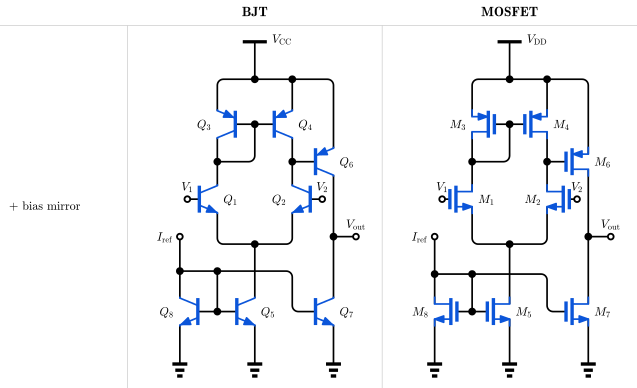

In [11]:
# HIDE/SHOW
show(C.op_amp_bias)

`````{tab-set}
````{tab-item} MOSFET
:sync: mosfet

**Problem 109**

| | MOSFET |
|---|---|
| **Problem** | A two-stage CMOS op amp runs from $\pm0.9\,\mathrm{V}$. The first stage is an NMOS pair $Q_1,Q_2$ with PMOS mirror load $Q_3,Q_4$ and NMOS tail source $Q_5$ ($200\,\mu\mathrm{A}$, mirrored from $Q_8$); the second stage is a PMOS common-source transistor $Q_6$ with NMOS current-source load $Q_7$ ($200\,\mu\mathrm{A}$, also mirrored from $Q_8$). All devices have $\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$; $\mu_nC_{ox}=400$, $\mu_pC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lvert V_t\rvert=0.4\,\mathrm{V}$, $\lvert V_A\rvert=6\,\mathrm{V}$ for all. Find (a) $W/L$ of $Q_1$ to $Q_8$, (b) the input common-mode range, (c) the output voltage range, and (d) the stage gains and the overall gain $A_0$. |
| **Given** | $\pm0.9\,\mathrm{V}$, $I_{Q5}=200\,\mu\mathrm{A}$, $\lvert V_{OV}\rvert$ $=0.2\,\mathrm{V}$, $\mu_nC_{ox}=400\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lvert V_t\rvert=0.4\,\mathrm{V}$, $\lvert V_A\rvert=6\,\mathrm{V}$ |
| **Answer 1** | **(a) Pair.** $I_{D1}$ $=I_{D2}$ $=100\,\mu\mathrm{A}$ $=\tfrac12(400)(W/L)(0.04)\Rightarrow(W/L)_{1,2}$ $=12.5$. |
| **Answer 2** | **(a) Mirror load.** $100$ $=\tfrac12(100)(W/L)(0.04)\Rightarrow(W/L)_{3,4}$ $=50$. |
| **Answer 3** | **(a) Tail and second-stage source.** $I_{D5}$ $=I_{D7}$ $=I_{D8}$ $=200\,\mu\mathrm{A}$: $200$ $=\tfrac12(400)(W/L)(0.04)\Rightarrow(W/L)_{5,7,8}$ $=25$. |
| **Answer 4** | **(a) Second-stage driver.** $I_{D6}=200\,\mu\mathrm{A}$ (PMOS): $200$ $=\tfrac12(100)(W/L)(0.04)\Rightarrow(W/L)_6$ $=100$. Table: $12.5,\,12.5,\,50,\,50,\,25,\,100,\,25,\,25$. |
| **Answer 5** | **(b) Input common-mode range.** Upper: $V_{ICM\max}$ $=V_{D1}+V_t$ $=V_{DD}-\lvert V_{SG4}\rvert+V_t$ $=0.9-0.2$ $=+0.7\,\mathrm{V}$. Lower: $V_{ICM\min}$ $=-V_{SS}+\lvert V_{OV5}\rvert+V_{GS1}$ $=-0.9+0.2+0.6$ $=-0.1\,\mathrm{V}$. |
| **Answer 6** | **(c) Output range.** $v_{O\max}$ $=V_{DD}-\lvert V_{OV6}\rvert$ $=0.7\,\mathrm{V}$, $v_{O\min}$ $=-V_{SS}+V_{OV7}$ $=-0.7\,\mathrm{V}$. |
| **Answer 7** | **(d) First stage.** $g_{m1,2}$ $=\dfrac{2(0.1)}{0.2}$ $=1\,\mathrm{mA/V}$, $r_{o2}$ $=r_{o4}$ $=\dfrac{6}{0.1}$ $=60\,\mathrm{k}\Omega$, $A_1$ $=-g_{m1,2}(r_{o2}\parallel r_{o4})$ $=-30\,\mathrm{V/V}$. |
| **Answer 8** | **(d) Second stage.** $g_{m6}$ $=\dfrac{2(0.2)}{0.2}$ $=2\,\mathrm{mA/V}$, $r_{o6}$ $=r_{o7}$ $=\dfrac6{0.2}$ $=30\,\mathrm{k}\Omega$, $A_2$ $=-g_{m6}(r_{o6}\parallel r_{o7})$ $=-30\,\mathrm{V/V}$. |
| **Answer 9** | **(d) Overall.** $A_0=A_1A_2=900\,\mathrm{V/V}$. |
| **Result** | $W/L$: $12.5,\,12.5,\,50,\,50,\,25,\,100,\,25,\,25$; $-0.1\,\mathrm{V}\le V_{ICM}\le0.7\,\mathrm{V}$; $-0.7\,\mathrm{V}\le v_O\le0.7\,\mathrm{V}$; $A_1=A_2=-30$, $A_0=900\,\mathrm{V/V}$ |

**Problem 110**

| | MOSFET |
|---|---|
| **Problem** | A two-stage CMOS op amp runs from $V_{DD}=1.2\,\mathrm{V}$ (see figure): NMOS pair $Q_1,Q_2$ with PMOS mirror $Q_3,Q_4$ ($200\,\mu\mathrm{A}$ each), tail transistor $Q_5$ mirrored from $Q_8$ ($I_{REF}=200\,\mu\mathrm{A}$), second stage PMOS $Q_6$ with NMOS source $Q_7$. All overdrives are $0.15\,\mathrm{V}$; $k_n^{\prime}=540$, $k_p^{\prime}$ $=100\,\mu\mathrm{A/V^2}$, $V_{tn}$ $=\lvert V_{tp}\rvert$ $=0.35\,\mathrm{V}$, and $\lvert V_A\rvert=2.4\,\mathrm{V}$. Find (a) $W/L$ of all transistors, (b) the input common-mode range, (c) the output range, (d) the gain $A_0$. |
| **Given** | $V_{DD}=1.2\,\mathrm{V}$, $I_{REF}=200\,\mu\mathrm{A}$, $\lvert V_{OV}\rvert$ $=0.15\,\mathrm{V}$, $k_n^{\prime}=540$, $k_p^{\prime}$ $=100\,\mu\mathrm{A/V^2}$, $V_t=0.35\,\mathrm{V}$, $\lvert V_A\rvert=2.4\,\mathrm{V}$ |
| **Answer 1** | **(a) Currents.** $Q_1$ to $Q_4$: $200\,\mu\mathrm{A}$ each; $Q_5$ carries $2\times200=400\,\mu\mathrm{A}$; $Q_7$ and $Q_6$: $400\,\mu\mathrm{A}$; $Q_8$: $200\,\mu\mathrm{A}$. |
| **Answer 2** | **(a) Pair and mirror.** $(W/L)_{1,2}$ $=\dfrac{200}{\tfrac12(540)(0.15)^2}$ $=32.9$, $(W/L)_{3,4}$ $=\dfrac{200}{\tfrac12(100)(0.15)^2}$ $=178$. |
| **Answer 3** | **(a) Others.** $(W/L)_5$ $=(W/L)_7$ $=\dfrac{400}{\tfrac12(540)(0.15)^2}$ $=65.8$, $(W/L)_8=\tfrac12(W/L)_5=32.9$, $(W/L)_6$ $=\dfrac{400}{\tfrac12(100)(0.15)^2}$ $=356$. |
| **Answer 4** | **(b) Input common-mode range.** Upper (keep $Q_1,Q_2$ saturated): $V_{ICM\max}$ $=V_{DD}-\lvert V_t\rvert-\lvert V_{OV}\rvert+V_t$ $=1.2-0.15$ $=1.05\,\mathrm{V}$. Lower (keep $Q_5$ saturated): $V_{ICM\min}$ $=V_{OV5}+V_{GS1,2}$ $=0.15+0.15+0.35$ $=0.65\,\mathrm{V}$. |
| **Answer 5** | **(c) Output range.** $V_{OV7}\le v_O\le V_{DD}-\lvert V_{OV6}\rvert$: $0.15\,\mathrm{V}\le v_O\le1.05\,\mathrm{V}$. |
| **Answer 6** | **(d) First stage.** $g_{m1,2}$ $=\dfrac{2(0.2)}{0.15}$ $=2.67\,\mathrm{mA/V}$, $r_{o2}$ $=r_{o4}$ $=\dfrac{2.4}{0.2}$ $=12\,\mathrm{k}\Omega$, $\lvert A_1\rvert$ $=2.67\times(12\parallel12)$ $=16$. |
| **Answer 7** | **(d) Second stage.** $g_{m6}$ $=\dfrac{2(0.4)}{0.15}$ $=5.33\,\mathrm{mA/V}$, $r_{o6}$ $=r_{o7}$ $=\dfrac{2.4}{0.4}$ $=6\,\mathrm{k}\Omega$, $\lvert A_2\rvert=5.33\times3=16$. |
| **Answer 8** | **(d) Overall gain.** $\lvert A_0\rvert$ $=16\times16$ $=256\,\mathrm{V/V}$. |
| **Result** | $W/L$: $32.9,\,32.9,\,178,\,178,\,65.8,\,356,\,65.8,\,32.9$; $0.65\,\mathrm{V}\le V_{ICM}\le1.05\,\mathrm{V}$; $0.15\,\mathrm{V}\le v_O\le1.05\,\mathrm{V}$; $A_0=256\,\mathrm{V/V}$ |
````
`````

### Other Circuits

`````{tab-set}
````{tab-item} BJT
:sync: bjt

**Problem 116**

| | BJT |
|---|---|
| **Problem** | The bipolar op amp has input resistance $R_{id}=20.2\,\mathrm{k}\Omega$, open-circuit voltage gain $A_{vo}=8513\,\mathrm{V/V}$ and output resistance $R_o=152\,\Omega$ (from its analysis). It is driven from a source with $R_s=10\,\mathrm{k}\Omega$ and loaded with $R_L=1\,\mathrm{k}\Omega$. Find the overall voltage gain $v_o/v_s$. |
| **Given** | $R_{id}=20.2\,\mathrm{k}\Omega$, $A_{vo}=8513$, $R_o=152\,\Omega$, $R_s=10\,\mathrm{k}\Omega$, $R_L=1\,\mathrm{k}\Omega$ |
| **Answer 1** | **Input divider.** $\dfrac{v_{id}}{v_s}$ $=\dfrac{R_{id}}{R_{id}+R_s}$ $=\dfrac{20.2}{30.2}$ $=0.669$. |
| **Answer 2** | **Amplifier.** The open-circuit output is $A_{vo}v_{id}$. |
| **Answer 3** | **Output divider.** $\dfrac{v_o}{A_{vo}v_{id}}$ $=\dfrac{R_L}{R_L+R_o}$ $=\dfrac{1}{1+0.152}$ $=0.868$. |
| **Answer 4** | **Overall gain.** $G_v$ $=\dfrac{v_o}{v_s}$ $=0.669\times8513\times0.868$ $=4943\,\mathrm{V/V}$. |
| **Result** | $G_v$ $\approx4.94\times10^{3}\,\mathrm{V/V}$ |

**Problem 117**

| | BJT |
|---|---|
| **Problem** | For the bipolar op amp, find the overall current gain from the input current $i_1$ (the signal current entering the input stage) to the emitter current $i_{e8}$ of the output transistor $Q_8$ by multiplying the stage current gains, then the overall voltage gain $v_o/v_{id}$. Data: $\beta_2=\beta_5=\beta_7=100$, $\beta_8=100$; $R_1+R_2=40\,\mathrm{k}\Omega$, $R_{i2}=5.05\,\mathrm{k}\Omega$; $R_3=3\,\mathrm{k}\Omega$, $R_{i3}=234.8\,\mathrm{k}\Omega$; $R_5=15.7\,\mathrm{k}\Omega$, $R_{i4}=303.5\,\mathrm{k}\Omega$; $R_6=3\,\mathrm{k}\Omega$ (output load of $i_{e8}$), $R_{i1}=20.2\,\mathrm{k}\Omega$. |
| **Given** | $\beta_{2,5,7,8}$ as above ($\beta=100$, $\beta_8+1=101$), resistances in $\mathrm{k}\Omega$ as listed |
| **Answer 1** | **Output transistor.** $\dfrac{i_{e8}}{i_{b8}}$ $=\beta_8+1$ $=101$. |
| **Answer 2** | **Divider into Q8.** $\dfrac{i_{b8}}{i_{c7}}$ $=\dfrac{R_5}{R_5+R_{i4}}$ $=\dfrac{15.7}{15.7+303.5}$ $=0.0492$; $\dfrac{i_{c7}}{i_{b7}}=\beta_7=100$. |
| **Answer 3** | **Divider into Q7.** $\dfrac{i_{b7}}{i_{c5}}$ $=\dfrac{R_3}{R_3+R_{i3}}$ $=\dfrac{3}{3+234.8}$ $=0.0126$; $\dfrac{i_{c5}}{i_{b5}}=\beta_5=100$. |
| **Answer 4** | **Divider into Q5.** $\dfrac{i_{b5}}{i_{c2}}$ $=\dfrac{R_1+R_2}{R_1+R_2+R_{i2}}$ $=\dfrac{40}{40+5.05}$ $=0.888$; $\dfrac{i_{c2}}{i_1}=\beta_2=100$. |
| **Answer 5** | **Overall current gain.** $\dfrac{i_{e8}}{i_1}$ $=101\times0.0492\times100\times0.0126\times100\times0.888\times100$ $\approx5.56\times10^{4}\,\mathrm{A/A}$ (the published solution prints $55\,599$ from rounded ratios; the unrounded ratios give $55\,646$). |
| **Answer 6** | **Overall voltage gain.** $\dfrac{v_o}{v_{id}}$ $=\dfrac{R_6}{R_{i1}}\dfrac{i_{e8}}{i_1}$ $=\dfrac{3}{20.2}\times5.56\times10^{4}$ $\approx8.26\times10^{3}\,\mathrm{V/V}$. |
| **Result** | $i_{e8}/i_1$ $\approx5.56\times10^4\,\mathrm{A/A}$, $v_o/v_{id}$ $\approx8.26\times10^3\,\mathrm{V/V}$ |

**Problem 118**

| | BJT |
|---|---|
| **Problem** | A three-stage bipolar amplifier consists of a differential pair $Q_1,Q_2$ with an active load $Q_3,Q_4$ (tail current $0.4\,\mathrm{mA}$), a common-emitter stage $Q_5$ biased at $0.5\,\mathrm{mA}$ with an ideal current-source load, and an emitter follower $Q_6$ biased at $1\,\mathrm{mA}$ driving a load $R_L=1\,\mathrm{k}\Omega$. All transistors have $\beta=100$ and $r_o=\infty$; $V_T=25\,\mathrm{mV}$; inputs are grounded and the output is at $0\,\mathrm{V}$ dc. Find (a) the dc emitter currents, (b) the gain of each stage and the overall gain $A_0=v_o/v_{id}$. |
| **Given** | $I_{tail}=0.4\,\mathrm{mA}$, $I_{E5}=0.5\,\mathrm{mA}$, $I_{E6}=1\,\mathrm{mA}$, $\beta=100$, $r_o=\infty$, $R_L=1\,\mathrm{k}\Omega$, $V_T=25\,\mathrm{mV}$ |
| **Answer 1** | **(a) DC currents.** $I_{E1}$ $=I_{E2}$ $=\tfrac12(0.4)$ $=0.2\,\mathrm{mA}$, $I_{E3}$ $=I_{E4}\simeq0.2\,\mathrm{mA}$, $I_{E5}\simeq0.5\,\mathrm{mA}$, $I_{E6}=1\,\mathrm{mA}$. |
| **Answer 2** | **(b) First-stage transconductance.** $G_m$ $=g_{m1,2}$ $=\dfrac{0.2}{0.025}$ $=8\,\mathrm{mA/V}$. |
| **Answer 3** | **(b) Load of the first stage.** With $r_{o2}=r_{o4}=\infty$ the first-stage output node sees only the input resistance of $Q_5$: $g_{m5}$ $=\dfrac{0.5}{0.025}$ $=20\,\mathrm{mA/V}$, $r_{\pi5}$ $=\dfrac{\beta}{g_{m5}}$ $=5\,\mathrm{k}\Omega$. |
| **Answer 4** | **(b) First-stage gain.** $A_1$ $=\dfrac{v_{b5}}{v_{id}}$ $=-G_mr_{\pi5}$ $=-8\times5$ $=-40\,\mathrm{V/V}$. |
| **Answer 5** | **(b) Follower input resistance.** $r_{e6}$ $=\dfrac{25\,\mathrm{mV}}{1\,\mathrm{mA}}$ $=25\,\Omega$, $R_{i6}$ $=(\beta+1)(r_{e6}+R_L)$ $=101\times1.025$ $=103.5\,\mathrm{k}\Omega$. |
| **Answer 6** | **(b) Second-stage gain.** $A_2$ $=-g_{m5}R_{i6}$ $=-20\times103.5$ $=-2070\,\mathrm{V/V}$. |
| **Answer 7** | **(b) Third-stage gain.** $A_3$ $=\dfrac{R_L}{R_L+r_{e6}}$ $=\dfrac1{1.025}$ $=0.976\,\mathrm{V/V}$. |
| **Answer 8** | **(b) Overall gain.** $A_0$ $=A_1A_2A_3$ $=(-40)(-2070)(0.976)$ $=8.08\times10^4\,\mathrm{V/V}$. |
| **Result** | $I_E$ $=0.2,\,0.2,\,0.5,\,1\,\mathrm{mA}$; $A_1=-40$, $A_2=-2070$, $A_3=0.976$; $A_0=8.08\times10^4\,\mathrm{V/V}$ |

**Problem 119**

| | BJT |
|---|---|
| **Problem** | In the figure, $Q_1,Q_2$ form a differential pair with total emitter-loop resistance made of $r_{e1}=r_{e2}=50\,\Omega$ plus two $50\,\Omega$ resistors between the emitters, and $5\,\mathrm{k}\Omega$ collector resistors to ground. Their collectors drive the bases of a second pair $Q_3,Q_4$ whose emitters are joined directly and have $r_{e3}=r_{e4}=25\,\Omega$ each. All $\beta=100$. Find the input resistance $R_{in}$ seen between the bases of $Q_1,Q_2$, the voltage gain $A_1$ of the first pair (to the bases of $Q_3,Q_4$), and the current gain $i_{c3}/i_{b1}$. |
| **Given** | $\beta=100$, $r_{e1}=r_{e2}=50\,\Omega$ + two $50\,\Omega$ between the emitters, $R_C=5\,\mathrm{k}\Omega$ each, $r_{e3}=r_{e4}=25\,\Omega$ |
| **Answer 1** | **Input resistance.** Loop resistance in the emitter circuit: $50+50+50+50=200\,\Omega$. $R_{in}$ $=(\beta+1)(4\times50\,\Omega)$ $=101\times200$ $=20.2\,\mathrm{k}\Omega$ $\approx20\,\mathrm{k}\Omega$. |
| **Answer 2** | **Input resistance of the second pair.** The emitters of $Q_3,Q_4$ are tied directly, so the loop resistance is $r_{e3}+r_{e4}=50\,\Omega$ and $R_{in2}$ $=(\beta+1)(25+25)$ $=5.05\,\mathrm{k}\Omega$. |
| **Answer 3** | **Effective load of the first pair.** The load between the two collectors is $R_{in2}$ in parallel with $5+5=10\,\mathrm{k}\Omega$: $5.05\parallel10$ $=3.36\,\mathrm{k}\Omega$. |
| **Answer 4** | **Voltage gain A1.** $A_1\simeq\dfrac{\text{resistance between the collectors}}{\text{resistance in the emitter loop}}$ $=\dfrac{3.36\,\mathrm{k}\Omega}{200\,\Omega}$ $=16.8\,\mathrm{V/V}$ ($\alpha\approx1$). |
| **Answer 5** | **Current divider at the collectors.** $\dfrac{i_{b3}}{i_{c1}}$ $=\dfrac{5+5}{(5+5)+R_{in2}}$ $=\dfrac{10}{10+5.05}$ $=0.664$. |
| **Answer 6** | **Current gain.** $\dfrac{i_{c3}}{i_{b1}}$ $=\dfrac{i_{c3}}{i_{b3}}\cdot\dfrac{i_{b3}}{i_{c1}}\cdot\dfrac{i_{c1}}{i_{b1}}$ $=100\times0.664\times100$ $=6.64\times10^3\,\mathrm{A/A}$. |
| **Answer 7** | **Compare with the published solution.** The published solution uses $R_{in2}$ $=2(\beta+1)(25+25)\simeq10\,\mathrm{k}\Omega$ (an extra factor 2), which gives $A_1=25$ and $i_{c3}/i_{b1}=5000$. |
| **Result** | $R_{in}=20.2\,\mathrm{k}\Omega$, $A_1=16.8\,\mathrm{V/V}$, $i_{c3}/i_{b1}$ $=6.64\times10^3\,\mathrm{A/A}$ (published: $A_1=25$, $5000$) |

**Problem 120**

| | BJT |
|---|---|
| **Problem** | The four-stage bipolar op amp (third stage: $Q_7$ with $R_5=15.7\,\mathrm{k}\Omega$ in its collector, $R_4=2.3\,\mathrm{k}\Omega$ in its emitter branch, $r_{e7}=25\,\Omega$; output follower $Q_8$ with $r_{e8}=5\,\Omega$ and $R_6=3\,\mathrm{k}\Omega$; $\beta=100$; original gain $v_o/v_{id}=8513$ with $A_3=-6.42$ and $R_o=152\,\Omega$) is modified: $R_5$ is replaced by a $1\,\mathrm{mA}$ current source of very high output resistance. Find (a) the new overall gain, (b) the output resistance, and the gain when the amplifier drives $R_L=100\,\Omega$, compared with the original amplifier loaded the same way. |
| **Given** | $\beta=100$, $R_4=2.3\,\mathrm{k}\Omega$, $R_5=15.7\,\mathrm{k}\Omega$ (removed), $r_{e7}=25\,\Omega$, $r_{e8}=5\,\Omega$, $R_6=3\,\mathrm{k}\Omega$, original $A_0=8513$, $A_3=-6.42$, $R_o=152\,\Omega$, $R_L=100\,\Omega$ |
| **Answer 1** | **Collector load of Q7.** With the current source the only collector load of $Q_7$ is the input resistance of $Q_8$: $R_{i8}$ $=(\beta+1)(r_{e8}+R_6)$ $=101\times3.005$ $=303.5\,\mathrm{k}\Omega$. |
| **Answer 2** | **Check of the original value.** With $R_5$: $A_3$ $=-\dfrac{R_5\parallel R_{i8}}{R_4+r_{e7}}$ $=-\dfrac{14.9}{2.325}$ $=-6.42$, as in the original circuit. |
| **Answer 3** | **New third-stage gain.** $A_3$ $=-\dfrac{303.5}{2.3+0.025}$ $=-130.5\,\mathrm{V/V}$ ($\alpha\simeq1$). |
| **Answer 4** | **(a) New overall gain.** $\dfrac{v_o}{v_{id}}$ $=8513\times\dfrac{130.5}{6.42}$ $=1.73\times10^5\,\mathrm{V/V}$. |
| **Answer 5** | **(b) Output resistance.** $R_o$ $=R_6\parallel\left(r_{e8}+\dfrac{\text{very large}}{\beta+1}\right)\simeq3\,\mathrm{k}\Omega$ (original: $3\,\mathrm{k}\Omega\parallel(5+15\,700/101)\simeq152\,\Omega$). |
| **Answer 6** | **Loaded gain, modified.** $G_v$ $=1.73\times10^5\dfrac{100}{3000+100}$ $=5.58\times10^3\,\mathrm{V/V}$. |
| **Answer 7** | **Loaded gain, original.** $G_v$ $=8513\times\dfrac{100}{152+100}$ $=3378\,\mathrm{V/V}$. |
| **Answer 8** | **Conclusion.** Although $R_o$ is much larger, the loaded gain is higher with the current source ($5.58\times10^3$ against $3378$). |
| **Result** | $A_0=1.73\times10^5\,\mathrm{V/V}$; $R_o\simeq3\,\mathrm{k}\Omega$; $G_v(100\,\Omega)$ $=5.58\times10^3\,\mathrm{V/V}$ (original: $3378$) |

**Problem 121**

| | BJT |
|---|---|
| **Problem** | A three-stage discrete amplifier runs from $\pm5\,\mathrm{V}$. $Q_1$ (npn) has a base divider of $68\,\mathrm{k}\Omega$ to $+5\,\mathrm{V}$ and $33\,\mathrm{k}\Omega$ to $-5\,\mathrm{V}$, a $4.7\,\mathrm{k}\Omega$ emitter resistor to $-5\,\mathrm{V}$ and an $8.2\,\mathrm{k}\Omega$ collector resistor to $+5\,\mathrm{V}$. The collector of $Q_1$ drives the base of $Q_2$ (pnp, $3.3\,\mathrm{k}\Omega$ emitter resistor to $+5\,\mathrm{V}$, $5.6\,\mathrm{k}\Omega$ collector resistor to $-5\,\mathrm{V}$). The collector of $Q_2$ drives the base of $Q_3$ (npn emitter follower, collector at $+5\,\mathrm{V}$, $2.4\,\mathrm{k}\Omega$ emitter resistor to $-5\,\mathrm{V}$, output at the emitter). $\beta=100$, $\lvert V_{BE}\rvert$ $=0.7\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$. For signals the emitter resistors of $Q_1$ and $Q_2$ are bypassed. (a) Find the dc operating point. (b) Find $R_{in}$ and $R_{out}$. (c) Find the overall gain $v_o/v_i$. |
| **Given** | $\pm5\,\mathrm{V}$, $68\,\mathrm{k}\Omega/33\,\mathrm{k}\Omega$ divider, $4.7$, $8.2$, $3.3$, $5.6$, $2.4\,\mathrm{k}\Omega$, $\beta=100$, $V_{BE}=0.7\,\mathrm{V}$ |
| **Answer 1** | **(a) Thevenin of the divider.** $V_{BB}$ $=-5+\dfrac{33}{33+68}\times10$ $=-1.73\,\mathrm{V}$, $R_{BB}$ $=68\parallel33$ $=22.2\,\mathrm{k}\Omega$. |
| **Answer 2** | **(a) Q1.** $I_{E1}$ $=\dfrac{V_{BB}+5-0.7}{4.7+R_{BB}/(\beta+1)}$ $=\dfrac{2.57}{4.92}$ $=0.522\,\mathrm{mA}$, $I_{C1}$ $=\alpha I_{E1}$ $=0.517\,\mathrm{mA}$. |
| **Answer 3** | **(a) Q2.** Base voltage $5-0.517\times8.2=0.76\,\mathrm{V}$: $I_{E2}$ $=\dfrac{5-0.76-0.7}{3.3+8.2/101}$ $=1.05\,\mathrm{mA}$, $I_{C2}=1.04\,\mathrm{mA}$. |
| **Answer 4** | **(a) Q3.** Base voltage $-5+1.04\times5.6=0.80\,\mathrm{V}$: $I_{E3}$ $=\dfrac{0.80-0.7+5}{2.4+5.6/101}$ $=2.08\,\mathrm{mA}$, so $V_O$ $=-5+2.08\times2.4$ $=-0.02\,\mathrm{V}$ $\approx0$. |
| **Answer 5** | **(b) Input resistance.** $g_{m1}$ $=\dfrac{0.517}{0.025}$ $=20.7\,\mathrm{mA/V}$, $r_{\pi1}=4.84\,\mathrm{k}\Omega$, $R_{in}$ $=68\parallel33\parallel4.84$ $=3.97\,\mathrm{k}\Omega$ $\approx4\,\mathrm{k}\Omega$. |
| **Answer 6** | **(b) Output resistance.** $r_{e3}$ $=\dfrac{25}{2.08}$ $=12.0\,\Omega$, $R_{out}$ $=2.4\,\mathrm{k}\Omega\parallel\left(r_{e3}+\dfrac{5.6\,\mathrm{k}\Omega}{101}\right)$ $=65.6\,\Omega$. |
| **Answer 7** | **(c) Stage 1 to Q2 base.** $i_{c1}=g_{m1}v_i$; $r_{\pi2}$ $=\dfrac{100}{41.4}$ $=2.41\,\mathrm{k}\Omega$, so $i_{b2}$ $=g_{m1}v_i\dfrac{8.2}{8.2+2.41}$ $=16.0\,v_i$ (mA/V units) and $i_{c2}=\beta i_{b2}=1597\,v_i$. |
| **Answer 8** | **(c) Stage 3.** $R_{i3}$ $=(\beta+1)(r_{e3}+2.4)$ $=243.6\,\mathrm{k}\Omega$; $i_{b3}$ $=i_{c2}\dfrac{5.6}{5.6+243.6}$ $=35.9\,v_i$; $i_{e3}=101\,i_{b3}$; $v_o$ $=2.4\,\mathrm{k}\Omega\times i_{e3}$. |
| **Answer 9** | **(c) Overall gain.** $\dfrac{v_o}{v_i}\simeq8.70\times10^3\,\mathrm{V/V}$ (non-inverting: two inverting stages). |
| **Result** | $I_{E1}=0.52$, $I_{E2}=1.05$, $I_{E3}=2.08\,\mathrm{mA}$, $V_O\approx0$; $R_{in}\approx4\,\mathrm{k}\Omega$, $R_{out}=65.6\,\Omega$; $v_o/v_i$ $\approx8.7\times10^3\,\mathrm{V/V}$ |

**Problem 122**

| | BJT |
|---|---|
| **Problem** | In the bipolar op amp ($\beta=100$; bias $I_{C1}=I_{C2}=0.25\,\mathrm{mA}$, $I_{C4}=I_{C5}=1\,\mathrm{mA}$; first-stage collector resistance $40\,\mathrm{k}\Omega$ between the collectors; second-stage collector load $3\,\mathrm{k}\Omega$; third-stage input resistance $R_{i3}=234.8\,\mathrm{k}\Omega$; $A_3=-6.42$, $A_4=1$) a $100\,\Omega$ resistor is added in the emitter of each of $Q_1,Q_2$ and a $25\,\Omega$ resistor in the emitter of each of $Q_4,Q_5$. Find the new input resistances $R_{id}$ and $R_{i2}$, the gains of the first two stages and the overall gain. |
| **Given** | $\beta=100$, $I_{C1,2}=0.25\,\mathrm{mA}$, $I_{C4,5}=1\,\mathrm{mA}$, $R_{e1,2}=100\,\Omega$, $R_{e4,5}=25\,\Omega$, $R_{i3}=234.8\,\mathrm{k}\Omega$, $A_3=-6.42$, $A_4=1$ |
| **Answer 1** | **Emitter resistances.** $r_{e1,2}$ $=\dfrac{25\,\mathrm{mV}}{0.25\,\mathrm{mA}}$ $=100\,\Omega$, $r_{e4,5}$ $=\dfrac{25\,\mathrm{mV}}{1\,\mathrm{mA}}$ $=25\,\Omega$. |
| **Answer 2** | **Differential input resistance.** $R_{id}$ $=(\beta+1)(2r_{e1,2}+2R_{e1,2})$ $=101\times(0.2+0.2)\,\mathrm{k}\Omega$ $=40.4\,\mathrm{k}\Omega$, twice its previous value. |
| **Answer 3** | **Input resistance of stage 2.** $R_{i2}$ $=(\beta+1)(2r_{e4,5}+2R_{e4,5})$ $=101\times(0.05+0.05)$ $=10.1\,\mathrm{k}\Omega$ (twice before). |
| **Answer 4** | **Gain of stage 1.** $A_1$ $=\dfrac{(40\parallel R_{i2})}{2r_{e1,2}+2R_{e1,2}}$ $=\dfrac{40\parallel10.1}{0.4}$ $=\dfrac{8.06}{0.4}$ $=20.2\,\mathrm{V/V}$ ($\alpha\simeq1$); slightly lower than the original $22.4$ because the larger $R_{i2}$ partly compensates. |
| **Answer 5** | **Gain of stage 2.** $A_2$ $=-\dfrac{3\parallel R_{i3}}{2r_{e4,5}+2R_{e4,5}}$ $=-\dfrac{3\parallel234.8}{0.1}$ $=-29.6\,\mathrm{V/V}$, half the previous $-59.2$. |
| **Answer 6** | **Overall gain.** $\dfrac{v_o}{v_{id}}$ $=A_1A_2A_3A_4$ $=20.2\times(-29.6)\times(-6.42)\times1$ $=3.83\times10^3\,\mathrm{V/V}$. |
| **Result** | $R_{id}=40.4\,\mathrm{k}\Omega$, $R_{i2}=10.1\,\mathrm{k}\Omega$, $A_1=20.2$, $A_2=-29.6$, total $\approx3.8\times10^3\,\mathrm{V/V}$ |

**Problem 123**

| | BJT |
|---|---|
| **Problem** | The op amp has output resistance $R_o\simeq152\,\Omega$ set by $R_6=3\,\mathrm{k}\Omega$ in parallel with $r_{e8}+R_5/(\beta+1)$, with $r_{e8}=5\,\Omega$, $\beta=100$, and $R_5=15.7\,\mathrm{k}\Omega$ in the collector of $Q_7$ (third-stage gain $A_3=-6.42$ with $R_4=2.3\,\mathrm{k}\Omega$, $r_{e7}=25\,\Omega$). Find the value of $R_5$ that halves $R_o$, then the value of $R_4$ that restores the third-stage gain to $-6.42$. |
| **Given** | $R_o:152\to76\,\Omega$, $R_6=3\,\mathrm{k}\Omega$, $r_{e8}=5\,\Omega$, $\beta=100$, $R_4=2.3\,\mathrm{k}\Omega$, $r_{e7}=25\,\Omega$, $A_3=-6.42$ |
| **Answer 1** | **Condition on R5.** $R_o$ $=R_6\parallel\left(r_{e8}+\dfrac{R_5}{\beta+1}\right)$ $=76\,\Omega$. |
| **Answer 2** | **Solve.** $r_{e8}+\dfrac{R_5}{101}$ $=\dfrac{1}{\frac1{76}-\frac1{3000}}$ $=78.0\,\Omega\Rightarrow R_5$ $=101\times73.0\,\Omega$ $=7.37\,\mathrm{k}\Omega$. |
| **Answer 3** | **Effect on gain of stage 3.** $R_{i8}$ $=101\times(0.005+3)$ $=303.5\,\mathrm{k}\Omega$; $A_3$ $=-\dfrac{R_5\parallel R_{i8}}{R_4+r_{e7}}$ $=-\dfrac{7.20}{2.325}$ $=-3.09$, about half the original. |
| **Answer 4** | **Restore the gain.** Require $\dfrac{7.20\,\mathrm{k}\Omega}{R_4+0.025}$ $=6.42\Rightarrow R_4+0.025$ $=1.12\,\mathrm{k}\Omega$, so $R_4=1.10\,\mathrm{k}\Omega$. |
| **Answer 5** | **Check.** With $R_5=7.37\,\mathrm{k}\Omega$: $R_o=76.0\,\Omega$; with $R_4=1.096\,\mathrm{k}\Omega$: $A_3=-6.42$. |
| **Result** | $R_5=7.37\,\mathrm{k}\Omega$, $R_4=1.10\,\mathrm{k}\Omega$ (published: $1.085\,\mathrm{k}\Omega$) |
````
````{tab-item} MOSFET
:sync: mosfet

**Problem 111**

| | MOSFET |
|---|---|
| **Problem** | A two-stage CMOS op amp has an input pair $Q_1,Q_2$ (PMOS, $W/L=44.4$ each) with a tail current $I=128\,\mathrm{\mu A}$ from $Q_5$ ($W/L=88.8$), an NMOS mirror load $Q_3,Q_4$ ($(W/L)_4=11.1$), a second-stage NMOS common-source transistor $Q_6$ and a PMOS current-source load $Q_7$ mirrored from $Q_5$. Technology: $\mu_pC_{ox}$ $=128\,\mathrm{\mu A/V^2}$, $\mu_nC_{ox}$ $=512\,\mathrm{\mu A/V^2}$, $\lvert V_A\rvert=3.2\,\mathrm{V}$ for all devices. The second stage is to carry $I_6=I_7=128\,\mathrm{\mu A}$. Find (a) $(W/L)_6$ and $(W/L)_7$; (b) the overdrives $V_{OV1},V_{OV2},V_{OV6}$; (c) $g_m$ of $Q_1,Q_2,Q_6$; (d) $r_{o2},r_{o4},r_{o6},r_{o7}$; (e) $A_1$, $A_2$ and the overall gain. |
| **Given** | $I=128\,\mathrm{\mu A}$, $(W/L)_{1,2}=44.4$, $(W/L)_4=11.1$, $(W/L)_5=88.8$, $\mu_pC_{ox}=128$, $\mu_nC_{ox}$ $=512\,\mathrm{\mu A/V^2}$, $\lvert V_A\rvert=3.2\,\mathrm{V}$, $I_6=I_7=128\,\mathrm{\mu A}$ |
| **Answer 1** | **(a) Q6 for balance.** $I_6$ $=\dfrac{(W/L)_6}{(W/L)_4}\dfrac I2\Rightarrow128$ $=\dfrac{(W/L)_6}{11.1}\times64\Rightarrow(W/L)_6$ $=22.2$. |
| **Answer 2** | **(a) Q7.** $I_7$ $=\dfrac{(W/L)_7}{(W/L)_5}I\Rightarrow128$ $=\dfrac{(W/L)_7}{88.8}\times128\Rightarrow(W/L)_7$ $=88.8$. |
| **Answer 3** | **(b) Overdrives.** $Q_1$: $\dfrac I2$ $=\dfrac12\mu_pC_{ox}\dfrac WLV_{OV1}^2\Rightarrow V_{OV1}$ $=\sqrt{\dfrac{64}{\tfrac12\times128\times44.4}}$ $=0.150\,\mathrm{V}$; the same for $Q_2$. $Q_6$: $128$ $=\tfrac12\times512\times22.2\,V_{OV6}^2\Rightarrow V_{OV6}$ $=0.150\,\mathrm{V}$. |
| **Answer 4** | **(c) Transconductances.** $g_m=\dfrac{2I_D}{V_{OV}}$: $g_{m1}$ $=g_{m2}$ $=\dfrac{2\times64}{0.15}$ $=0.853\,\mathrm{mA/V}$; $g_{m6}$ $=\dfrac{2\times128}{0.15}$ $=1.71\,\mathrm{mA/V}$. |
| **Answer 5** | **(d) Output resistances.** $r_o=\dfrac{\lvert V_A\rvert}{I_D}$: $r_{o2}$ $=r_{o4}$ $=\dfrac{3.2}{0.064}$ $=50\,\mathrm{k}\Omega$; $r_{o6}$ $=r_{o7}$ $=\dfrac{3.2}{0.128}$ $=25\,\mathrm{k}\Omega$. |
| **Answer 6** | **(e) First stage.** $A_1$ $=-g_{m1}(r_{o2}\parallel r_{o4})$ $=-0.853\times25$ $=-21.3\,\mathrm{V/V}$. |
| **Answer 7** | **(e) Second stage.** $A_2$ $=-g_{m6}(r_{o6}\parallel r_{o7})$ $=-1.71\times12.5$ $=-21.3\,\mathrm{V/V}$. |
| **Answer 8** | **(e) Overall.** $A$ $=A_1A_2$ $=(-21.3)(-21.3)$ $\approx455\,\mathrm{V/V}$ (the published solution quotes $454$ using the rounded $21.3$). |
| **Result** | $(W/L)_6=22.2$, $(W/L)_7=88.8$; $V_{OV}=0.15\,\mathrm{V}$; $g_{m1,2}=0.853$, $g_{m6}=1.71\,\mathrm{mA/V}$; $r_{o2,4}=50\,\mathrm{k}\Omega$, $r_{o6,7}=25\,\mathrm{k}\Omega$; $A_1=A_2=-21.3$; $A\approx455\,\mathrm{V/V}$ |

**Problem 112**

| | MOSFET |
|---|---|
| **Problem** | In the CMOS op amp (reference current $I_{REF}=100\,\mu\mathrm{A}$ in $Q_8$ with $(W/L)_8=20/0.4$) the second-stage current-source transistor $Q_7$ is changed so that $(W/L)_7=48/0.8$. The first stage biases $Q_6$ at $100\,\mu\mathrm{A}$; all Early voltages are such that $V_A=5\,\mathrm{V}$ and the open-loop gain is $A_0=625\,\mathrm{V/V}$. Find the systematic input offset voltage that results. |
| **Given** | $I_{REF}=100\,\mu\mathrm{A}$, $(W/L)_8=20/0.4=50$, $(W/L)_7=48/0.8=60$, $I_{D6}=100\,\mu\mathrm{A}$, $V_A=5\,\mathrm{V}$, $A_0=625$ |
| **Answer 1** | **New current of Q7.** $I_{D7}$ $=I_{REF}\dfrac{(W/L)_7}{(W/L)_8}$ $=100\times\dfrac{60}{50}$ $=120\,\mu\mathrm{A}$. |
| **Answer 2** | **Current mismatch.** $Q_6$ still supplies $100\,\mu\mathrm{A}$, so $Q_7$ wants $20\,\mu\mathrm{A}$ more than $Q_6$ can deliver; this difference must flow through the output resistance, shifting the output voltage. |
| **Answer 3** | **Output resistances.** $r_{o6}$ $=\dfrac5{0.1}$ $=50\,\mathrm{k}\Omega$, $r_{o7}$ $=\dfrac5{0.12}$ $=41.7\,\mathrm{k}\Omega$, $r_{o6}\parallel r_{o7}$ $=22.7\,\mathrm{k}\Omega$. |
| **Answer 4** | **Output offset.** $V_O$ $=\Delta I\,(r_{o6}\parallel r_{o7})$ $=20\,\mu\mathrm{A}\times22.7\,\mathrm{k}\Omega$ $=455\,\mathrm{mV}$. |
| **Answer 5** | **Input-referred offset.** $V_{OS}$ $=\dfrac{V_O}{A_0}$ $=\dfrac{455\,\mathrm{mV}}{625}$ $=0.73\,\mathrm{mV}$. |
| **Result** | $V_{OS}\approx0.73\,\mathrm{mV}$ (output offset $455\,\mathrm{mV}$) |

**Problem 113**

| | MOSFET |
|---|---|
| **Problem** | The CMOS op amp (supplies $\pm0.9\,\mathrm{V}$, PMOS input pair $Q_1,Q_2$ with PMOS tail source $Q_5$, NMOS mirror $Q_3,Q_4$, second stage $Q_6$ with source $Q_7$, reference device $Q_8$) has $I_{REF}=50\,\mu\mathrm{A}$ and $(W/L)_5=(W/L)_7=50/0.5$, $(W/L)_8=(W/L)_5/4$, $(W/L)_4=6.25/0.5$, $L=0.5\,\mu\mathrm{m}$, $\lvert V_t\rvert=0.4\,\mathrm{V}$, $\lvert V_A\rvert=6\,\mathrm{V}$. For zero systematic offset $(W/L)_6/(W/L)_4=2(W/L)_7/(W/L)_5$. Find $W_6$, the drain current, overdrive, $g_m$, $r_o$ of all devices (all devices have $\lvert V_{OV}\rvert$ $=0.21\,\mathrm{V}$ at their currents), the gain $A_0$, and the input common-mode and output voltage ranges. |
| **Given** | $I_{REF}=50\,\mu\mathrm{A}$, $\pm0.9\,\mathrm{V}$, $\lvert V_t\rvert=0.4\,\mathrm{V}$, $\lvert V_A\rvert=6\,\mathrm{V}$, $\lvert V_{OV}\rvert$ $=0.21\,\mathrm{V}$, $L=0.5\,\mu\mathrm{m}$ |
| **Answer 1** | **Width of Q6.** $\dfrac{(W/L)_6}{(W/L)_4}$ $=2\dfrac{(W/L)_7}{(W/L)_5}$ $=2\Rightarrow\dfrac{W_6/0.5}{6.25/0.5}$ $=2\Rightarrow W_6$ $=12.5\,\mu\mathrm{m}$. |
| **Answer 2** | **Drain currents.** $I_{D8}=I_{REF}=50\,\mu\mathrm{A}$; $I_{D5}$ $=I_{REF}\dfrac{(W/L)_5}{(W/L)_8}$ $=4I_{REF}$ $=200\,\mu\mathrm{A}$ $=I$; $I_{D1}=I_{D2}=100\,\mu\mathrm{A}$; $I_{D3}=I_{D4}=100\,\mu\mathrm{A}$; $I_{D6}$ $=I_{D7}$ $=4I_{REF}$ $=200\,\mu\mathrm{A}$. |
| **Answer 3** | **Voltages and small-signal values.** $\lvert V_{GS}\rvert$ $=0.21+0.4$ $=0.61\,\mathrm{V}$; $g_m$ $=\dfrac{2I_D}{\lvert V_{OV}\rvert}$: $0.952\,\mathrm{mA/V}$ ($Q_{1\text{-}4}$), $1.90\,\mathrm{mA/V}$ ($Q_{5\text{-}7}$), $0.476\,\mathrm{mA/V}$ ($Q_8$); $r_o=\dfrac{\lvert V_A\rvert}{I_D}$: $60\,\mathrm{k}\Omega$ ($Q_{1\text{-}4}$), $30\,\mathrm{k}\Omega$ ($Q_{5\text{-}7}$), $120\,\mathrm{k}\Omega$ ($Q_8$). |
| **Answer 4** | **First-stage gain.** $A_1$ $=-g_{m1}(r_{o2}\parallel r_{o4})$ $=-0.952\times30$ $=-28.6\,\mathrm{V/V}$. |
| **Answer 5** | **Second-stage gain.** $A_2$ $=-g_{m6}(r_{o6}\parallel r_{o7})$ $=-1.90\times15$ $=-28.6\,\mathrm{V/V}$. |
| **Answer 6** | **Overall gain.** $A_0=A_1A_2=816\,\mathrm{V/V}$ (published: $812$ with $g_m$ rounded to $0.95$). |
| **Answer 7** | **Input common-mode range.** Upper (keep $Q_5$ saturated): $V_{ICM\max}$ $=V_{DD}-\lvert V_{OV5}\rvert-\lvert V_{SG1}\rvert$ $=0.9-0.21-0.61$ $=+0.08\,\mathrm{V}$. Lower (keep $Q_1,Q_2$ saturated): $V_{ICM\min}$ $=V_{G3}-\lvert V_t\rvert$ $=-0.9+0.61-0.4$ $=-0.69\,\mathrm{V}$. |
| **Answer 8** | **Output range.** $-V_{SS}+V_{OV6}\le v_O\le V_{DD}-\lvert V_{OV7}\rvert$, i.e. $-0.69\,\mathrm{V}\le v_O\le+0.69\,\mathrm{V}$. |
| **Result** | $W_6=12.5\,\mu\mathrm{m}$; $A_0=816\,\mathrm{V/V}$ ($-28.6\times-28.6$); $-0.69\,\mathrm{V}\le V_{ICM}\le+0.08\,\mathrm{V}$; $-0.69\,\mathrm{V}\le v_O\le0.69\,\mathrm{V}$ |

**Problem 114**

| | MOSFET |
|---|---|
| **Problem** | In a two-stage CMOS op amp (first stage: pair $Q_1,Q_2$ with mirror load, second stage a common-source stage) the aspect ratios $(W/L)_{1}$ and $(W/L)_{2}$ of the input pair are increased by a factor of 4 at the same bias currents. What happens to (a) $g_{m1,2}$, (b) the overall voltage gain, (c) the input offset voltage due to the mismatch of the pair and mirror? |
| **Given** | $(W/L)_{1,2}\to4(W/L)_{1,2}$, unchanged $I_D$ |
| **Answer 1** | **(a) Overdrive.** $I_D=\tfrac12k_n(W/L)V_{OV}^2$, so $V_{OV}\propto1/\sqrt{W/L}$: a factor 4 in $W/L$ halves $\lvert V_{OV1,2}\rvert$. |
| **Answer 2** | **(a) Transconductance.** $g_{m1,2}=\dfrac{2I_D}{V_{OV}}$ doubles (verified: with $I_D=0.1\,\mathrm{mA}$ the values go from $0.447$ to $0.894$ in the units of the check). |
| **Answer 3** | **(b) Gain.** $A_1$ $=-g_{m1,2}(r_{o2}\parallel r_{o4})$ is proportional to $g_{m1,2}$ and $r_o$ does not change, so $A_1$ doubles; the second stage is unchanged, so the overall gain doubles. |
| **Answer 4** | **(c) Offset.** The offset caused by $W/L$ (and load) mismatch is proportional to $\lvert V_{OV1,2}\rvert$, so it is halved. The offset caused by the threshold mismatch $\Delta V_t$ of the input pair $Q_1,Q_2$ appears directly at the input and is unaffected (a threshold mismatch in the mirror, which enters as $(g_{m3}/g_{m1,2})\Delta V_t$, is halved too). |
| **Result** | (a) $g_{m1,2}\times2$; (b) overall gain $\times2$; (c) $V_{OS}$ from $W/L$ mismatch $\times\tfrac12$ (the $V_t$-mismatch part is unchanged) |

**Problem 115**

| | MOSFET |
|---|---|
| **Problem** | In the CMOS op amp the two input terminals are grounded. The mirror transistors $Q_3,Q_4$ should be identical, but the threshold voltage of $Q_4$ is $V_t+\Delta V_t$. Show that the resulting input offset voltage is $V_{OS}$ $=\dfrac{g_{m3}}{g_{m1,2}}\Delta V_t$ (for $\Delta V_t\ll V_{OV3}$). |
| **Given** | $I_{D1}=I_{D2}=I/2$, $k_{n4}=k_{n3}$, $V_{t4}=V_{t3}+\Delta V_t$, $\Delta V_t\ll V_{OV3}$ |
| **Answer 1** | **Currents with inputs grounded.** $I_{D1}=I_{D2}=I/2$ and $I_{D3}$ $=I/2$ $=\tfrac12k_{n3}(V_{GS3}-V_t)^2$, so $V_{GS3}=V_t+\sqrt{I/k_{n3}}$. |
| **Answer 2** | **Current of Q4.** The mirror gives $V_{GS4}=V_{GS3}$, so $I_{D4}$ $=\tfrac12k_{n3}(V_{GS3}-V_t-\Delta V_t)^2$ $=\tfrac12k_{n3}\left(\sqrt{I/k_{n3}}-\Delta V_t\right)^2$ $=\dfrac I2\left(1-\dfrac{\Delta V_t}{V_{OV3}}\right)^2$ with $V_{OV3}=\sqrt{I/k_{n3}}$. |
| **Answer 3** | **Output current of the first stage.** $I_O$ $=I_{D2}-I_{D4}$ $=\dfrac I2-\dfrac I2\left(1-\dfrac{\Delta V_t}{V_{OV3}}\right)^2\simeq\dfrac I2\cdot\dfrac{2\Delta V_t}{V_{OV3}}$ $=\dfrac{2(I/2)}{V_{OV3}}\Delta V_t$ $=g_{m3}\Delta V_t$. |
| **Answer 4** | **Input-referred offset.** $V_{OS}$ $=\dfrac{I_O}{g_{m1,2}}$ $=\dfrac{g_{m3}}{g_{m1,2}}\Delta V_t$ (Q.E.D.). |
| **Answer 5** | **Numerical check.** With $I=0.2\,\mathrm{mA}$, $k=1\,\mathrm{mA/V^2}$: for $\Delta V_t=1,\,5,\,10\,\mathrm{mV}$ the exact $I_O$ divided by $g_{m3}\Delta V_t$ is $0.999,\,0.994,\,0.989$. |
| **Result** | $V_{OS}$ $=\dfrac{g_{m3}}{g_{m1,2}}\Delta V_t$ |
````
`````